# Optuna run metadata by model — v2

Read this report by **model → framework → phase → concurrency → objective**. Model groups use the W&B display-name suffix. DSpark groups remain separate. Unsuffixed runs fall back to model metadata. Additional variants are shown after the eight requested models.

The notebook reconciles local SQLite studies, all cached W&B exports, and optional live W&B data by **W&B ID**. Set `LOAD_WANDB=True` to refresh all project runs and full histories; the default loads the refreshed snapshot offline. Every source and excluded identity is auditable below.

Only measured runs with at least **300 seconds** of recorded optimization time enter objective reports. Terminal W&B runtime is a fallback and includes logging overhead. Unknown duration, synthetic data and unsupported frameworks are excluded. Startup coverage also lists shorter runs so that available initiation evidence remains visible.

Objective tables report **mean and sample variance (ddof=1)** per framework and for each model overall, separated by phase, concurrency, objective, metric and data coverage. One observation is one eligible completed trial; constrained studies require SLO-feasible objective results; W&B best/Pareto-only summaries are labeled separately and never pooled with full trial histories. Pareto studies report both paired objectives. Overall values pool observations across frameworks within the displayed strata; differing workloads/search budgets can affect them. Singleton variance is unavailable, not zero. Per-context plots retain workload/environment provenance.

Startup tables show recorded launch-to-ready (server initiation including model loading), client preparation, warmup, benchmark and runner wall time. Explicit engine-log weight loading, compilation and graph-capture observations stay separate: they may overlap and must not be summed into wall time. Partial phases stay in the detailed table but are excluded from timing means. Missing telemetry is unavailable, never estimated from run duration.

Optuna PED-ANOVA importance is calculated per run and objective from complete local or W&B trial histories, then displayed by model and framework. Remote search spaces are reconstructed from the declared sampling menu plus observed choices; no importance is inferred from best/Pareto summaries. `s22` is seed 22 and `r22` is repeat 22.

Run inventories, per-run results, timing details and audit tables start collapsed. Click their labels to expand them; summary statistics remain visible.


The notebook uses PED-ANOVA to estimate which parameters are associated with achieving the best 10% of completed trials for each run and metric.

The scores are relative rankings, not proof of causation, and they do not indicate which parameter values improve performance. Results can be unstable for small studies, and conditional parameters may be omitted.

PED-ANOVA is useful for understanding good configurations. An alternative, fANOVA, estimates which parameters explain objective variation across the sampled search space.

## Local data and analysis settings


In [1]:
from pathlib import Path
from collections import Counter
from contextlib import closing
import json
import html
import math
import sqlite3
import pandas as pd
from IPython.display import HTML, Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "experiment_results").exists():
    ROOT = ROOT.parent
assert (ROOT / "experiment_results").exists(), "Run from the repository root or docs directory"
RUN_ROOTS = [ROOT / "experiment_results", ROOT / "results"]
MIN_RUN_SECONDS = 300
INCLUDE_SYNTHETIC = False
# Cached W&B results are loaded automatically; enable this only to refresh live data.
LOAD_WANDB = False
WANDB_SNAPSHOT = ROOT / "experiment_results" / "wandb_run_snapshot.json"
WANDB_PROJECT = "maorblumberg-tel-aviv-university/inference-optimization"
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", 160)
import sys
sys.path.insert(0, str(ROOT / "docs"))
from optuna_metadata_analysis import (
    MODEL_ORDER, model_group, load_export, objective_statistics,
    startup_rows, startup_statistics, startup_trial_table, table_html, history_importance, write_report_html,
)
WANDB_EXPORTS = ROOT / "results" / "sorted_results"


def collapsible_table(label, frame):
    """Display all rows inside a closed, expandable HTML section."""
    content = table_html(frame)
    display(HTML(f"<details><summary>{html.escape(label)} ({len(frame)} rows)</summary>{content}</details>"))


## Duration selection rules


In [ ]:
def seconds(value):
    try:
        value = float(value)
        return value if math.isfinite(value) and value >= 0 else None
    except (TypeError, ValueError):
        return None


def duration_for(attrs, trials, remote_summary=None, remote_state=None):
    for label, value in [
        ("local optimization_wall_seconds", attrs.get("optimization_wall_seconds")),
        ("W&B optimization_wall_seconds", (remote_summary or {}).get("study", {}).get("optimization_wall_seconds", (remote_summary or {}).get("optimization_wall_seconds"))),
    ]:
        duration = seconds(value)
        if duration is not None:
            return duration, label
    started = [pd.Timestamp(t["datetime_start"]) for t in trials if t["datetime_start"]]
    ended = [pd.Timestamp(t["datetime_complete"]) for t in trials if t["datetime_complete"]]
    terminal = trials and all(t["state"] in {"COMPLETE", "FAIL", "PRUNED"} for t in trials)
    if terminal and started and ended:
        return seconds((max(ended) - min(started)).total_seconds()), "local terminal trial span"
    if remote_state in {"finished", "failed", "crashed", "killed"}:
        duration = seconds((remote_summary or {}).get("_runtime"))
        if duration is not None:
            return duration, "W&B terminal _runtime"
    return None, "unknown"

## Fetch records:

In [ ]:
## Loop through all local SQLite databases and extract metadata for Phase A/B studies, including measured files and trial durations.

records, issues = [], []
for database in sorted({p for root in RUN_ROOTS for p in root.rglob("*.sqlite3")} |
                       {p for root in RUN_ROOTS for p in root.rglob("*.db")}):
    try:
        with closing(sqlite3.connect(database.resolve().as_uri() + "?mode=ro", uri=True)) as db:
            tables = {r[0] for r in db.execute("SELECT name FROM sqlite_master WHERE type='table'")}
            if not {"studies", "study_user_attributes", "trials"} <= tables:
                continue
            for study_id, name in db.execute("SELECT study_id, study_name FROM studies"):
                attrs = {k: json.loads(v) for k, v in db.execute(
                    "SELECT key, value_json FROM study_user_attributes WHERE study_id=?", (study_id,))}
                contract = attrs.get("contract", {})
                if contract.get("phase") not in {"A", "B"}:
                    issues.append({"source": str(database), "issue": f"No Phase A/B contract: {name}"})
                    continue
                trials = [dict(zip(["state", "datetime_start", "datetime_complete"], row))
                          for row in db.execute("SELECT state, datetime_start, datetime_complete FROM trials WHERE study_id=?", (study_id,))]
                files = sorted(database.parent.glob(f"{name}-*-measured.jsonl"))
                measurements = valid = 0
                for file in files:
                    for line_number, line in enumerate(file.open(), 1):
                        if not line.strip():
                            continue
                        try:
                            result = json.loads(line).get("results", {})
                            measurements += 1
                            valid += result.get("benchmark_valid") is True
                        except (ValueError, TypeError):
                            issues.append({"source": str(file), "issue": f"Invalid JSONL line {line_number}"})
                duration, timing = duration_for(attrs, trials)
                locator = attrs.get("wandb", {})
                records.append(dict(study_name=name, phase=contract["phase"], framework=contract.get("framework"),
                    contract=contract, attrs=attrs, trials=trials, database=str(database.relative_to(ROOT)),
                    measured_files=[str(p.relative_to(ROOT)) for p in files], measurement_rows=measurements,
                    valid_measurement_rows=valid, duration_seconds=duration, duration_source=timing,
                    wandb_id=locator.get("id"), wandb_url=locator.get("url"), sources="local", remote_state=None))
    except (sqlite3.Error, ValueError) as exc:
        issues.append({"source": str(database), "issue": type(exc).__name__})
print(f"Discovered {len(records)} local Phase A/B studies")

Discovered 313 local Phase A/B studies


## W&B sources
The original snapshot and all files under `results/sorted_results` are loaded automatically. Newer exports carry complete trial histories, including execution telemetry. IDs are deduplicated, with the richest available history retained. The live refresh queries every run in the configured project and scans its history; authentication uses the existing W&B login. Cached data remains usable if a refresh fails. Source names and export timestamps are visible in the inventory and loading output.


## Cached W&B loading and source reconciliation


In [ ]:
from types import SimpleNamespace


def normalize_wandb_summary(summary):
    # W&B can serialize nested study summaries as flattened dotted keys.
    result = dict(summary)
    study = dict(result.get("study") or {})
    for key, value in summary.items():
        if key.startswith("study."):
            parts = key.split(".")[1:]
            node = study
            for part in parts[:-1]:
                node = node.setdefault(part, {})
            node[parts[-1]] = value
    result["study"] = study
    return result


def read_wandb_snapshot(path, project):
    # Read a W&B snapshot JSON file and return a list of SimpleNamespace runs and the exported_at timestamp.
    snapshot = json.loads(path.read_text())
    if snapshot.get("schema_version") != 1 or snapshot.get("project") != project:
        raise ValueError("Unexpected snapshot schema or W&B project")
    runs = []
    for row in snapshot["runs"]:
        run = dict(row)
        run["summary"] = normalize_wandb_summary(row["summary"])
        runs.append(SimpleNamespace(**run))
    return runs, snapshot["exported_at"]

## Wanb & sqlite conciliation

In [ ]:

## Loop through all cached W&B exports and the snapshot, merging them with local SQLite runs. The snapshot is authoritative; newer exports can add full trial histories.
# Live W&B data is fetched only if LOAD_WANDB is True.

exported_at = None
remote_by_id, remote_sources = {}, {}
# The original snapshot remains readable; newer exports add full trial histories.
if WANDB_SNAPSHOT.exists():
    try:
        cached_runs, exported_at = read_wandb_snapshot(WANDB_SNAPSHOT, WANDB_PROJECT)
        for run in cached_runs:
            remote_by_id[run.id] = run
            remote_sources[run.id] = "wandb snapshot"
        print(f"Loaded {len(cached_runs)} cached W&B runs from {WANDB_SNAPSHOT.relative_to(ROOT)} (exported {exported_at})")
    except (ValueError, KeyError, TypeError) as exc:
        issues.append({"source": str(WANDB_SNAPSHOT), "issue": f"Invalid W&B snapshot ({type(exc).__name__})"})
else:
    issues.append({"source": str(WANDB_SNAPSHOT), "issue": "W&B snapshot missing"})
for export in sorted(WANDB_EXPORTS.glob("*.json"), key=lambda p: p.stat().st_mtime):
    try:
        for row in load_export(export, WANDB_PROJECT):
            row["summary"] = normalize_wandb_summary(row["summary"])
            previous = remote_by_id.get(row["id"])
            if previous is not None and remote_sources.get(row["id"]) == "wandb snapshot" and hasattr(previous, "history"):
                continue  # A freshly fetched full snapshot takes precedence over older exports.
            if previous is not None and len(getattr(previous, "history", [])) > len(row["history"]):
                row["history"] = previous.history
            remote_by_id[row["id"]] = SimpleNamespace(**row)
            remote_sources[row["id"]] = str(export.relative_to(ROOT))
    except (ValueError, KeyError, TypeError) as exc:
        issues.append({"source": str(export), "issue": f"Invalid W&B export ({type(exc).__name__})"})
print(f"Cached unique W&B runs: {len(remote_by_id)}")
if LOAD_WANDB:
    try:
        import wandb
        live_runs = list(wandb.Api(timeout=30).runs(WANDB_PROJECT))
        for run in live_runs:
            history = []
            try:
                from optuna_metadata_analysis import normalize_trial
                for item in run.scan_history(page_size=1000):
                    trial = normalize_trial(item, run.config.get("metrics", []))
                    if trial["number"] is not None:
                        history.append(trial)
            except Exception as exc:
                issues.append({"source": run.url, "issue": f"W&B history unavailable ({type(exc).__name__})"})
                history = getattr(remote_by_id.get(run.id), "history", [])
            remote_by_id[run.id] = SimpleNamespace(id=run.id, name=run.name, url=run.url,
                state=run.state, group=run.group, config=dict(run.config),
                summary=normalize_wandb_summary(dict(run.summary)), history=history)
            remote_sources[run.id] = "wandb live"
        from datetime import datetime, timezone
        refreshed = {"schema_version": 1, "project": WANDB_PROJECT,
            "exported_at": datetime.now(timezone.utc).isoformat(),
            "runs": [vars(remote_by_id[run.id]) for run in live_runs]}
        WANDB_SNAPSHOT.write_text(json.dumps(refreshed, indent=2, default=str) + "\n")
        exported_at = refreshed["exported_at"]
        print(f"Read and cached {len(live_runs)} live W&B runs; live data replaces matching cached IDs")
    except Exception as exc:
        issues.append({"source": WANDB_PROJECT, "issue": f"Live W&B unavailable ({type(exc).__name__}); cached runs retained"})
        print("Live W&B unavailable; using the local snapshot and SQLite studies.")
else:
    print("Live W&B refresh disabled; cached results require no login or network connection.")
remote_runs = list(remote_by_id.values())

local_by_id = {}
for record in records:
    if record["wandb_id"]:
        local_by_id.setdefault(record["wandb_id"], []).append(record)
for run in remote_runs:
    contract, summary = dict(run.config), normalize_wandb_summary(dict(run.summary))
    history = getattr(run, "history", [])
    matches = local_by_id.get(run.id, [])
    if matches:
        for record in matches:
            record.update(display_name=run.name, remote_history=history, sources="local + " + remote_sources[run.id], wandb_url=run.url, remote_state=run.state, remote_summary=summary)
            record["duration_seconds"], record["duration_source"] = duration_for(record["attrs"], record["trials"], summary, run.state)
            for key in ["phase", "framework", "target_model", "concurrency", "workload", "sampler"]:
                if key in contract and contract[key] != record["contract"].get(key):
                    issues.append({"source": run.url, "issue": f"Local/W&B contract mismatch: {key}"})
    else:
        duration, timing = duration_for({}, [], summary, run.state)
        records.append(dict(study_name=contract.get("study_name", run.name), phase=contract.get("phase", "unknown"),
            framework=contract.get("framework"), contract=contract, attrs={}, trials=[], database=None,
            measured_files=[], measurement_rows=None, valid_measurement_rows=None,
            duration_seconds=duration, duration_source=timing, wandb_id=run.id, wandb_url=run.url,
            sources=remote_sources[run.id], remote_state=run.state, remote_summary=summary,
            display_name=run.name, remote_history=history))

# Duplicate copies of one W&B run contribute once, keeping the richest local copy.
unique = {}
for record in sorted(records, key=lambda r: len(r["trials"]), reverse=True):
    identity = record["wandb_url"] or (record["database"], record["study_name"])
    if identity in unique:
        issues.append({"source": record["database"], "issue": f"Duplicate run copy excluded: {record['study_name']}"})
    else:
        unique[identity] = record
records = list(unique.values())
for record in records:
    record["model_group"] = model_group(record.get("display_name", record["study_name"]), record["contract"])
records.sort(key=lambda r: (MODEL_ORDER.index(r["model_group"]) if r["model_group"] in MODEL_ORDER else len(MODEL_ORDER),
                            r["framework"] or "", r.get("display_name", r["study_name"]), r["wandb_id"] or ""))

Loaded 314 cached W&B runs from experiment_results/wandb_run_snapshot.json (exported 2026-11-03T15:09:48.487670+00:00)
Cached unique W&B runs: 314
Live W&B refresh disabled; cached results require no login or network connection.


## Five-minute run selection


In [ ]:
def exclusion(record):
    if record["framework"] not in {"vllm", "sglang", "trtllm"}:
        return "missing or unsupported framework"
    if record["contract"].get("environment", {}).get("measurement") == "SYNTHETIC" and not INCLUDE_SYNTHETIC:
        return "synthetic"
    if record["duration_seconds"] is None:
        return "unknown duration"
    if record["duration_seconds"] < MIN_RUN_SECONDS:
        return "under five minutes"
    return None

def manifest(rows):
    return pd.DataFrame([{**{k: r.get(k) for k in RUN_COLUMNS},
                          "duration_minutes": None if r["duration_seconds"] is None else r["duration_seconds"] / 60}
                         for r in rows], columns=RUN_COLUMNS)

In [ ]:

## loop through all runs and filter out those that are too short, have missing or non-finite objective values, or are SLO-infeasible for constrained objectives.
# The remaining runs are used for all subsequent analyses.
included = [r for r in records if exclusion(r) is None]
excluded = [r for r in records if exclusion(r) is not None]
RUN_COLUMNS = ["model_group", "display_name", "phase", "framework", "study_name", "duration_minutes", "duration_source", "sources", "database", "wandb_id", "wandb_url", "remote_state", "run_group", "measured_files"]



# Preserve original experiment group; identical study names can have distinct W&B IDs.
remote_groups = {run.id: run.group for run in remote_runs}
for record in records:
    record["run_group"] = remote_groups.get(record["wandb_id"]) or (
        Path(record["database"]).parent.name if record["database"] else "unknown")

# This cell is the complete list of runs used by every summary below.
runs_used = manifest(included)
print(f"Runs used: {len(included)}; cutoff: {MIN_RUN_SECONDS / 60:g} minutes")

Runs used: 233; cutoff: 5 minutes


## Recorded run metadata


In [ ]:
def metadata_row(record):
    c = record["contract"]
    env = c.get("environment", {})
    states = dict(Counter(t["state"] for t in record["trials"])) if record["database"] else record.get("remote_summary", {}).get("study", {}).get("states", {})
    return dict(model_group=record["model_group"], phase=record["phase"], framework=record["framework"], study_name=record["study_name"],
        model=c.get("target_model", env.get("model")), concurrency=c.get("concurrency"),
        workload=c.get("workload"), measurement=env.get("measurement"), gpu=env.get("gpu_type"),
        gpu_count=env.get("gpu_count"), package_versions=env.get("package_versions"),
        framework_version=env.get("framework_version"), cuda_version=env.get("cuda_version"),
        driver_version=env.get("driver_version"), model_revision=env.get("model_revision"),
        sampler=c.get("sampler"), sampler_settings=c.get("sampler_settings"),
        target=c.get("target"), metrics=c.get("metrics"), directions=c.get("directions"),
        space_kind=c.get("space_kind"), sampling_menu=c.get("sampling_menu"),
        pruner=c.get("pruner_class"), budget_trials=c.get("budget_trials"),
        budget_gpu_seconds=c.get("budget_gpu_seconds"), constrained=c.get("constrained"),
        ttft_limit_ms=c.get("ttft_limit_ms"), e2e_limit_ms=c.get("e2e_limit_ms"),
        quick_demo=c.get("quick_demo"), trials=len(record["trials"]) if record["database"] else None,
        trial_states=states, measurement_rows=record["measurement_rows"],
        valid_measurement_rows=record["valid_measurement_rows"], duration_minutes=record["duration_seconds"] / 60)

metadata = pd.DataFrame([metadata_row(r) for r in included])

def decode_param(value, distribution_json):
    # For categorical distributions, the value is an index into the choices list; for integer distributions, convert to int; otherwise,
    #  return as-is.
    distribution = json.loads(distribution_json)
    if distribution["name"] == "CategoricalDistribution":
        return distribution["attributes"]["choices"][int(value)]
    return int(value) if distribution["name"] == "IntDistribution" else value

## Actual study results by objective

Objective sections show concise run tables with sampler, sampled trial parameters, optimization runtime, and best objective value. Pareto tables retain the paired objective values for each attainable candidate. Objective history plots use local trial records. Retrospective Optuna parameter importance uses the Ped-ANOVA evaluator with objective directions normalized from each stored Optuna study, where history and parameter variation are sufficient; W&B summaries alone do not contain full history.


## Objective trial results and study identities


In [ ]:
# Main loop:
# 1. Validate that each included run has a complete objective contract with matching metrics and directions.
# 2. Load all local COMPLETE trials from the SQLite database, or all W&B COMPLETE trials from the cached snapshot or exports.
# 3. Filter out trials with missing or non-finite objective values, or with benchmark_valid=False.
# 4. For constrained objectives, filter out trials that are not SLO-feasible.
# 5. For each eligible trial, record the model group, run identity, study name, phase, framework, concurrency, target, sampler, metrics,
# directions, trial number, objective values, configuration, parameters, SLO feasibility, and coverage label

result_rows, result_issues = [], []
for record in included:
    contract = record["contract"]
    metrics = contract.get("metrics", [])
    directions = [str(d).upper() for d in contract.get("directions", [])]
    if not metrics or len(metrics) != len(directions) or any(d not in {"MINIMIZE", "MAXIMIZE"} for d in directions):
        result_issues.append({"study_name": record["study_name"], "issue": "Missing or unsupported objective contract"})
        continue
    candidates = []
    if record["database"]:
        with closing(sqlite3.connect((ROOT / record["database"]).resolve().as_uri() + "?mode=ro", uri=True)) as db:
            study_id = db.execute("SELECT study_id FROM studies WHERE study_name=?", (record["study_name"],)).fetchone()[0]
            for trial_id, number, end in db.execute("SELECT trial_id, number, datetime_complete FROM trials WHERE study_id=? AND state='COMPLETE' ORDER BY number", (study_id,)):
                attrs = {k: json.loads(v) for k, v in db.execute("SELECT key, value_json FROM trial_user_attributes WHERE trial_id=?", (trial_id,))}
                vector = db.execute("SELECT objective, value, value_type FROM trial_values WHERE trial_id=? ORDER BY objective", (trial_id,)).fetchall()
                values = [v for _, v, _ in vector]
                if [i for i, _, _ in vector] != list(range(len(metrics))) or any(t != "FINITE" for _, _, t in vector):
                    continue
                candidates.append(dict(number=number, values=values, params={k: decode_param(v, distribution) for k, v, distribution in db.execute("SELECT param_name,param_value,distribution_json FROM trial_params WHERE trial_id=?", (trial_id,))}, config=attrs.get("config"), slo_feasible=attrs.get("slo_feasible"), constraint_values=attrs.get("constraint_values"), measurement=attrs.get("measurement", {}), execution=attrs.get("execution", {}), state="COMPLETE", datetime_complete=end))
        coverage_label = "all local COMPLETE trials"
    elif record.get("remote_history"):
        candidates = [t for t in record["remote_history"] if t.get("state") == "COMPLETE"]
        coverage_label = "all W&B COMPLETE trials"
    else:
        candidates = record.get("remote_summary", {}).get("best_or_pareto_trials", [])
        coverage_label = "W&B candidate summary only"
    usable = 0
    for trial in candidates:
        values = trial.get("values", [])
        if len(values) != len(metrics) or any(seconds(v) is None for v in values):
            continue
        measurement = trial.get("measurement") or {}
        if measurement.get("benchmark_valid") is False:
            continue
        feasible = trial.get("slo_feasible")
        constraints = trial.get("constraint_values")
        if feasible is None and isinstance(constraints, list) and constraints:
            feasible = all(isinstance(v, (int, float)) and math.isfinite(v) and v <= 0 for v in constraints)
        if contract.get("constrained") and feasible is not True:
            continue
        env = contract.get("environment", {})
        context = dict(phase=record["phase"], framework=record["framework"], concurrency=contract.get("concurrency"),
            target=contract.get("target"), model=record["model_group"], workload=contract.get("workload"),
            gpu_type=env.get("gpu_type"), gpu_count=env.get("gpu_count"), package_versions=env.get("package_versions"),
            model_revision=env.get("model_revision"), cuda_version=env.get("cuda_version"), driver_version=env.get("driver_version"),
            constrained=contract.get("constrained"), metrics=metrics, directions=directions)
        if contract.get("constrained"):
            context.update(ttft_limit_ms=contract.get("ttft_limit_ms"), e2e_limit_ms=contract.get("e2e_limit_ms"))
        identity = record["wandb_url"] or record["database"] + "::" + record["study_name"]
        result_rows.append(dict(model_group=record["model_group"], run_group=record.get("run_group"), wandb_id=record["wandb_id"], wandb_url=record["wandb_url"], run_identity=identity, study_name=record["study_name"],
            phase=record["phase"], framework=record["framework"], concurrency=contract.get("concurrency"),
            target=contract.get("target"), sampler=contract.get("sampler"), model=contract.get("target_model"),
            context_key=json.dumps(context, sort_keys=True, default=str), metrics=metrics, directions=directions,
            trial_number=trial.get("number"), values=list(map(float, values)),
            config=trial.get("config"), params=trial.get("params"), slo_feasible=feasible,
            coverage=coverage_label, **dict(zip(metrics, map(float, values)))))
        usable += 1
    if not usable:
        result_issues.append({"study_name": record["study_name"], "issue": "No eligible completed objective results"})

results = pd.DataFrame(result_rows)
print(f"Loaded {len(results)} objective vectors from {results['run_identity'].nunique() if not results.empty else 0} included runs")

Loaded 3565 objective vectors from 230 included runs


## Pareto frontier selection


In [ ]:
def frontier_indices(values, directions):
    """Return nondominated row positions; preserve tied configurations."""
    transformed = [[v if direction == "MINIMIZE" else -v for v, direction in zip(row, directions)] for row in values]
    return [i for i, row in enumerate(transformed) if not any(
        all(a <= b for a, b in zip(other, row)) and any(a < b for a, b in zip(other, row))
        for j, other in enumerate(transformed) if i != j)]

# Goes through every run and finds the best or Pareto-optimal configurations using frame['values'] and frame['directions'].
candidate_parts = []
if not results.empty:
    context_keys = sorted(results["context_key"].unique())
    context_ids = {key: f"C{i+1:02d}" for i, key in enumerate(context_keys)}
    results["context_id"] = results["context_key"].map(context_ids)
    for identity, frame in results.groupby("run_identity", sort=False):
        indices = frontier_indices(frame["values"].tolist(), frame.iloc[0]["directions"])
        candidate_parts.append(frame.iloc[indices])
    study_candidates = pd.concat(candidate_parts, ignore_index=True)
    candidate_counts = study_candidates.groupby("run_identity").size()
    study_result_summary = results.groupby("run_identity", sort=False).agg(
        study_name=("study_name", "first"), phase=("phase", "first"), framework=("framework", "first"),
        concurrency=("concurrency", "first"), objective=("target", "first"), sampler=("sampler", "first"),
        context_id=("context_id", "first"), coverage=("coverage", "first"), available_trials=("trial_number", "size"))
    study_result_summary["best_or_pareto_count"] = candidate_counts
    # Includes metric values and the actual winning/Pareto configurations for every run.
    result_contexts = pd.DataFrame([{"context_id": context_ids[k], **json.loads(k)} for k in context_keys])
else:
    study_candidates = pd.DataFrame()
    print("No eligible objective results available.")

#### Plot libraries and report labels


In [8]:
import matplotlib.pyplot as plt
import re
import textwrap
import numpy as np
from IPython.display import Markdown

FRAMEWORK_NAMES = {"vllm": "vLLM", "trtllm": "TRT-LLM", "sglang": "SGLang"}
OBJECTIVE_ORDER = ["e2e", "ttft", "throughput", "pareto_latency", "pareto_throughput"]
OBJECTIVE_DESCRIPTION = {
    "e2e": "Minimize p95 end-to-end latency (ms)",
    "ttft": "Minimize p95 time to first token (ms)",
    "throughput": "Maximize output throughput (tokens/s)",
    "pareto_latency": "Minimize both p95 end-to-end latency and p95 TTFT (ms)",
    "pareto_throughput": "Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)",
}
OBJECTIVE_TITLES = {"e2e": "End-to-end latency", "ttft": "Time to first token",
                    "throughput": "Output throughput", "pareto_latency": "Latency Pareto frontier",
                    "pareto_throughput": "Throughput–latency Pareto frontier"}
METRIC_TITLES = {"p95_e2e_latency_ms": "p95 end-to-end latency (ms)",
                 "p95_ttft_ms": "p95 time to first token (ms)",
                 "output_throughput": "Output throughput (tokens/s)"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


#### Study repeat and seed labels


In [ ]:
def run_tokens(name):
    # Extract the seed and repeat numbers from a run name, e.g., "B-vllm-c128-pareto_throughput-gp-s11-r3" → ("s11", "r3").
    match = re.search(r"-s(\d+)-r(\d+)$", name)
    return (f"s{match.group(1)}", f"r{match.group(2)}") if match else ("seed unknown", "repeat unknown")


#### Included run note formatter


In [10]:
def included_run_note(names, heading="Runs included"):
    names = sorted(set(names))
    seeds = sorted({run_tokens(name)[0] for name in names})
    repeats = sorted({run_tokens(name)[1] for name in names})
    lines = [f"**{heading}: {len(names)}.** Optimizer seeds: {', '.join(seeds)}. Repeats: {', '.join(repeats)}.",
             "`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute."]
    lines.extend(f"- `{name}`" for name in names)
    return "\n\n".join(lines[:2]) + "\n\n" + "\n".join(lines[2:])


#### Figure display helper


In [11]:
def finish_plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)


### Run and objective selection

In [12]:
def report_runs(phase, framework, concurrency=None, objective=None, model=None):
    return [r for r in included if r["phase"] == phase and r["framework"] == framework
            and (model is None or r.get("model_group") == model)
            and (concurrency is None or r["contract"].get("concurrency") == concurrency)
            and (objective is None or r["contract"].get("target") == objective)]


### Framework coverage plots

In [ ]:
def plot_framework_coverage(local_metadata, phase, framework):
    # Plot the number of included runs per objective and concurrency, and the distribution of run durations.
    coverage = local_metadata.copy()
    coverage["target"] = coverage["target"].fillna("unknown")
    coverage["sampler_label"] = coverage["sampler"].fillna("unknown")
    targets = set(coverage["target"])
    objectives = [o for o in OBJECTIVE_ORDER if o in targets] + sorted(targets - set(OBJECTIVE_ORDER))
    concurrencies = sorted(coverage["concurrency"].dropna().unique())
    concurrency_labels = [f"c{int(c)}" for c in concurrencies]
    coverage["concurrency_label"] = coverage["concurrency"].map(lambda c: f"c{int(c)}" if pd.notna(c) else "unknown")
    if coverage["concurrency"].isna().any():
        concurrency_labels.append("unknown")
    counts = pd.crosstab(coverage["target"], coverage["concurrency_label"]).reindex(index=objectives, columns=concurrency_labels, fill_value=0)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    counts.plot.bar(ax=axes[0], rot=25)
    axes[0].set(title=f"Objective coverage · Phase {phase} · {FRAMEWORK_NAMES[framework]}", xlabel="Objective", ylabel="Included runs")
    axes[0].legend(title="Concurrency", fontsize=8)
    # Use one global sampler palette across all framework coverage plots.
    palette_names = sorted(set(metadata["sampler"].fillna("unknown")) | set(coverage["sampler_label"]))
    colors = {s: plt.get_cmap("tab10")(i % 10) for i, s in enumerate(palette_names)}
    positions = {objective: i for i, objective in enumerate(objectives)}
    for sampler, group in coverage.groupby("sampler_label", sort=True):
        group = group.sort_values(["target", "study_name"])
        x = group["target"].map(positions).to_numpy(dtype=float)
        # Spread repeated points slightly, without plotting any run twice.
        for objective in objectives:
            mask = group["target"].eq(objective).to_numpy()
            count = int(mask.sum())
            if count > 1:
                x[mask] += np.linspace(-0.13, 0.13, count)
        axes[1].scatter(x, group["duration_minutes"], color=colors[sampler], alpha=0.7, s=35, label=sampler)
    axes[1].axhline(MIN_RUN_SECONDS / 60, color="#dc2626", linestyle="--", label=f"Cutoff: {MIN_RUN_SECONDS / 60:g} min")
    axes[1].set(title=f"Run duration · Phase {phase} · {FRAMEWORK_NAMES[framework]}",
                xticks=range(len(objectives)), xticklabels=objectives, xlabel="Objective",
                ylabel="Optimization minutes (log scale)", yscale="log")
    axes[1].tick_params(axis="x", rotation=25)
    axes[1].legend(title="Sampler / eligibility", fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    return fig, axes

### Trial outcome summary

In [ ]:
def show_trial_outcomes(local_metadata):
    # Summarize the trial outcome counts for all included runs, and report how many runs have no recorded trial states.
    states = Counter()
    missing_runs = 0
    for row in local_metadata.to_dict("records"):
        recorded = row["trial_states"]
        if not isinstance(recorded, dict) or not recorded:
            missing_runs += 1
        else:
            states.update(recorded)
    display(pd.DataFrame([{"state": state, "trials": count}
                          for state, count in sorted(states.items())]))
    print(f"Runs without recorded outcome counts: {missing_runs}")

### Objective candidate table

In [ ]:
def objective_result_table(rows, frame, objective):
    # Return a DataFrame of all eligible results for a given objective, including the best or Pareto-optimal configurations.
    metrics = rows[0]["contract"].get("metrics", []) if rows else []
    by_identity = {key: group for key, group in frame.groupby("run_identity", sort=False)} if not frame.empty else {}
    table_rows = []
    name_counts = Counter(run["study_name"] for run in rows)
    for run in rows:
        identity = run["wandb_url"] or run["database"] + "::" + run["study_name"]
        candidates = by_identity.get(identity)
        candidates = [None] if candidates is None else [candidate for _, candidate in candidates.iterrows()]
        for candidate in candidates:
            params = {} if candidate is None else candidate.get("params") or {}
            values = {} if candidate is None else {metric: candidate.get(metric) for metric in metrics}
            table_rows.append({
                "run": (f"{run['study_name']} [{run.get('run_group') or 'local'} / {run.get('wandb_id') or 'local'}]"
                        if name_counts[run["study_name"]] > 1 else run["study_name"]),
                "run_group": run.get("run_group"),
                "wandb_id": run.get("wandb_id"),
                "objective": run["contract"].get("target"),
                "context": None if candidate is None else candidate.get("context_id"),
                "sampler": run["contract"].get("sampler"),
                "runtime_minutes": None if run["duration_seconds"] is None else round(run["duration_seconds"] / 60, 2),
                "parameters": "<br>".join(
                    f"<b>{key}</b>: {html.escape(str(value))}"
                    for key, value in sorted(params.items())
                ) or "—",
                "trial": None if candidate is None else candidate.get("trial_number"),
                **{metric: values.get(metric) for metric in metrics},
                "SLO feasible": None if candidate is None else candidate.get("slo_feasible"),
                "result source": "no eligible result" if candidate is None else candidate.get("coverage"),
            })
    return pd.DataFrame(table_rows)

### Objective comparison plot

In [ ]:
def plot_objective(context_id, frame):
    # Plot the best or Pareto-optimal configurations for a given run identity, using the metrics and directions from the first row of the frame.
    first = frame.iloc[0]
    metrics, directions = first["metrics"], first["directions"]
    colors = {s: plt.get_cmap("tab10")(i % 10) for i, s in enumerate(sorted(frame["sampler"].fillna("unknown").unique()))}
    fig, ax = plt.subplots(figsize=(10, 5))
    if len(metrics) == 1:
        for position, (sampler, group) in enumerate(frame.groupby("sampler", dropna=False)):
            label = str(sampler) if pd.notna(sampler) else "unknown"
            group = group.drop_duplicates("run_identity")
            offsets = np.linspace(-0.15, 0.15, len(group)) if len(group) > 1 else np.zeros(1)
            ax.scatter(position + offsets, group[metrics[0]], color=colors[label], s=40)
            for x, (_, trial) in zip(position + offsets, group.iterrows()):
                ax.annotate(" / ".join(run_tokens(trial["study_name"])) + " / " + str(trial["wandb_id"] or "local"), (x, trial[metrics[0]]), xytext=(3, 4), textcoords="offset points", fontsize=8)
        labels = [str(s) if pd.notna(s) else "unknown" for s, _ in frame.groupby("sampler", dropna=False)]
        ax.set(xticks=range(len(labels)), xticklabels=labels, xlabel="Sampler; dots are individual runs",
               ylabel=f"{METRIC_TITLES.get(metrics[0], metrics[0])} — {directions[0].lower()}")
    elif len(metrics) == 2:
        for identity, group in frame.groupby("run_identity", sort=False):
            ordered = group.sort_values(metrics[0])
            label = f"{ordered.iloc[0]['sampler']} / {' / '.join(run_tokens(ordered.iloc[0]['study_name']))} / {ordered.iloc[0]['wandb_id'] or 'local'}"
            sampler = ordered.iloc[0]["sampler"] or "unknown"
            ax.plot(ordered[metrics[0]], ordered[metrics[1]], "o-", color=colors[sampler], alpha=0.7, label=label)
        ax.set(xlabel=f"{METRIC_TITLES.get(metrics[0], metrics[0])} — {directions[0].lower()}", ylabel=f"{METRIC_TITLES.get(metrics[1], metrics[1])} — {directions[1].lower()}")
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    ax.set_title(f"{OBJECTIVE_TITLES.get(first['target'], first['target'])}\nPhase {first['phase']} · {FRAMEWORK_NAMES[first['framework']]} · concurrency {first['concurrency']} · {context_id}")
    # Embed exact study names in the figure, so exported plots retain provenance.
    caption = "Included runs: " + "; ".join(sorted({f"{r.study_name} [{r.run_group}; {r.wandb_id or 'local'}]" for r in frame.itertuples()}))
    lines = textwrap.wrap(caption, width=105)
    fig.text(0.02, 0.01, "\n".join(lines), ha="left", va="bottom", fontsize=7)
    fig.tight_layout(rect=(0, 0.06 + 0.018 * len(lines), 1, 1))
    plt.show()
    plt.close(fig)
    return

### Objective values over trials

In [ ]:
def plot_objective_trials(rows, objective, context_id):
    # Plot the trial-by-trial objective values for all runs with the same context (objective, model, concurrency, etc.).
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    history = results[(results["run_identity"].isin(identities)) & (results["context_id"] == context_id)] if not results.empty else pd.DataFrame()
    if history.empty:
        print("Trial history is unavailable for these W&B summary-only results.")
        return
    metrics = history.iloc[0]["metrics"]
    directions = history.iloc[0]["directions"]
    fig, axes = plt.subplots(1, len(metrics), figsize=(7 * len(metrics), 4), squeeze=False)
    samplers = sorted(history["sampler"].fillna("unknown").unique())
    colors = {sampler: plt.get_cmap("tab10")(i % 10) for i, sampler in enumerate(samplers)}
    for ax, metric, direction in zip(axes.flat, metrics, directions):
        for identity, run_history in history.groupby("run_identity", sort=False):
            run_history = run_history.sort_values("trial_number")
            first = run_history.iloc[0]
            label = f"{first['sampler']} · {run_tokens(first['study_name'])[1]} · {first['wandb_id'] or 'local'}"
            values = run_history[metric]
            ax.scatter(run_history["trial_number"], values, color=colors[first["sampler"] or "unknown"], alpha=0.5, s=24)
            best = values.cummin() if direction == "MINIMIZE" else values.cummax()
            ax.step(run_history["trial_number"], best, where="post", color=colors[first["sampler"] or "unknown"], label=label)
        ax.set(title=METRIC_TITLES.get(metric, metric), xlabel="Trial number",
               ylabel=f"{METRIC_TITLES.get(metric, metric)} — {direction.lower()}")
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
    fig.suptitle(f"Objective values over trials · {objective} · {context_id}")
    finish_plot(fig)

### Retrospective Optuna feature importance

In [ ]:
def parameter_importance(rows, objective):
    # Compute retrospective parameter importance for all runs with the same objective, using Optuna's PED-ANOVA method.
    try:
        import optuna
    except ImportError:
        print("Feature importance unavailable: install Optuna.")
        return pd.DataFrame()
    importance_rows = []
    for run in rows:
        if not run.get("database"):
            try:
                scores, reason = history_importance(run, run.get("remote_history", []))
                importance_rows.extend(scores)
                if reason:
                    importance_coverage.append({"model_group": run["model_group"], "framework": run["framework"],
                        "run": run["study_name"], "wandb_id": run["wandb_id"], "status": reason})
            except (ImportError, ValueError, KeyError, RuntimeError) as exc:
                importance_coverage.append({"model_group": run["model_group"], "framework": run["framework"],
                    "run": run["study_name"], "wandb_id": run["wandb_id"], "status": str(exc)})
            continue
        contract = run["contract"]
        metrics = contract.get("metrics", [])
        try:
            study = optuna.load_study(
                study_name=run["study_name"],
                storage=f"sqlite:///{(ROOT / run['database']).resolve()}",
            )
            for index, metric in enumerate(metrics):
                values = [trial.values[index] for trial in study.trials
                          if trial.state.name == "COMPLETE" and trial.values
                          and index < len(trial.values) and math.isfinite(trial.values[index])]
                if len(values) < 2 or len(set(values)) < 2:
                    importance_coverage.append({"model_group": run["model_group"], "framework": run["framework"],
                        "run": run["study_name"], "wandb_id": run["wandb_id"], "status": f"{metric}: insufficient variation"})
                    continue
                direction = contract["directions"][index].upper()
                sign = 1 if direction == "MINIMIZE" else -1
                evaluator = optuna.importance.PedAnovaImportanceEvaluator()
                scores = optuna.importance.get_param_importances(
                    study,
                    target=lambda trial, i=index, multiplier=sign: multiplier * trial.values[i],
                    evaluator=evaluator,
                )
                for rank, (param, score) in enumerate(scores.items(), 1):
                    importance_rows.append({"model_group": run["model_group"], "framework": run["framework"], "target": contract.get("target"), "wandb_id": run["wandb_id"], "source": "local SQLite", "evaluator": "Optuna PED-ANOVA", "run": run["study_name"], "sampler": contract.get("sampler"),
                        "metric": metric, "rank": rank, "parameter": param, "importance": score})
        except (ImportError, ValueError, KeyError, RuntimeError) as exc:
            result_issues.append({"study_name": run["study_name"],
                                  "issue": f"Retrospective importance unavailable ({type(exc).__name__})"})
    return pd.DataFrame(importance_rows)


### Matching-context results

In [ ]:
def show_context_results(rows, objective, context_id):
    # Show all eligible results for a given objective and context, including the best or Pareto-optimal configurations and trial histories.
    ids = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    frame = study_candidates[study_candidates["run_identity"].isin(ids)] if not study_candidates.empty else pd.DataFrame()
    frame = frame[frame["context_id"] == context_id] if not frame.empty else frame
    display(Markdown(f"##### Matching context {context_id}"))
    if frame.empty:
        display(objective_result_table(rows, frame, objective))
        print("No eligible objective candidates for this context.")
        return
    context = result_contexts[result_contexts["context_id"] == context_id].iloc[0]
    fields = ["model", "concurrency", "workload", "gpu_type", "gpu_count",
              "model_revision", "cuda_version", "driver_version"]
    details = [f"**{field.replace('_', ' ')}:** `{json.dumps(context[field], sort_keys=True, default=lambda value: value.item() if hasattr(value, 'item') else str(value))}`"
               for field in fields if field in context and context[field] is not None]
    display(Markdown("**Matched workload and environment**\n\n" + " · ".join(details)))
    plot_objective(context_id, frame)
    plot_objective_trials(rows, objective, context_id)

### Objective section

In [ ]:
def show_objective(phase, framework, concurrency, objective, model=None):
    # Show all eligible results for a given objective, including the best or Pareto-optimal configurations and trial histories.
    rows = report_runs(phase, framework, concurrency, objective, model)
    display(Markdown(f"##### {OBJECTIVE_TITLES.get(objective, objective)} (`{objective}`)"))
    display(Markdown(OBJECTIVE_DESCRIPTION.get(objective, "Use the stored objective contract.")))
    display(Markdown(included_run_note([run["study_name"] for run in rows])))
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    candidates = study_candidates[study_candidates["run_identity"].isin(identities)] if not study_candidates.empty else pd.DataFrame()
    if candidates.empty:
        print("No eligible objective results; see audit issues.")
    else:
        result_table = objective_result_table(rows, candidates, objective)
        rendered = result_table.to_html(escape=False, index=False)
        display(HTML(f"<details><summary>Show per-run objective results ({len(result_table)} rows)</summary>{rendered}</details>"))
        for context_id in sorted(candidates["context_id"].unique()):
            show_context_results(rows, objective, context_id)


### Concurrency section

In [ ]:
def show_concurrency(phase, framework, rows, concurrency, model=None):
    # Show all eligible results for a given concurrency, including the best or Pareto-optimal configurations and trial histories.
    display(Markdown(f"#### Concurrency {concurrency} · Phase {phase} · {FRAMEWORK_NAMES[framework]}"))
    objectives = {run["contract"].get("target") for run in rows
                  if run["contract"].get("concurrency") == concurrency}
    ordered = [obj for obj in OBJECTIVE_ORDER if obj in objectives]
    ordered += sorted(obj for obj in objectives if obj not in OBJECTIVE_ORDER and obj is not None)
    for objective in ordered:
        show_objective(phase, framework, concurrency, objective, model)

### Framework section

In [ ]:
def show_framework(phase, framework, model=None):
    # Show all eligible results for a given framework, including the best or Pareto-optimal configurations and trial histories.
    rows = report_runs(phase, framework, model=model)
    print(f"Phase {phase} / {FRAMEWORK_NAMES[framework]}: {len(rows)} included runs; cutoff {MIN_RUN_SECONDS / 60:g} minutes")
    display(Markdown(included_run_note([run["study_name"] for run in rows])))
    if not rows:
        return
    local_metadata = pd.DataFrame([metadata_row(run) for run in rows])
    fig, _ = plot_framework_coverage(local_metadata, phase, framework)
    finish_plot(fig)
    show_trial_outcomes(local_metadata)
    concurrencies = sorted({run["contract"].get("concurrency") for run in rows},
                           key=lambda value: (value is None, value or 0))
    for concurrency in concurrencies:
        show_concurrency(phase, framework, rows, concurrency, model)

### Early Phase A vLLM latency inventory

In [23]:
def early_vllm_latency_runs():
    return [r for r in report_runs("A", "vllm")
            if run_tokens(r["study_name"])[1] == "r1"
            and r["contract"].get("target") in {"e2e", "ttft", "pareto_latency"}]

def show_early_vllm_latency():
    rows = early_vllm_latency_runs()
    display(Markdown("#### Phase A vLLM: early and first-repeat latency runs\n\nOriginal groups and W&B IDs distinguish runs sharing an `r1` study name. The earliest concurrency-128 E2E group is `optuna-inference-lab-idcgg3zn`; `optuna-inference-lab-p0lfaev2` contains later same-name repeats. These rows use the same five-minute inclusion rule and remain in the objective sections below; they are not counted twice."))
    if study_candidates.empty:
        return
    identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in rows}
    selected = study_candidates[study_candidates["run_identity"].isin(identities)]
    display(Markdown("**Recorded best / Pareto results for these r1 runs**\n\nRemote-only entries are W&B candidate summaries; local entries use completed SQLite trials. Compare within the listed matching context, not across workloads."))
    if not selected.empty:
        columns = ["study_name", "run_group", "wandb_id", "wandb_url", "concurrency", "target", "context_id", "trial_number", "p95_e2e_latency_ms", "p95_ttft_ms", "coverage", "config"]
        result_tables = []
        for objective in sorted(selected["target"].unique()):
            objective_rows = [r for r in rows if r["contract"].get("target") == objective]
            identities = {r["wandb_url"] or r["database"] + "::" + r["study_name"] for r in objective_rows}
            objective_candidates = selected[selected["run_identity"].isin(identities)]
            result_tables.append(objective_result_table(objective_rows, objective_candidates, objective))
        display(pd.concat(result_tables, ignore_index=True).sort_values(["objective", "run_group", "run"]))

## Model reports
Each model section includes objective mean/variance, initiation and loading mean/variance, readable trial parameter tables, per-framework Optuna importance, and the existing context-specific objective plots. Missing model/framework data is reported explicitly.


In [ ]:
def plot_distribution_boxes(frame, group_columns, value_column, title_prefix, units):
    """Plot one distribution per framework and the pooled overall distribution."""
    if frame.empty:
        return
    for group, subset in frame.groupby(group_columns, dropna=False, sort=True):
        subset = subset.copy()
        subset[value_column] = pd.to_numeric(subset[value_column], errors="coerce")
        subset = subset[np.isfinite(subset[value_column])]
        if subset.empty:
            continue
        frameworks = [name for name in FRAMEWORK_NAMES if (subset["framework"] == name).any()]
        groups = [subset.loc[subset["framework"] == name, value_column].to_numpy() for name in frameworks]
        groups.append(subset[value_column].to_numpy())
        labels = [FRAMEWORK_NAMES[name] for name in frameworks] + ["Overall"]
        fig, ax = plt.subplots(figsize=(max(7, 2.3 * len(groups)), 4.8))
        ax.boxplot(groups, tick_labels=labels, showmeans=True)
        for position, values in enumerate(groups, 1):
            variance = np.var(values, ddof=1) if len(values) > 1 else float("nan")
            variance_label = f"{variance:.3g}" if np.isfinite(variance) else "N/A"
            ax.text(position, -0.12, f"n={len(values)}\nmean={np.mean(values):.3g}\nvariance={variance_label}",
                    ha="center", va="top", transform=ax.get_xaxis_transform(), fontsize=8)
        group = group if isinstance(group, tuple) else (group,)
        ax.set_title(title_prefix + " · " + " · ".join(str(v) for v in group))
        ax.set_ylabel(units)
        ax.grid(axis="y", alpha=0.25)
        fig.tight_layout(rect=(0, 0.13, 1, 1))
        plt.show()
        plt.close(fig)


def show_model_objective_boxes(model):
    if results.empty:
        return
    selected = results[(results["model_group"] == model) & results["target"].isin(["throughput", "e2e", "pareto_throughput"])]
    observations = []
    for row in selected.to_dict("records"):
        coverage = "full trial history" if row["coverage"] in {"all local COMPLETE trials", "all W&B COMPLETE trials"} else row["coverage"]
        for metric, value in zip(row["metrics"], row["values"]):
            observations.append({"framework": row["framework"], "target": row["target"], "metric": metric,
                                 "coverage": coverage, "value": value})
    if observations:
        plot_distribution_boxes(pd.DataFrame(observations), ["target", "metric", "coverage"], "value",
                                model + " · objectives", "Objective value (see metric in title)")


def show_model_startup_boxes(model):
    if startup_details.empty:
        return
    selected = startup_details[(startup_details["model_group"] == model) &
        startup_details["phase_status"].isin(["complete", "log observation"])]
    plot_distribution_boxes(selected, ["timing", "phase_status"], "seconds",
                            model + " · timings", "Time (seconds)")


def best_results_by_context(frame, model, framework):
    """Best scalar values or nondominated Pareto trials for each matching context."""
    if frame.empty:
        return pd.DataFrame()
    selected = frame[(frame["model_group"] == model) & (frame["framework"] == framework) &
                     frame["target"].isin(["throughput", "e2e", "pareto_throughput"])]
    parts = []
    for _, group in selected.groupby(["context_id", "target"], sort=True, dropna=False):
        indices = frontier_indices(group["values"].tolist(), group.iloc[0]["directions"])
        parts.append(group.iloc[indices])
    if not parts:
        return pd.DataFrame()
    best = pd.concat(parts, ignore_index=True)
    best = best.rename(columns={"study_name": "run", "trial_number": "trial", "context_id": "context", "params": "parameters"})
    columns = ["target", "context", "phase", "concurrency", "run", "wandb_id", "wandb_url", "trial",
               "output_throughput", "p95_e2e_latency_ms", "parameters", "coverage"]
    return best.reindex(columns=columns)


def mean_by_trial_number(model, framework):
    """Plot and tabulate mean objective and server startup time per trial number."""
    display(Markdown(f"### {model} · {FRAMEWORK_NAMES.get(framework, framework)} · mean by trial number"))
    display(Markdown("Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later."))
    rows = []
    if not results.empty:
        selected = results[(results["model_group"] == model) & (results["framework"] == framework) &
            results["target"].isin(["throughput", "e2e", "pareto_throughput"]) &
            results["coverage"].isin(["all local COMPLETE trials", "all W&B COMPLETE trials"])]
        for row in selected.to_dict("records"):
            for metric, value in zip(row["metrics"], row["values"]):
                rows.append(dict(phase=row["phase"], concurrency=row["concurrency"], target=row["target"],
                    metric=metric, trial=row["trial_number"], value=value, run_identity=row["run_identity"]))
    objectives = pd.DataFrame(rows)
    if not startup_details.empty:
        startup = startup_details[(startup_details["model_group"] == model) &
            (startup_details["framework"] == framework) & (startup_details["timing"] == "launch_to_ready") &
            (startup_details["phase_status"] == "complete")].copy()
        startup["run_identity"] = startup["wandb_id"].fillna("") + "::" + startup["study_name"].fillna("")
    else:
        startup = pd.DataFrame()

    def show_series(data, groups, value, ylabel):
        if data.empty:
            print(f"No {ylabel.lower()} observations are available.")
            return
        data = data.copy()
        data["trial"] = pd.to_numeric(data["trial"], errors="coerce")
        data[value] = pd.to_numeric(data[value], errors="coerce")
        data = data[np.isfinite(data["trial"]) & np.isfinite(data[value])]
        if data.empty:
            print(f"No {ylabel.lower()} observations have a trial number.")
            return
        summary = data.groupby(groups + ["trial"], dropna=False).agg(
            mean=(value, "mean"), variance=(value, "var"), observations=(value, "size"),
            runs=("run_identity", "nunique")).reset_index()
        display(summary)
        fig, ax = plt.subplots(figsize=(10, 4.5))
        for keys, group in summary.groupby(groups, dropna=False, sort=True):
            keys = keys if isinstance(keys, tuple) else (keys,)
            label = " · ".join(f"{key}={val}" for key, val in zip(groups, keys))
            ax.plot(group["trial"], group["mean"], marker="o", markersize=3, label=label)
        ax.set(xlabel="Trial number (zero-based)", ylabel=ylabel, title=f"{model} · {FRAMEWORK_NAMES.get(framework, framework)}")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
        fig.tight_layout()
        plt.show()
        plt.close(fig)

    display(Markdown("#### Mean objective by trial number"))
    if not objectives.empty:
        for metric, group in objectives.groupby("metric", sort=True):
            display(Markdown(f"**{METRIC_TITLES.get(metric, metric)}**"))
            show_series(group, ["phase", "concurrency", "target"], "value", METRIC_TITLES.get(metric, metric))
    else:
        print("No complete trial histories are available for these objectives.")
    display(Markdown("#### Mean server initiation by trial number"))
    show_series(startup, ["phase", "concurrency", "target"], "seconds", "Launch-to-ready (seconds)")


def show_framework_summary(model):
    """Display model-level statistics separately for each supported framework."""
    display(Markdown(f"### Framework summaries · {model}"))
    display(Markdown("Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs."))
    for framework, name in FRAMEWORK_NAMES.items():
        display(Markdown(f"#### For {name}"))
        display(Markdown("**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials."))
        best = best_results_by_context(results, model, framework)
        if best.empty:
            print("No eligible completed results available.")
        else:
            display(HTML(table_html(best, parameter_columns=("parameters",))))
        if all_objective_statistics.empty:
            objectives = pd.DataFrame()
        else:
            objectives = all_objective_statistics[
                (all_objective_statistics["model_group"] == model) &
                (all_objective_statistics["framework"] == framework) &
                (all_objective_statistics["scope"] == "model")
            ].copy()
        if objectives.empty:
            print("No eligible throughput or E2E latency measurements.")
        else:
            objectives = objectives[["target", "metric", "coverage", "n", "runs", "mean", "variance"]]
            display(Markdown("**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)"))
            display(objectives.sort_values(["target", "metric", "coverage"]).reset_index(drop=True))
        if all_startup_statistics.empty:
            timings = pd.DataFrame()
        else:
            timings = all_startup_statistics[
                (all_startup_statistics["model_group"] == model) &
                (all_startup_statistics["framework"] == framework) &
                (all_startup_statistics["scope"] == "model")
            ].copy()
        if timings.empty:
            print("No complete startup or serving timing metadata available.")
        else:
            timings = timings[["timing", "phase_status", "n", "mean_seconds", "variance_seconds2"]]
            display(Markdown("**Startup, model loading and serving timings** (seconds; variance in seconds²)"))
            display(timings.sort_values(["timing", "phase_status"]).reset_index(drop=True))


def show_model(model):
    rows = [r for r in included if r["model_group"] == model]
    display(Markdown(f"**{len(rows)} eligible optimization runs**"))
    collapsible_table("Show runs", manifest(rows))
    display(Markdown("### Objective means and sample variances"))
    if not all_objective_statistics.empty:
        display(all_objective_statistics[all_objective_statistics["model_group"] == model])
    display(Markdown("Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1)."))
    show_model_objective_boxes(model)
    display(Markdown("### Server initiation and model loading"))
    coverage = pd.DataFrame(startup_coverage)
    collapsible_table("Show initiation metadata coverage by run", coverage[coverage["model_group"] == model])
    if not all_startup_statistics.empty:
        display(all_startup_statistics[all_startup_statistics["model_group"] == model])
    display(Markdown("Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap."))
    show_model_startup_boxes(model)
    detail = startup_details[startup_details["model_group"] == model] if not startup_details.empty else pd.DataFrame()
    if detail.empty:
        print("No recorded startup telemetry available for this model.")
    else:
        display(Markdown("Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means."))
        collapsible_table("Show trial timings and parameters", startup_trial_table(detail))
    for framework in FRAMEWORK_NAMES:
        selected = [r for r in rows if r["framework"] == framework]
        display(Markdown(f"### {FRAMEWORK_NAMES[framework]} · {model}"))
        if not selected:
            print("No eligible runs available.")
            continue
        display(Markdown("#### Optuna feature importance"))
        scores = all_importance[(all_importance["model_group"] == model) & (all_importance["framework"] == framework)] if not all_importance.empty else pd.DataFrame()
        if scores.empty:
            print("Optuna importance unavailable; see coverage reasons below.")
        else:
            collapsible_table("Show importance by run", scores.sort_values(["run", "wandb_id", "metric", "rank"]))
            # Average per-run importances only within the same objective metric.
            # This descriptive summary does not refit a pooled search space.
            display(scores.groupby(["target", "metric", "parameter"], dropna=False).agg(
                runs=("importance", "size"), mean_importance=("importance", "mean"),
                variance=("importance", "var")).reset_index())
        missing = pd.DataFrame(importance_coverage)
        if not missing.empty:
            collapsible_table("Show importance coverage", missing[(missing["model_group"] == model) & (missing["framework"] == framework)])
        for phase in sorted({r["phase"] for r in selected}, reverse=True):
            if any(r["phase"] == phase for r in selected):
                show_framework(phase, framework, model)

In [ ]:
# Cache timing and importance once, avoiding repeated analysis per concurrency.
# Loop through all included runs, loading local SQLite trials or W&B trial histories, and record the startup timing observations and parameter importance scores.
importance_coverage = []
all_importance = parameter_importance(included, None)
all_objective_statistics = objective_statistics(results)
startup_data, startup_coverage = [], []
for run in records:
    if exclusion(run) in {"synthetic", "missing or unsupported framework"}:
        continue
    trials = run.get("remote_history", [])
    timing_source = "W&B trial history"
    if run.get("database"):
        timing_source = "local SQLite"
        trials = []
        with closing(sqlite3.connect((ROOT / run["database"]).resolve().as_uri() + "?mode=ro", uri=True)) as db:
            study_id = db.execute("SELECT study_id FROM studies WHERE study_name=?", (run["study_name"],)).fetchone()[0]
            for trial_id, number, state in db.execute("SELECT trial_id, number, state FROM trials WHERE study_id=?", (study_id,)):
                attrs = {k: json.loads(v) for k, v in db.execute("SELECT key, value_json FROM trial_user_attributes WHERE trial_id=?", (trial_id,))}
                params = {k: decode_param(v, d) for k, v, d in db.execute("SELECT param_name,param_value,distribution_json FROM trial_params WHERE trial_id=?", (trial_id,))}
                trials.append(dict(number=number, state=state, params=params, execution=attrs.get("execution", {}), measurement=attrs.get("measurement", {})))
    timing = startup_rows(run, trials, timing_source)
    # Remote histories can supplement a local database without execution metadata.
    if not timing and run.get("database"):
        timing = startup_rows(run, run.get("remote_history", []), "W&B trial history")
    for observation in timing:
        observation["target"] = run["contract"].get("target")
        observation["concurrency"] = run["contract"].get("concurrency")
    startup_data.extend(timing)
    startup_coverage.append(dict(model_group=run["model_group"], framework=run["framework"],
        run=run.get("display_name", run["study_name"]), wandb_id=run["wandb_id"],
        timing_observations=len(timing), objective_inclusion=exclusion(run) or "included"))
startup_details = pd.DataFrame(startup_data)
all_startup_statistics = startup_statistics(startup_details)



/home/maorb/.venvs/bento_extend/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_1776/2701145961.py:37: ExperimentalWarning: PedAnovaImportanceEvaluator is experimental (supported from v3.6.0). The interface can change in the future.
  evaluator = optuna.importance.PedAnovaImportanceEvaluator()
/tmp/ipykernel_1776/2701145961.py:38: UserWarning: PedAnovaImportanceEvaluator computes the importances of params to achieve low `target` values. If this is not what you want, please modify target, e.g., by multiplying the output by -1.
  scores = optuna.importance.get_param_importances(
[I 2026-11-05 15:28:42,946] A new study created in memory with name: no-name-aea83038-a069-4907-abb9-7b2d4123866c
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/docs/optuna_metadata_analysis.py:528: Experimental

## cpm5_2


### Summary of the results:

In [25]:
show_framework_summary("cpm5_2")


### Framework summaries · cpm5_2

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C08,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,ex88yyiz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ex88yyiz,18,14361.43795160247,—,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: truegpu_memory_utilization: 0.8graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 18944max_num_seqs: 104performance_mode: ""balanced""",all local COMPLETE trials
e2e,C21,B,128,B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,qbrc6w2p,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qbrc6w2p,27,—,1299.1872618992602,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: falsegpu_memory_utilization: 0.8graph_capture_profile: ""powers""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 30464max_num_seqs: 128performance_mode: ""throughput""",all local COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (9 outputs left out)

,timing,phase_status,n,mean_seconds,variance_seconds2
0,benchmark,complete,85,26.776521,3103.593743
1,client_preparation,complete,124,1.209793,0.022238
2,launch_to_ready,complete,124,45.606900,124.583165
3,warmup,complete,124,0.310729,0.103115


#### For SGLang

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


### Per-Trial behavior:

### cpm5_2 · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,5946.595370,3.685833e+06,2,2
1,B,128,throughput,1,7118.367419,8.979538e+05,2,2
2,B,128,throughput,2,3956.585205,8.147783e+06,2,2
3,B,128,throughput,3,3428.058350,9.422128e+06,2,2
4,B,128,throughput,4,5648.109176,1.589476e+01,2,2
5,B,128,throughput,5,10056.324553,1.402417e+07,2,2
6,B,128,throughput,6,3833.460268,NaN,1,1
7,B,128,throughput,7,4164.843184,1.369761e+07,2,2
8,B,128,throughput,8,5241.513125,NaN,1,1
9,B,128,throughput,9,10730.421957,NaN,1,1


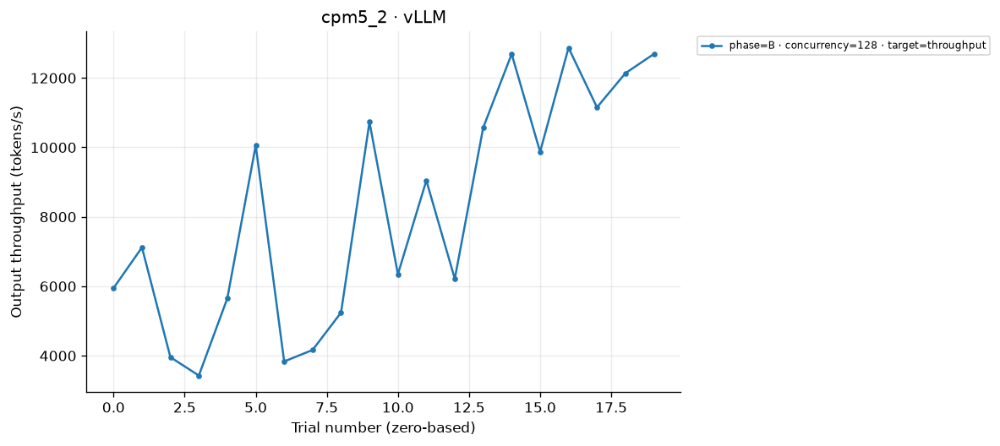

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,2484.027139,1522.844288,3,3
1,B,128,e2e,1,3829.302708,54165.147865,3,3
2,B,128,e2e,2,8312.504456,7768.341938,3,3
3,B,128,e2e,3,13117.586834,40858.400350,3,3
4,B,128,e2e,4,3657.438148,1217.280413,3,3
5,B,128,e2e,5,2813.992494,9861.152477,3,3
6,B,128,e2e,6,5509.543773,2986.328494,3,3
7,B,128,e2e,7,2658.104976,1157.346508,3,3
8,B,128,e2e,8,3902.186159,7271.815613,3,3
9,B,128,e2e,9,1582.052185,4.247042,3,3


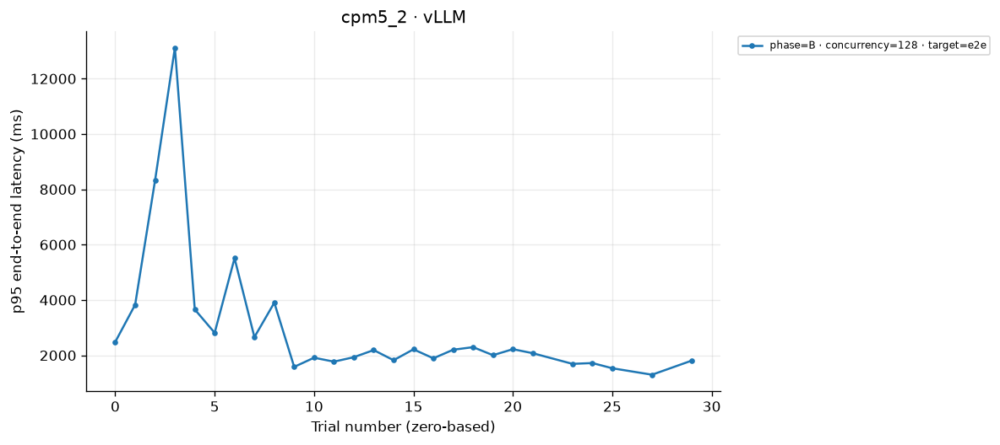

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,46.683183,4.085361e+02,3,3
1,B,128,e2e,1,36.680144,1.333989e+02,3,3
2,B,128,e2e,2,41.682537,1.334073e+02,3,3
3,B,128,e2e,3,36.680665,1.334185e+02,3,3
4,B,128,e2e,4,45.015404,7.504603e+01,3,3
5,B,128,e2e,5,50.016171,7.503077e+01,3,3
6,B,128,e2e,6,36.680732,1.333927e+02,3,3
7,B,128,e2e,7,46.682293,1.333939e+02,3,3
8,B,128,e2e,8,36.679908,1.333818e+02,3,3
9,B,128,e2e,9,51.683515,1.333887e+02,3,3


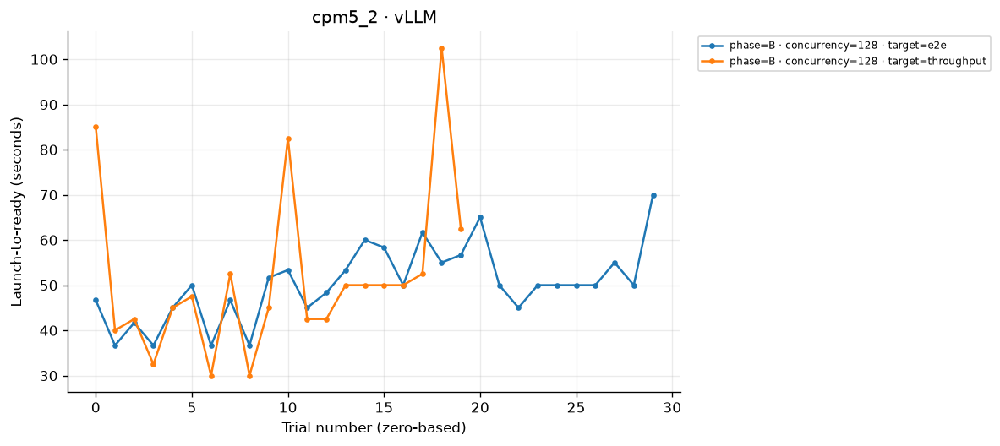

In [26]:
mean_by_trial_number("cpm5_2", "vllm")


In [27]:
mean_by_trial_number("cpm5_2", "sglang")


### cpm5_2 · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


### cpm5_2 · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,9901.066220,11074.595445,3,3
1,B,128,throughput,1,10265.246841,175811.231655,3,3
2,B,128,throughput,2,10302.182881,515423.091001,3,3
3,B,128,throughput,3,10091.471814,7041.803836,3,3
4,B,128,throughput,4,6722.330448,3247.131076,3,3
5,B,128,throughput,5,2718.049899,10541.302148,3,3
6,B,128,throughput,6,10319.281232,165566.870057,3,3
7,B,128,throughput,7,1912.205183,631.935001,3,3
8,B,128,throughput,8,9464.297782,3154.925054,3,3
9,B,128,throughput,9,10320.639779,613270.982953,3,3


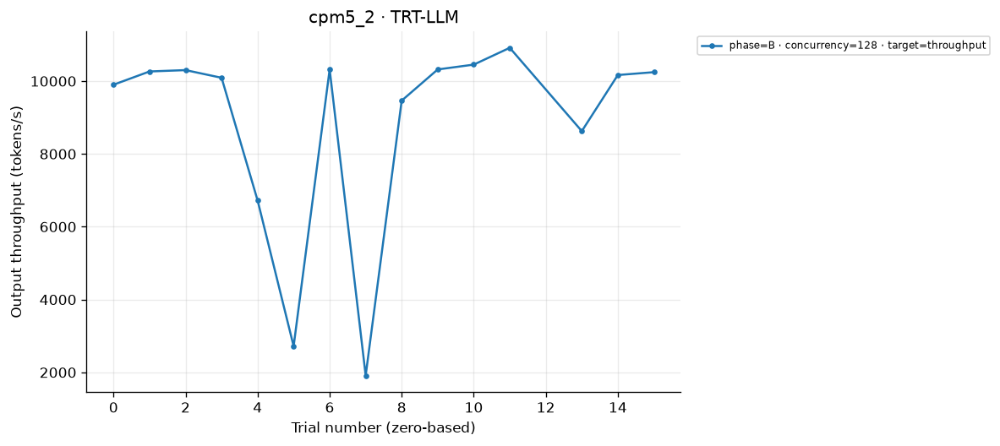

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,1866.355368,25053.182008,4,4
1,B,128,e2e,1,1985.774816,42442.960251,4,4
2,B,128,e2e,2,1912.299597,17734.721157,4,4
3,B,128,e2e,3,1903.650504,24991.650882,4,4
4,B,128,e2e,4,2862.971990,16195.354244,4,4
5,B,128,e2e,5,8456.098688,271135.546875,3,3
6,B,128,e2e,6,1905.594632,48054.268069,3,3
7,B,128,e2e,7,8496.901016,9951.467055,3,3
8,B,128,e2e,8,2186.327889,3586.021321,3,3
9,B,128,e2e,9,1946.622130,5627.581363,3,3


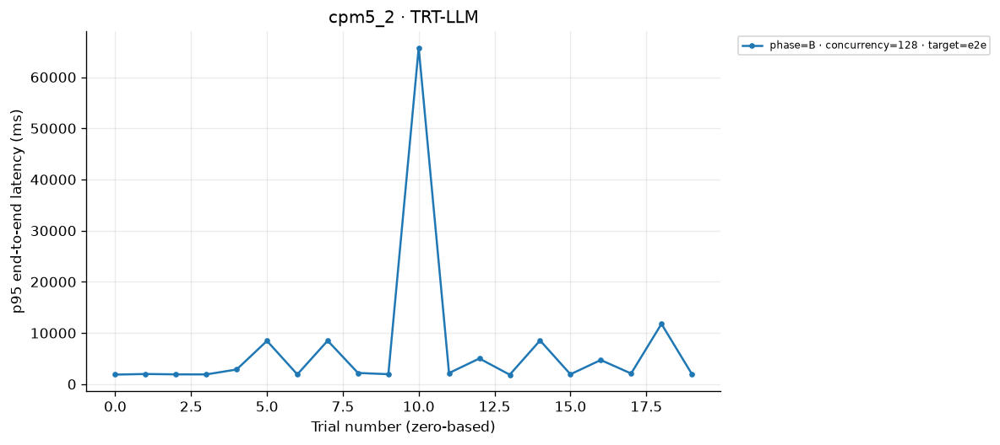

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,51.710805,16.800716,6,6
1,B,128,e2e,1,37.028659,7.496337,5,5
2,B,128,e2e,2,53.030158,57.569491,5,5
3,B,128,e2e,3,48.032271,107.685453,5,5
4,B,128,e2e,4,36.282856,6.324149,4,4
5,B,128,e2e,5,35.033466,0.000122,3,3
6,B,128,e2e,6,58.372469,8.366452,3,3
7,B,128,e2e,7,38.367024,8.377469,3,3
8,B,128,e2e,8,38.377060,8.412858,3,3
9,B,128,e2e,9,35.032885,0.000067,3,3


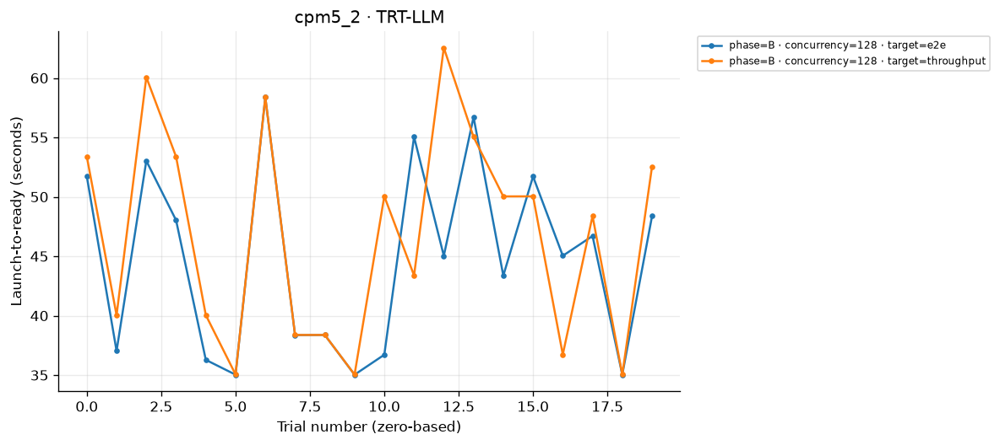

In [28]:
mean_by_trial_number("cpm5_2", "trtllm")


### Overall results and plots:

**13 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
cpm5_2,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop-cpm_2,B,trtllm,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,43.99093282565,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,uu4jmgky,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,finished,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-e2e-gp-s11-r1-pruner-nop-B-trtllm-c128-measured.jsonl']
cpm5_2,—,B,trtllm,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,5.492254966666667,local terminal trial span,local,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,qwc0hk9u,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/qwc0hk9u,—,MiniCPM5-2B,[]
cpm5_2,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,7.598068720566667,W&B terminal _runtime,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,8tx6q7fo,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/8tx6q7fo,crashed,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-e2e-tpe-s11-r4-pruner-median-B-trtllm-c128-measured.jsonl']
cpm5_2,B-trtllm-c128-e2e-tpe-s11-r5-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-e2e-tpe-s11-r5-pruner-median,31.96894285111667,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,1yizm8zl,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/1yizm8zl,finished,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-e2e-tpe-s11-r5-pruner-median-B-trtllm-c128-measured.jsonl']
cpm5_2,B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median,31.593867556083328,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,r9432kw4,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r9432kw4,finished,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median-B-trtllm-c128-measured.jsonl']
cpm5_2,B-trtllm-c128-throughput-gp-s11-r1-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-throughput-gp-s11-r1-pruner-median,23.104955383333344,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,1nr02phv,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/1nr02phv,finished,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-throughput-gp-s11-r1-pruner-median-B-trtllm-c128-measured.jsonl']
cpm5_2,B-trtllm-c128-throughput-tpe-s11-r1-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-throughput-tpe-s11-r1-pruner-median,31.317622465683325,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,24eh2xkz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/24eh2xkz,finished,MiniCPM5-2B,['experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/B-trtllm-c128-throughput-tpe-s11-r1-pruner-median-B-trtllm-c128-measured.jsonl']
cpm5_2,B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,32.320111414383334,local optimization_wall_seconds,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,0mwt2zdz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/r

### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
0,cpm5_2,B,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,50,4,4535.849053,8.477691e+07,phase/concurrency
1,cpm5_2,B,throughput,128,full trial history,output_throughput,trtllm,35,3,8470.224976,9.225997e+06,phase/concurrency
2,cpm5_2,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,63,3,3305.900189,7.375594e+06,phase/concurrency
3,cpm5_2,B,throughput,128,full trial history,output_throughput,vllm,37,2,8313.971117,1.511097e+07,phase/concurrency
54,cpm5_2,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,113,7,3850.125350,4.154934e+07,phase/concurrency
55,cpm5_2,B,throughput,128,full trial history,output_throughput,overall,72,5,8389.927854,1.208617e+07,phase/concurrency
81,cpm5_2,all,e2e,all,full trial history,p95_e2e_latency_ms,trtllm,50,4,4535.849053,8.477691e+07,model
82,cpm5_2,all,throughput,all,full trial history,output_throughput,trtllm,35,3,8470.224976,9.225997e+06,model
83,cpm5_2,all,e2e,all,full trial history,p95_e2e_latency_ms,vllm,63,3,3305.900189,7.375594e+06,model
84,cpm5_2,all,throughput,all,full trial history,output_throughput,vllm,37,2,8313.971117,1.511097e+07,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

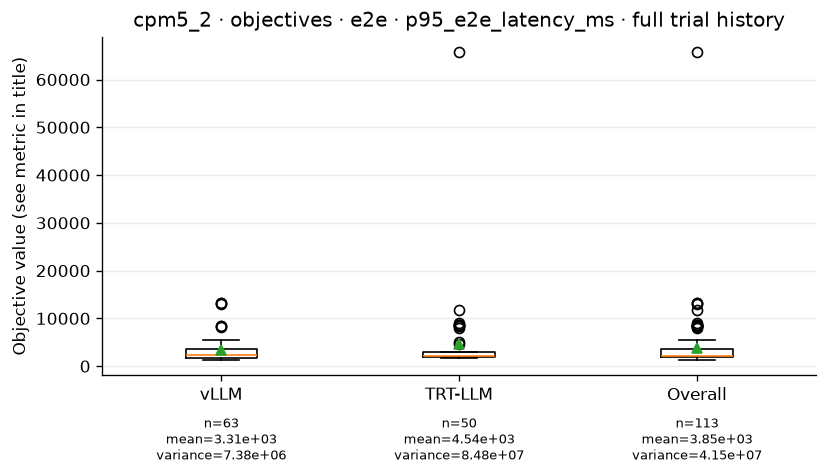

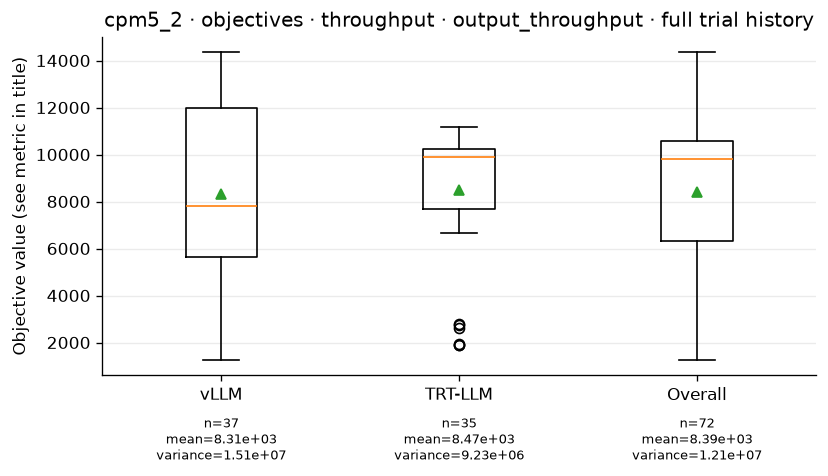

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
cpm5_2,trtllm,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop-cpm_2,uu4jmgky,100,included
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,czymko6z,5,under five minutes
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,qwc0hk9u,20,included
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r3-pruner-median-cpm_2,7hksyocg,0,under five minutes
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median-cpm_2,8tx6q7fo,25,included
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r5-pruner-median-cpm_2,1yizm8zl,100,included
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median-cpm_2,r9432kw4,100,included
cpm5_2,trtllm,B-trtllm-c128-throughput-gp-s11-r1-pruner-median-cpm_2,1nr02phv,70,included
cpm5_2,trtllm,B-trtllm-c128-throughput-tpe-s11-r1-pruner-median-cpm_2,24eh2xkz,100,included
cpm5_2,trtllm,B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-cpm_2,0mwt2zdz,100,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope
0,cpm5_2,B,launch_to_ready,complete,trtllm,124,45.606900,124.583165,phase
1,cpm5_2,B,client_preparation,complete,trtllm,124,1.209793,0.022238,phase
2,cpm5_2,B,warmup,complete,trtllm,124,0.310729,0.103115,phase
3,cpm5_2,B,benchmark,complete,trtllm,85,26.776521,3103.593743,phase
4,cpm5_2,B,launch_to_ready,complete,vllm,107,50.577821,345.150262,phase
5,cpm5_2,B,client_preparation,complete,vllm,107,1.156793,0.007151,phase
6,cpm5_2,B,warmup,complete,vllm,107,0.231126,0.013250,phase
7,cpm5_2,B,benchmark,complete,vllm,100,22.889366,480.129126,phase
8,cpm5_2,B,weight_loading,log observation,vllm,321,2.256922,4.312681,phase
9,cpm5_2,B,compilation,log observation,vllm,285,14.021789,185.361764,phase


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

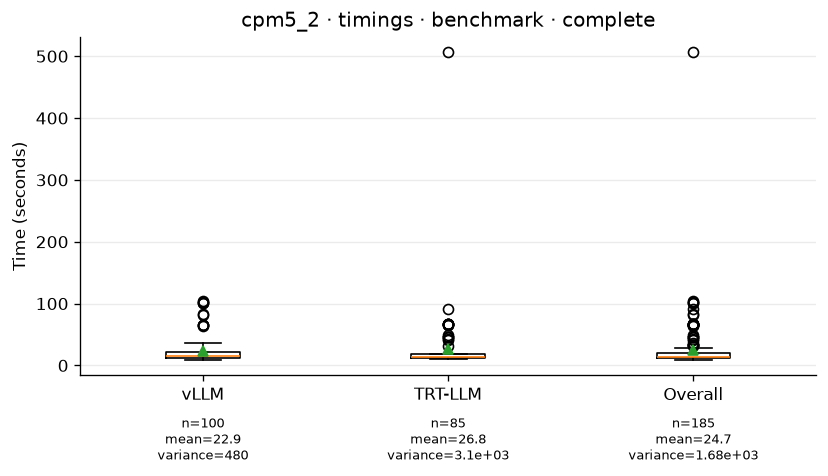

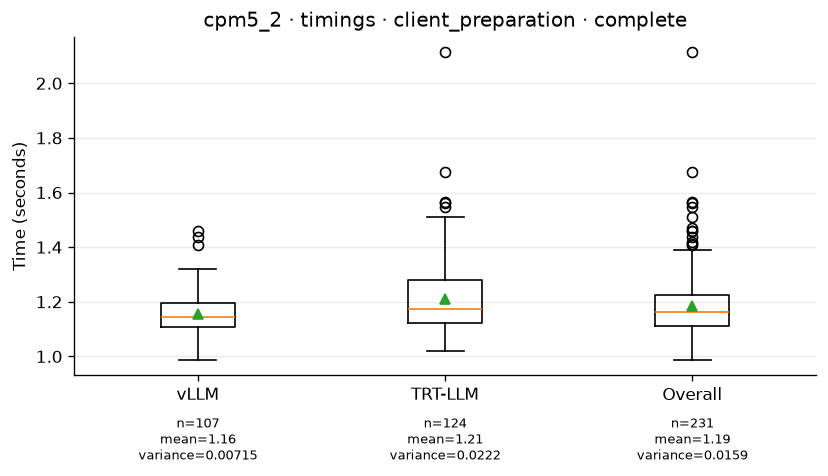

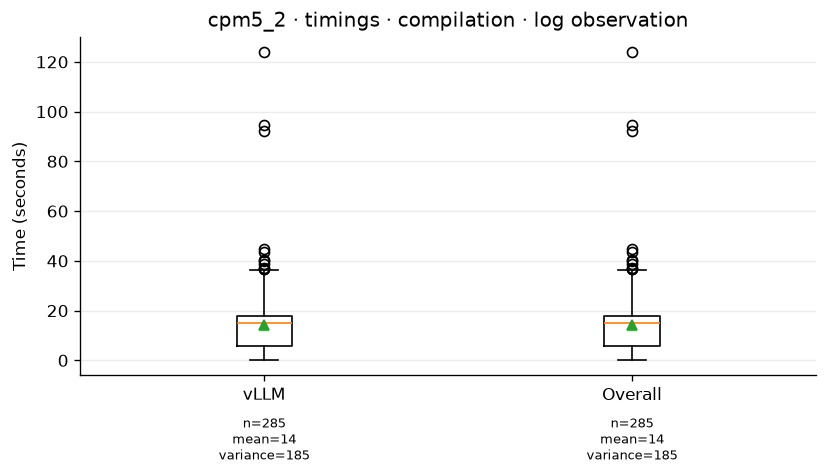

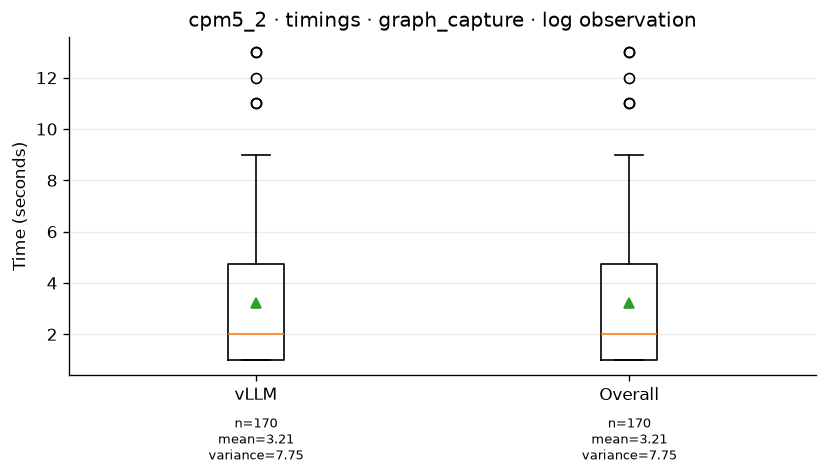

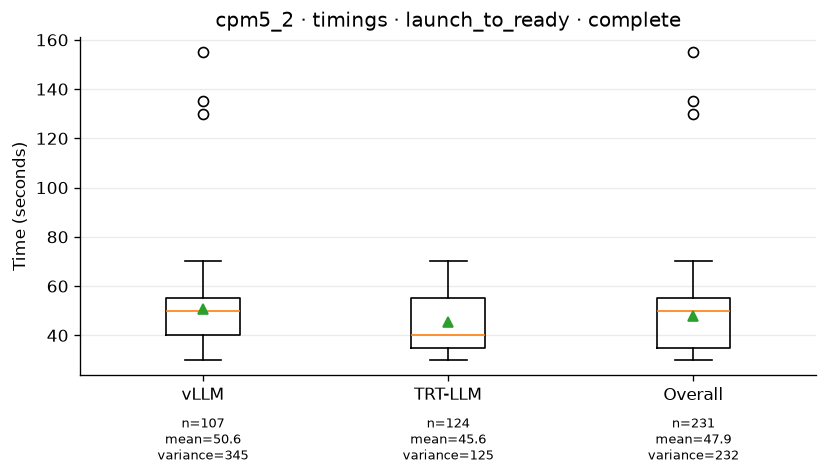

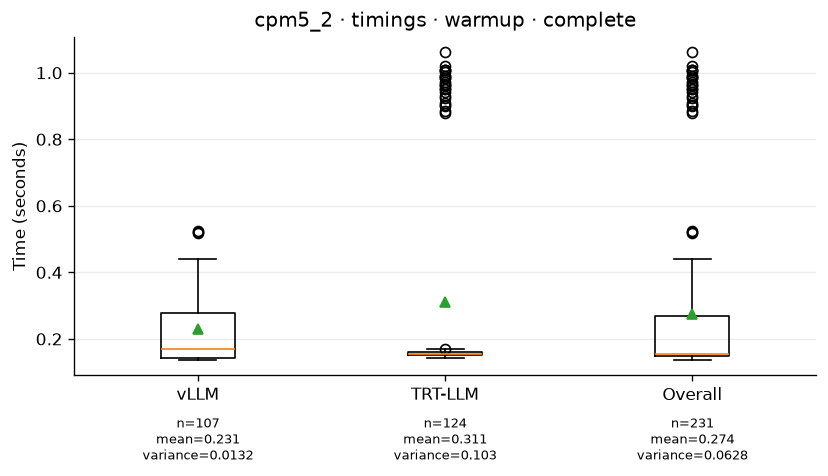

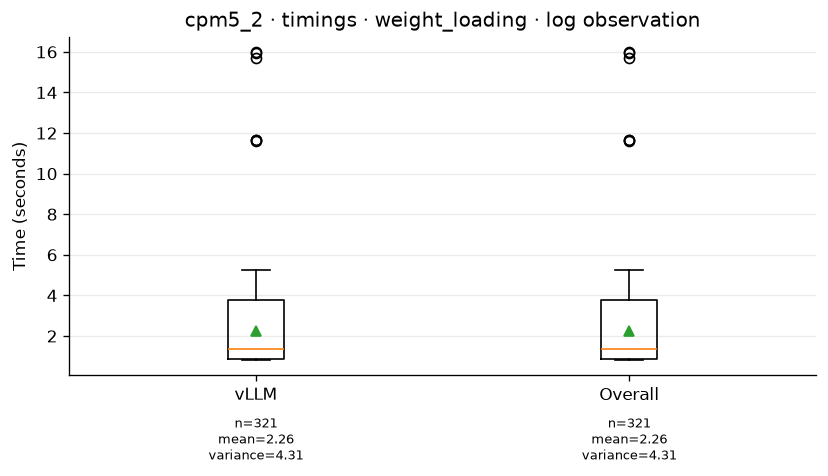

Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means.

model_group,framework,phase,study_name,wandb_id,trial,params,state,source,wandb_url,launch_to_ready (s),launch_to_ready status,client_preparation (s),client_preparation status,warmup (s),warmup status,benchmark (s),benchmark status,runner_wall (s),runner_wall status,weight_loading (s),weight_loading status,compilation (s),compilation status,graph_capture (s),graph_capture status
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,0,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""MAX_UTILIZATION""enable_block_reuse: falseenable_chunked_prefill: truegraph_capture_profile: ""dense""graph_enabled: truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,55.05113690700091,complete,1.270723319001263,complete,0.15779479299999366,complete,12.772256202999415,complete,92.27926943400053,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,1,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""MAX_UTILIZATION""enable_block_reuse: falseenable_chunked_prefill: truegraph_capture_profile: ""powers""graph_enabled: truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 112max_num_tokens: 24320",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,35.03745830400112,complete,1.0591522699996858,complete,0.14726007799981744,complete,11.686878861000878,complete,70.8124737629987,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,2,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""GUARANTEED_NO_EVICT""enable_block_reuse: falseenable_chunked_prefill: truegraph_capture_profile: ""dense""graph_enabled: truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 112max_num_tokens: 12032",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,55.03322394300085,complete,1.115298350001467,complete,0.15021155099930183,complete,11.507985662001374,complete,90.71219725899937,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,3,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""MAX_UTILIZATION""enable_block_reuse: falseenable_chunked_prefill: truegraph_capture_profile: ""dense""graph_enabled: truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 80max_num_tokens: 18688",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,55.05950162299996,complete,1.2604035929998645,complete,0.15868277899971872,complete,12.697251944999152,complete,92.13660267900013,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,4,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""GUARANTEED_NO_EVICT""enable_block_reuse: falseenable_chunked_prefill: truegraph_capture_profile: ""powers""graph_enabled: truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 40max_num_tokens: 26112",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,40.05503405099989,complete,1.1625401199999033,complete,0.1550647990006837,complete,19.21636290400056,complete,83.60960307700043,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,uu4jmgky,5,"attn_backend: ""FLASHINFER""capacity_scheduler_policy: ""GUARANTEED_NO_EVICT""enable_block_reuse: trueenable_chunked_prefill: truegraph_enabled: falsekv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 10496",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/uu4jmgky,35.043631635000565,complete,1.159826637000151,complete,1.0086548480012425,complete,46.03534606699941,complete,106.26170144299977,unknown,—,—,—,—,—,—
cpm5_2,trtllm,B,B-trtllm-c128-e2e-gp-s11-

### vLLM · cpm5_2

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,1,max_num_seqs,0.9056491552464293
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,2,max_num_batched_tokens,0.03361748458262607
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,3,enable_prefix_caching,0.021265787221263554
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,4,async_scheduling,0.018755151284202968
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,5,performance_mode,0.009969540451990791
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,6,graph_mode,0.0059972402088889695
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,7,gpu_memory_utilization,0.004745641004598361
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,8,kv_cache_dtype,0.0
cpm5_2,vllm,e2e,7x3rwymx,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,9,attention_backend,0.0
cpm5_2,vllm,e2e,adkzns8y,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,1,performance_mode,0.4983897809260238


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.023418,0.000288
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.000000,0.000000
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.010056,0.000113
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.243614,0.123868
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.028266,0.001822
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.000000,0.000000
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.096736,0.003466
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.393395,0.199413
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.204515,0.067038
9,throughput,output_throughput,async_scheduling,2,0.025088,0.001215


model_group,framework,run,wandb_id,status


Phase B / vLLM: 5 included runs; cutoff 5 minutes


**Runs included: 5.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-vllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

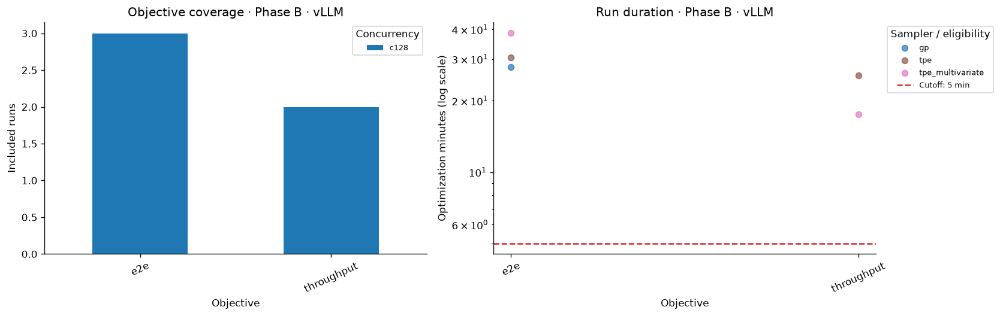

,state,trials
0,COMPLETE,100
1,FAIL,3
2,PRUNED,7


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-vllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r1-pruner-nop,vllm-phaseB-minicmp5-2b,7x3rwymx,e2e,C21,gp,27.80,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 21760max_num_seqs: 64performance_mode: balanced,9,1579.872450,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r2-pruner-median,vllm-phaseB-minicmp5-2b,adkzns8y,e2e,C21,tpe,30.48,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 21760max_num_seqs: 64performance_mode: balanced,9,1582.315248,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,vllm-phaseB-minicmp5-2b,qbrc6w2p,e2e,C21,tpe_multivariate,38.69,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 30464max_num_seqs: 128performance_mode: throughput,27,1299.187262,False,all local COMPLETE trials


##### Matching context C21

**Matched workload and environment**

**model:** `"cpm5_2"` · **concurrency:** `128` · **workload:** `{"apply_chat_template": true, "dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"f97400052a43d642bbc6e9975e2397e3ae6a6b52"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

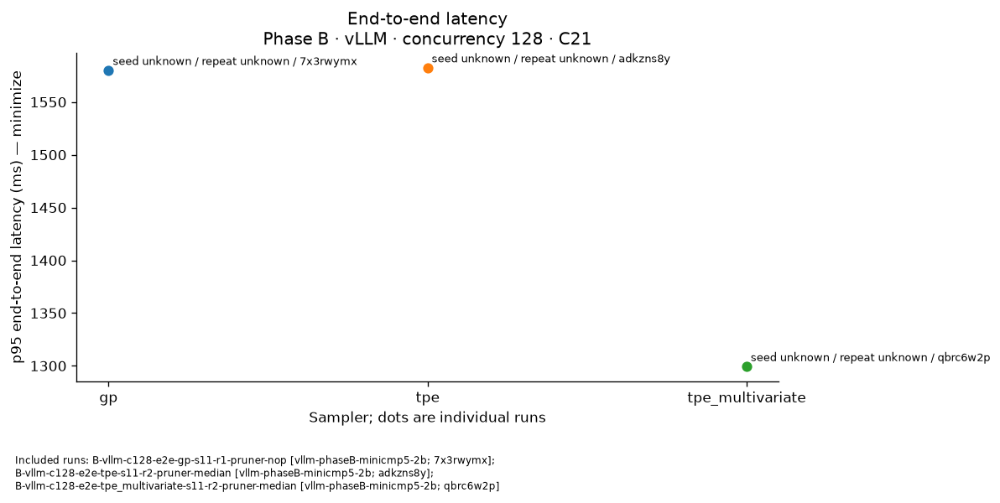

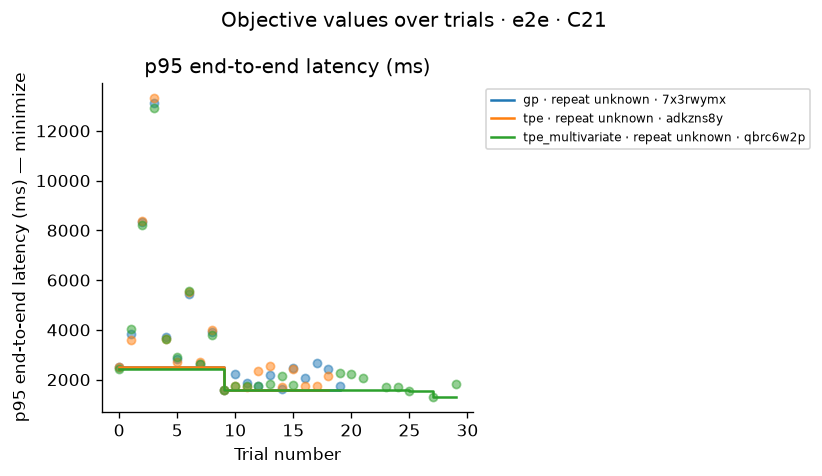

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 2.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-tpe-s11-r1-pruner-median,vllm-phaseB-minicmp5-2b,vr09plvc,throughput,C08,tpe,25.64,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 5376max_num_seqs: 104performance_mode: balanced,14,13091.608318,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,vllm-phaseB-minicmp5-2b,ex88yyiz,throughput,C08,tpe_multivariate,17.53,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 18944max_num_seqs: 104performance_mode: balanced,18,14361.437952,False,all local COMPLETE trials


##### Matching context C08

**Matched workload and environment**

**model:** `"cpm5_2"` · **concurrency:** `128` · **workload:** `{"apply_chat_template": true, "dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"f97400052a43d642bbc6e9975e2397e3ae6a6b52"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

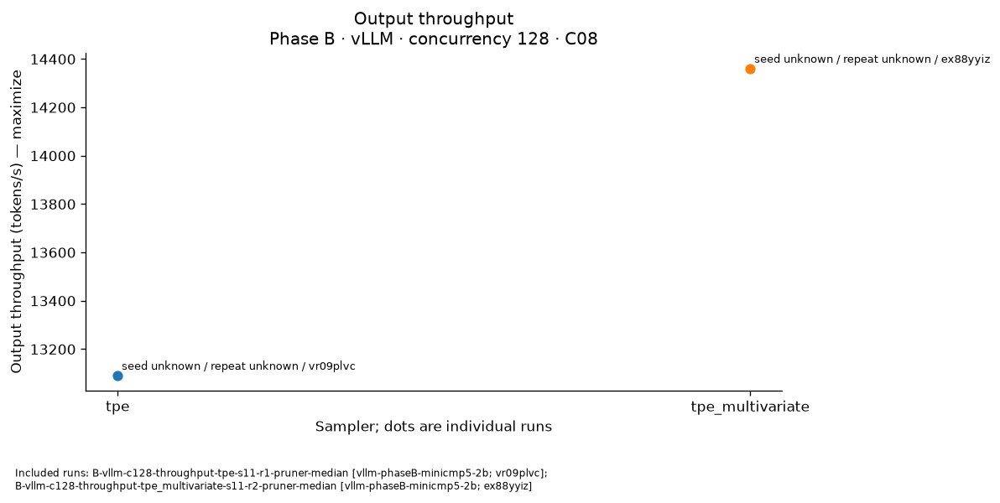

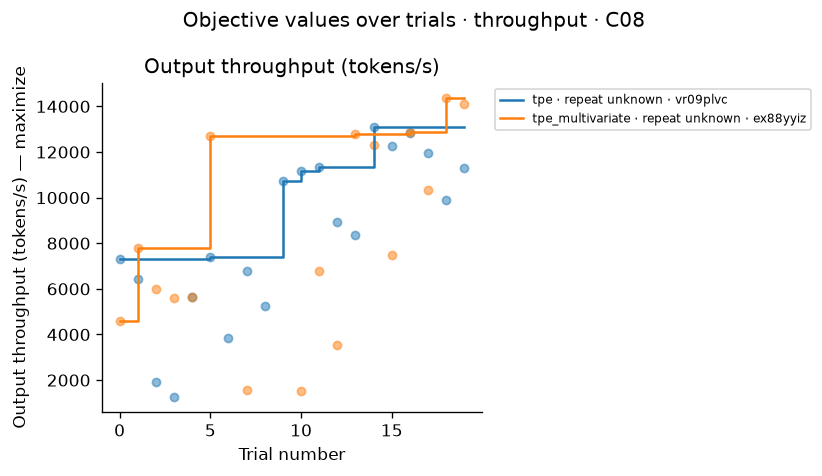

### TRT-LLM · cpm5_2

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,1,max_batch_size,0.5911395590415979
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,2,kv_cache_free_gpu_memory_fraction,0.17692576674373045
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,3,enable_block_reuse,0.13910277058761847
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,4,capacity_scheduler_policy,0.0608646531355221
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,5,graph_enabled,0.024260441929084366
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,6,max_num_tokens,0.007706808562446668
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,7,enable_chunked_prefill,0.0
cpm5_2,trtllm,e2e,uu4jmgky,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,8,attn_backend,0.0
cpm5_2,trtllm,e2e,8tx6q7fo,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,tpe,p95_e2e_latency_ms,1,max_batch_size,0.483724480921772
cpm5_2,trtllm,e2e,8tx6q7fo,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,tpe,p95_e2e_latency_ms,2,max_num_tokens,0.40409508442042935


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attn_backend,4,0.000000,0.000000
1,e2e,p95_e2e_latency_ms,capacity_scheduler_policy,4,0.022803,0.000705
2,e2e,p95_e2e_latency_ms,enable_block_reuse,4,0.036518,0.004679
3,e2e,p95_e2e_latency_ms,enable_chunked_prefill,4,0.000000,0.000000
4,e2e,p95_e2e_latency_ms,graph_capture_profile,1,0.021161,NaN
5,e2e,p95_e2e_latency_ms,graph_enabled,4,0.024828,0.001032
6,e2e,p95_e2e_latency_ms,graph_padding,1,0.005861,NaN
7,e2e,p95_e2e_latency_ms,kv_cache_free_gpu_memory_fraction,4,0.096961,0.005949
8,e2e,p95_e2e_latency_ms,max_batch_size,4,0.367620,0.046138
9,e2e,p95_e2e_latency_ms,max_num_tokens,4,0.444513,0.128032


model_group,framework,run,wandb_id,status
cpm5_2,trtllm,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,qwc0hk9u,p95_e2e_latency_ms: insufficient variation


Phase B / TRT-LLM: 8 included runs; cutoff 5 minutes


**Runs included: 8.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median`
- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

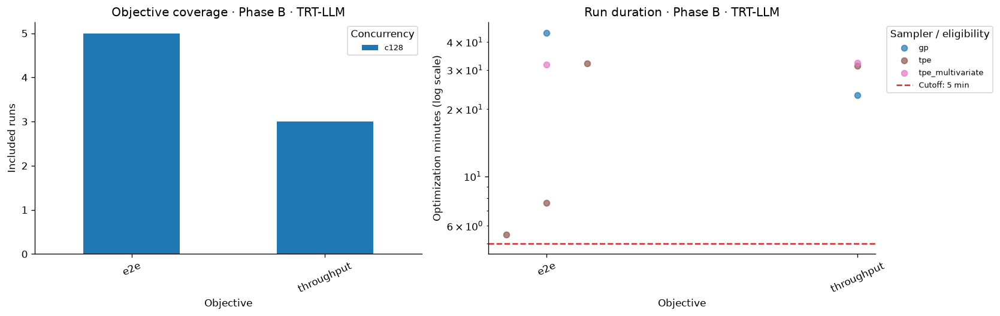

,state,trials
0,COMPLETE,85
1,FAIL,19
2,PRUNED,34
3,RUNNING,1


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,MiniCPM5-2B,uu4jmgky,e2e,C36,gp,43.99,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,13.0,1799.979914,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,MiniCPM5-2B,qwc0hk9u,e2e,NaN,tpe,5.49,—,NaN,NaN,None,no eligible result
B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,MiniCPM5-2B,8tx6q7fo,e2e,C37,tpe,7.60,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896,0.0,1629.926438,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r5-pruner-median,MiniCPM5-2B,1yizm8zl,e2e,C36,tpe,31.97,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 88max_num_tokens: 26880,6.0,1653.311381,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median,MiniCPM5-2B,r9432kw4,e2e,C36,tpe_multivariate,31.59,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 64max_num_tokens: 16896,13.0,1832.690571,False,all local COMPLETE trials


##### Matching context C36

**Matched workload and environment**

**model:** `"cpm5_2"` · **concurrency:** `128` · **workload:** `{"apply_chat_template": true, "dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"f97400052a43d642bbc6e9975e2397e3ae6a6b52"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

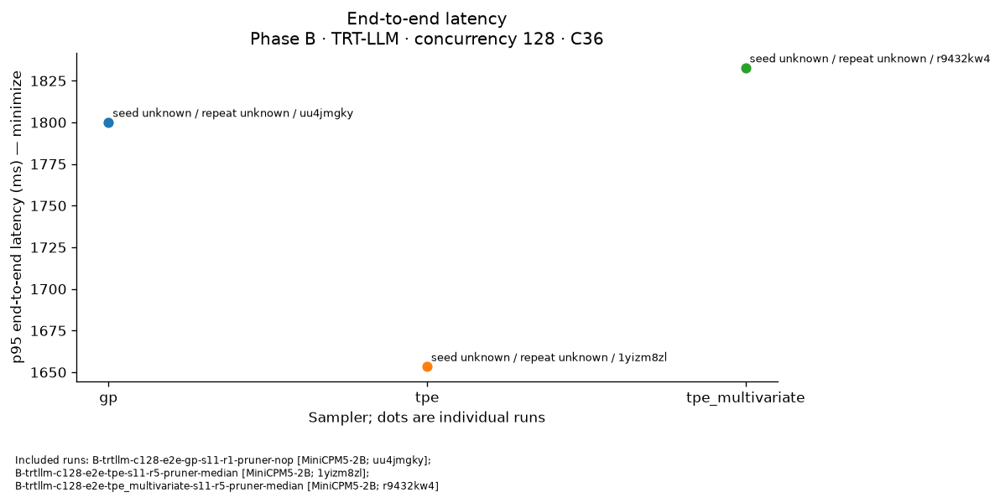

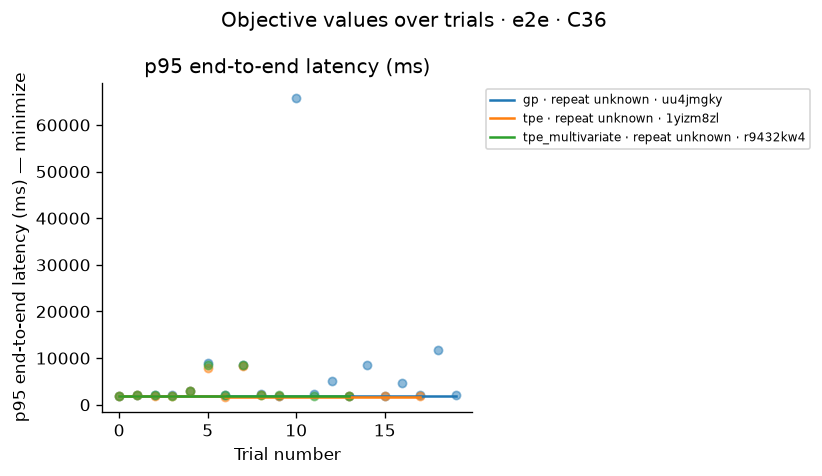

##### Matching context C37

**Matched workload and environment**

**model:** `"cpm5_2"` · **concurrency:** `128` · **workload:** `{"apply_chat_template": true, "dataset_name": "sharegpt", "max_concurrency": 128, "num_prompts": 1000, "request_rate": "inf", "seed": 2026, "sharegpt_output_len": 128}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"f97400052a43d642bbc6e9975e2397e3ae6a6b52"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

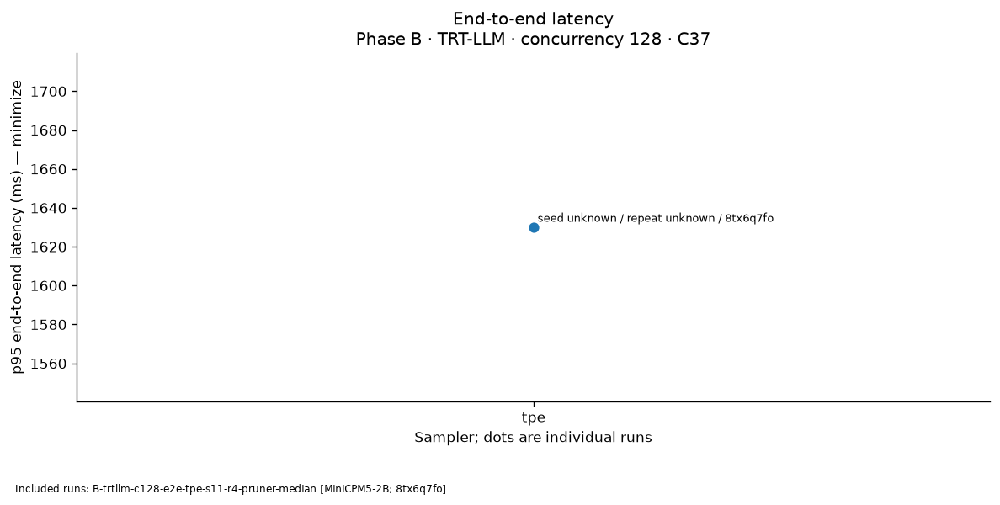

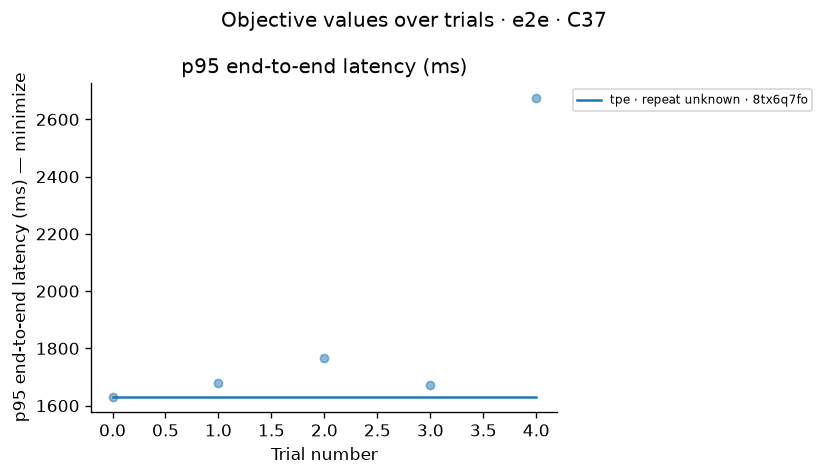

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-gp-s11-r1-pruner-median,MiniCPM5-2B,1nr02phv,throughput,C31,gp,23.10,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 112max_num_tokens: 24320,1,10542.803253,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r1-pruner-median,MiniCPM5-2B,24eh2xkz,throughput,C31,tpe,31.32,attn_backend: FLASHINFERcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 112max_num_tokens: 10496,9,11159.642146,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,MiniCPM5-2B,0mwt2zdz,throughput,C31,tpe_multivariate,32.32,attn_backend: FLASHINFERcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 112max_num_tokens: 12032,2,11131.142472,False,all local COMPLETE trials


##### Matching context C31

**Matched workload and environment**

**model:** `"cpm5_2"` · **concurrency:** `128` · **workload:** `{"apply_chat_template": true, "dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"f97400052a43d642bbc6e9975e2397e3ae6a6b52"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

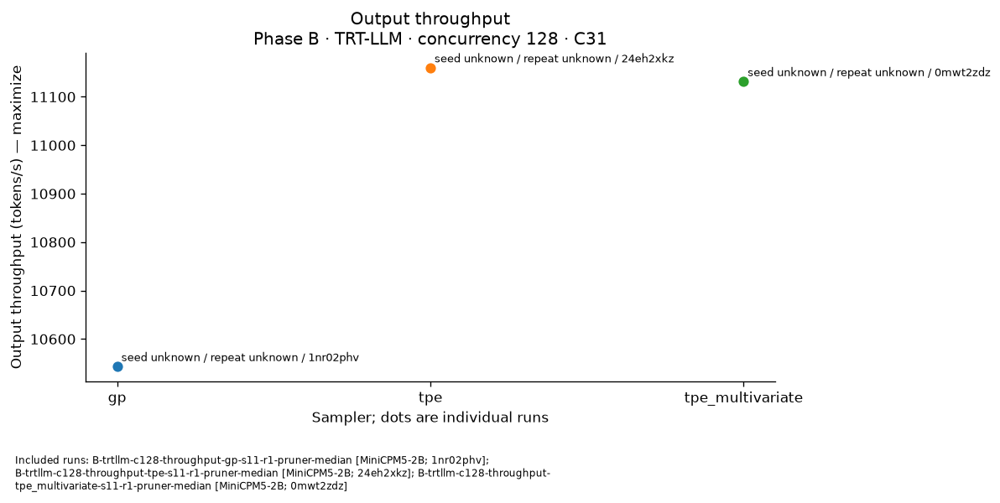

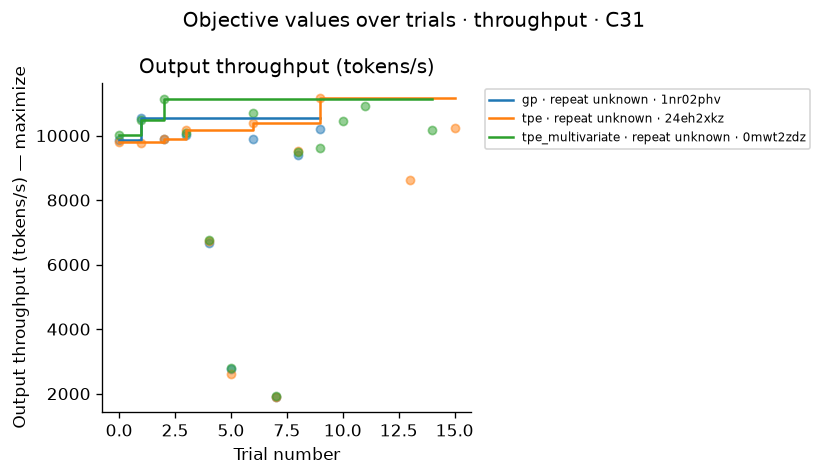

### SGLang · cpm5_2

No eligible runs available.


In [29]:
show_model("cpm5_2")


## qwen3.5-4b


### Summary of the results:

In [30]:
show_framework_summary("qwen3.5-4b")


### Framework summaries · qwen3.5-4b

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
e2e,C02,B,1,B-vllm-c1-e2e-tpe-s11-r1,mdubhu8o,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/mdubhu8o,4,—,572.7766331000225,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: truegpu_memory_utilization: 0.85graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 3072performance_mode: ""throughput""",all W&B COMPLETE trials
e2e,C03,A,1,A-vllm-c1-e2e-gp-s11-r2,opn2e3xt,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/opn2e3xt,0,—,318.07293725023555,cuda_graph_on: 1max_num_batched_tokens: 5120,all local COMPLETE trials
pareto_throughput,C48,B,128,B-vllm-c128-pareto_throughput-gp-s11-r3,dpe6es0u,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/dpe6es0u,11,7267.537112174002,2356.1340522498995,"async_scheduling: trueattention_backend: ""FLASH_ATTN""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""powers""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 29184max_num_seqs: 128performance_mode: ""interactivity""",all local COMPLETE trials
throughput,C54,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r1,4hxfaxio,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/4hxfaxio,16,7338.657147085066,—,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: truegpu_memory_utilization: 0.8graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: ""balanced""",all local COMPLETE trials
throughput,C55,B,128,B-vllm-c128-throughput-gp-s11-r1-pruner-median,rfjsqemv,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/rfjsqemv,19,7311.466849684941,—,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 22784max_num_seqs: 128performance_mode: ""throughput""",all local COMPLETE trials
e2e,C63,B,128,B-vllm-c128-e2e-gp-s11-r3,a8ktejgz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/a8ktejgz,13,—,2318.9879597493928,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: ""interactivity""",all W&B COMPLETE trials
e2e,C64,B,128,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,r3z01gj1,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r3z01gj1,16,—,2382.828466550336,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: truegpu_memory_utilization: 0.8graph_capture_profile: ""powers""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 29952max_num_seqs: 128performance_mode: ""interactivity""",all local COMPLETE trials
pareto_throughput,C65,A,128,A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1,lmy4u5xz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/lmy4u5xz,21,8342.212416986273,2008.666799101411,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,all local COMPLETE trials
throughput,C66,A,128,A-vllm-c128-throughput-gp-s11-r1,fj4tc735,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/fj4tc735,14,8052.185340345283,—,gpu_memory_utilization: 0.9max_num_batched_tokens: 8192max_num_seqs: 32,all local COMPLETE trials
e2e,C67,A,128,A-vllm-c128-e2e-grid-s11-r1,10bj2xwx,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/10bj2xwx,25,—,2239.1161743006705,gpu_memory

**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (10 outputs left out)

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C43,B,128,B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median,qe2hztdf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qe2hztdf,5,5685.3820903832575,—,"attention_backend: ""fa3""cache_policy: ""cache_off__lpm""chunked_prefill_size: 11520cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: trueenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.5",all local COMPLETE trials
e2e,C44,B,128,B-sglang-c128-e2e-gp-s11-r1-pruner-median,iwgzm7d7,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/iwgzm7d7,2,—,4493.559910000295,"attention_backend: ""fa3""cache_policy: ""cache_on__lpm""chunked_prefill_size: 2560cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: trueenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.75schedule_conservativeness: 0.5",all local COMPLETE trials
pareto_throughput,C45,B,128,B-sglang-c128-pareto_throughput-gp-s11-r1,ugshe19v,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ugshe19v,17,3860.544159645843,5377.993358749336,"attention_backend: ""triton""chunked_prefill_size: 8192cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: falsedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: ""fcfs""",all local COMPLETE trials
pareto_throughput,C45,B,128,B-sglang-c128-pareto_throughput-gp-s11-r1,ugshe19v,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ugshe19v,18,3878.047210462033,5384.490891249698,"attention_backend: ""fa3""chunked_prefill_size: 8192cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: falsedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: ""fcfs""",all local COMPLETE trials
pareto_throughput,C45,B,128,B-sglang-c128-pareto_throughput-tpe-s11-r1,i0vlp43e,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/i0vlp43e,12,3859.6335142845314,5366.787615001158,"attention_backend: ""triton""chunked_prefill_size: 8192cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: falsedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: ""fcfs""",all local COMPLETE trials
pareto_throughput,C45,B,128,B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1,qj630sqc,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qj630sqc,12,3851.9380327953113,5365.730978749525,"attention_backend: ""fa3""chunked_prefill_size: 4096cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: falsedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: ""fcfs""",all local COMPLETE trials
pareto_throughput,C46,B,128,B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r21,083voz4c,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/083voz4c,17,6539.505294124533,3394.6521775497786,"attention_backend: ""fa3""chunked_prefill_size: 25600cuda_graph_backend_decode: ""tc_piecewise""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: falsedisable_radix_cache: falseenable_mixed_chunk:

**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

,target,metric,coverage,n,runs,mean,variance
0,e2e,p95_e2e_latency_ms,full trial history,375,22,6522.382725,4.508088e+07
1,pareto_throughput,output_throughput,full trial history,134,8,3032.901069,3.212748e+06
2,pareto_throughput,p95_e2e_latency_ms,full trial history,134,8,11473.030825,9.530988e+07
3,throughput,output_throughput,full trial history,154,10,3660.531117,3.770491e+06


No complete startup or serving timing metadata available.


### Per-Trial behavior:

### qwen3.5-4b · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,A,128,pareto_throughput,0,6432.129281,3.853617e+04,4,4
1,A,128,pareto_throughput,1,2588.280897,1.832252e+03,4,4
2,A,128,pareto_throughput,2,6096.688249,1.970807e+04,4,4
3,A,128,pareto_throughput,3,2876.811320,1.357992e+03,4,4
4,A,128,pareto_throughput,4,7573.141821,5.770829e+04,4,4
5,A,128,pareto_throughput,5,7701.556910,6.406409e+04,4,4
6,A,128,pareto_throughput,6,5182.698703,1.685778e+04,4,4
7,A,128,pareto_throughput,7,3974.291005,1.344237e+04,4,4
8,A,128,pareto_throughput,8,7013.696279,3.900796e+04,4,4
9,A,128,pareto_throughput,9,2599.237432,5.375001e+04,4,4


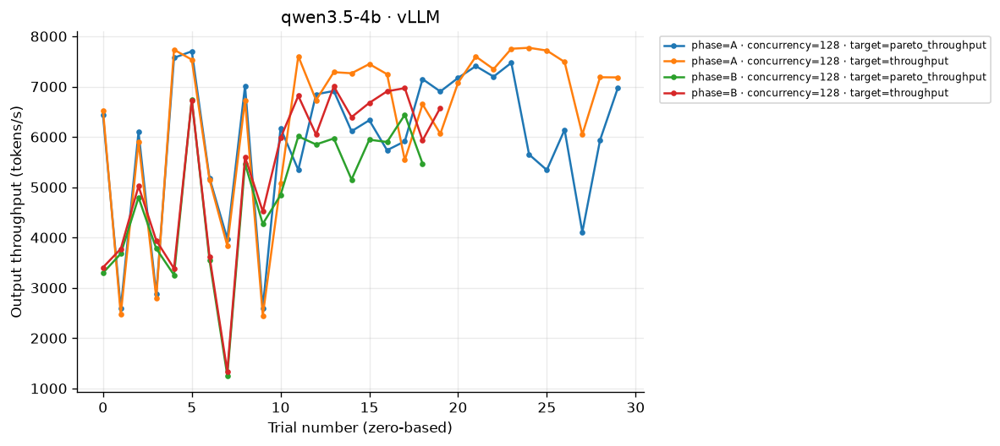

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,A,1,e2e,0,322.356723,1.367079e+01,7,7
1,A,1,e2e,1,1683.913516,8.455019e+01,5,5
2,A,1,e2e,2,607.377671,3.919283e+05,5,5
3,A,1,e2e,3,1416.677264,3.769950e+05,5,5
4,A,1,e2e,4,595.766137,3.731254e+05,5,5
5,A,1,e2e,5,1687.804147,NaN,1,1
6,A,1,e2e,6,1736.398143,NaN,1,1
7,A,1,e2e,7,328.617367,NaN,1,1
8,A,1,e2e,8,1762.761833,NaN,1,1
9,A,1,e2e,9,330.567363,NaN,1,1


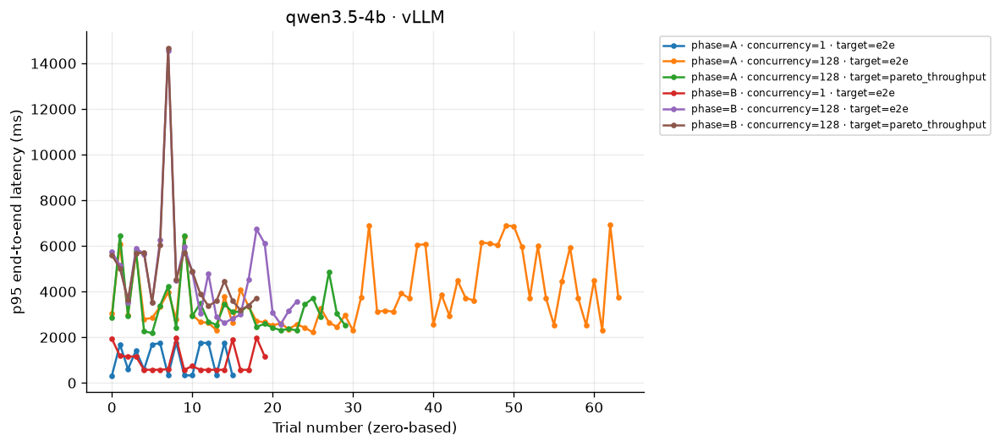

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [31]:
mean_by_trial_number("qwen3.5-4b", "vllm")


### qwen3.5-4b · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,pareto_throughput,0,1699.158934,5.188199e+05,8,8
1,B,128,pareto_throughput,1,503.811907,2.114322e+04,8,8
2,B,128,pareto_throughput,2,3403.545993,1.587352e+06,8,8
3,B,128,pareto_throughput,4,1447.726525,1.181857e+05,8,8
4,B,128,pareto_throughput,5,4285.183975,1.589871e+06,8,8
5,B,128,pareto_throughput,6,4991.209482,1.507168e+06,8,8
6,B,128,pareto_throughput,7,2243.320938,9.653642e+05,8,8
7,B,128,pareto_throughput,8,1428.746752,5.067203e+03,8,8
8,B,128,pareto_throughput,9,2394.291186,1.443523e+06,8,8
9,B,128,pareto_throughput,10,956.030761,1.619400e+05,8,8


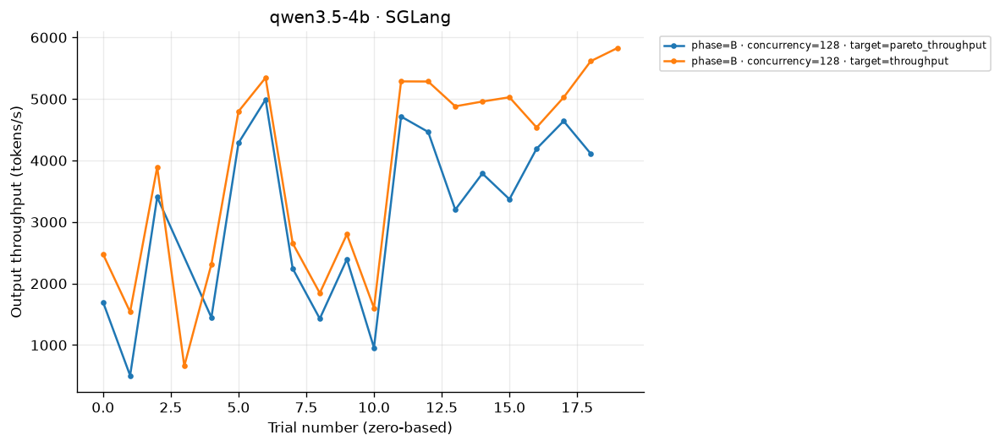

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,A,128,e2e,0,2047.554651,3.308985e+05,6,6
1,A,128,e2e,1,4151.982493,1.496244e+06,6,6
2,A,128,e2e,2,3992.512712,1.285244e+06,6,6
3,A,128,e2e,3,4809.388530,4.527528e+06,6,6
4,A,128,e2e,4,3167.151139,5.221324e+06,6,6
5,A,128,e2e,5,2243.666762,1.347124e+06,6,6
6,A,128,e2e,6,2143.303857,5.295483e+04,6,6
7,A,128,e2e,7,2970.373249,7.093699e+05,6,6
8,A,128,e2e,8,4216.291249,1.835905e+06,6,6
9,A,128,e2e,9,4473.614703,5.325975e+05,6,6


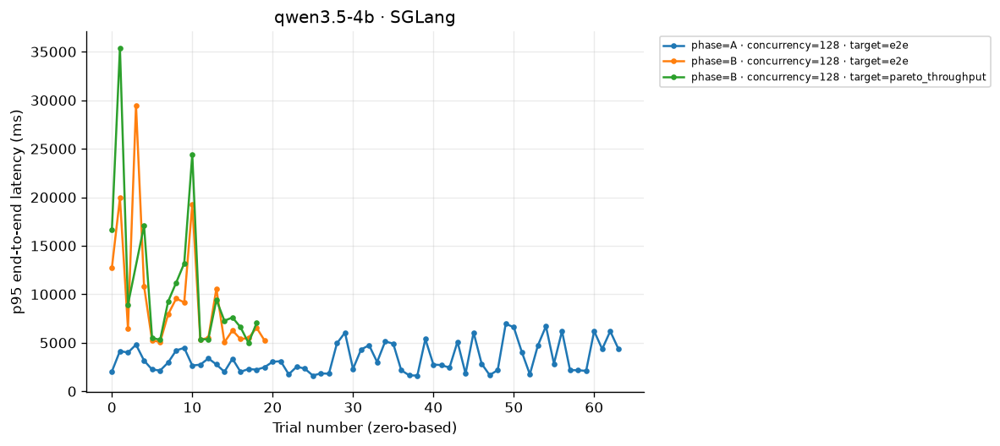

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [32]:
mean_by_trial_number("qwen3.5-4b", "sglang")


### qwen3.5-4b · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,A,128,pareto_throughput,0,7288.770858,4.808761e+04,4,4
1,A,128,pareto_throughput,1,2918.868206,3.852478e+03,4,4
2,A,128,pareto_throughput,2,6811.153424,6.738159e+04,4,4
3,A,128,pareto_throughput,3,3549.933258,4.868433e+03,4,4
4,A,128,pareto_throughput,4,9097.386021,2.096086e+05,4,4
5,A,128,pareto_throughput,5,9373.637925,1.395540e+05,3,3
6,A,128,pareto_throughput,6,5318.912749,3.074609e+04,3,3
7,A,128,pareto_throughput,7,4615.998026,1.084487e+04,3,3
8,A,128,pareto_throughput,8,7971.985935,8.104862e+04,3,3
9,A,128,pareto_throughput,9,2877.774124,1.056805e+03,3,3


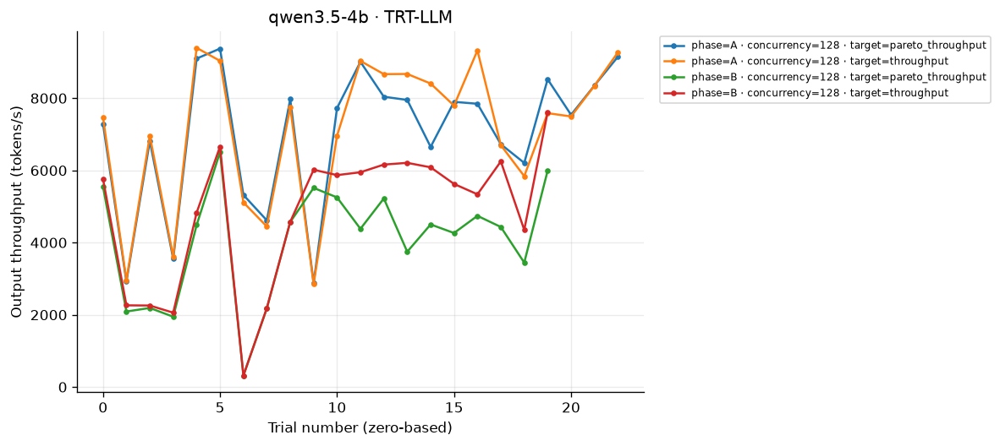

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,A,128,e2e,0,2476.933857,8.578421e+04,5,5
1,A,128,e2e,1,5527.917537,8.091801e+04,5,5
2,A,128,e2e,2,2527.443513,2.724561e+04,5,5
3,A,128,e2e,3,4560.001784,1.137493e+04,3,3
4,A,128,e2e,4,1874.845985,9.723194e+03,2,2
5,A,128,e2e,5,3056.020645,4.534638e+06,3,3
6,A,128,e2e,6,3082.625411,2.353636e+05,3,3
7,A,128,e2e,7,3902.985128,3.008029e+05,3,3
8,A,128,e2e,8,2106.156988,9.094425e+03,3,3
9,A,128,e2e,9,4226.342978,5.020575e+06,3,3


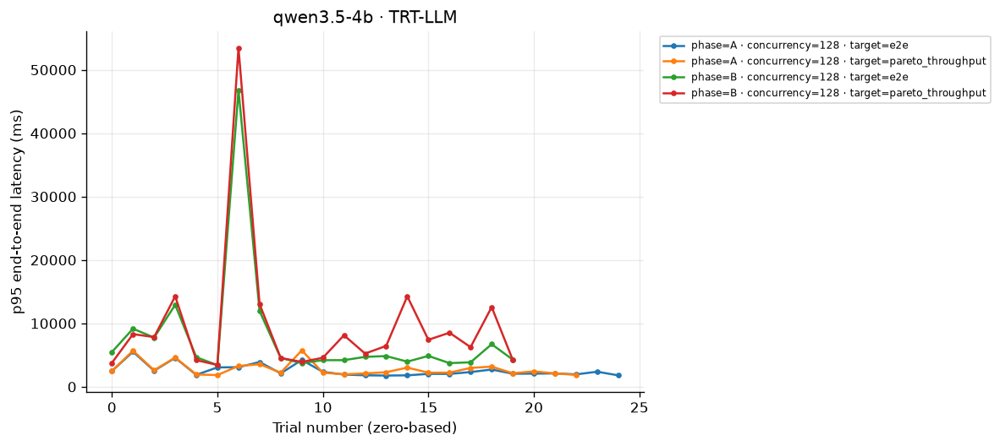

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [33]:
mean_by_trial_number("qwen3.5-4b", "trtllm")


### Overall results and plots:

**125 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3.5-4b,A-sglang-c128-e2e-gp-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-gp-s11-r1,28.477823159049997,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,l010bsj9,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/l010bsj9,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-gp-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,A-sglang-c128-e2e-grid-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-grid-s11-r1,81.88942668648333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,g7myirzj,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/g7myirzj,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-grid-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,A-sglang-c128-e2e-qmc-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-qmc-s11-r1,29.829510169583333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,t9955t18,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/t9955t18,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-qmc-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,A-sglang-c128-e2e-random-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-random-s11-r1,29.11005253153333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,8jlxzlfd,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/8jlxzlfd,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-random-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,A-sglang-c128-e2e-tpe-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-tpe-s11-r1,28.228577050516652,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,f0b03wlc,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/f0b03wlc,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-tpe-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,A-sglang-c128-e2e-tpe_multivariate-s11-r1-q3.5_4,A,sglang,A-sglang-c128-e2e-tpe_multivariate-s11-r1,28.09379920508333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,ieltqkx2,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ieltqkx2,finished,optuna-phase-b-v1,['experiment_results/optuna-phase-b-v1/A-sglang-c128-e2e-tpe_multivariate-s11-r1-A-sglang-c128-measured.jsonl']
qwen3.5-4b,B-sglang-c128-e2e-gp-s11-r1-pruner-median-q3.5_4,B,sglang,B-sglang-c128-e2e-gp-s11-r1-pruner-median,24.576048240483328,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1-pruning/studies.sqlite3,az6q9eie,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/az6q9eie,finished,optuna-phase-b-v1-pruning,['experiment_results/optuna-phase-b-v1-pruning/B-sglang-c128-e2e-gp-s11-r1-pruner-median-B-sglang-c128-measured.jsonl']
qwen3.5-4b,B-sglang-c128-e2e-gp-s11-r1-pruner-median-q3.5_4,B,sglang,B-sglang-c128-e2e-gp-s11-r1-pruner-median,29.820910253116654,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-min400-v1/studies.sqlite3,iwgzm7d7,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/iwgzm7d7,finished,sglang-phase-b-pruning-min400-v1,['experiment_results/sglang-phase-b-pruning-min400-v1/B-sglang-c128-e2e-gp-s11-r1-pruner-median-B-sglang-c128-measured.jsonl']
qwen3.5-4b,B-sglang-c128-e2e-gp-s11-r1-q3.5_4,B,sglang,B-sglang-c128-e2e-gp-s11-r1,41.13859492761664,local optimization_wall_seconds,local + wandb snapshot,experiment_results/op

### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
4,qwen3.5-4b,A,e2e,128,full trial history,p95_e2e_latency_ms,sglang,184,6,3112.058162,2.666451e+06,phase/concurrency
5,qwen3.5-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,sglang,191,16,9807.721571,6.405665e+07,phase/concurrency
6,qwen3.5-4b,B,pareto_throughput,128,full trial history,output_throughput,sglang,134,8,3032.901069,3.212748e+06,phase/concurrency
7,qwen3.5-4b,B,pareto_throughput,128,full trial history,p95_e2e_latency_ms,sglang,134,8,11473.030825,9.530988e+07,phase/concurrency
8,qwen3.5-4b,B,throughput,128,full trial history,output_throughput,sglang,154,10,3660.531117,3.770491e+06,phase/concurrency
9,qwen3.5-4b,A,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,78,5,2678.529855,1.476247e+06,phase/concurrency
10,qwen3.5-4b,A,pareto_throughput,128,full trial history,output_throughput,trtllm,74,4,6945.766668,5.100646e+06,phase/concurrency
11,qwen3.5-4b,A,pareto_throughput,128,full trial history,p95_e2e_latency_ms,trtllm,74,4,2856.291046,1.531659e+06,phase/concurrency
12,qwen3.5-4b,A,throughput,128,full trial history,output_throughput,trtllm,55,3,6983.098487,4.909204e+06,phase/concurrency
13,qwen3.5-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,158,10,8603.579934,1.284890e+08,phase/concurrency


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

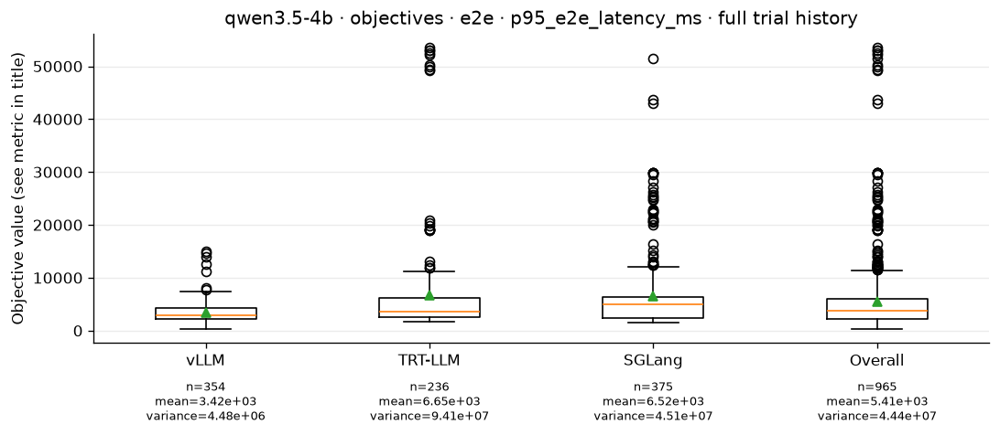

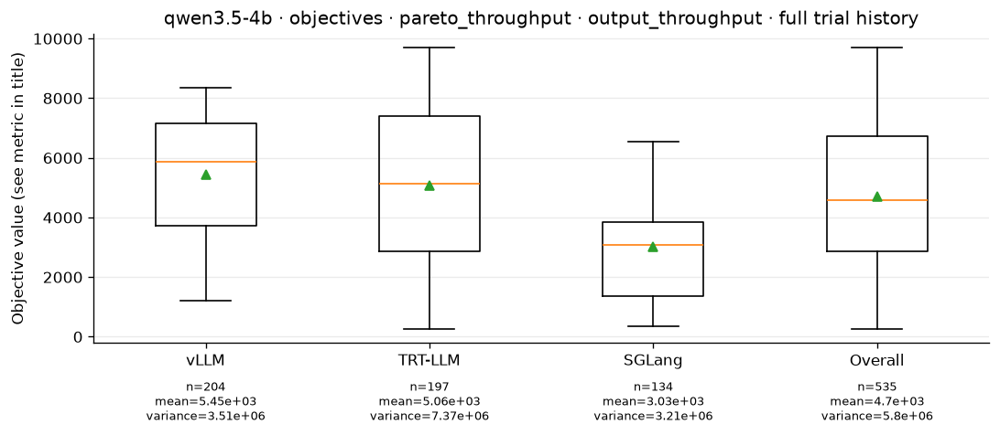

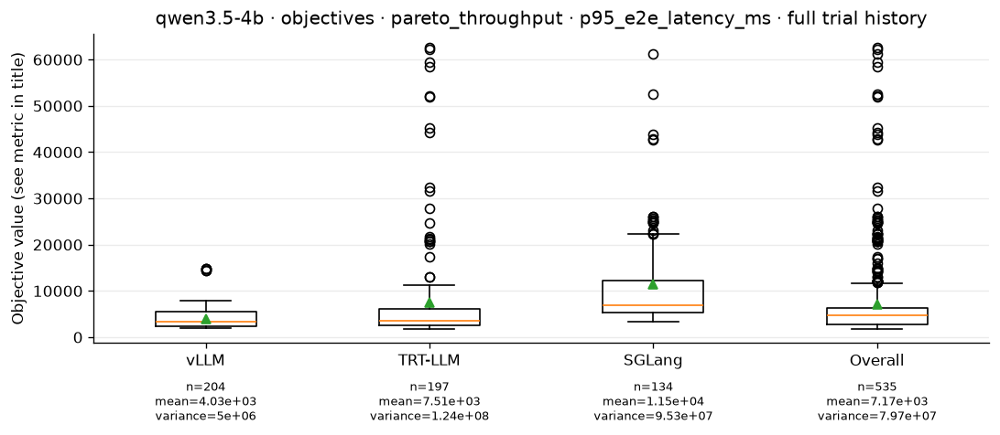

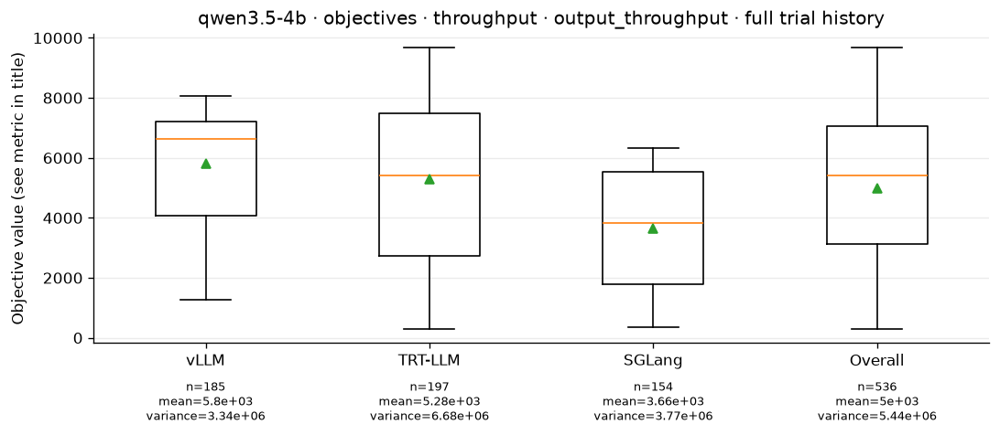

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3.5-4b,sglang,A-sglang-c128-e2e-gp-s11-r1-q3.5_4,l010bsj9,0,included
qwen3.5-4b,sglang,A-sglang-c128-e2e-grid-s11-r1-q3.5_4,g7myirzj,0,included
qwen3.5-4b,sglang,A-sglang-c128-e2e-qmc-s11-r1-q3.5_4,t9955t18,0,included
qwen3.5-4b,sglang,A-sglang-c128-e2e-random-s11-r1-q3.5_4,8jlxzlfd,0,included
qwen3.5-4b,sglang,A-sglang-c128-e2e-tpe-s11-r1-q3.5_4,f0b03wlc,0,included
qwen3.5-4b,sglang,A-sglang-c128-e2e-tpe_multivariate-s11-r1-q3.5_4,ieltqkx2,0,included
qwen3.5-4b,sglang,B-sglang-c128-e2e-gp-s11-r1-pruner-median-q3.5_4,az6q9eie,0,included
qwen3.5-4b,sglang,B-sglang-c128-e2e-gp-s11-r1-pruner-median-q3.5_4,iwgzm7d7,0,included
qwen3.5-4b,sglang,B-sglang-c128-e2e-gp-s11-r1-q3.5_4,3q8960rp,0,included
qwen3.5-4b,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-median-q3.5_4,dh2xj09q,0,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

No recorded startup telemetry available for this model.


### vLLM · qwen3.5-4b

... (2 outputs left out)

,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,7,0.023372,0.001514
1,e2e,p95_e2e_latency_ms,attention_backend,7,0.044946,0.002690
2,e2e,p95_e2e_latency_ms,cuda_graph_on,5,0.577298,0.030236
3,e2e,p95_e2e_latency_ms,enable_prefix_caching,7,0.021562,0.001591
4,e2e,p95_e2e_latency_ms,gpu_memory_utilization,16,0.167799,0.017408
5,e2e,p95_e2e_latency_ms,graph_mode,7,0.030806,0.001513
6,e2e,p95_e2e_latency_ms,kv_cache_dtype,7,0.033085,0.001406
7,e2e,p95_e2e_latency_ms,max_num_batched_tokens,21,0.335751,0.048248
8,e2e,p95_e2e_latency_ms,max_num_seqs,15,0.468896,0.075307
9,e2e,p95_e2e_latency_ms,performance_mode,7,0.038304,0.002218


model_group,framework,run,wandb_id,status
qwen3.5-4b,vllm,A-vllm-c1-e2e-gp-s11-r2,opn2e3xt,p95_e2e_latency_ms: insufficient variation
qwen3.5-4b,vllm,A-vllm-c1-e2e-grid-s11-r1,5nei8053,p95_e2e_latency_ms: insufficient variation


Phase B / vLLM: 17 included runs; cutoff 5 minutes


**Runs included: 17.** Optimizer seeds: s11, seed unknown. Repeats: r1, r2, r3, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c1-e2e-tpe-s11-r1`
- `B-vllm-c128-e2e-gp-s11-r3`
- `B-vllm-c128-e2e-gp-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `B-vllm-c128-pareto_throughput-gp-s11-r3`
- `B-vllm-c128-pareto_throughput-nsga2-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe-s11-r2`
- `B-vllm-c128-pareto_throughput-tpe-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3`
- `B-vllm-c128-throughput-gp-s11-r1`
- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

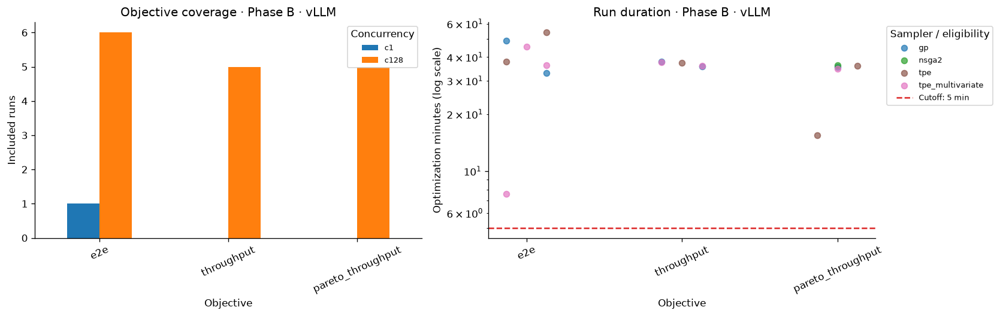

,state,trials
0,COMPLETE,296
1,FAIL,1
2,PRUNED,22
3,RUNNING,1


Runs without recorded outcome counts: 0


#### Concurrency 1 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 1.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c1-e2e-tpe-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c1-e2e-tpe-s11-r1,sglang-phase-b-pruning-min400-v1,mdubhu8o,e2e,C02,tpe,37.95,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.85graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 3072performance_mode: throughput,4,572.776633,True,all W&B COMPLETE trials


##### Matching context C02

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 32, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

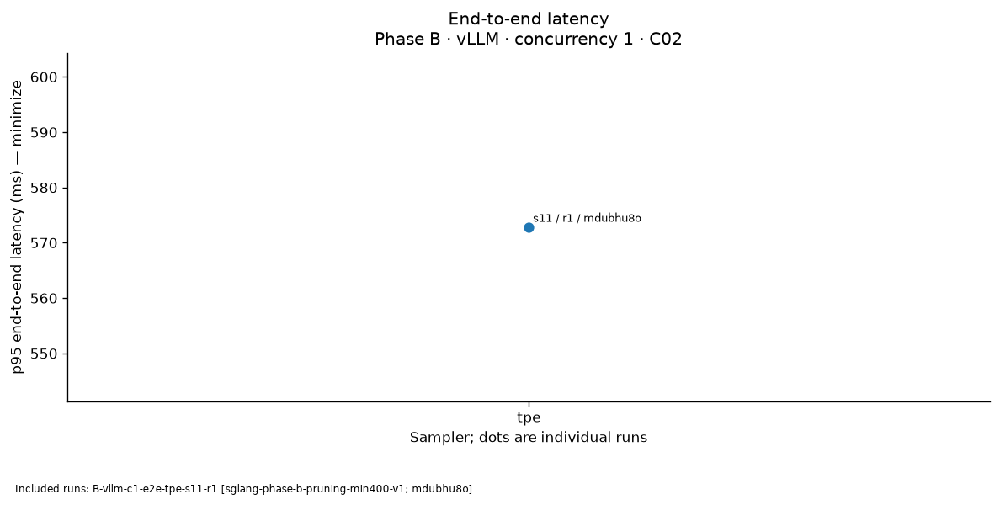

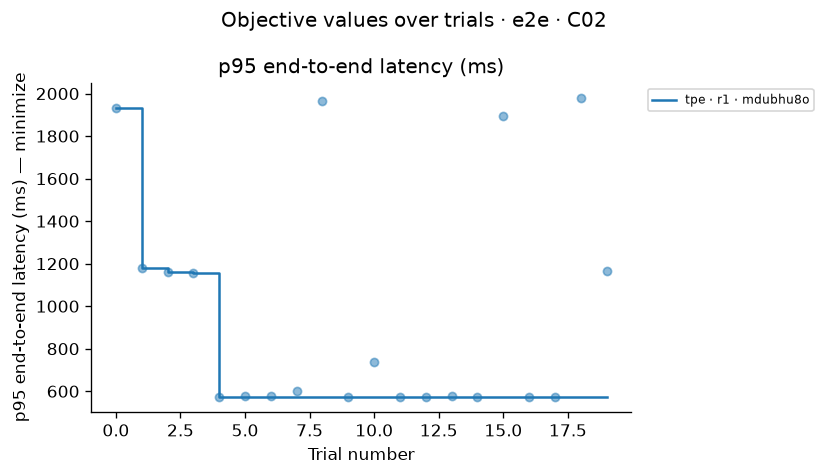

#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11, seed unknown. Repeats: r3, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r3`
- `B-vllm-c128-e2e-gp-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r3-pruner-median,optuna-phase-b-v1-pruning,bmio0yox,e2e,C64,gp,32.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 13056max_num_seqs: 128performance_mode: balanced,14,2591.268159,False,all local COMPLETE trials
B-vllm-c128-e2e-gp-s11-r3,optuna-inference-lab-ezy2i4mn,a8ktejgz,e2e,C63,gp,48.74,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,13,2318.987960,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r3,optuna-inference-lab-ezy2i4mn,15gvekae,e2e,C63,tpe,54.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: balanced,11,2597.275879,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,optuna-phase-b-v1-pruning,8v8i2627,e2e,C64,tpe_multivariate,7.57,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1536max_num_seqs: 88performance_mode: interactivity,1,4870.676495,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,optuna-phase-b-v1-pruning,r3z01gj1,e2e,C64,tpe_multivariate,36.21,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 29952max_num_seqs: 128performance_mode: interactivity,16,2382.828467,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r3,optuna-inference-lab-ezy2i4mn,e31bigam,e2e,C63,tpe_multivariate,45.48,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 30976max_num_seqs: 128performance_mode: interactivity,15,2419.543139,False,all W&B COMPLETE trials


##### Matching context C63

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

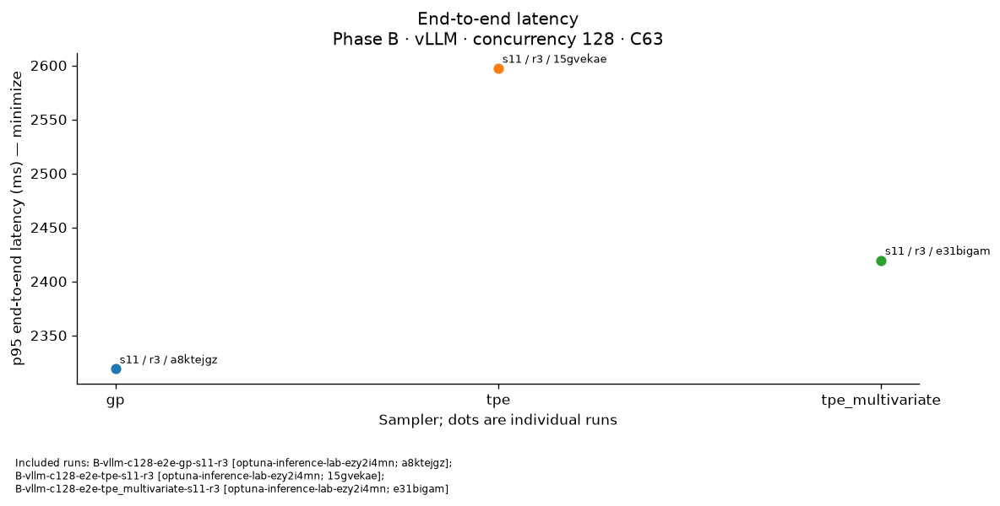

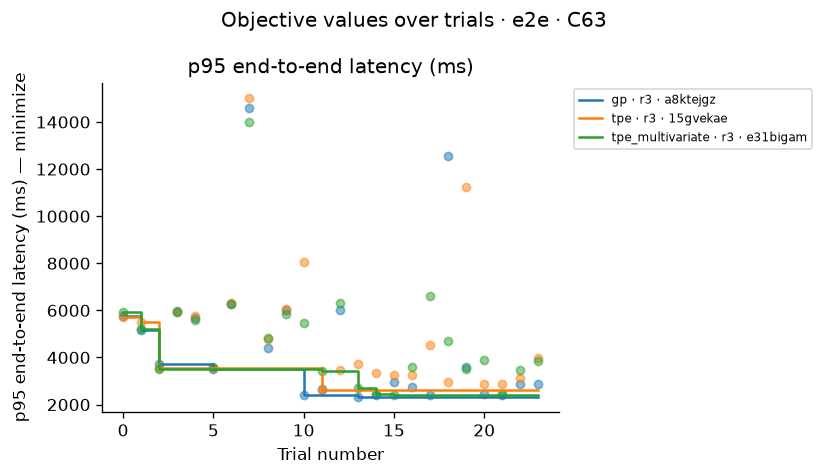

##### Matching context C64

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

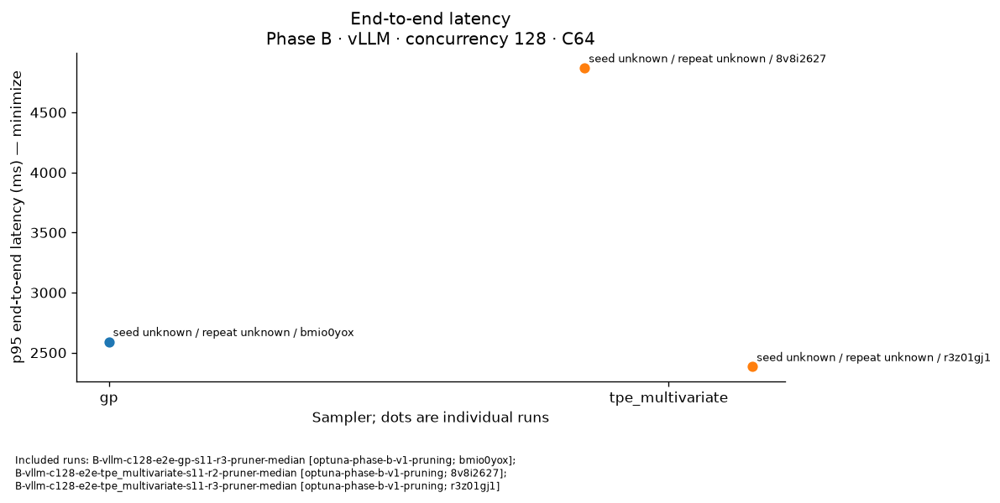

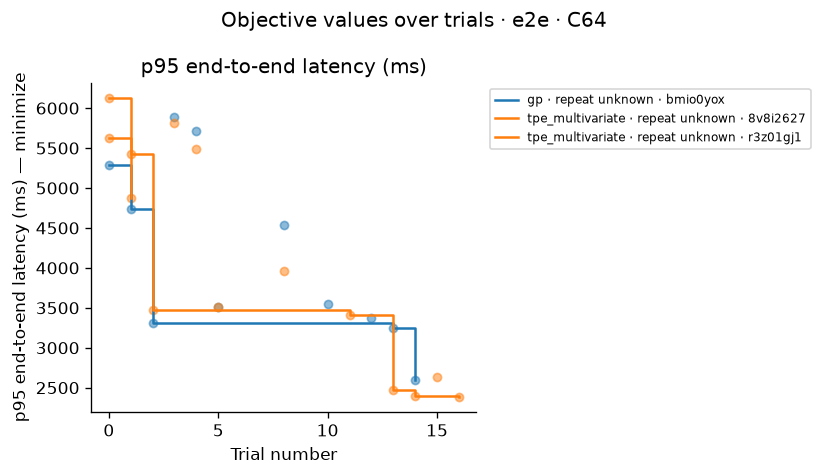

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 5.** Optimizer seeds: s11, seed unknown. Repeats: r1, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r1`
- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r1-pruner-median,optuna-phase-b-v1-pruning,rfjsqemv,throughput,C55,gp,35.58,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 22784max_num_seqs: 128performance_mode: throughput,19,7311.466850,False,all local COMPLETE trials
B-vllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,2f2gjeil,throughput,C54,gp,37.70,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,17,7258.913112,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r1,optuna-phase-b-v1,43sekwr7,throughput,C54,tpe,37.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 15104max_num_seqs: 128performance_mode: throughput,18,7216.036606,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,optuna-phase-b-v1-pruning,z68gp9cg,throughput,C55,tpe_multivariate,36.01,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: balanced,16,7130.677025,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,4hxfaxio,throughput,C54,tpe_multivariate,37.69,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: balanced,16,7338.657147,False,all local COMPLETE trials


##### Matching context C54

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

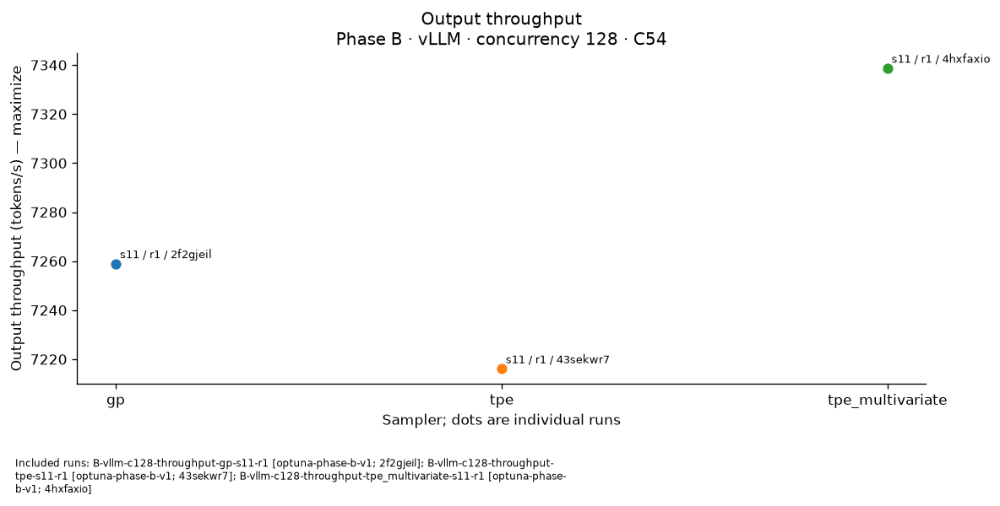

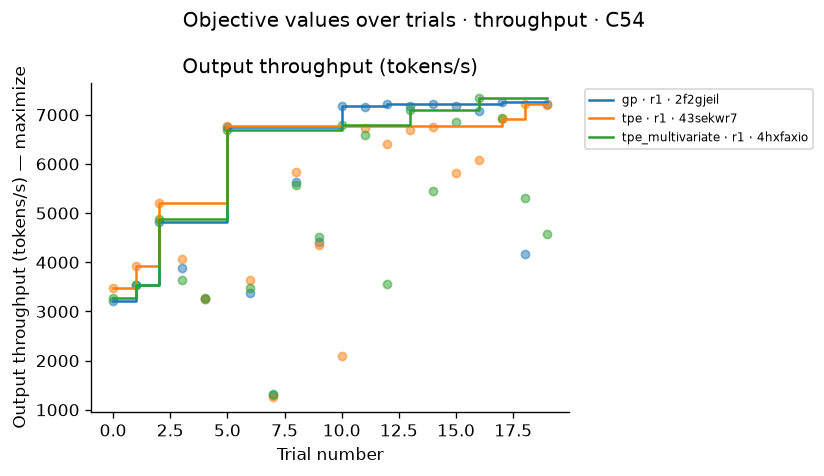

##### Matching context C55

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

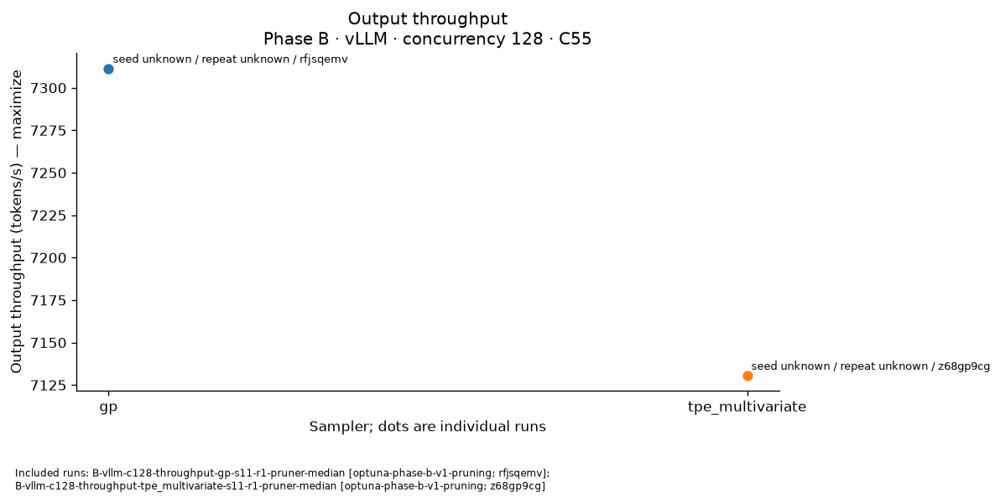

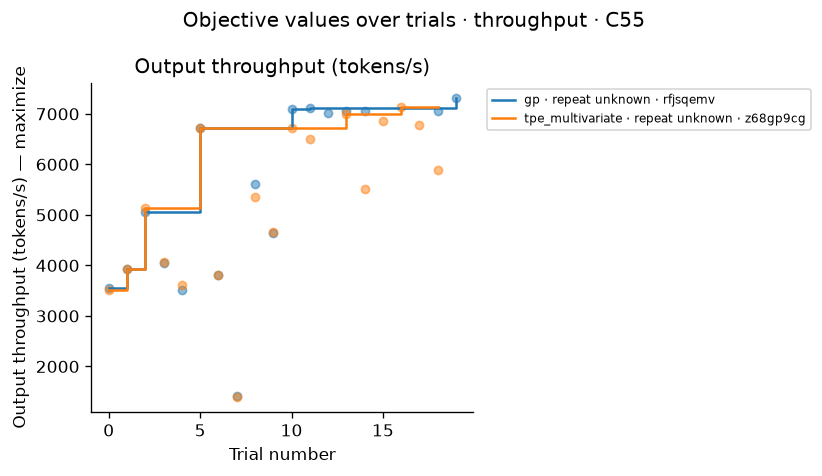

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: s11. Repeats: r2, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-pareto_throughput-gp-s11-r3`
- `B-vllm-c128-pareto_throughput-nsga2-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe-s11-r2`
- `B-vllm-c128-pareto_throughput-tpe-s11-r3`
- `B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-pareto_throughput-gp-s11-r3,optuna-phase-b-v1,dpe6es0u,pareto_throughput,C48,gp,35.56,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 29184max_num_seqs: 128performance_mode: interactivity,11,7267.537112,2356.134052,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-nsga2-s11-r3,optuna-phase-b-v1,izfuyq9r,pareto_throughput,C48,nsga2,36.22,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,6709.988591,3588.033864,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-nsga2-s11-r3,optuna-phase-b-v1,izfuyq9r,pareto_throughput,C48,nsga2,36.22,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.85graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 88performance_mode: balanced,17,6072.547553,3407.458722,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r2,optuna-phase-b-v1,m4wvp4cb,pareto_throughput,C48,tpe,15.43,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,6811.108681,3490.972053,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C48,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,6774.959546,3398.543602,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C48,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 7424max_num_seqs: 96performance_mode: balanced,13,6553.758814,3299.040544,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C48,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 13312max_num_seqs: 72performance_mode: balanced,16,5927.288289,3176.463044,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe-s11-r3,optuna-phase-b-v1,ame382m3,pareto_throughput,C48,tpe,35.89,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 5376max_num_seqs: 112performance_mode: throughput,17,6983.615323,3409.441405,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3,optuna-phase-b-v1,x5yc2flo,pareto_throughput,C48,tpe_multivariate,34.69,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19456max_num_seqs: 104performance_mode: balanced,10,6795.390953,3474.930845,False,all local COMPLETE trials
B-vllm-c128-pareto_throughput-tpe_multivariate-s11-r3,optuna-phase-b-v

##### Matching context C48

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

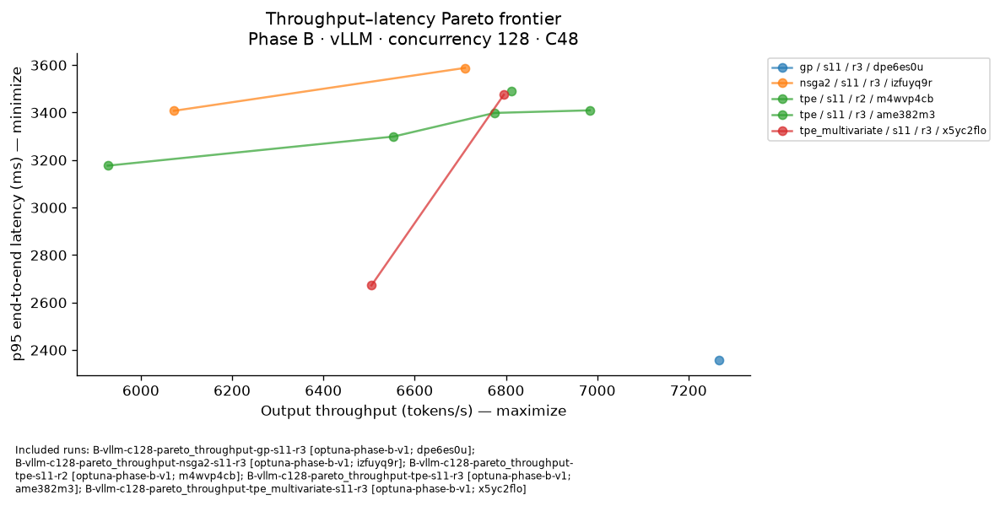

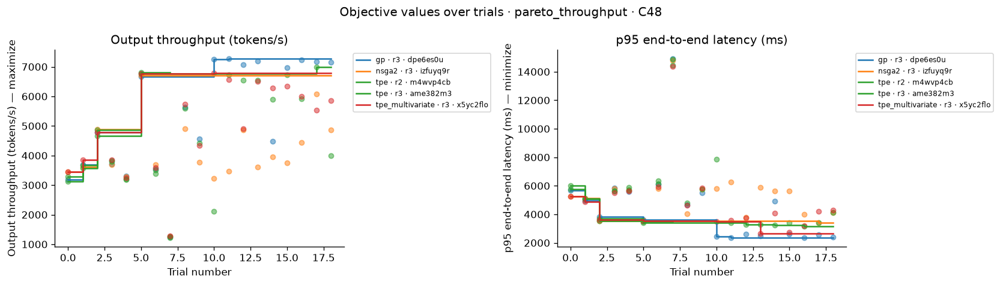

Phase A / vLLM: 29 included runs; cutoff 5 minutes


**Runs included: 26.** Optimizer seeds: s11. Repeats: r1, r2.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-e2e-gp-s11-r2`
- `A-vllm-c1-e2e-grid-s11-r1`
- `A-vllm-c1-e2e-grid-s11-r2`
- `A-vllm-c1-e2e-qmc-s11-r2`
- `A-vllm-c1-e2e-random-s11-r2`
- `A-vllm-c1-e2e-tpe-s11-r2`
- `A-vllm-c1-e2e-tpe_multivariate-s11-r2`
- `A-vllm-c1-ttft-gp-s11-r1`
- `A-vllm-c1-ttft-grid-s11-r1`
- `A-vllm-c1-ttft-qmc-s11-r1`
- `A-vllm-c1-ttft-random-s11-r1`
- `A-vllm-c1-ttft-tpe-s11-r1`
- `A-vllm-c1-ttft-tpe_multivariate-s11-r1`
- `A-vllm-c128-e2e-gp-s11-r1`
- `A-vllm-c128-e2e-grid-s11-r1`
- `A-vllm-c128-e2e-qmc-s11-r1`
- `A-vllm-c128-e2e-random-s11-r1`
- `A-vllm-c128-e2e-tpe-s11-r1`
- `A-vllm-c128-e2e-tpe_multivariate-s11-r1`
- `A-vllm-c128-pareto_throughput-gp-s11-r1`
- `A-vllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `A-vllm-c128-throughput-gp-s11-r1`
- `A-vllm-c128-throughput-tpe-s11-r1`
- `A-vllm-c128-throughput-tpe_multivariate-s11-r1`

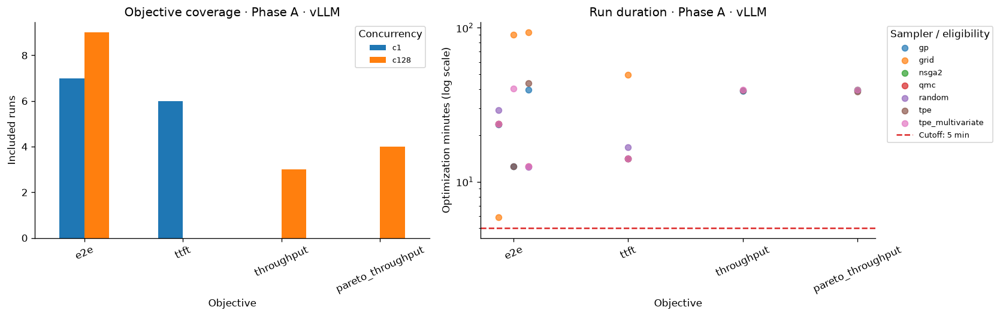

,state,trials
0,COMPLETE,488
1,FAIL,1
2,RUNNING,1


Runs without recorded outcome counts: 0


#### Concurrency 1 · Phase A · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 7.** Optimizer seeds: s11. Repeats: r1, r2.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-e2e-gp-s11-r2`
- `A-vllm-c1-e2e-grid-s11-r1`
- `A-vllm-c1-e2e-grid-s11-r2`
- `A-vllm-c1-e2e-qmc-s11-r2`
- `A-vllm-c1-e2e-random-s11-r2`
- `A-vllm-c1-e2e-tpe-s11-r2`
- `A-vllm-c1-e2e-tpe_multivariate-s11-r2`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c1-e2e-gp-s11-r2,optuna-inference-lab-k59lf6t5,opn2e3xt,e2e,C03,gp,23.63,cuda_graph_on: 1max_num_batched_tokens: 5120,0,318.072937,True,all local COMPLETE trials
A-vllm-c1-e2e-grid-s11-r1,optuna-inference-lab-ct_91ft_,5nei8053,e2e,C03,grid,5.86,cuda_graph_on: 1max_num_batched_tokens: 1024,0,324.783551,True,all local COMPLETE trials
A-vllm-c1-e2e-grid-s11-r2,optuna-inference-lab-k59lf6t5,jhp575i2,e2e,C03,grid,89.84,cuda_graph_on: 1max_num_batched_tokens: 1024,0,318.423983,True,all local COMPLETE trials
A-vllm-c1-e2e-qmc-s11-r2,optuna-inference-lab-k59lf6t5,jiam85ja,e2e,C03,qmc,23.78,cuda_graph_on: 1max_num_batched_tokens: 5120,0,324.887006,True,all local COMPLETE trials
A-vllm-c1-e2e-random-s11-r2,optuna-inference-lab-k59lf6t5,ox1v6gg2,e2e,C03,random,29.23,cuda_graph_on: 1max_num_batched_tokens: 5120,0,323.455537,True,all local COMPLETE trials
A-vllm-c1-e2e-tpe-s11-r2,optuna-inference-lab-k59lf6t5,o8lrmftt,e2e,C03,tpe,23.81,cuda_graph_on: 1max_num_batched_tokens: 8192,4,321.652873,True,all local COMPLETE trials
A-vllm-c1-e2e-tpe_multivariate-s11-r2,optuna-inference-lab-k59lf6t5,d9w96v9e,e2e,C03,tpe_multivariate,23.80,cuda_graph_on: 1max_num_batched_tokens: 5120,0,319.413708,True,all local COMPLETE trials


##### Matching context C03

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 256, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

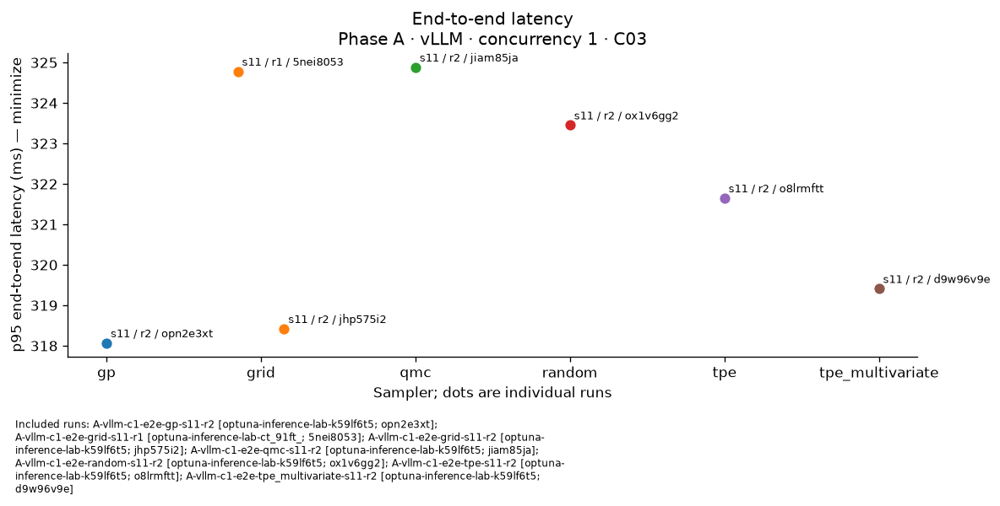

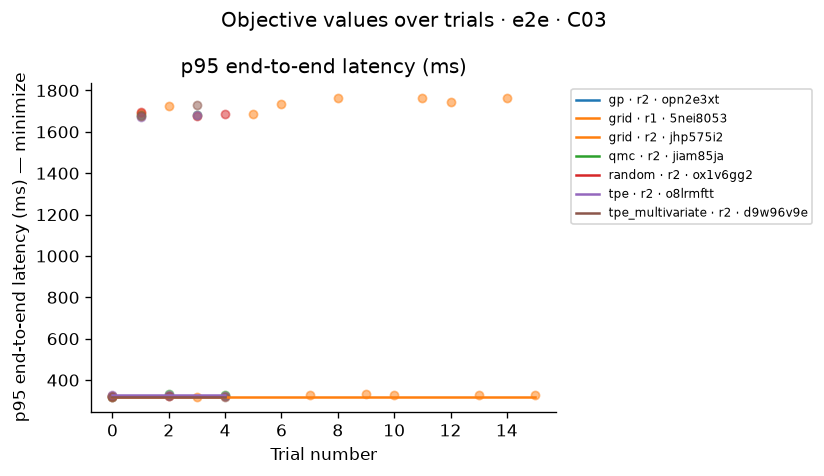

##### Time to first token (`ttft`)

Minimize p95 time to first token (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c1-ttft-gp-s11-r1`
- `A-vllm-c1-ttft-grid-s11-r1`
- `A-vllm-c1-ttft-qmc-s11-r1`
- `A-vllm-c1-ttft-random-s11-r1`
- `A-vllm-c1-ttft-tpe-s11-r1`
- `A-vllm-c1-ttft-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_ttft_ms,SLO feasible,result source
A-vllm-c1-ttft-gp-s11-r1,optuna-inference-lab-z7kb01i6,rmowxrah,ttft,C04,gp,14.15,cuda_graph_on: 1max_num_batched_tokens: 8192,4,33.429065,True,all W&B COMPLETE trials
A-vllm-c1-ttft-grid-s11-r1,optuna-inference-lab-z7kb01i6,0ye31grd,ttft,C04,grid,49.65,cuda_graph_on: 1max_num_batched_tokens: 7168,7,32.987721,True,all W&B COMPLETE trials
A-vllm-c1-ttft-qmc-s11-r1,optuna-inference-lab-z7kb01i6,syas1k1d,ttft,C04,qmc,14.14,cuda_graph_on: 1max_num_batched_tokens: 5120,2,32.793124,True,all W&B COMPLETE trials
A-vllm-c1-ttft-random-s11-r1,optuna-inference-lab-z7kb01i6,c6tvli0k,ttft,C04,random,16.72,cuda_graph_on: 1max_num_batched_tokens: 5120,0,33.515670,True,all W&B COMPLETE trials
A-vllm-c1-ttft-tpe-s11-r1,optuna-inference-lab-z7kb01i6,4yxy65wf,ttft,C04,tpe,14.17,cuda_graph_on: 1max_num_batched_tokens: 5120,0,33.217431,True,all W&B COMPLETE trials
A-vllm-c1-ttft-tpe_multivariate-s11-r1,optuna-inference-lab-z7kb01i6,538umr4q,ttft,C04,tpe_multivariate,14.11,cuda_graph_on: 1max_num_batched_tokens: 4096,2,33.234949,True,all W&B COMPLETE trials


##### Matching context C04

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 128, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

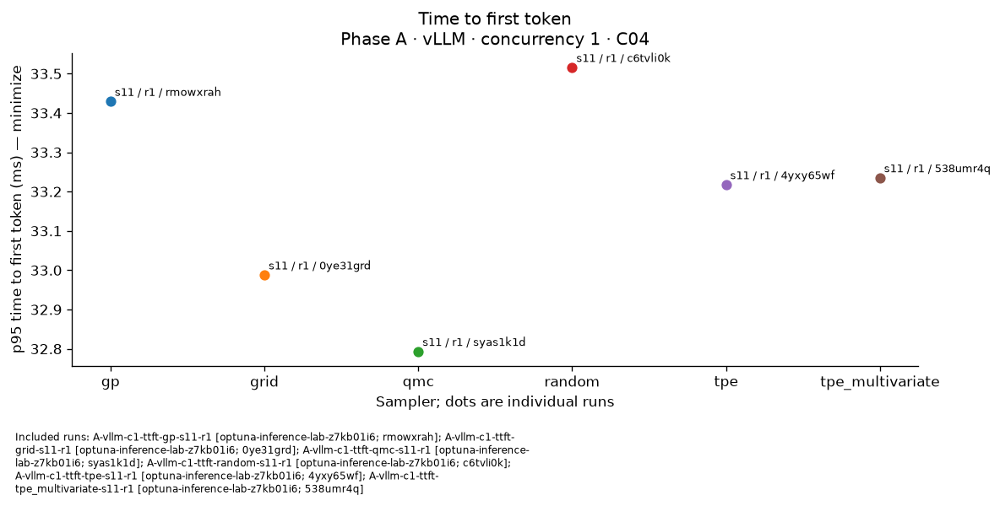

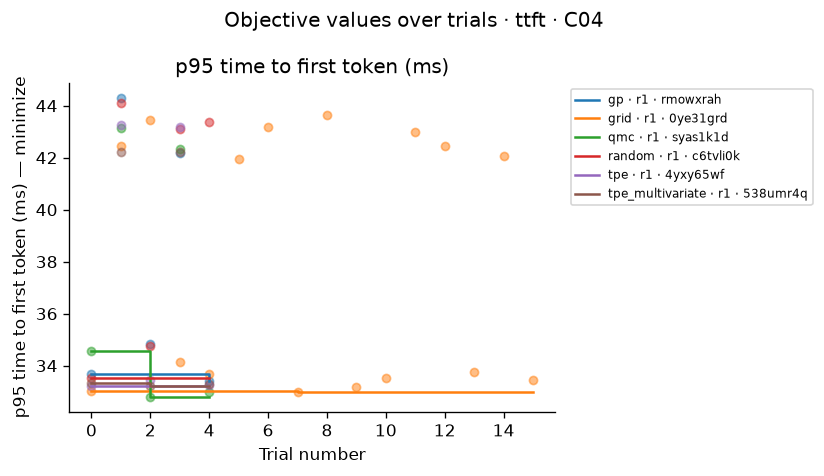

#### Concurrency 128 · Phase A · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-e2e-gp-s11-r1`
- `A-vllm-c128-e2e-grid-s11-r1`
- `A-vllm-c128-e2e-qmc-s11-r1`
- `A-vllm-c128-e2e-random-s11-r1`
- `A-vllm-c128-e2e-tpe-s11-r1`
- `A-vllm-c128-e2e-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-idcgg3zn / gz1r6mo8],optuna-inference-lab-idcgg3zn,gz1r6mo8,e2e,C67,gp,12.59,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2251.113067,False,all W&B COMPLETE trials
A-vllm-c128-e2e-gp-s11-r1 [optuna-inference-lab-p0lfaev2 / ipqq6aa3],optuna-inference-lab-p0lfaev2,ipqq6aa3,e2e,C68,gp,39.43,gpu_memory_utilization: 0.75max_num_batched_tokens: 6144max_num_seqs: 32,4,2061.378252,False,all local COMPLETE trials
A-vllm-c128-e2e-grid-s11-r1,optuna-inference-lab-idcgg3zn,10bj2xwx,e2e,C67,grid,93.80,gpu_memory_utilization: 0.9max_num_batched_tokens: 8192max_num_seqs: 32,25,2239.116174,False,all W&B COMPLETE trials
A-vllm-c128-e2e-qmc-s11-r1,optuna-inference-lab-idcgg3zn,ohwjiiyv,e2e,C67,qmc,12.62,gpu_memory_utilization: 0.8max_num_batched_tokens: 6144max_num_seqs: 32,2,2311.201523,False,all W&B COMPLETE trials
A-vllm-c128-e2e-random-s11-r1,optuna-inference-lab-idcgg3zn,ksgwxqzo,e2e,C67,random,12.50,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2292.550333,False,all W&B COMPLETE trials
A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-idcgg3zn / aarrc9iq],optuna-inference-lab-idcgg3zn,aarrc9iq,e2e,C67,tpe,12.58,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2268.280409,False,all W&B COMPLETE trials
A-vllm-c128-e2e-tpe-s11-r1 [optuna-inference-lab-p0lfaev2 / frli9q3o],optuna-inference-lab-p0lfaev2,frli9q3o,e2e,C68,tpe,43.62,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,15,2007.965752,False,all local COMPLETE trials
A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-p0lfaev2 / 2wg9v2w7],optuna-inference-lab-p0lfaev2,2wg9v2w7,e2e,C68,tpe_multivariate,40.44,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2097.456085,False,all local COMPLETE trials
A-vllm-c128-e2e-tpe_multivariate-s11-r1 [optuna-inference-lab-idcgg3zn / yvfxh5yx],optuna-inference-lab-idcgg3zn,yvfxh5yx,e2e,C67,tpe_multivariate,12.59,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,5,2251.856940,False,all W&B COMPLETE trials


##### Matching context C67

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

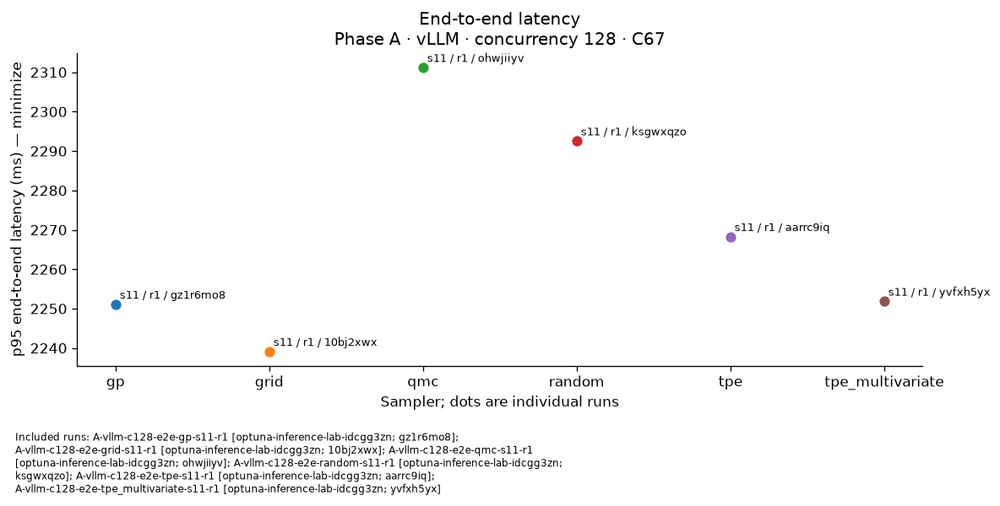

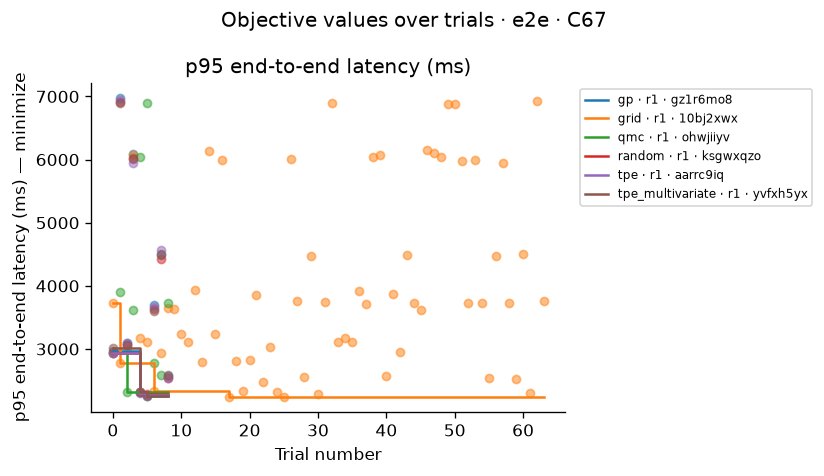

##### Matching context C68

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

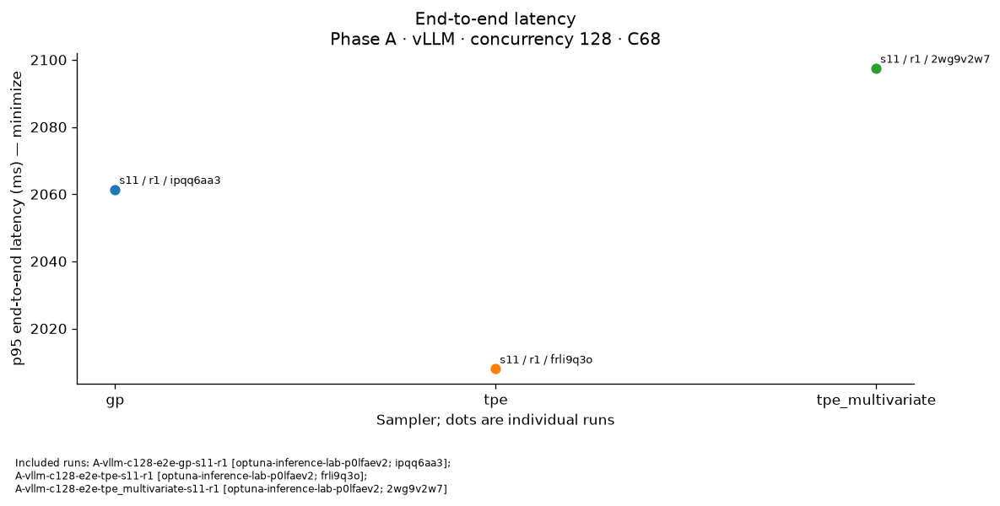

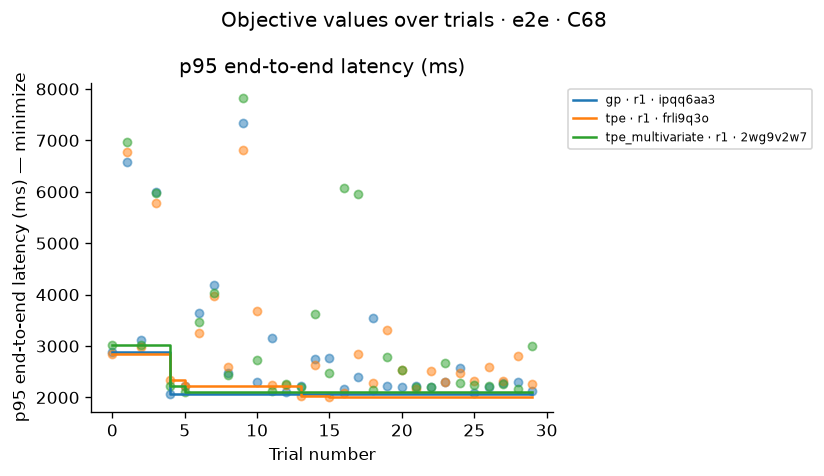

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-throughput-gp-s11-r1`
- `A-vllm-c128-throughput-tpe-s11-r1`
- `A-vllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
A-vllm-c128-throughput-gp-s11-r1,optuna-inference-lab-p0lfaev2,fj4tc735,throughput,C66,gp,38.87,gpu_memory_utilization: 0.9max_num_batched_tokens: 8192max_num_seqs: 32,14,8052.185340,False,all local COMPLETE trials
A-vllm-c128-throughput-tpe-s11-r1,optuna-inference-lab-p0lfaev2,ese3iqsy,throughput,C66,tpe,39.15,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,11,7998.110003,False,all local COMPLETE trials
A-vllm-c128-throughput-tpe_multivariate-s11-r1,optuna-inference-lab-p0lfaev2,fjff3da4,throughput,C66,tpe_multivariate,39.52,gpu_memory_utilization: 0.75max_num_batched_tokens: 6144max_num_seqs: 32,4,8033.775681,False,all local COMPLETE trials


##### Matching context C66

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

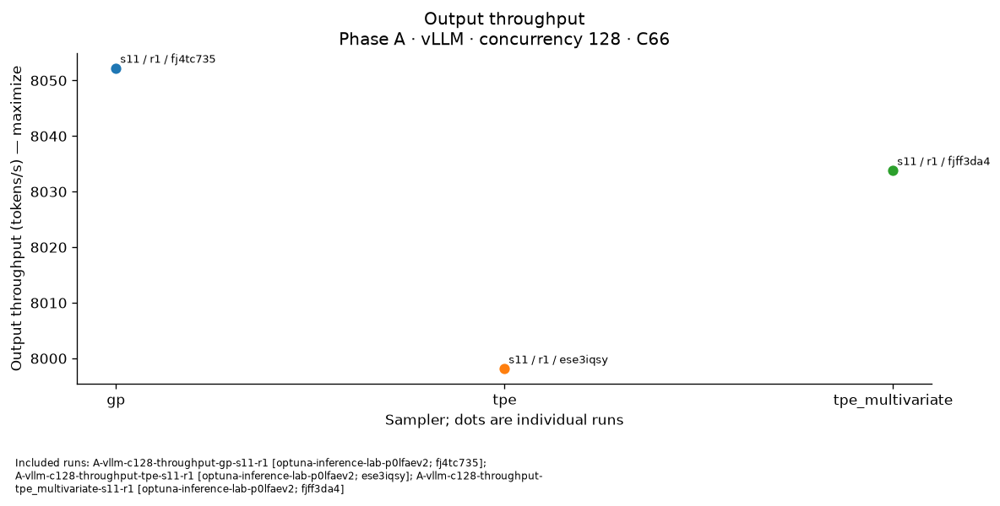

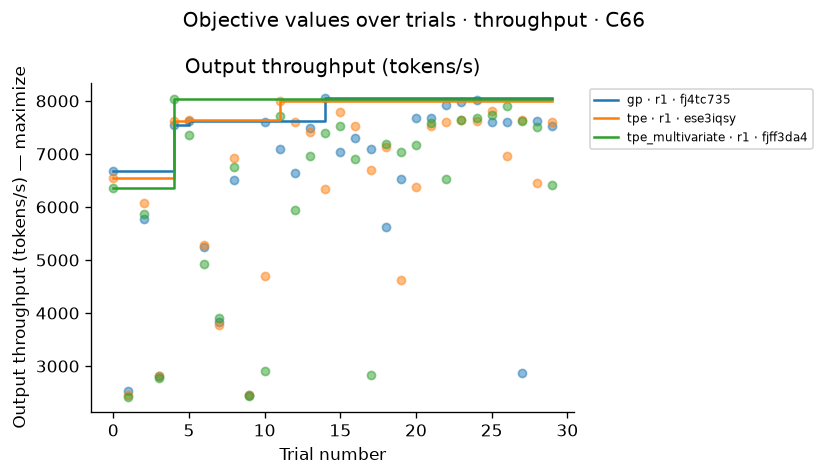

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-vllm-c128-pareto_throughput-gp-s11-r1`
- `A-vllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe-s11-r1`
- `A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
A-vllm-c128-pareto_throughput-gp-s11-r1,optuna-inference-lab-p0lfaev2,vpdy77nz,pareto_throughput,C65,gp,39.25,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,21,7811.656519,2147.946572,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-nsga2-s11-r1,optuna-inference-lab-p0lfaev2,22nnu8tm,pareto_throughput,C65,nsga2,39.40,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,29,8126.203358,2059.168171,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-tpe-s11-r1,optuna-inference-lab-p0lfaev2,25o6iogc,pareto_throughput,C65,tpe,38.58,gpu_memory_utilization: 0.75max_num_batched_tokens: 8192max_num_seqs: 32,12,8023.542870,2089.006049,False,all local COMPLETE trials
A-vllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-inference-lab-p0lfaev2,lmy4u5xz,pareto_throughput,C65,tpe_multivariate,39.48,gpu_memory_utilization: 0.8max_num_batched_tokens: 8192max_num_seqs: 32,21,8342.212417,2008.666799,False,all local COMPLETE trials


##### Matching context C65

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA L40S"` · **gpu count:** `1` · **model revision:** `"the model\u2019s Hugging Face commit"` · **cuda version:** `"your CUDA version"` · **driver version:** `"your NVIDIA driver version"`

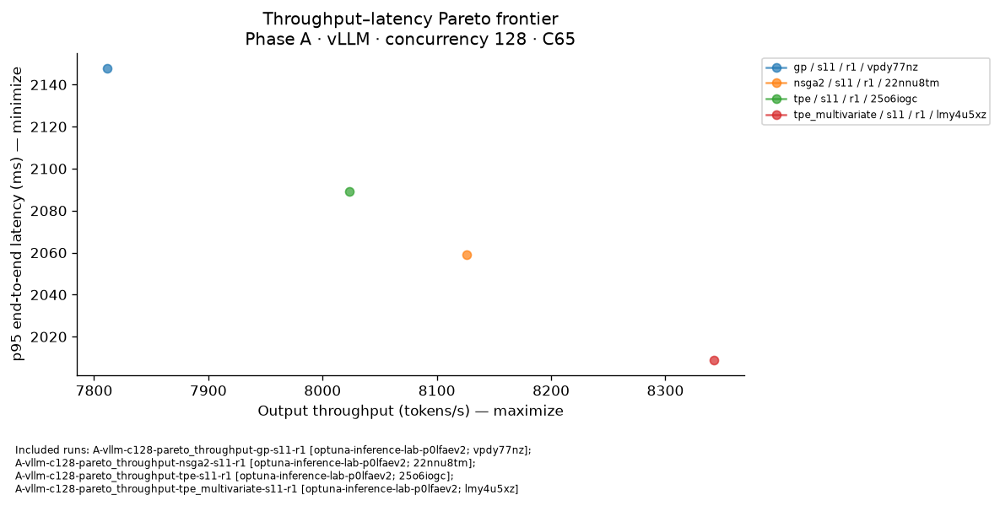

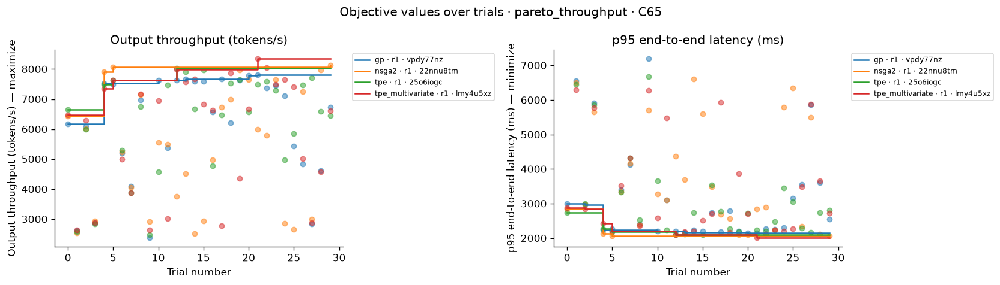

### TRT-LLM · qwen3.5-4b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3.5-4b,trtllm,e2e,kj512kft,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,1,max_num_tokens,0.665721769960426
qwen3.5-4b,trtllm,e2e,kj512kft,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,2,max_batch_size,0.1735089204253234
qwen3.5-4b,trtllm,e2e,kj512kft,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-gp-s11-r11,gp,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.16076930961425057
qwen3.5-4b,trtllm,e2e,eqz0km99,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,1,max_batch_size,0.8253950325858278
qwen3.5-4b,trtllm,e2e,eqz0km99,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,2,max_num_tokens,0.10673682699263445
qwen3.5-4b,trtllm,e2e,eqz0km99,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r1,tpe,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.06786814042153773
qwen3.5-4b,trtllm,e2e,527entdy,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,1,max_batch_size,0.8070604868709835
qwen3.5-4b,trtllm,e2e,527entdy,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,2,max_num_tokens,0.1912034880311343
qwen3.5-4b,trtllm,e2e,527entdy,local SQLite,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.0017360250978821865
qwen3.5-4b,trtllm,e2e,bxkkbjmk,W&B trial history,Optuna PED-ANOVA,A-trtllm-c128-e2e-tpe-s11-r11,tpe,p95_e2e_latency_ms,1,max_batch_size,0.8253950325858278


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attn_backend,10,0.000708,0.000005
1,e2e,p95_e2e_latency_ms,capacity_scheduler_policy,10,0.023537,0.001535
2,e2e,p95_e2e_latency_ms,enable_block_reuse,10,0.035371,0.002363
3,e2e,p95_e2e_latency_ms,enable_chunked_prefill,10,0.073608,0.014114
4,e2e,p95_e2e_latency_ms,graph_enabled,10,0.003868,0.000065
5,e2e,p95_e2e_latency_ms,kv_cache_free_gpu_memory_fraction,15,0.105973,0.011355
6,e2e,p95_e2e_latency_ms,max_batch_size,15,0.409680,0.063148
7,e2e,p95_e2e_latency_ms,max_num_tokens,15,0.392952,0.071215
8,pareto_throughput,output_throughput,attn_backend,7,0.000000,0.000000
9,pareto_throughput,output_throughput,capacity_scheduler_policy,7,0.018684,0.000491


model_group,framework,run,wandb_id,status
qwen3.5-4b,trtllm,A-trtllm-c128-e2e-tpe-s11-r3,ei7h522s,p95_e2e_latency_ms: insufficient variation
qwen3.5-4b,trtllm,B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,2p7rxcxm,p95_e2e_latency_ms: insufficient variation


Phase B / TRT-LLM: 26 included runs; cutoff 5 minutes


**Runs included: 25.** Optimizer seeds: s11, seed unknown. Repeats: r1, r2, r22, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2`
- `B-trtllm-c128-e2e-gp-s11-r22`
- `B-trtllm-c128-e2e-gp-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r1`
- `B-trtllm-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r22`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median`
- `B-trtllm-c128-pareto_throughput-gp-s11-r1`
- `B-trtllm-c128-pareto_throughput-gp-s11-r22`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r22`
- `B-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r22`
- `B-trtllm-c128-throughput-gp-s11-r1`
- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-gp-s11-r22`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r22`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r22`

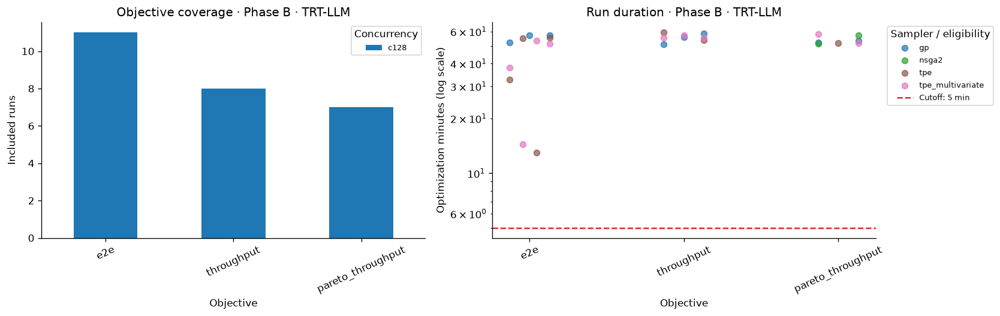

,state,trials
0,COMPLETE,411
1,FAIL,34
2,PRUNED,34


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 10.** Optimizer seeds: s11, seed unknown. Repeats: r1, r2, r22, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2`
- `B-trtllm-c128-e2e-gp-s11-r22`
- `B-trtllm-c128-e2e-gp-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r1`
- `B-trtllm-c128-e2e-tpe-s11-r22`
- `B-trtllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r5-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r22`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r5-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-gp-s11-r2,optuna-phase-b-v1,rigivcxx,e2e,C42,gp,52.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,5.0,3805.106405,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r22,optuna-phase-b-v1,wkyxp7vs,e2e,C62,gp,57.12,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,10.0,2124.685405,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r5-pruner-median,optuna-phase-b-v1-pruning,xphavxt7,e2e,C62,gp,57.38,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,10.0,2179.313160,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,nx5p83d3,e2e,C42,tpe,32.68,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,9.0,3816.721492,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r22,optuna-phase-b-v1,hgilz7qb,e2e,C62,tpe,55.08,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5.0,2970.294046,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,optuna-phase-b-v1-pruning,2p7rxcxm,e2e,NaN,tpe,13.03,—,NaN,NaN,None,no eligible result
B-trtllm-c128-e2e-tpe-s11-r5-pruner-median,optuna-phase-b-v1-pruning,s6s9fqso,e2e,C62,tpe,55.35,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 64max_num_tokens: 9984,19.0,2738.608199,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r2 [optuna-phase-b-v1 / es98j5kt],optuna-phase-b-v1,es98j5kt,e2e,C41,tpe_multivariate,38.13,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,5.0,3822.914353,False,all W&B COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r2 [optuna-phase-b-v1 / ul1h9fbn],optuna-phase-b-v1,ul1h9fbn,e2e,C42,tpe_multivariate,14.41,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 32max_num_tokens: 6144,15.0,3752.892612,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r22,optuna-phase-b-v1,gzn2ba1j,e2e,C62,tpe_multivariate,53.39,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 64max_num_tokens: 12032,10.0,2661.387811,False,all local COMPLETE trials


##### Matching context C41

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

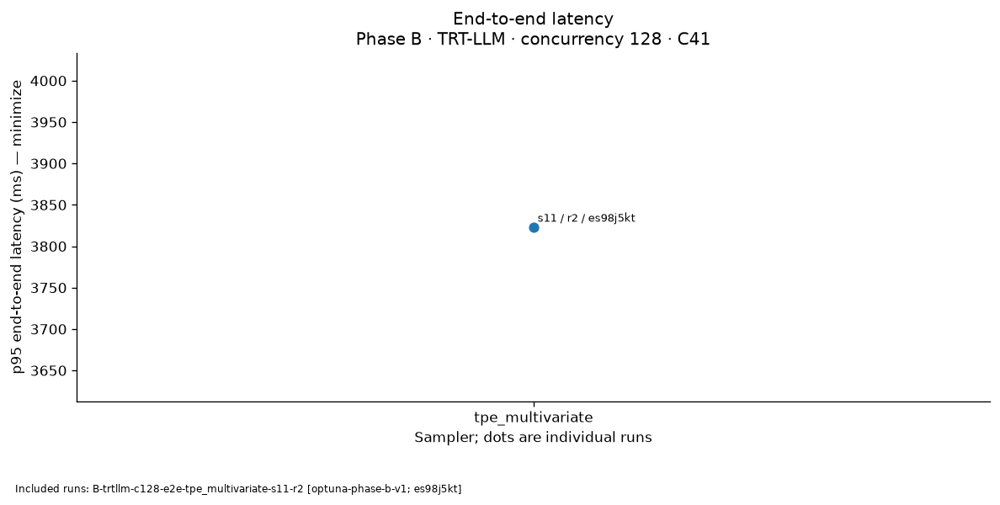

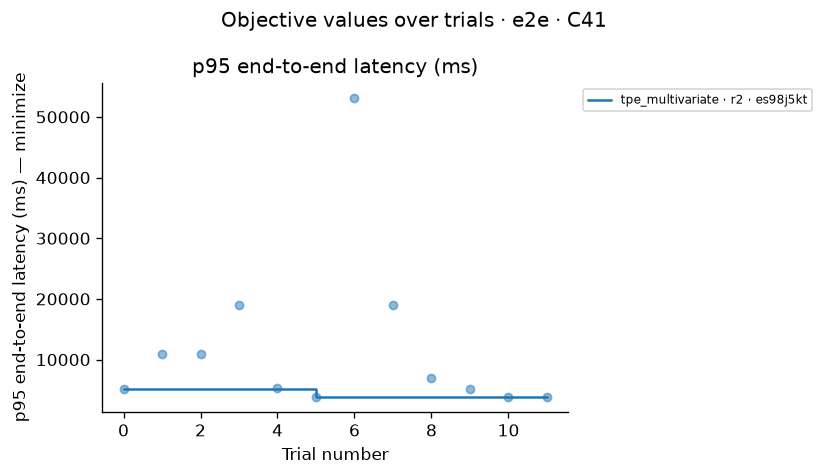

##### Matching context C42

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

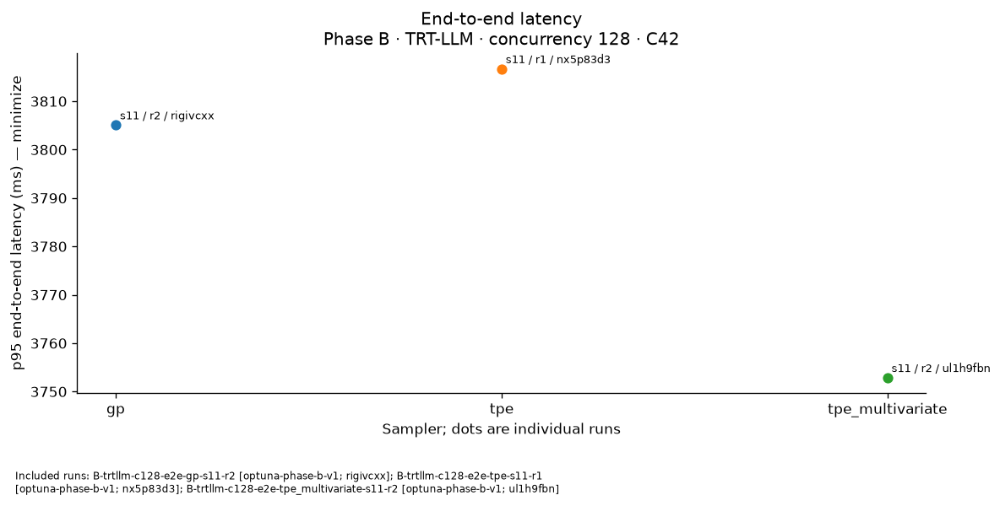

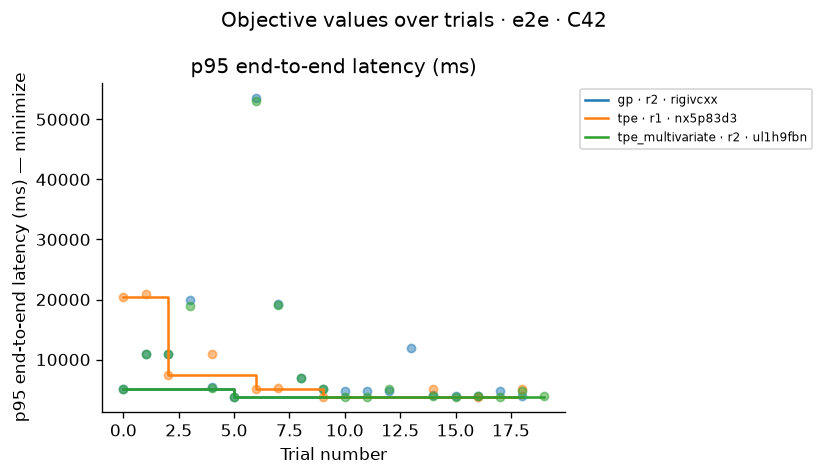

##### Matching context C62

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

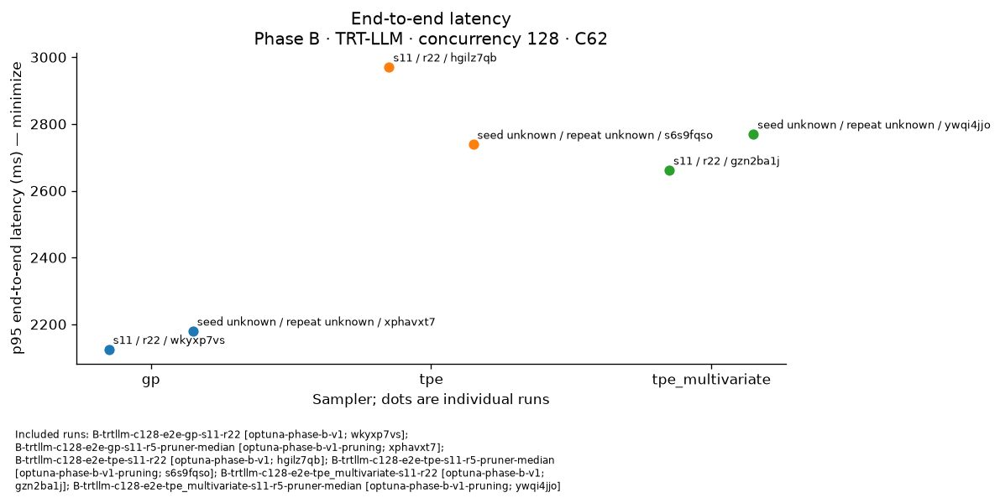

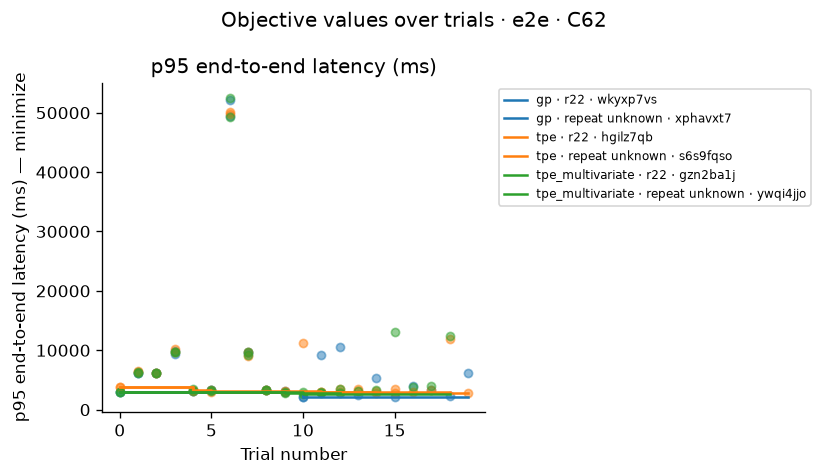

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 8.** Optimizer seeds: s11, seed unknown. Repeats: r1, r22, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-gp-s11-r1`
- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-gp-s11-r22`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r22`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-gp-s11-r1-pruner-median,optuna-phase-b-v1-pruning,yuvhs01s,throughput,C53,gp,55.77,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 20224,10,7623.099484,False,all local COMPLETE trials
B-trtllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,4qkrby5x,throughput,C35,gp,51.10,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,13,4310.002299,False,all local COMPLETE trials
B-trtllm-c128-throughput-gp-s11-r22,optuna-phase-b-v1,9y5kjcb9,throughput,C53,gp,58.51,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 22016,13,7911.503773,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r1-pruner-median,optuna-phase-b-v1-pruning,pwfl3fuz,throughput,C53,tpe,59.56,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 11520,17,7448.688977,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r22,optuna-phase-b-v1,oggia3g4,throughput,C53,tpe,53.66,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 28672,17,7798.318941,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,optuna-phase-b-v1-pruning,p5ipdact,throughput,C53,tpe_multivariate,57.33,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 25856,10,7720.532847,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cwsqjp3c,throughput,C35,tpe_multivariate,55.45,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 32max_num_tokens: 8192,10,4311.995156,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r22,optuna-phase-b-v1,qbbdfr6u,throughput,C53,tpe_multivariate,55.65,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 25856,10,7756.766881,False,all local COMPLETE trials


##### Matching context C35

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

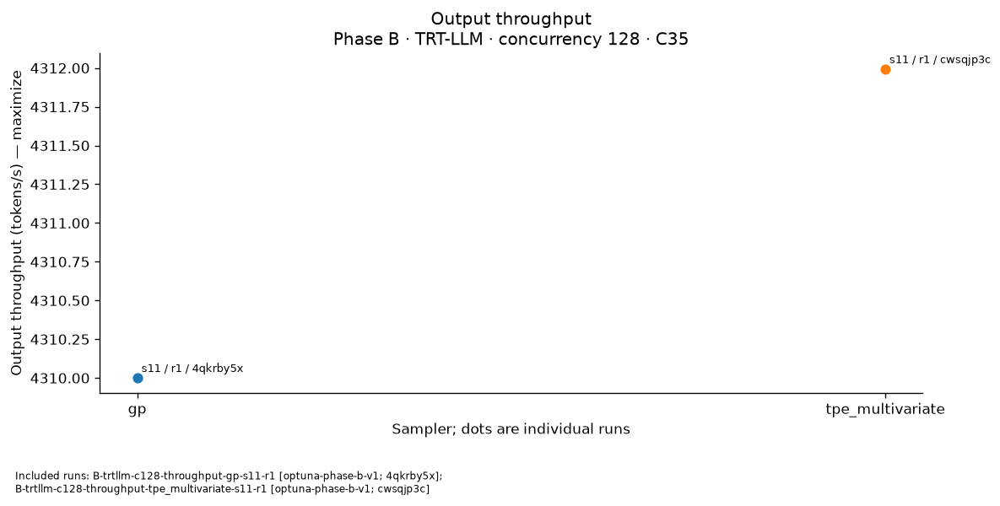

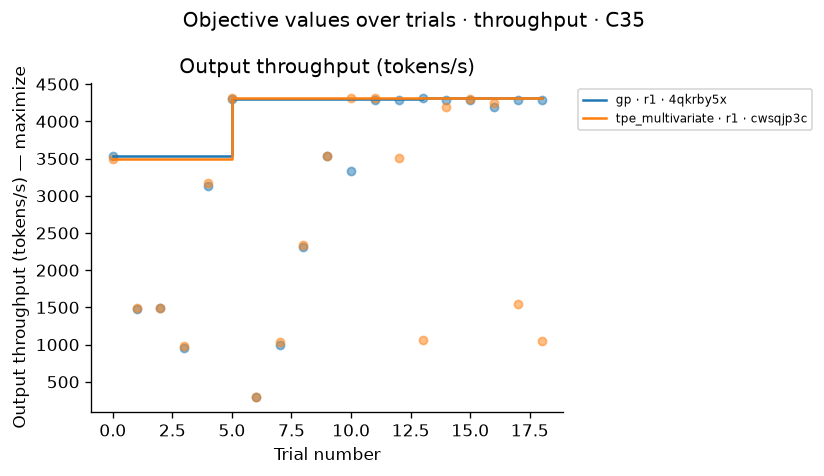

##### Matching context C53

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

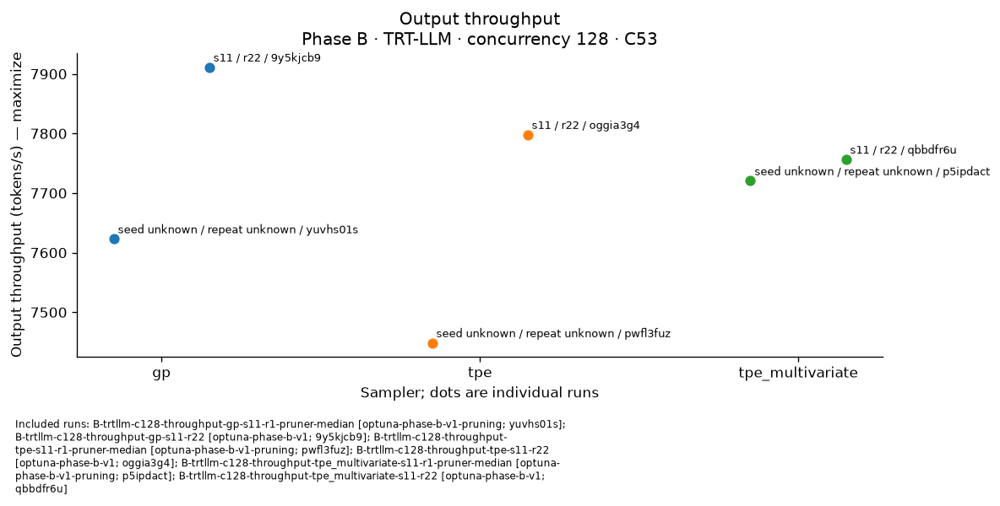

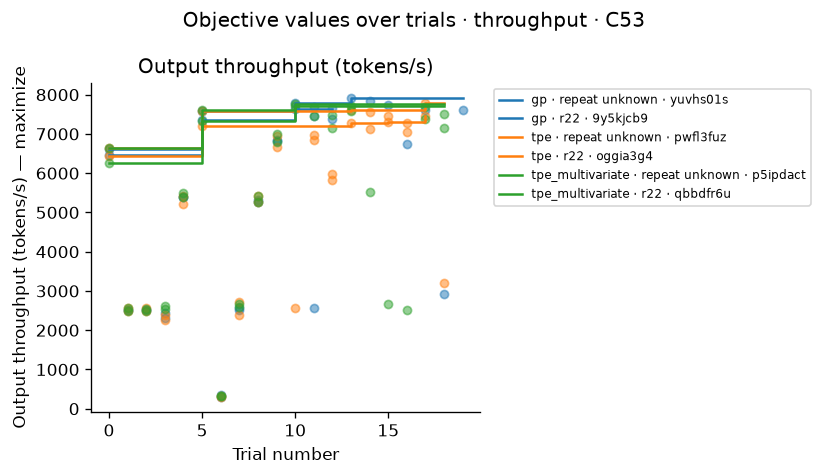

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 7.** Optimizer seeds: s11. Repeats: r1, r22.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-pareto_throughput-gp-s11-r1`
- `B-trtllm-c128-pareto_throughput-gp-s11-r22`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `B-trtllm-c128-pareto_throughput-nsga2-s11-r22`
- `B-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,suhvn561,pareto_throughput,C30,gp,52.23,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,11,4288.341401,3831.061007,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-gp-s11-r22,optuna-phase-b-v1,867reo7m,pareto_throughput,C47,gp,53.35,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 6656,10,7772.859679,2303.878451,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-gp-s11-r22,optuna-phase-b-v1,867reo7m,pareto_throughput,C47,gp,53.35,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 128max_num_tokens: 32768,18,7776.706094,2388.278669,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,i7ygpr6d,pareto_throughput,C30,nsga2,51.56,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 32max_num_tokens: 2048,15,3296.749123,5065.204020,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-nsga2-s11-r22,optuna-phase-b-v1,8opyfmjf,pareto_throughput,C47,nsga2,57.17,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896,0,6667.065529,2864.205624,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-nsga2-s11-r22,optuna-phase-b-v1,8opyfmjf,pareto_throughput,C47,nsga2,57.17,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5,7601.849439,3228.796888,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C47,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 104max_num_tokens: 25344,5,7634.273221,3230.299452,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C47,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 88max_num_tokens: 27392,9,7107.487535,3042.284144,False,all local COMPLETE trials
B-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,q5tmdttj,pareto_throughput,C47,tpe,51.65,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 96max_num_tokens: 31744,11,7265.571332,3207.770184,False,all local COMPLETE trials
B-trt

##### Matching context C30

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

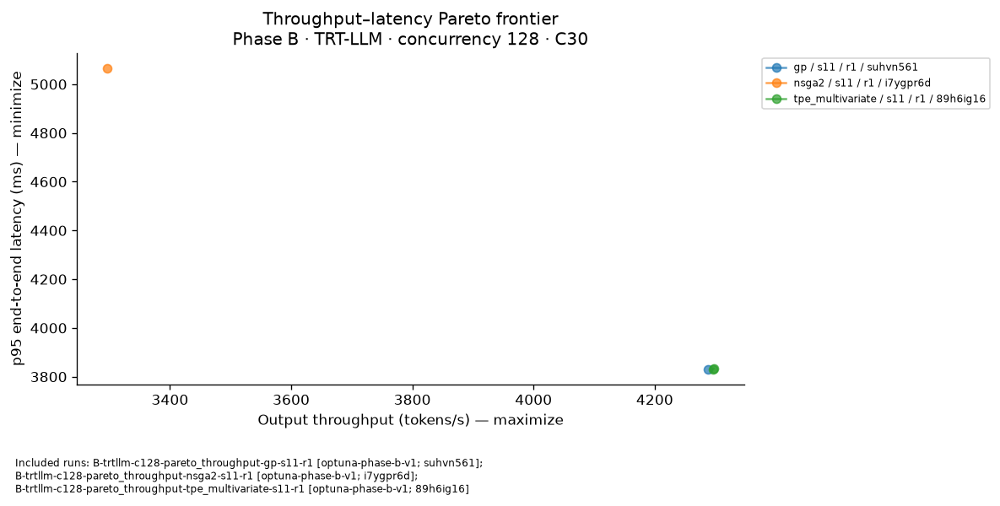

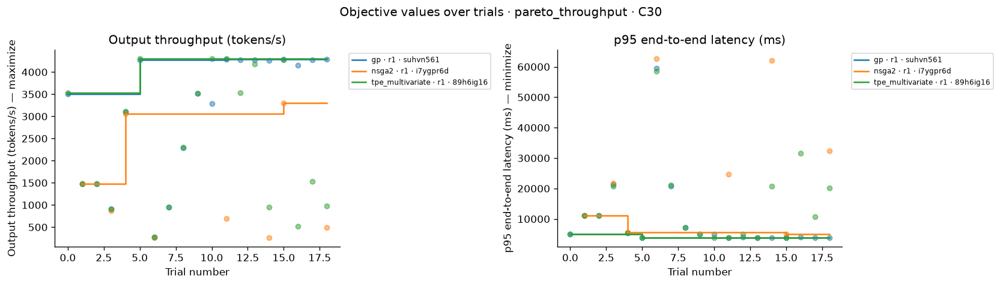

##### Matching context C47

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

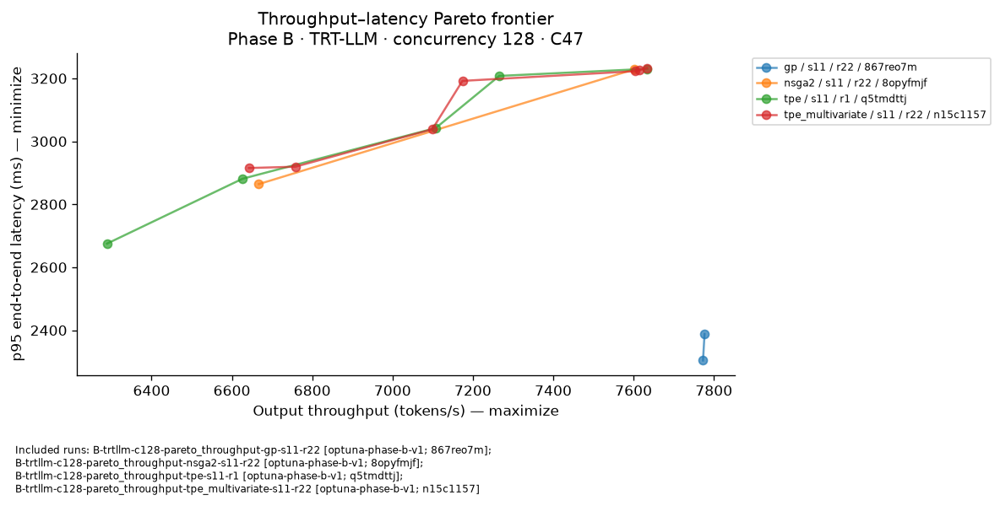

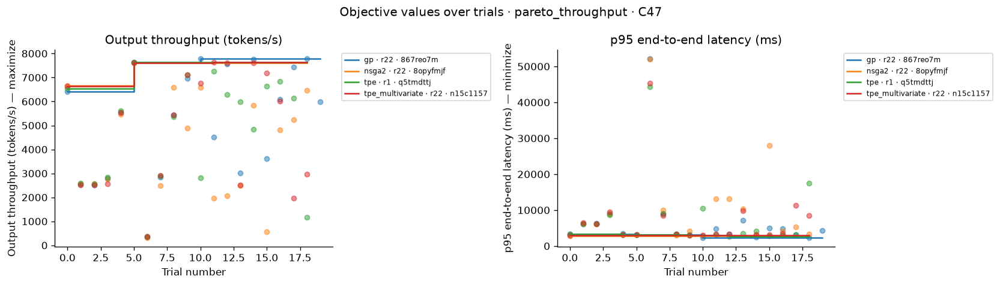

Phase A / TRT-LLM: 13 included runs; cutoff 5 minutes


**Runs included: 12.** Optimizer seeds: s11. Repeats: r1, r11, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-e2e-gp-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r1`
- `A-trtllm-c128-e2e-tpe-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r3`
- `A-trtllm-c128-e2e-tpe_multivariate-s11-r11`
- `A-trtllm-c128-pareto_throughput-gp-s11-r1`
- `A-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `A-trtllm-c128-throughput-gp-s11-r1`
- `A-trtllm-c128-throughput-tpe-s11-r1`
- `A-trtllm-c128-throughput-tpe_multivariate-s11-r1`

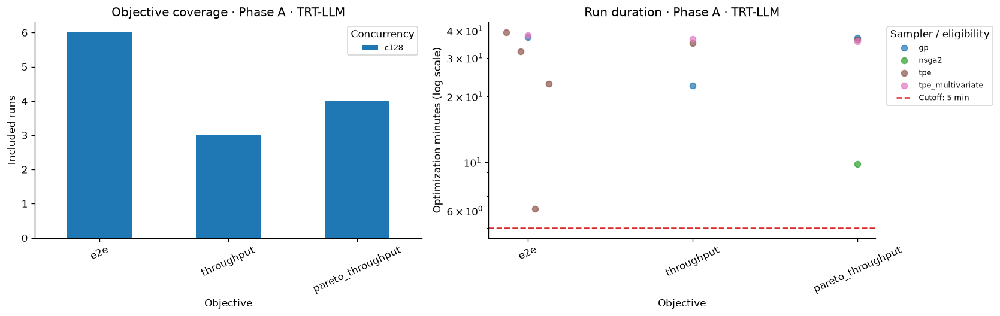

,state,trials
0,COMPLETE,204
1,FAIL,20


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase A · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: s11. Repeats: r1, r11, r3.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-e2e-gp-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r1`
- `A-trtllm-c128-e2e-tpe-s11-r11`
- `A-trtllm-c128-e2e-tpe-s11-r3`
- `A-trtllm-c128-e2e-tpe_multivariate-s11-r11`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-trtllm-c128-e2e-gp-s11-r11,optuna-phase-b-v1,kj512kft,e2e,C61,gp,37.27,kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 32max_num_tokens: 8192,13.0,1758.793908,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,eqz0km99,e2e,C61,tpe,39.39,kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 24max_num_tokens: 4096,2.0,2685.101275,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r11 [optuna-phase-b-v1 / 527entdy],optuna-phase-b-v1,527entdy,e2e,C61,tpe,32.16,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,9.0,1640.474848,False,all local COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r11 [optuna-phase-b-v1 / bxkkbjmk],optuna-phase-b-v1,bxkkbjmk,e2e,C60,tpe,6.11,kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 24max_num_tokens: 6144,0.0,2220.549765,False,all W&B COMPLETE trials
A-trtllm-c128-e2e-tpe-s11-r3,optuna-phase-b-v1,ei7h522s,e2e,NaN,tpe,22.85,—,NaN,NaN,None,no eligible result
A-trtllm-c128-e2e-tpe_multivariate-s11-r11,optuna-phase-b-v1,rvxd6m2z,e2e,C61,tpe_multivariate,38.12,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5.0,1750.887099,False,all local COMPLETE trials


##### Matching context C60

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

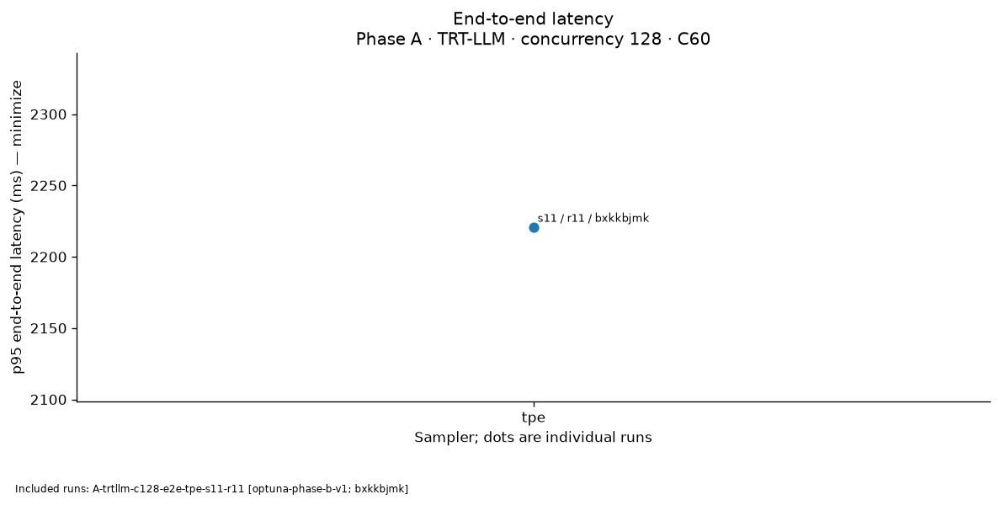

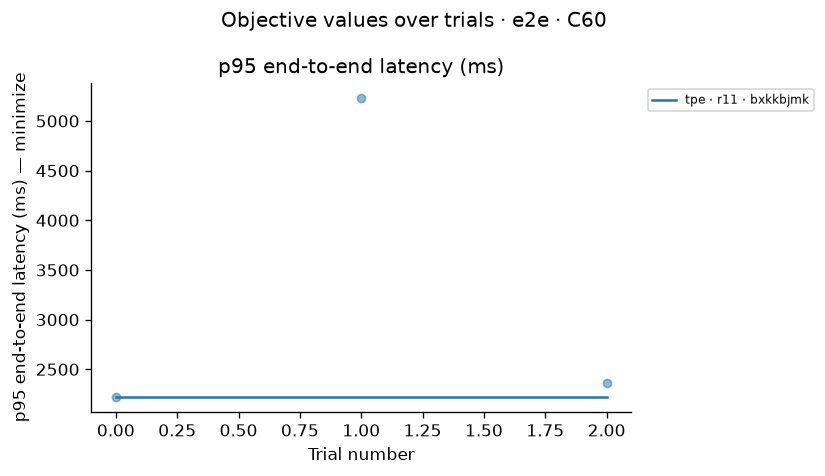

##### Matching context C61

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

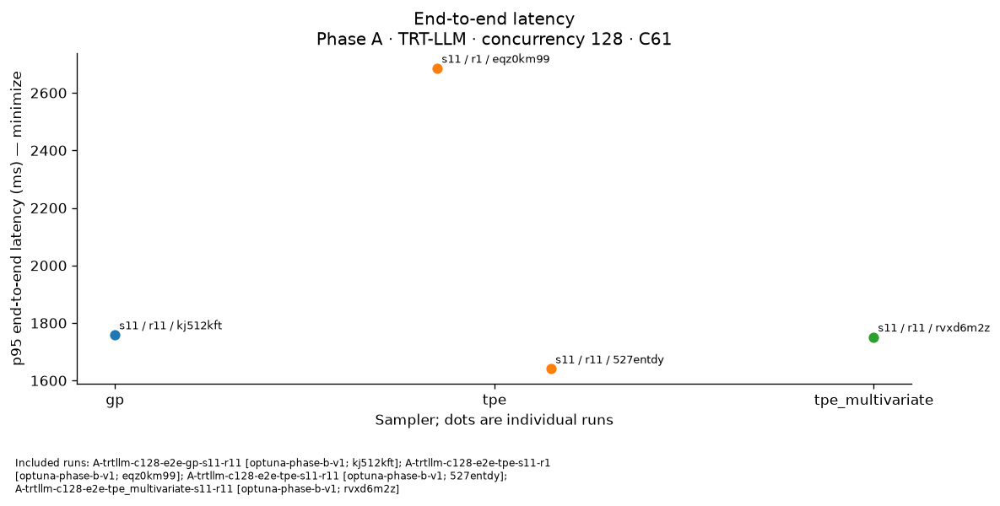

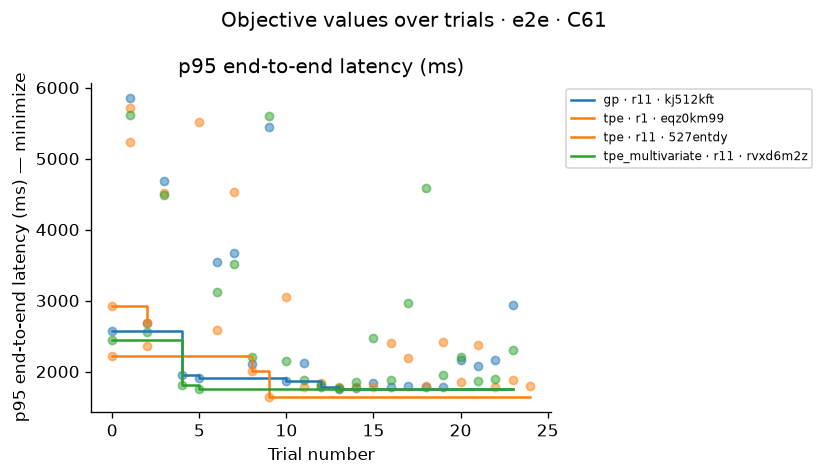

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-throughput-gp-s11-r1`
- `A-trtllm-c128-throughput-tpe-s11-r1`
- `A-trtllm-c128-throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
A-trtllm-c128-throughput-gp-s11-r1,optuna-phase-b-v1,gtjdz49d,throughput,C52,gp,22.36,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9204.285247,False,all local COMPLETE trials
A-trtllm-c128-throughput-tpe-s11-r1,optuna-phase-b-v1,orj0zbj4,throughput,C52,tpe,35.00,kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 32max_num_tokens: 6144,15,9635.181631,False,all local COMPLETE trials
A-trtllm-c128-throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,7v4tnc4r,throughput,C52,tpe_multivariate,36.64,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,9677.333780,False,all local COMPLETE trials


##### Matching context C52

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

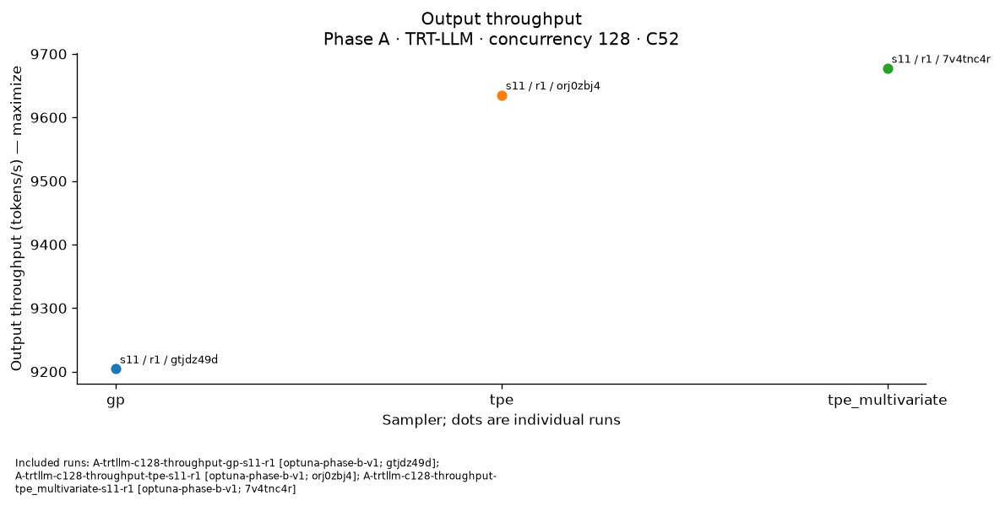

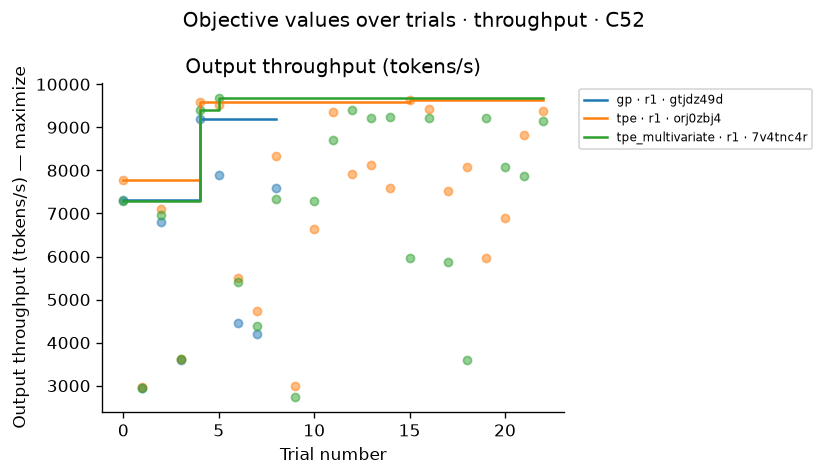

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-trtllm-c128-pareto_throughput-gp-s11-r1`
- `A-trtllm-c128-pareto_throughput-nsga2-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe-s11-r1`
- `A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
A-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,0scnkia6,pareto_throughput,C29,gp,37.22,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9059.514597,1944.418541,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,0scnkia6,pareto_throughput,C29,gp,37.22,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,8960.386219,1905.267489,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,1gnoh54k,pareto_throughput,C29,nsga2,9.83,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,8471.195193,2029.029433,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-tpe-s11-r1,optuna-phase-b-v1,zjniw2qc,pareto_throughput,C29,tpe,36.50,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,15,9698.764238,1784.890725,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cl9btqz4,pareto_throughput,C29,tpe_multivariate,35.78,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 6144,4,9515.403342,1900.893107,False,all local COMPLETE trials
A-trtllm-c128-pareto_throughput-tpe_multivariate-s11-r1,optuna-phase-b-v1,cl9btqz4,pareto_throughput,C29,tpe_multivariate,35.78,kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 32max_num_tokens: 8192,5,9473.159753,1834.726378,False,all local COMPLETE trials


##### Matching context C29

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

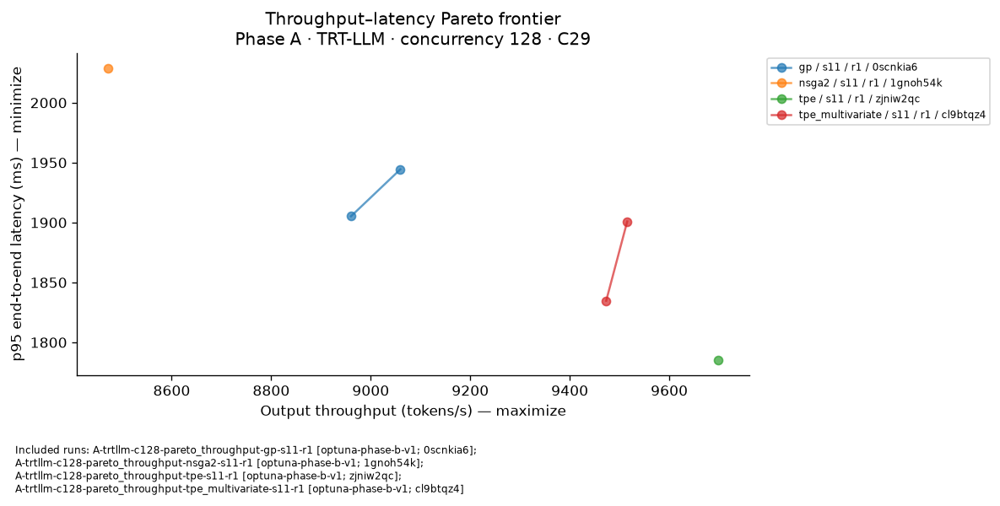

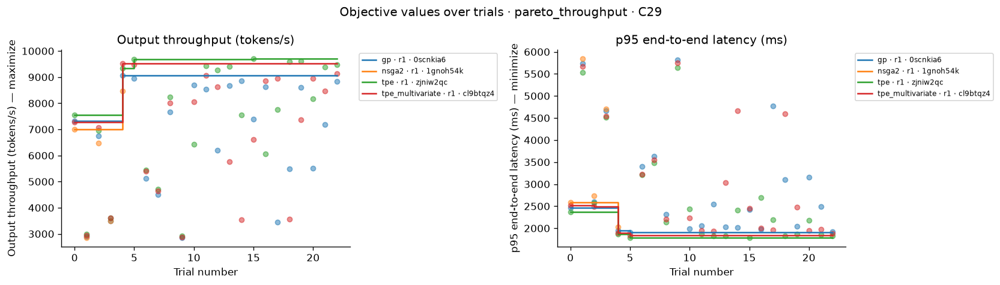

### SGLang · qwen3.5-4b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3.5-4b,sglang,e2e,l010bsj9,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,1,chunked_prefill_size,0.4658097831324914
qwen3.5-4b,sglang,e2e,l010bsj9,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,2,max_running_requests,0.3274004179097374
qwen3.5-4b,sglang,e2e,l010bsj9,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-gp-s11-r1,gp,p95_e2e_latency_ms,3,mem_fraction_static,0.2067897989577711
qwen3.5-4b,sglang,e2e,g7myirzj,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,1,max_running_requests,0.7490769522114218
qwen3.5-4b,sglang,e2e,g7myirzj,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,2,chunked_prefill_size,0.2498459989854425
qwen3.5-4b,sglang,e2e,g7myirzj,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-grid-s11-r1,grid,p95_e2e_latency_ms,3,mem_fraction_static,0.00107704880313577
qwen3.5-4b,sglang,e2e,t9955t18,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,1,max_running_requests,0.700644597471714
qwen3.5-4b,sglang,e2e,t9955t18,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,2,chunked_prefill_size,0.2974693929824104
qwen3.5-4b,sglang,e2e,t9955t18,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-qmc-s11-r1,qmc,p95_e2e_latency_ms,3,mem_fraction_static,0.0018860095458756048
qwen3.5-4b,sglang,e2e,8jlxzlfd,local SQLite,Optuna PED-ANOVA,A-sglang-c128-e2e-random-s11-r1,random,p95_e2e_latency_ms,1,max_running_requests,0.6445212709977653


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attention_backend,15,0.017640,0.000902
1,e2e,p95_e2e_latency_ms,cache_policy,5,0.061249,0.000289
2,e2e,p95_e2e_latency_ms,chunked_prefill_size,21,0.270595,0.029213
3,e2e,p95_e2e_latency_ms,cuda_graph_backend_decode,14,0.023358,0.000364
4,e2e,p95_e2e_latency_ms,cuda_graph_backend_prefill,14,0.036544,0.003780
5,e2e,p95_e2e_latency_ms,disable_overlap_schedule,14,0.004411,0.000030
6,e2e,p95_e2e_latency_ms,disable_radix_cache,10,0.020323,0.000413
7,e2e,p95_e2e_latency_ms,enable_mixed_chunk,14,0.010314,0.000376
8,e2e,p95_e2e_latency_ms,graph_enabled,1,0.004181,NaN
9,e2e,p95_e2e_latency_ms,max_prefill_tokens,15,0.124133,0.009234


model_group,framework,run,wandb_id,status
qwen3.5-4b,sglang,B-sglang-c128-e2e-tpe-s11-r1,sd333o4y,p95_e2e_latency_ms: insufficient variation


Phase B / SGLang: 34 included runs; cutoff 5 minutes


**Runs included: 31.** Optimizer seeds: s11, seed unknown. Repeats: r1, r21, r22, r3, r8, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r1`
- `B-sglang-c128-e2e-gp-s11-r1-pruner-median`
- `B-sglang-c128-e2e-gp-s11-r2-pruner-median`
- `B-sglang-c128-e2e-gp-s11-r22`
- `B-sglang-c128-e2e-grid-s11-r3`
- `B-sglang-c128-e2e-tpe-s11-r1`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r22`
- `B-sglang-c128-e2e-tpe-s11-r8`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r22`
- `B-sglang-c128-pareto_throughput-gp-s11-r1`
- `B-sglang-c128-pareto_throughput-gp-s11-r21`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r1`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r1-pruner-median`
- `B-sglang-c128-throughput-gp-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r3`
- `B-sglang-c128-throughput-gp-s11-r4-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r21`
- `B-sglang-c128-throughput-tpe-s11-r3`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r3`

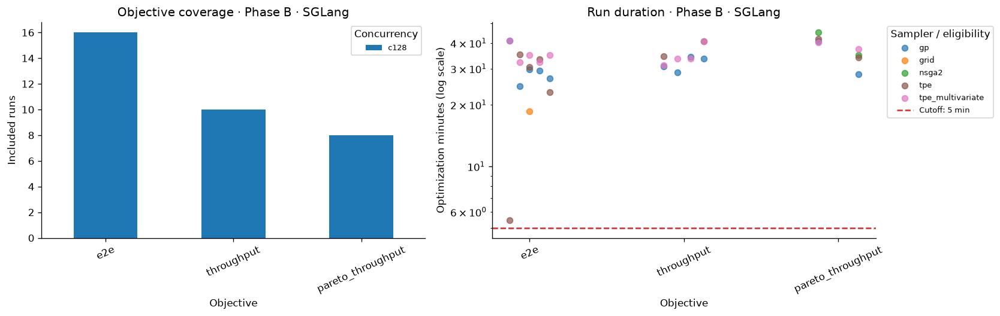

,state,trials
0,COMPLETE,479
1,FAIL,94
2,PRUNED,65


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 14.** Optimizer seeds: s11, seed unknown. Repeats: r1, r22, r3, r8, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r1`
- `B-sglang-c128-e2e-gp-s11-r1-pruner-median`
- `B-sglang-c128-e2e-gp-s11-r2-pruner-median`
- `B-sglang-c128-e2e-gp-s11-r22`
- `B-sglang-c128-e2e-grid-s11-r3`
- `B-sglang-c128-e2e-tpe-s11-r1`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r22`
- `B-sglang-c128-e2e-tpe-s11-r8`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r22`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-e2e-gp-s11-r1-pruner-median [optuna-phase-b-v1-pruning / az6q9eie],optuna-phase-b-v1-pruning,az6q9eie,e2e,C59,gp,24.58,attention_backend: fa3chunked_prefill_size: 20736cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 88mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: fcfs,11,4387.458979,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r1-pruner-median [sglang-phase-b-pruning-min400-v1 / iwgzm7d7],sglang-phase-b-pruning-min400-v1,iwgzm7d7,e2e,C44,gp,29.82,attention_backend: fa3cache_policy: cache_on__lpmchunked_prefill_size: 2560cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.75schedule_conservativeness: 0.5,2,4493.559910,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r1,optuna-phase-b-v1,3q8960rp,e2e,C57,gp,41.14,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,5395.039771,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r2-pruner-median,optuna-phase-b-v1-pruning,dh2xj09q,e2e,C44,gp,29.34,attention_backend: fa3cache_policy: cache_on__lpmchunked_prefill_size: 2560cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.75schedule_conservativeness: 0.5,2,4818.733024,False,all local COMPLETE trials
B-sglang-c128-e2e-gp-s11-r22,optuna-phase-b-v1,b9tye6iv,e2e,C58,gp,26.94,attention_backend: flashinferchunked_prefill_size: 22016cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 24576max_running_requests: 80mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: lpm,5,4632.404322,False,all local COMPLETE trials
B-sglang-c128-e2e-grid-s11-r3,optuna-phase-b-v1,9zaa26sm,e2e,C57,grid,18.53,attention_backend: fa3chunked_prefill_size: 8192disable_radix_cache: Falsegraph_enabled: Falsemax_prefill_tokens: 16384max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 1.0schedule_policy: lpm,1,16458.152183,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r1-pruner-median,optuna-phase-b-v1-pruning,1be65s71,e2e,C59,tpe,35.18,attention_backend: flashinferchunked_prefill_size: 22016cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 24576max_running_requests: 80mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: lpm,5,4642.936067,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,sd333o4y,e2e,C57,tpe,5.47,attention_backend: tritonchunked_prefill_size: 6144disable_radix_cache: Truegraph_enabled: Falsemax_prefill_tokens: 32768max_running_requests: 24mem_fraction_static: 0.8schedule_conservativeness: 1.5schedule_policy: lpm,0,19964.462329,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r2-pruner-median,optuna-phase-b-v1-pruning,lm080z0t,e2e,C44,tpe,30.65,attention_backend: fa3cache_policy: cache_on__lpmchunked_prefill_size: 2560cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 80me

##### Matching context C44

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"PLACEHOLDER_GPU"` · **gpu count:** `1` · **model revision:** `"PLACEHOLDER_MODEL_REVISION"` · **cuda version:** `"PLACEHOLDER_CUDA_VERSION"` · **driver version:** `"PLACEHOLDER_DRIVER_VERSION"`

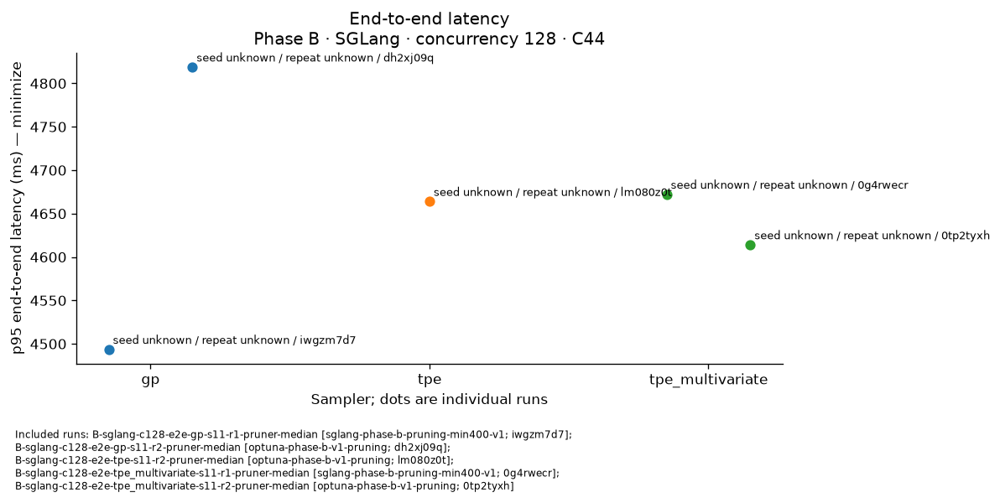

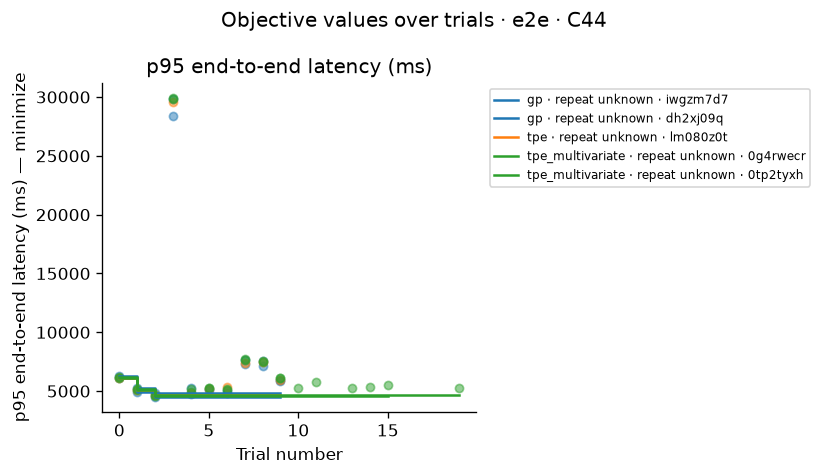

##### Matching context C57

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

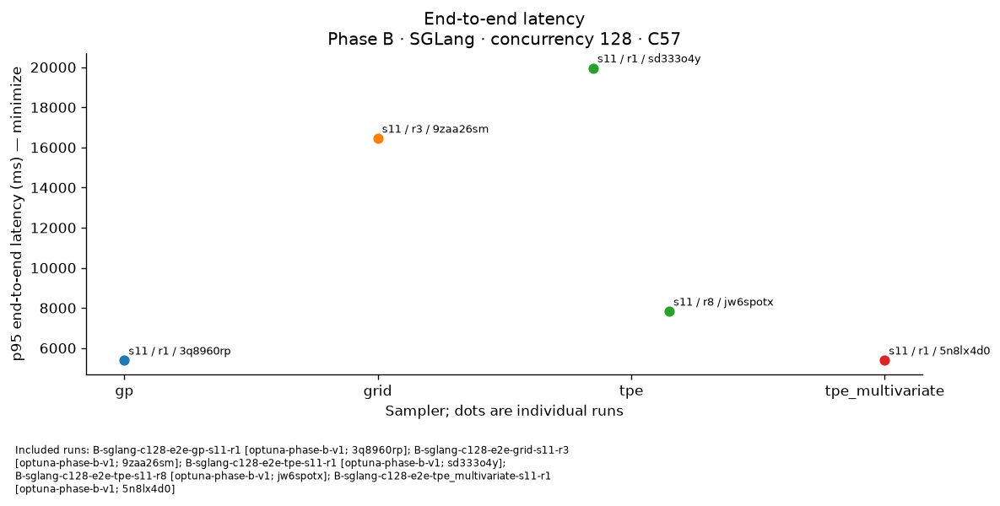

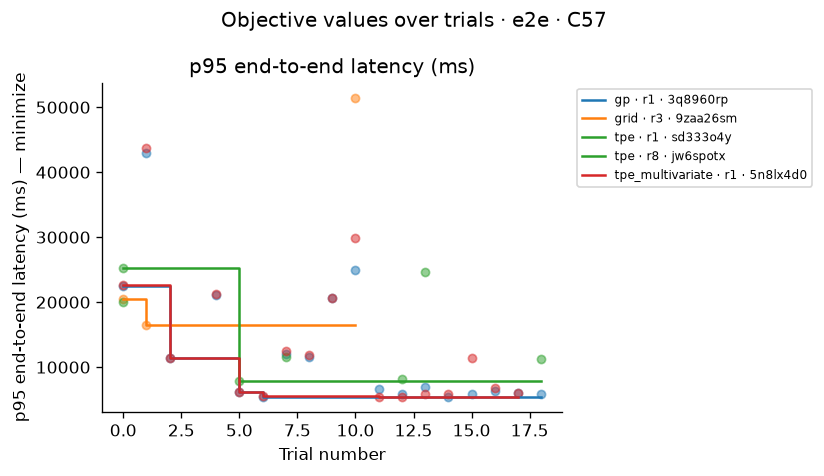

##### Matching context C58

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

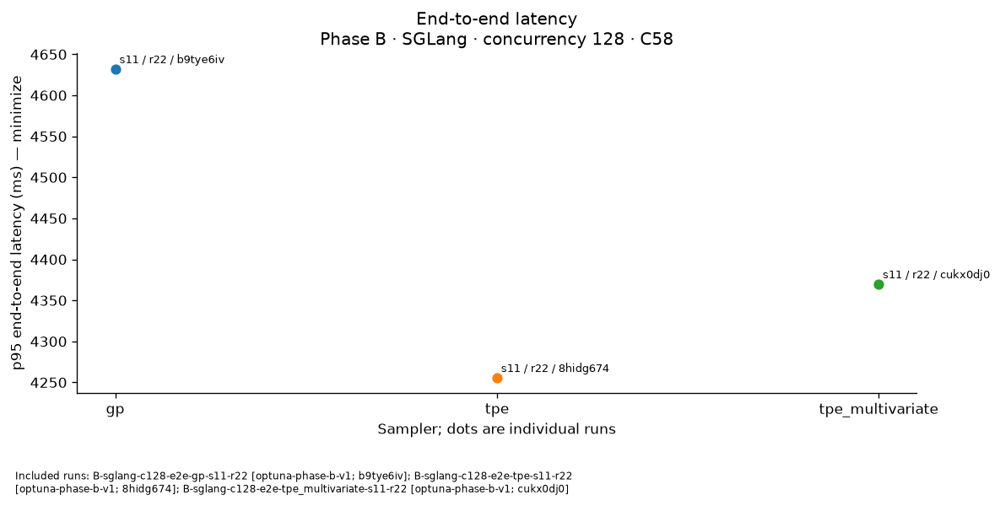

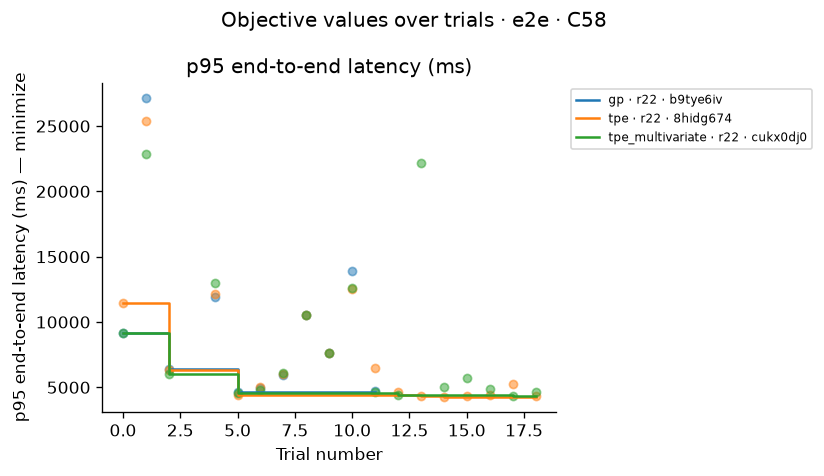

##### Matching context C59

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

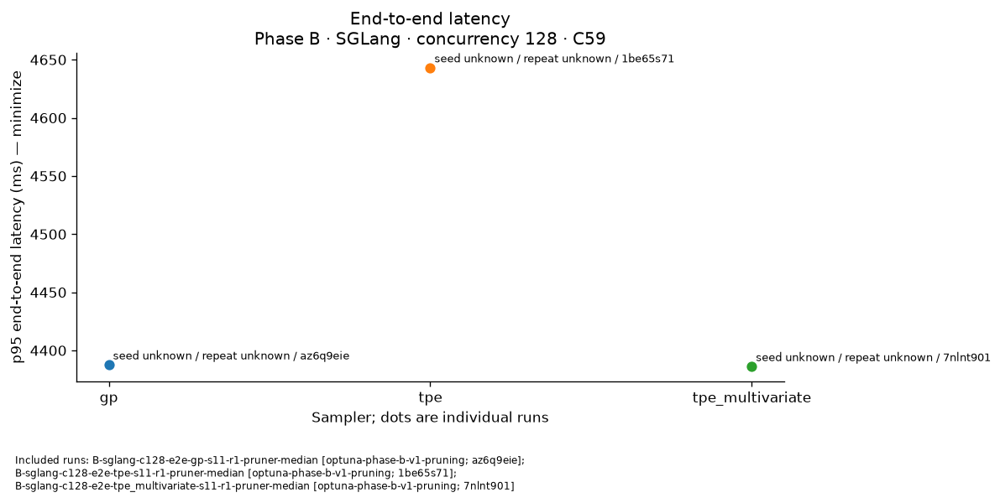

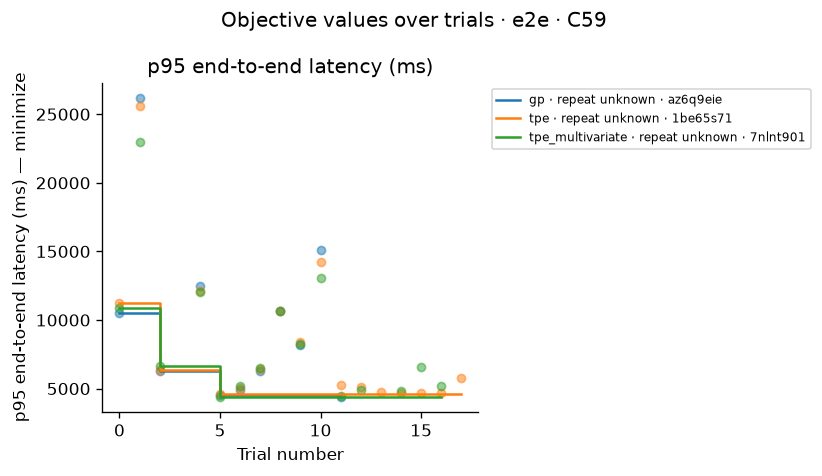

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 9.** Optimizer seeds: s11, seed unknown. Repeats: r21, r3, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-gp-s11-r1-pruner-median`
- `B-sglang-c128-throughput-gp-s11-r21`
- `B-sglang-c128-throughput-gp-s11-r3`
- `B-sglang-c128-throughput-gp-s11-r4-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r21`
- `B-sglang-c128-throughput-tpe-s11-r3`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r21`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-sglang-c128-throughput-gp-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,x381rhpe,throughput,C43,gp,30.68,attention_backend: fa3cache_policy: cache_off__lpmchunked_prefill_size: 11520cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.5,5,5571.583010,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-r21,optuna-phase-b-v1,97y1fl5s,throughput,C50,gp,28.74,attention_backend: fa3chunked_prefill_size: 19712cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: fcfs,11,6243.542049,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-r3,optuna-phase-b-v1,4n071923,throughput,C49,gp,34.19,attention_backend: fa3chunked_prefill_size: 6144cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: lpm,12,3860.950269,False,all local COMPLETE trials
B-sglang-c128-throughput-gp-s11-r4-pruner-median,optuna-phase-b-v1-pruning,4n5btch1,throughput,C51,gp,33.59,attention_backend: flashinferchunked_prefill_size: 32768cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: fcfs,18,6254.560764,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r21,optuna-phase-b-v1,tz0bzitz,throughput,C50,tpe,34.40,attention_backend: tritonchunked_prefill_size: 32512cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: fcfs,13,6323.834874,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r3,optuna-phase-b-v1,h313kk2n,throughput,C49,tpe,40.90,attention_backend: tritonchunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,13,3861.071881,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median [sglang-phase-b-pruning-min400-v1 / qe2hztdf],sglang-phase-b-pruning-min400-v1,qe2hztdf,throughput,C43,tpe_multivariate,31.13,attention_backend: fa3cache_policy: cache_off__lpmchunked_prefill_size: 11520cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.5,5,5685.382090,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median [optuna-phase-b-v1-pruning / scwr7hze],optuna-phase-b-v1-pruning,scwr7hze,throughput,C51,tpe_multivariate,33.52,attention_backend: fa3chunked_prefill_size: 14080cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 120mem_fraction_sta

##### Matching context C43

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"PLACEHOLDER_GPU"` · **gpu count:** `1` · **model revision:** `"PLACEHOLDER_MODEL_REVISION"` · **cuda version:** `"PLACEHOLDER_CUDA_VERSION"` · **driver version:** `"PLACEHOLDER_DRIVER_VERSION"`

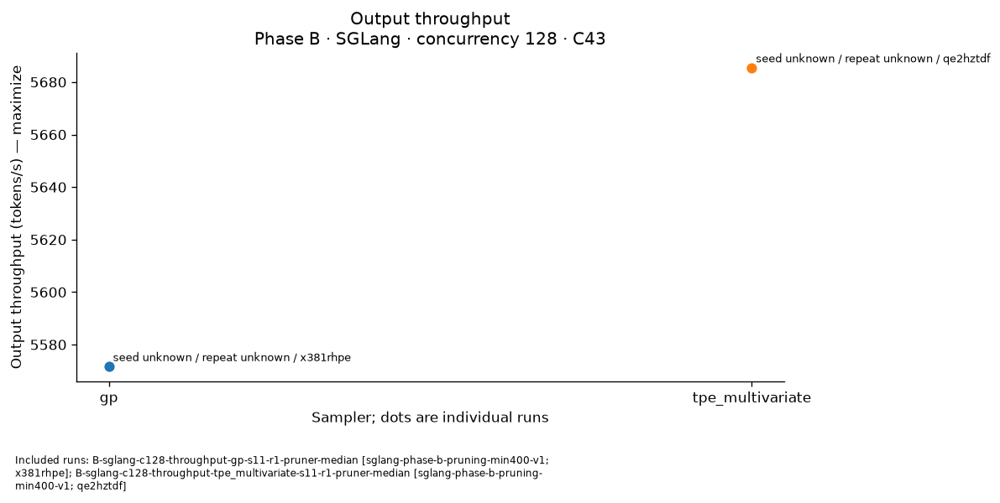

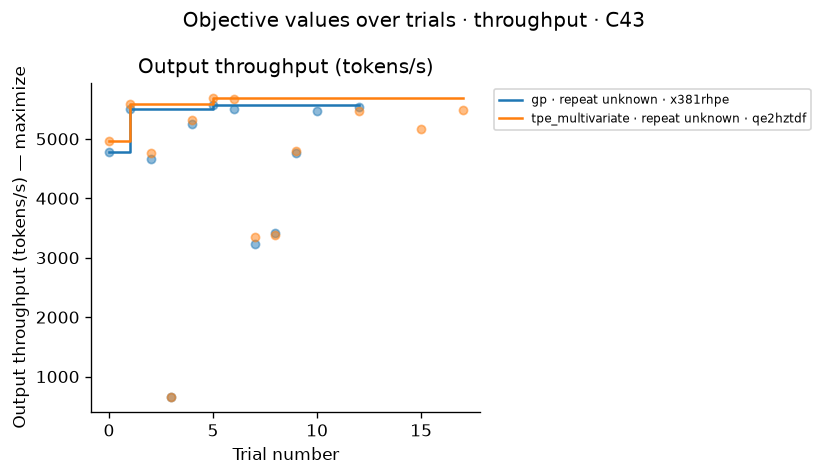

##### Matching context C49

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

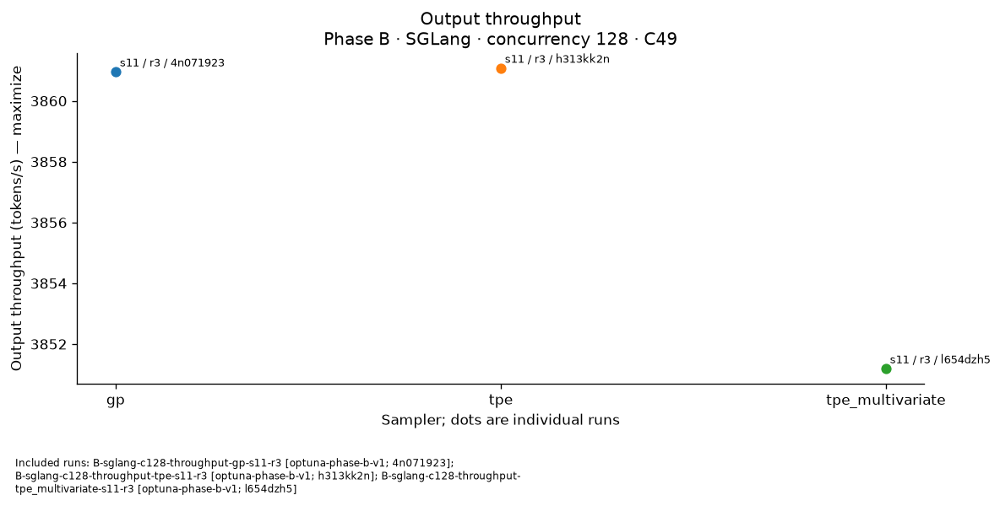

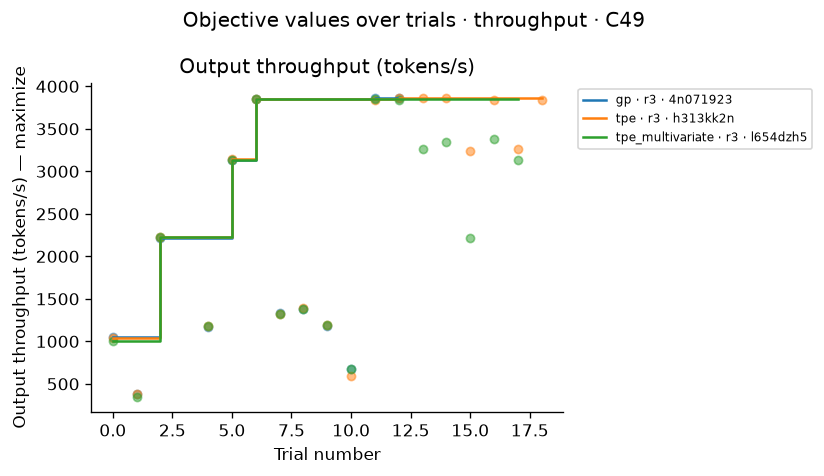

##### Matching context C50

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

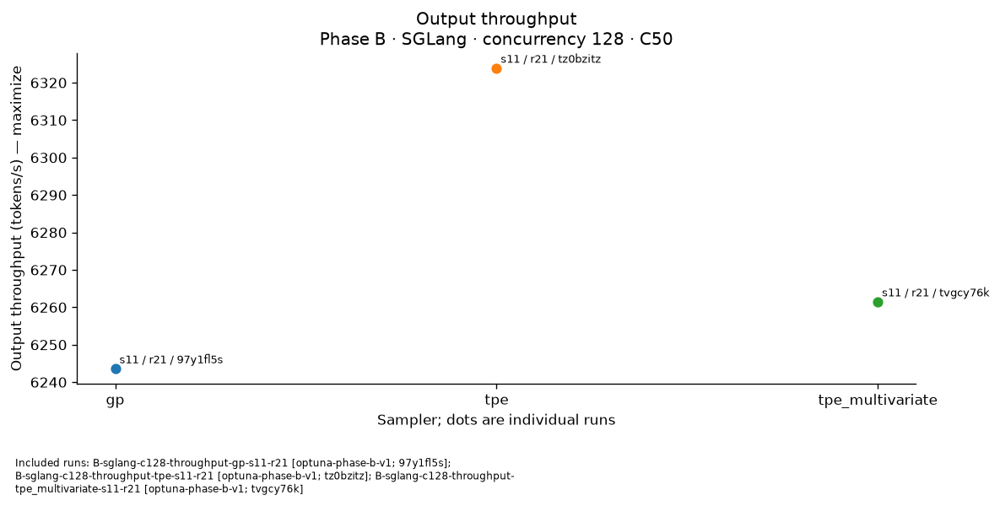

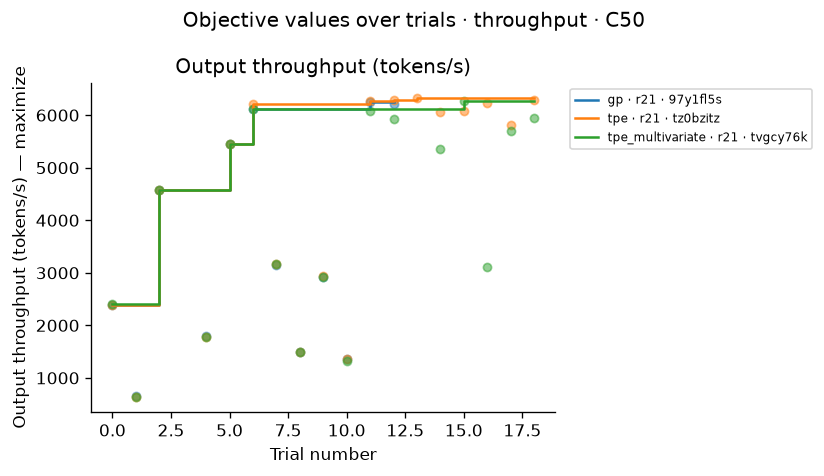

##### Matching context C51

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

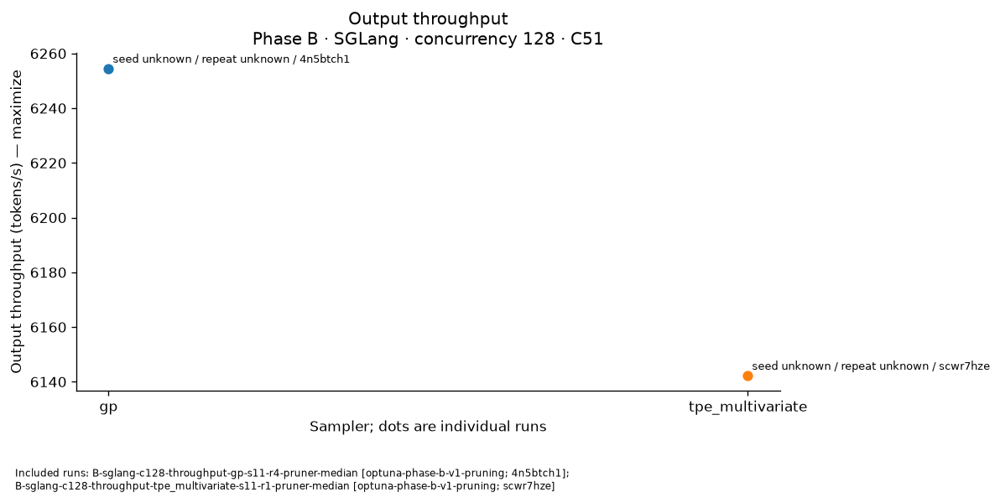

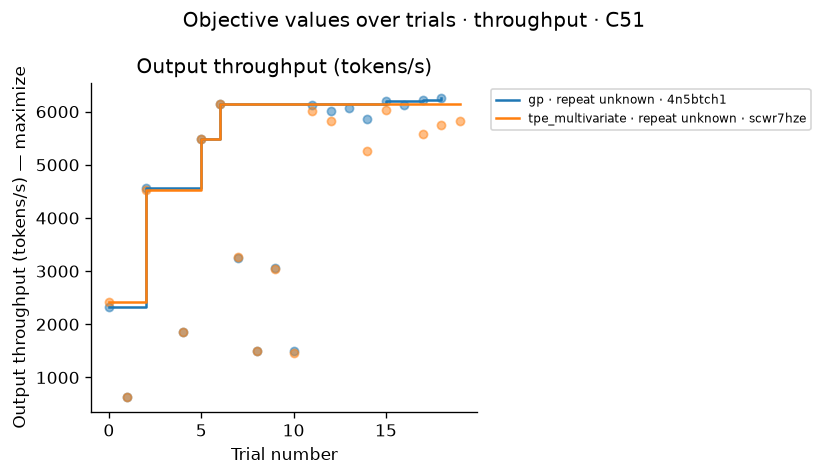

##### Throughput–latency Pareto frontier (`pareto_throughput`)

Maximize output throughput (tokens/s) and minimize p95 end-to-end latency (ms)

**Runs included: 8.** Optimizer seeds: s11. Repeats: r1, r21.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-pareto_throughput-gp-s11-r1`
- `B-sglang-c128-pareto_throughput-gp-s11-r21`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r1`
- `B-sglang-c128-pareto_throughput-nsga2-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe-s11-r21`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r1`
- `B-sglang-c128-pareto_throughput-tpe_multivariate-s11-r21`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,ugshe19v,pareto_throughput,C45,gp,40.88,attention_backend: tritonchunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: fcfs,17,3860.544160,5377.993359,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-gp-s11-r1,optuna-phase-b-v1,ugshe19v,pareto_throughput,C45,gp,40.88,attention_backend: fa3chunked_prefill_size: 8192cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: fcfs,18,3878.047210,5384.490891,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-gp-s11-r21,optuna-phase-b-v1,zqizg1uy,pareto_throughput,C46,gp,28.10,attention_backend: flashinferchunked_prefill_size: 22016cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 24576max_running_requests: 80mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: lpm,5,5478.962124,4594.730372,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-gp-s11-r21,optuna-phase-b-v1,zqizg1uy,pareto_throughput,C46,gp,28.10,attention_backend: fa3chunked_prefill_size: 16896cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 120mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: fcfs,11,6166.895851,4966.478776,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-nsga2-s11-r1,optuna-phase-b-v1,h2m48aoo,pareto_throughput,C45,nsga2,45.25,attention_backend: fa3chunked_prefill_size: 4096cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 32mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,3846.076633,5432.923475,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-nsga2-s11-r21,optuna-phase-b-v1,2qloi9hn,pareto_throughput,C46,nsga2,34.93,attention_backend: fa3chunked_prefill_size: 14080cuda_graph_backend_decode: tc_piecewisecuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 120mem_fraction_static: 0.75schedule_conservativeness: 0.75schedule_policy: fcfs,6,6090.003058,5366.974154,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-nsga2-s11-r21,optuna-phase-b-v1,2qloi9hn,pareto_throughput,C46,nsga2,34.93,attention_backend: fa3chunked_prefill_size: 14336cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Falsedisable_radix_cache: Trueenable_mixed_chunk: Truemax_prefill_tokens: 24576max_running_requests: 80mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.25schedule_policy: lpm,12,5473.304543,4585.136944,False,all local COMPLETE trials
B-sglang-c128-pareto_throughput-nsga2-s11-r21,optuna-phase-b-v1,2qloi9hn,pareto_throughput,C46,nsga2,34.93,attention_backend: fa3chunked_prefill_size: 14080cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 120mem_fraction_static: 0.75schedul

##### Matching context C45

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 896, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

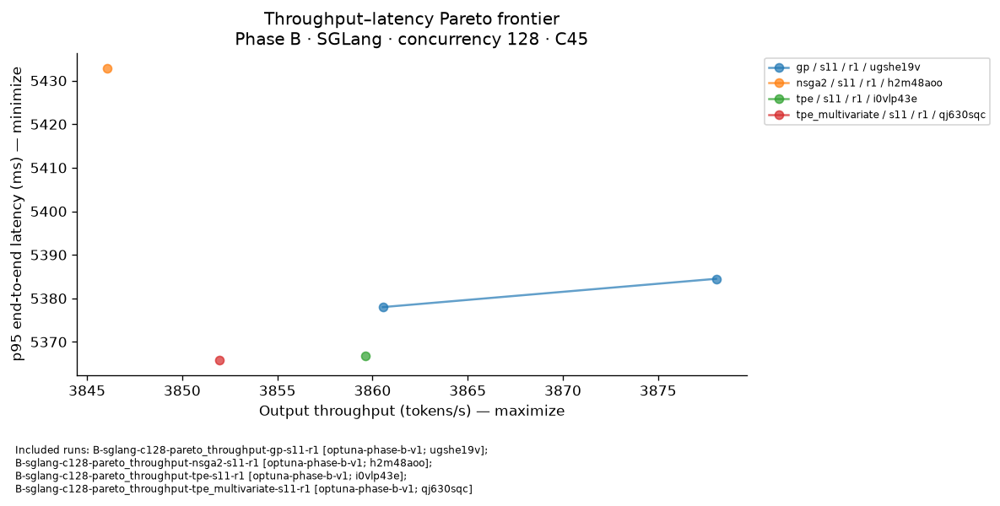

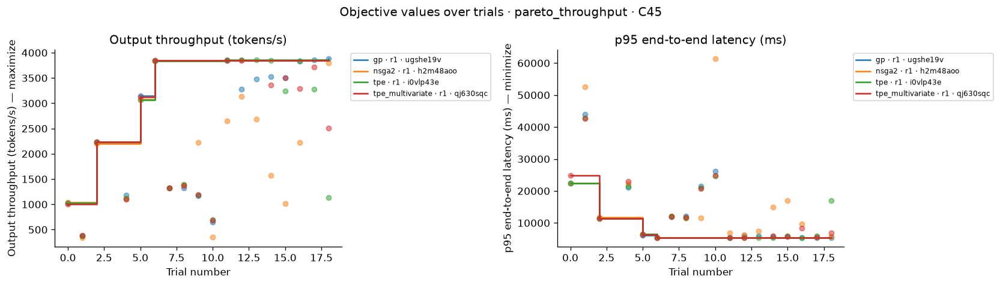

##### Matching context C46

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_B_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

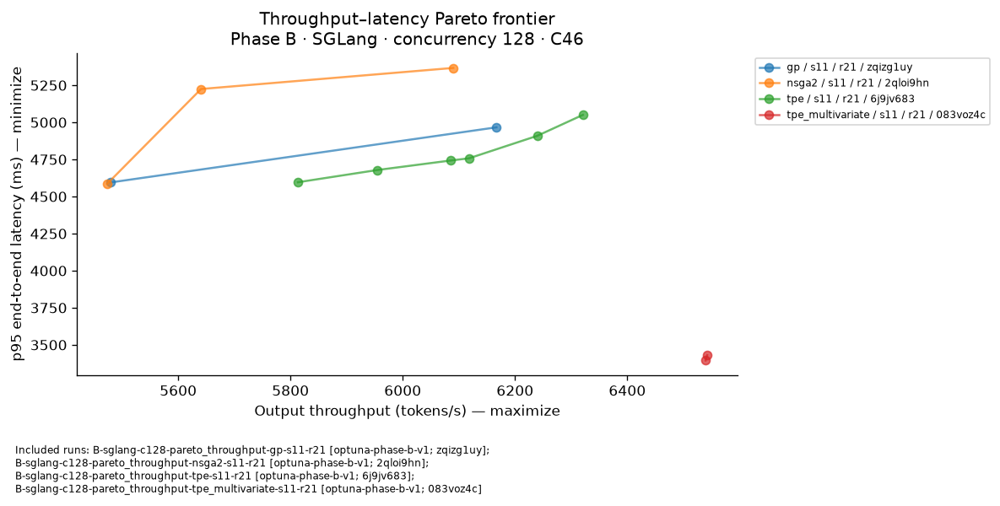

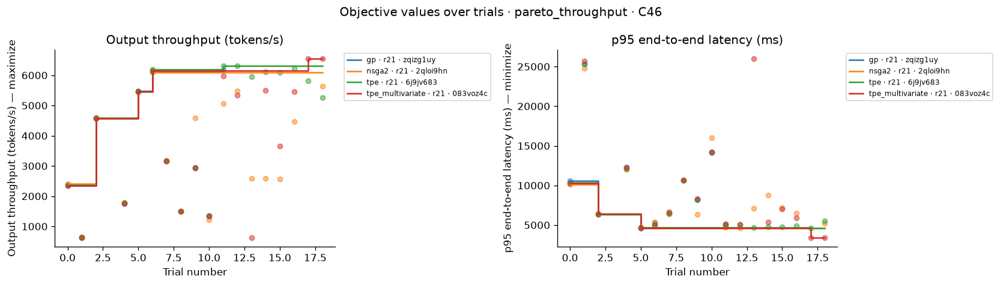

Phase A / SGLang: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-sglang-c128-e2e-gp-s11-r1`
- `A-sglang-c128-e2e-grid-s11-r1`
- `A-sglang-c128-e2e-qmc-s11-r1`
- `A-sglang-c128-e2e-random-s11-r1`
- `A-sglang-c128-e2e-tpe-s11-r1`
- `A-sglang-c128-e2e-tpe_multivariate-s11-r1`

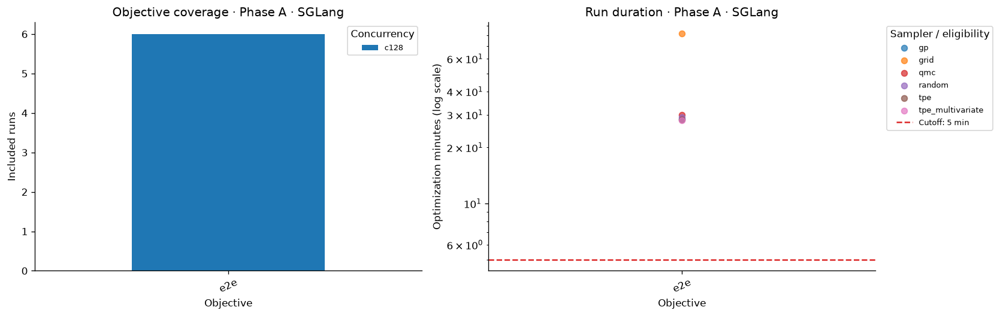

,state,trials
0,COMPLETE,184


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase A · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: s11. Repeats: r1.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `A-sglang-c128-e2e-gp-s11-r1`
- `A-sglang-c128-e2e-grid-s11-r1`
- `A-sglang-c128-e2e-qmc-s11-r1`
- `A-sglang-c128-e2e-random-s11-r1`
- `A-sglang-c128-e2e-tpe-s11-r1`
- `A-sglang-c128-e2e-tpe_multivariate-s11-r1`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
A-sglang-c128-e2e-gp-s11-r1,optuna-phase-b-v1,l010bsj9,e2e,C56,gp,28.48,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.8,18,1602.007511,False,all local COMPLETE trials
A-sglang-c128-e2e-grid-s11-r1,optuna-phase-b-v1,g7myirzj,e2e,C56,grid,81.89,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,38,1623.698405,False,all local COMPLETE trials
A-sglang-c128-e2e-qmc-s11-r1,optuna-phase-b-v1,t9955t18,e2e,C56,qmc,29.83,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,18,1613.971431,False,all local COMPLETE trials
A-sglang-c128-e2e-random-s11-r1,optuna-phase-b-v1,8jlxzlfd,e2e,C56,random,29.11,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,5,1616.353535,False,all local COMPLETE trials
A-sglang-c128-e2e-tpe-s11-r1,optuna-phase-b-v1,f0b03wlc,e2e,C56,tpe,28.23,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,11,1612.223303,False,all local COMPLETE trials
A-sglang-c128-e2e-tpe_multivariate-s11-r1,optuna-phase-b-v1,ieltqkx2,e2e,C56,tpe_multivariate,28.09,chunked_prefill_size: 8192max_running_requests: 32mem_fraction_static: 0.7,5,1610.241877,False,all local COMPLETE trials


##### Matching context C56

**Matched workload and environment**

**model:** `"qwen3.5-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 384, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100"` · **gpu count:** `1` · **model revision:** `"REPLACE_WITH_PHASE_A_MODEL_COMMIT"` · **cuda version:** `"REPLACE_WITH_CUDA_VERSION"` · **driver version:** `"REPLACE_WITH_DRIVER_VERSION"`

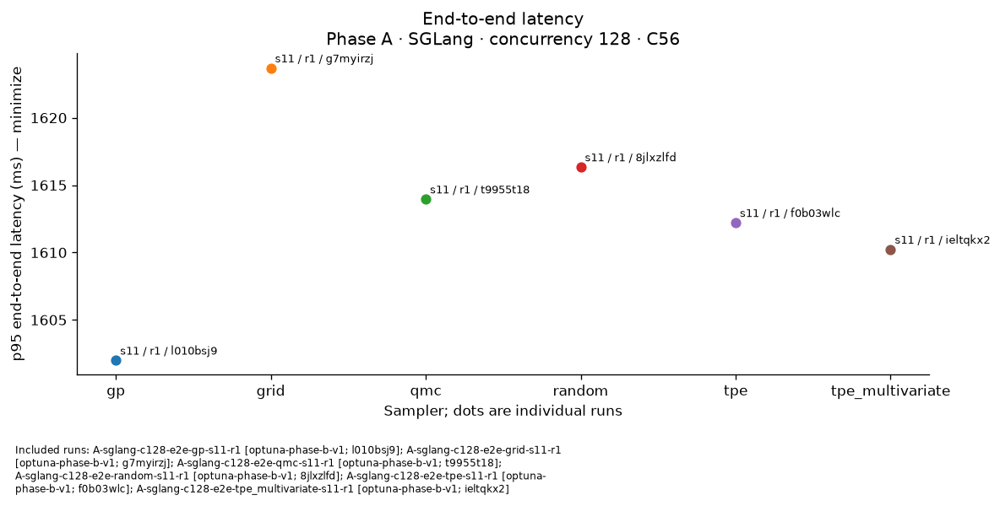

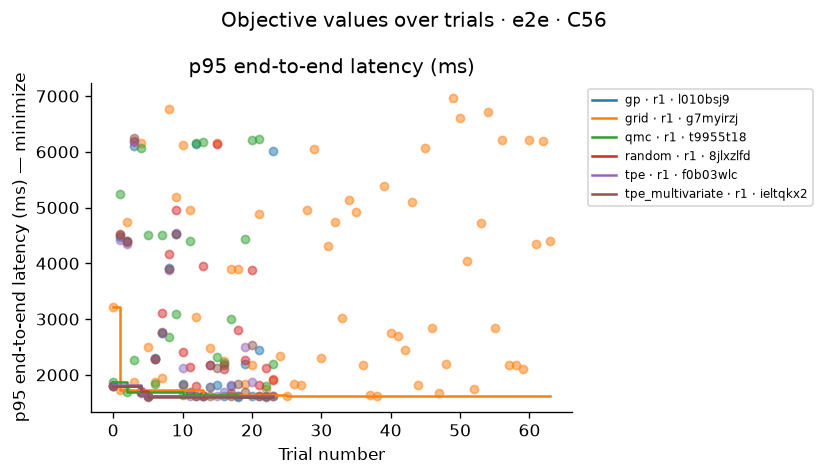

In [34]:
show_model("qwen3.5-4b")


## qwen3-4b


### Summary of the results:

In [35]:
show_framework_summary("qwen3-4b")


### Framework summaries · qwen3-4b

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C12,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r3-pruner-median,jv68gtxm,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/jv68gtxm,16,9366.669433761568,—,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: truegpu_memory_utilization: 0.8graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: ""balanced""",all W&B COMPLETE trials
e2e,C25,B,128,B-vllm-c128-e2e-gp-s11-r4-pruner-median,h7souawk,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/h7souawk,10,—,1921.049086649782,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: falsegpu_memory_utilization: 0.8graph_capture_profile: ""powers""graph_mode: ""PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 23040max_num_seqs: 128performance_mode: ""interactivity""",all W&B COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (11 outputs left out)

**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

,target,metric,coverage,n,runs,mean,variance
0,e2e,p95_e2e_latency_ms,full trial history,67,5,5794.458861,1.386764e+07
1,throughput,output_throughput,full trial history,60,3,5194.185062,2.791831e+06


**Startup, model loading and serving timings** (seconds; variance in seconds²)

,timing,phase_status,n,mean_seconds,variance_seconds2
0,benchmark,complete,127,31.919179,477.684659
1,client_preparation,complete,136,1.075548,0.007759
2,launch_to_ready,complete,136,63.263497,1630.690588
3,warmup,complete,136,0.334593,0.042573


### Per-Trial behavior:

### qwen3-4b · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,4555.999032,28140.096512,3,3
1,B,128,throughput,1,6120.316248,4961.996478,3,3
2,B,128,throughput,2,5273.860690,28833.124186,3,3
3,B,128,throughput,3,5990.408714,22282.016666,3,3
4,B,128,throughput,4,4592.073026,3344.230461,3,3
5,B,128,throughput,5,7668.678927,724.590301,3,3
6,B,128,throughput,6,4109.320726,7311.674191,3,3
7,B,128,throughput,7,1991.023939,6174.968167,3,3
8,B,128,throughput,8,7511.938704,10554.444094,3,3
9,B,128,throughput,9,5962.693574,14012.683237,3,3


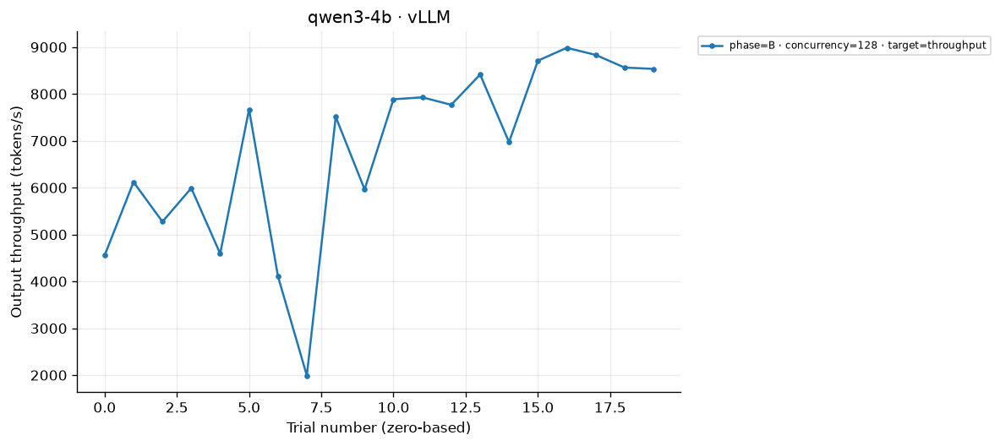

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,4154.044255,13053.132380,3,3
1,B,128,e2e,1,3377.757878,33780.738690,3,3
2,B,128,e2e,2,3150.286820,8397.446252,3,3
3,B,128,e2e,3,3451.833895,1792.129454,3,3
4,B,128,e2e,4,3959.204858,2870.733269,3,3
5,B,128,e2e,5,2998.183712,353.722477,3,3
6,B,128,e2e,6,5165.473611,22051.132476,3,3
7,B,128,e2e,7,9388.518064,80019.061809,3,3
8,B,128,e2e,8,3383.226762,772.836683,3,3
9,B,128,e2e,9,4015.396562,16725.512728,3,3


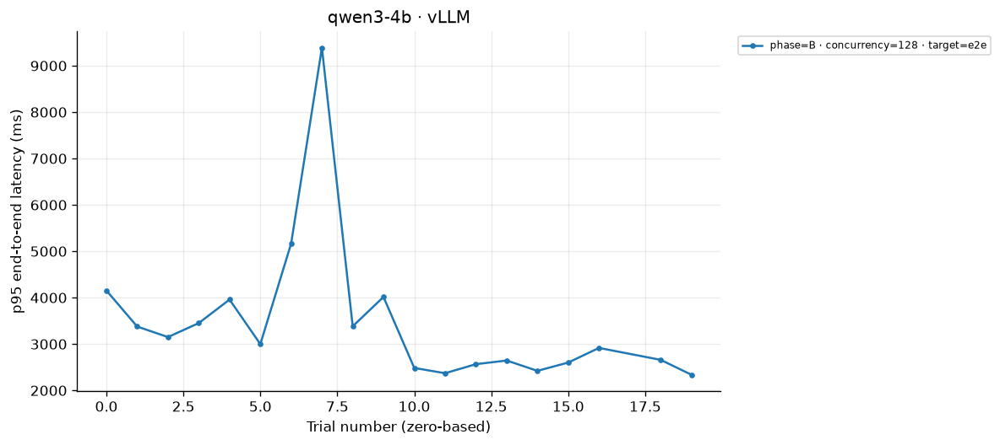

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [36]:
mean_by_trial_number("qwen3-4b", "vllm")


### qwen3-4b · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,5459.281498,2.386073e+03,3,3
1,B,128,throughput,1,6201.379101,4.243313e+03,3,3
2,B,128,throughput,2,4459.735643,1.849210e+02,3,3
3,B,128,throughput,3,4357.944681,2.738197e+04,3,3
4,B,128,throughput,4,5542.174001,8.495500e+02,3,3
5,B,128,throughput,5,2272.553500,1.195571e+04,3,3
6,B,128,throughput,6,2012.953946,1.618088e+04,3,3
7,B,128,throughput,7,3542.713141,4.575638e+03,3,3
8,B,128,throughput,8,3749.315639,1.856395e+03,3,3
9,B,128,throughput,9,3243.801650,1.639935e+04,3,3


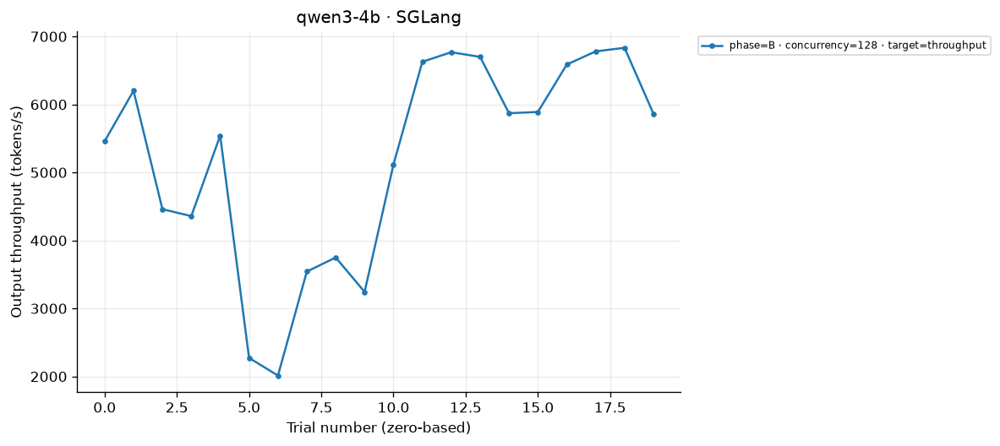

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,4873.543082,9.579598e+02,3,3
1,B,128,e2e,1,3901.554995,1.796663e+04,5,5
2,B,128,e2e,2,7628.343485,1.447930e+07,5,5
3,B,128,e2e,3,10792.109851,9.618258e+07,5,5
4,B,128,e2e,4,3263.377375,9.095087e+03,3,3
5,B,128,e2e,5,8640.906636,2.842586e+04,3,3
6,B,128,e2e,6,8954.405087,6.026178e+04,3,3
7,B,128,e2e,7,6595.824065,2.458710e+04,3,3
8,B,128,e2e,8,5239.647931,1.847669e+06,5,5
9,B,128,e2e,9,9708.714740,4.572467e+04,3,3


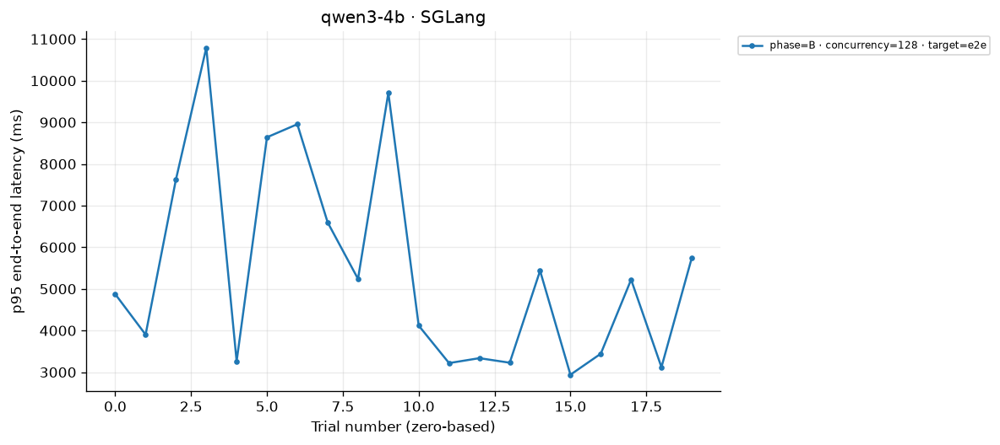

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,61.018414,6.608841e-07,3,3
1,B,128,e2e,1,39.014564,7.508244e+00,5,5
2,B,128,e2e,2,36.014860,2.503187e+01,5,5
3,B,128,e2e,3,46.016298,6.426172e-06,5,5
4,B,128,e2e,4,76.021850,1.980852e-06,3,3
5,B,128,e2e,5,46.015476,2.129968e-06,3,3
6,B,128,e2e,6,31.011700,9.410881e-09,3,3
7,B,128,e2e,7,132.702760,8.337700e+00,3,3
8,B,128,e2e,8,31.012666,1.692697e-06,5,5
9,B,128,e2e,9,121.033843,5.946943e-06,3,3


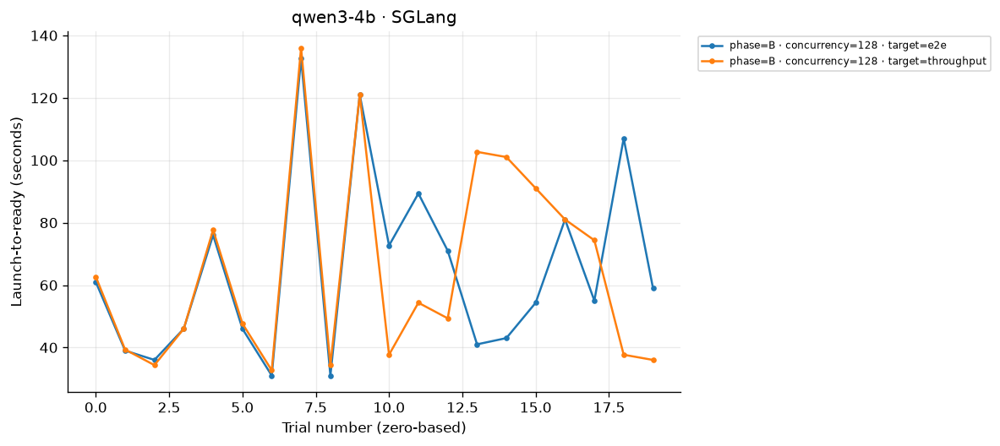

In [37]:
mean_by_trial_number("qwen3-4b", "sglang")


### qwen3-4b · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,6427.289377,2.166830e+03,6,6
1,B,128,throughput,1,2377.166271,1.463771e+02,6,6
2,B,128,throughput,2,2382.576996,2.111077e+02,6,6
3,B,128,throughput,3,3699.601362,5.987445e+03,5,5
4,B,128,throughput,4,5899.013870,5.613869e+03,5,5
5,B,128,throughput,5,7314.671662,1.510833e+04,5,5
6,B,128,throughput,6,370.344592,1.026826e+01,5,5
7,B,128,throughput,7,3861.280762,1.462239e+03,5,5
8,B,128,throughput,8,5004.671917,4.234985e+03,5,5
9,B,128,throughput,9,6849.840726,4.470464e+02,5,5


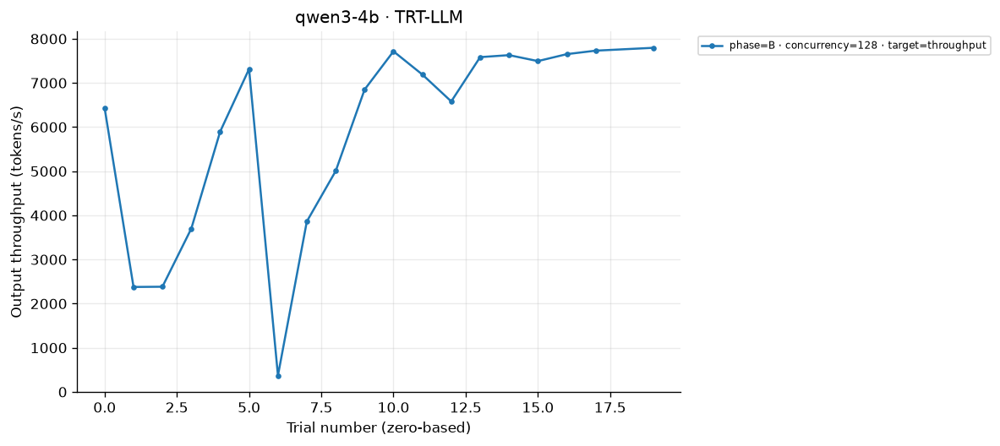

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,2902.376015,8.698742e+01,5,5
1,B,128,e2e,1,8554.666994,1.779072e+07,6,6
2,B,128,e2e,2,6791.598208,5.670599e+01,6,6
3,B,128,e2e,3,6207.558229,1.066945e+05,5,5
4,B,128,e2e,4,3759.161741,1.759338e+06,5,5
5,B,128,e2e,5,3238.505685,2.002005e+03,5,5
6,B,128,e2e,6,36401.235186,3.436960e+08,5,5
7,B,128,e2e,7,14106.906615,2.825747e+08,5,5
8,B,128,e2e,8,4187.920143,1.950488e+06,5,5
9,B,128,e2e,9,3189.784827,4.064926e+04,5,5


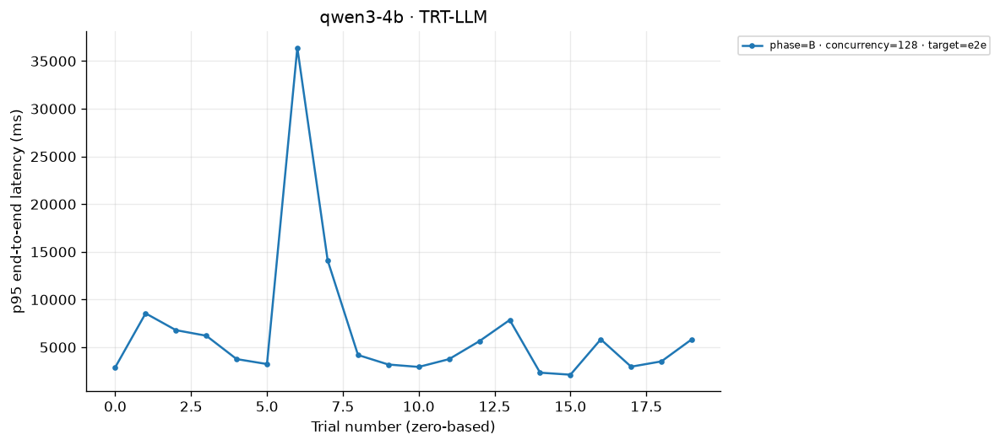

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [38]:
mean_by_trial_number("qwen3-4b", "trtllm")


### Overall results and plots:

**26 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3-4b,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-q3_4,B,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,38.47811984245,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,r45e9jku,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-e2e-gp-s11-r2-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-e2e-tpe-s11-r1-pruner-median-q3_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-median,23.627848501183355,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,xv9jj7p8,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/xv9jj7p8,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-e2e-tpe-s11-r1-pruner-median-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-e2e-tpe-s11-r2-pruner-median-q3_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-median,35.706138503049985,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,kr7exexf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/kr7exexf,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-e2e-tpe-s11-r2-pruner-median-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median-q3_4,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median,23.352337827550006,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,4bghcfvo,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/4bghcfvo,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median-q3_4,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median,38.12435232803333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,c728xfeg,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/c728xfeg,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-throughput-gp-s11-r2-pruner-nop-q3_4,B,sglang,B-sglang-c128-throughput-gp-s11-r2-pruner-nop,39.424497393233345,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,32rhe80b,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/32rhe80b,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-throughput-gp-s11-r2-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-throughput-tpe-s11-r1-pruner-nop-q3_4,B,sglang,B-sglang-c128-throughput-tpe-s11-r1-pruner-nop,40.101129306550014,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4/studies.sqlite3,gfcsn9dw,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/gfcsn9dw,finished,sglang-phase-b-pruning-qwen3_4,['experiment_results/sglang-phase-b-pruning-qwen3_4/B-sglang-c128-throughput-tpe-s11-r1-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b,B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop-q3_4,B,sglang,B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop,32.339848745149965,local optimization_w

### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
27,qwen3-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,sglang,67,5,5794.458861,1.386764e+07,phase/concurrency
28,qwen3-4b,B,throughput,128,full trial history,output_throughput,sglang,60,3,5194.185062,2.791831e+06,phase/concurrency
29,qwen3-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,82,6,7205.109086,9.873412e+07,phase/concurrency
30,qwen3-4b,B,throughput,128,full trial history,output_throughput,trtllm,82,6,5457.006929,5.282675e+06,phase/concurrency
31,qwen3-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,51,3,3581.737769,2.777132e+06,phase/concurrency
32,qwen3-4b,B,throughput,128,full trial history,output_throughput,vllm,59,3,6800.516072,3.744908e+06,phase/concurrency
66,qwen3-4b,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,200,14,5808.581575,4.755991e+07,phase/concurrency
67,qwen3-4b,B,throughput,128,full trial history,output_throughput,overall,201,12,5772.916021,4.502002e+06,phase/concurrency
97,qwen3-4b,all,e2e,all,full trial history,p95_e2e_latency_ms,sglang,67,5,5794.458861,1.386764e+07,model
98,qwen3-4b,all,throughput,all,full trial history,output_throughput,sglang,60,3,5194.185062,2.791831e+06,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

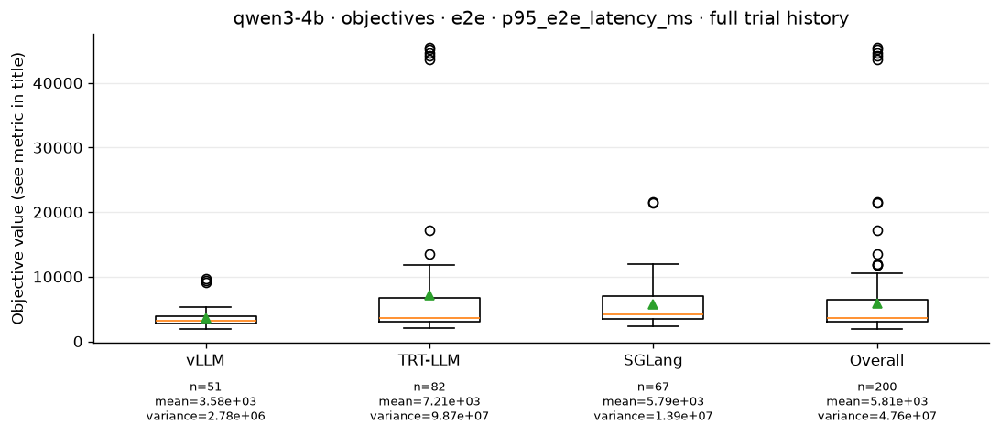

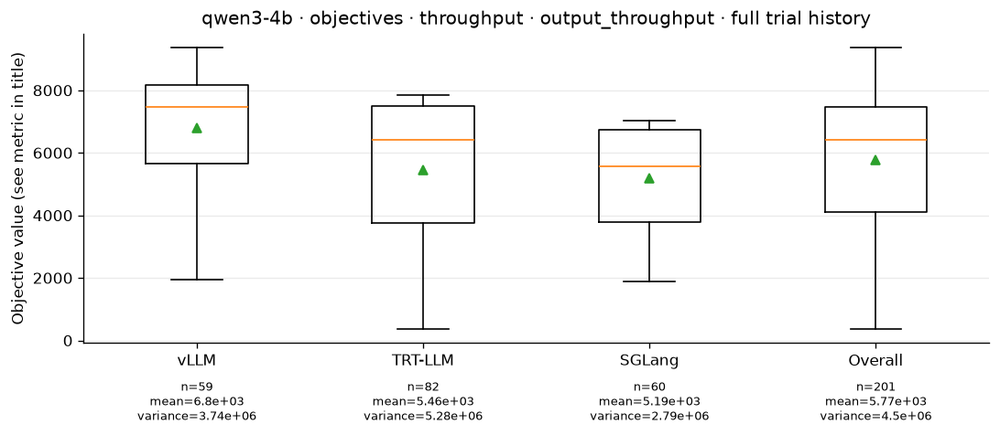

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3-4b,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-q3_4,r45e9jku,100,included
qwen3-4b,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-median-q3_4,xv9jj7p8,64,included
qwen3-4b,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-median-q3_4,kr7exexf,100,included
qwen3-4b,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median-q3_4,4bghcfvo,64,included
qwen3-4b,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median-q3_4,c728xfeg,100,included
qwen3-4b,sglang,B-sglang-c128-throughput-gp-s11-r2-pruner-nop-q3_4,32rhe80b,100,included
qwen3-4b,sglang,B-sglang-c128-throughput-tpe-s11-r1-pruner-nop-q3_4,gfcsn9dw,100,included
qwen3-4b,sglang,B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop-q3_4,1lhftlx2,100,included
qwen3-4b,trtllm,B-trtllm-c128-e2e-gp-s11-r1-pruner-median-q3_4,nsujtusb,0,included
qwen3-4b,trtllm,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop-q3_4,63ad2eo6,0,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope
11,qwen3-4b,B,launch_to_ready,complete,sglang,136,63.263497,1630.690588,phase
12,qwen3-4b,B,client_preparation,complete,sglang,136,1.075548,0.007759,phase
13,qwen3-4b,B,warmup,complete,sglang,136,0.334593,0.042573,phase
14,qwen3-4b,B,benchmark,complete,sglang,127,31.919179,477.684659,phase
49,qwen3-4b,B,launch_to_ready,complete,overall,136,63.263497,1630.690588,phase
50,qwen3-4b,B,client_preparation,complete,overall,136,1.075548,0.007759,phase
51,qwen3-4b,B,warmup,complete,overall,136,0.334593,0.042573,phase
52,qwen3-4b,B,benchmark,complete,overall,127,31.919179,477.684659,phase
82,qwen3-4b,all,launch_to_ready,complete,sglang,136,63.263497,1630.690588,model
83,qwen3-4b,all,client_preparation,complete,sglang,136,1.075548,0.007759,model


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

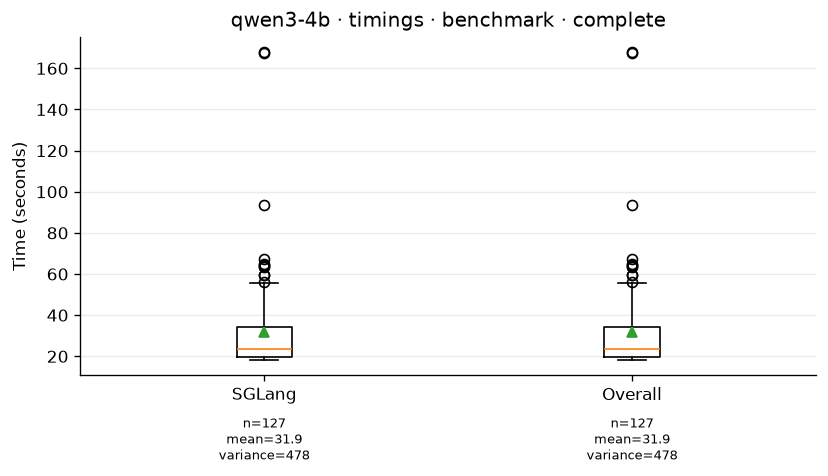

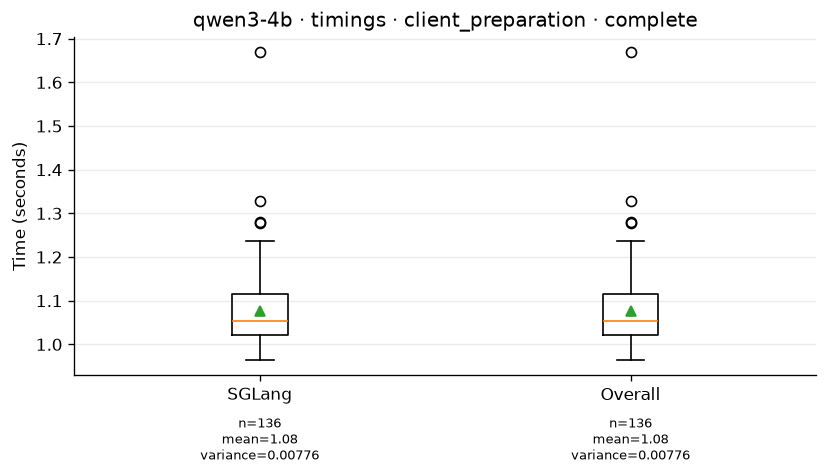

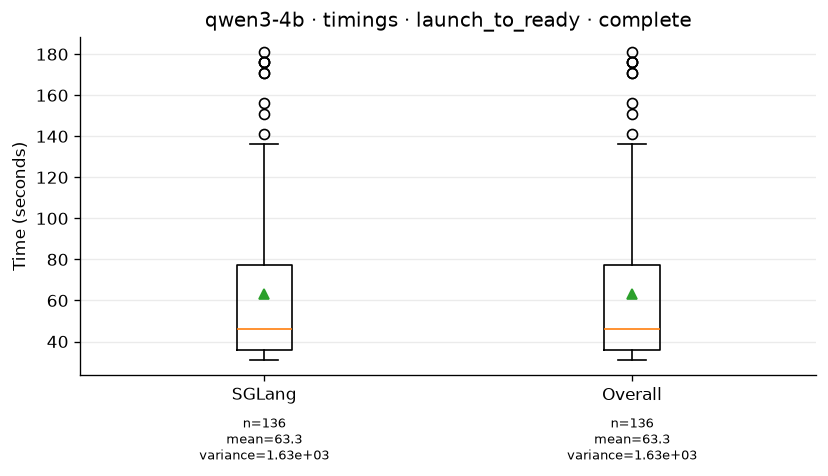

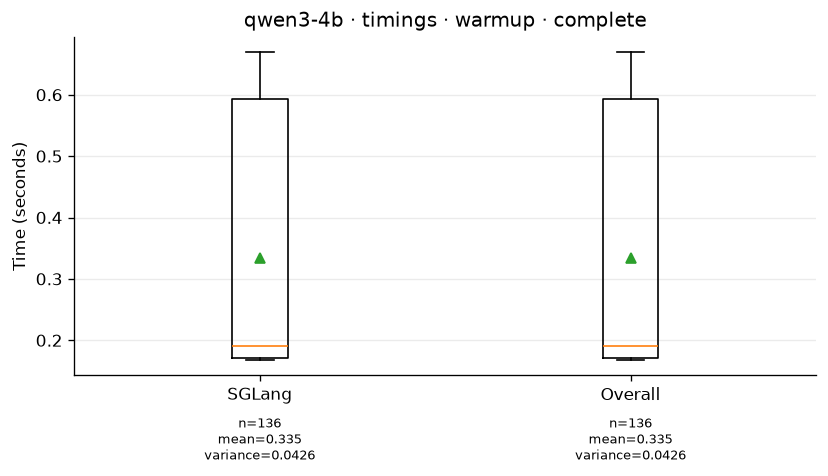

Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means.

model_group,framework,phase,study_name,wandb_id,trial,params,state,source,wandb_url,launch_to_ready (s),launch_to_ready status,client_preparation (s),client_preparation status,warmup (s),warmup status,benchmark (s),benchmark status,runner_wall (s),runner_wall status
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,0,"attention_backend: ""fa3""chunked_prefill_size: 16896cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 72mem_fraction_static: 0.8schedule_conservativeness: 1.5schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,61.0174918699995,complete,1.067019899001025,complete,0.1728105490001326,complete,23.431276653998793,complete,93.01529633099926,unknown
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,1,"attention_backend: ""fa3""chunked_prefill_size: 4352cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 96mem_fraction_static: 0.85schedule_conservativeness: 1.5schedule_policy: ""fcfs""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,41.01662806799868,complete,0.9973874429997522,complete,0.17125405199840316,complete,20.856423857003392,complete,69.72069157100123,unknown
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,2,"attention_backend: ""fa3""chunked_prefill_size: 4352cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 48mem_fraction_static: 0.7schedule_conservativeness: 1.0schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,31.011223538997,complete,1.0222833919979166,complete,0.19041309900057968,complete,28.51952175399856,complete,67.64233772499938,unknown
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,3,"attention_backend: ""fa3""chunked_prefill_size: 11776cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 1.5schedule_policy: ""fcfs""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,46.014309488000436,complete,1.1166157469997415,complete,0.599753744998452,complete,28.96246242200141,complete,83.74151280099977,unknown
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,4,"attention_backend: ""fa3""chunked_prefill_size: 20736cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 72mem_fraction_static: 0.75schedule_conservativeness: 1.25schedule_policy: ""fcfs""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/r45e9jku,76.02281209400098,complete,1.0240301140001975,complete,0.16963912400024128,complete,22.937761963999947,complete,106.64186311699814,unknown
qwen3-4b,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,r45e9jku,5,"attention_backend: ""fa3""chunked_prefill_size: 12288cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 24576max_running_requests: 56mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: ""fcfs""",COMPLETE,local SQLite,https://wandb.ai/maor

### vLLM · qwen3-4b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,1,max_num_seqs,0.7066660551992531
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,2,gpu_memory_utilization,0.17671962232332517
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,3,graph_mode,0.05524841188261043
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,4,kv_cache_dtype,0.022821971394008794
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,5,enable_prefix_caching,0.012392804554773285
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,6,async_scheduling,0.012392804554773285
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,7,max_num_batched_tokens,0.006400992859790284
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,8,attention_backend,0.004497605959736232
qwen3-4b,vllm,e2e,h7souawk,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r4-pruner-median,gp,p95_e2e_latency_ms,9,performance_mode,0.002859731271729388
qwen3-4b,vllm,e2e,54psl2sv,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r4-pruner-median,tpe,p95_e2e_latency_ms,1,max_num_seqs,0.864503739827879


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.007188,2.035037e-05
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.004248,4.796944e-08
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.006113,3.161181e-05
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.067225,9.084565e-03
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.023173,7.716508e-04
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.009741,1.308051e-04
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.169826,4.273035e-02
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.708361,2.411876e-02
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.004125,2.178736e-05
9,throughput,output_throughput,async_scheduling,3,0.029868,1.782394e-03


model_group,framework,run,wandb_id,status


Phase B / vLLM: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r4-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r4-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r3-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r3-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r3-pruner-median`

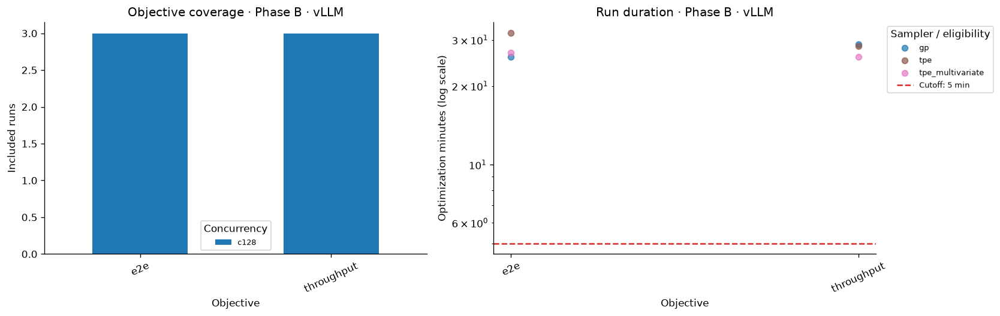

,state,trials
0,COMPLETE,110
1,PRUNED,10


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r4-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r4-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r4-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r4-pruner-median,sglang-phase-b-pruning-min400-v1,h7souawk,e2e,C25,gp,25.81,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 23040max_num_seqs: 128performance_mode: interactivity,10,1921.049087,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r4-pruner-median,sglang-phase-b-pruning-min400-v1,54psl2sv,e2e,C25,tpe,31.94,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: balanced,11,1932.259861,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r4-pruner-median,sglang-phase-b-pruning-min400-v1,msboxf9e,e2e,C25,tpe_multivariate,26.75,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 3072max_num_seqs: 72performance_mode: interactivity,19,2721.276374,False,all W&B COMPLETE trials


##### Matching context C25

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

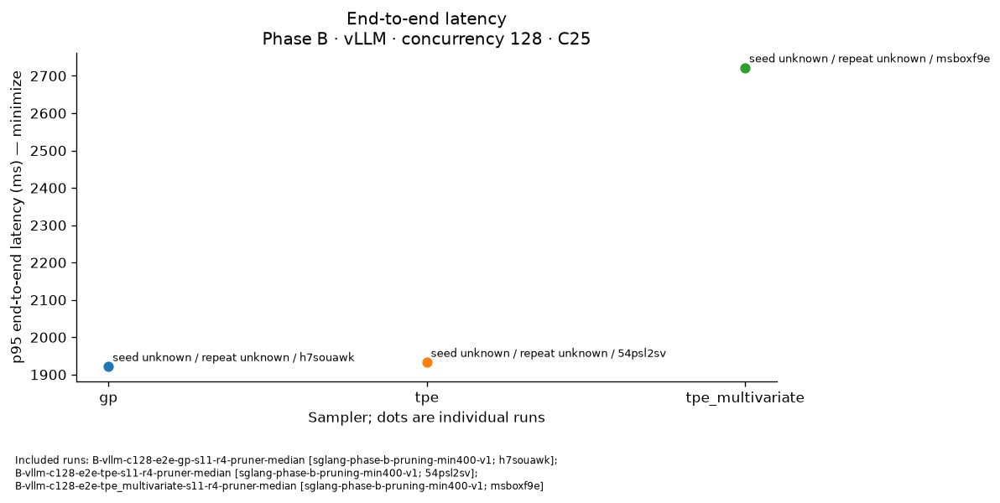

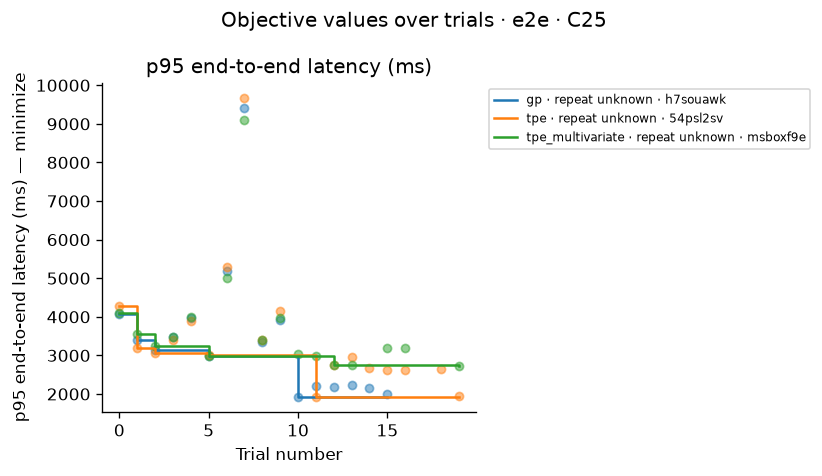

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r3-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r3-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r3-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,3y69qiid,throughput,C12,gp,28.82,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 6400max_num_seqs: 128performance_mode: balanced,19,9317.793083,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,298kdl0g,throughput,C12,tpe,28.43,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 23552max_num_seqs: 128performance_mode: throughput,19,8704.347079,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,jv68gtxm,throughput,C12,tpe_multivariate,25.81,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Truegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 26112max_num_seqs: 128performance_mode: balanced,16,9366.669434,False,all W&B COMPLETE trials


##### Matching context C12

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

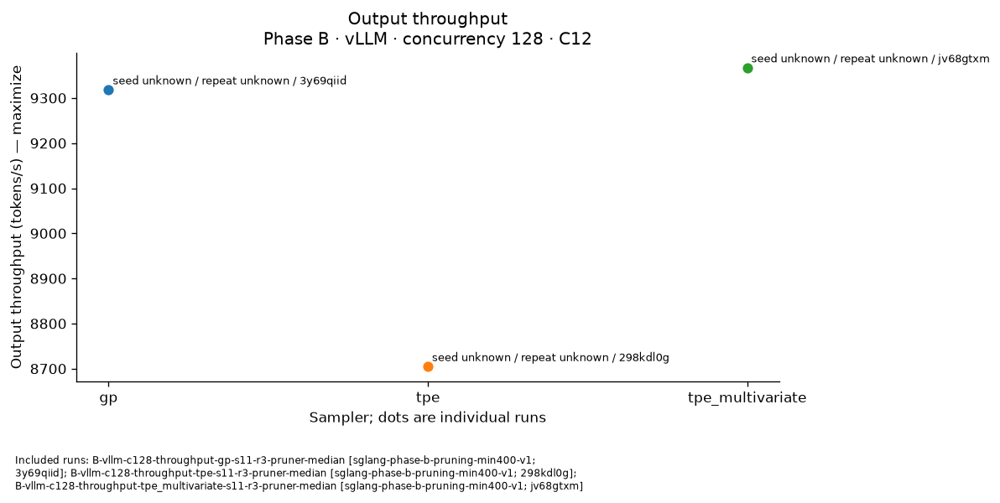

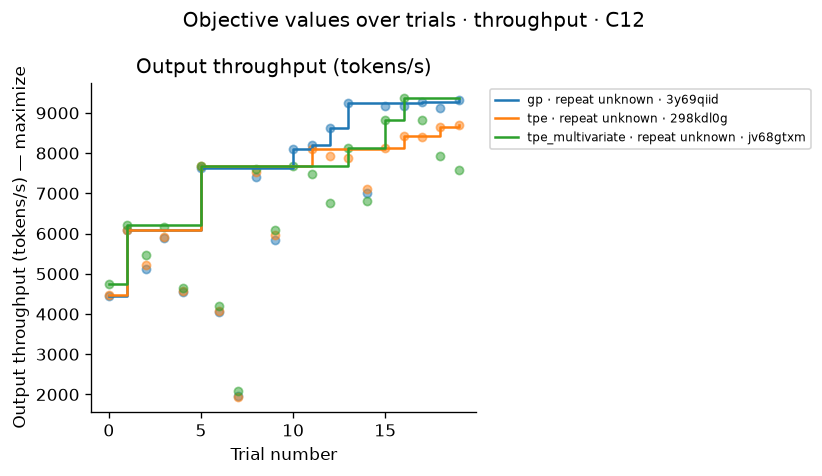

### TRT-LLM · qwen3-4b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,1,max_batch_size,0.39504619868088825
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,2,kv_cache_free_gpu_memory_fraction,0.328813977859189
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,3,enable_chunked_prefill,0.21873036460888085
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,4,max_num_tokens,0.03461053729334157
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,5,capacity_scheduler_policy,0.013871151573664423
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,6,graph_enabled,0.004463884992017966
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,7,enable_block_reuse,0.004463884992017966
qwen3-4b,trtllm,e2e,nsujtusb,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-median,gp,p95_e2e_latency_ms,8,attn_backend,0.0
qwen3-4b,trtllm,e2e,63ad2eo6,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,1,max_batch_size,0.703493267868071
qwen3-4b,trtllm,e2e,63ad2eo6,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,2,kv_cache_free_gpu_memory_fraction,0.23345177560274985


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attn_backend,6,0.000000,0.000000
1,e2e,p95_e2e_latency_ms,capacity_scheduler_policy,6,0.034263,0.002393
2,e2e,p95_e2e_latency_ms,enable_block_reuse,6,0.007081,0.000174
3,e2e,p95_e2e_latency_ms,enable_chunked_prefill,6,0.106350,0.010298
4,e2e,p95_e2e_latency_ms,graph_capture_profile,1,0.003886,NaN
5,e2e,p95_e2e_latency_ms,graph_enabled,6,0.001690,0.000004
6,e2e,p95_e2e_latency_ms,graph_padding,1,0.050151,NaN
7,e2e,p95_e2e_latency_ms,kv_cache_free_gpu_memory_fraction,6,0.267164,0.047712
8,e2e,p95_e2e_latency_ms,max_batch_size,6,0.305903,0.051293
9,e2e,p95_e2e_latency_ms,max_num_tokens,6,0.268543,0.103050


model_group,framework,run,wandb_id,status


Phase B / TRT-LLM: 12 included runs; cutoff 5 minutes


**Runs included: 8.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-gp-s11-r3-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

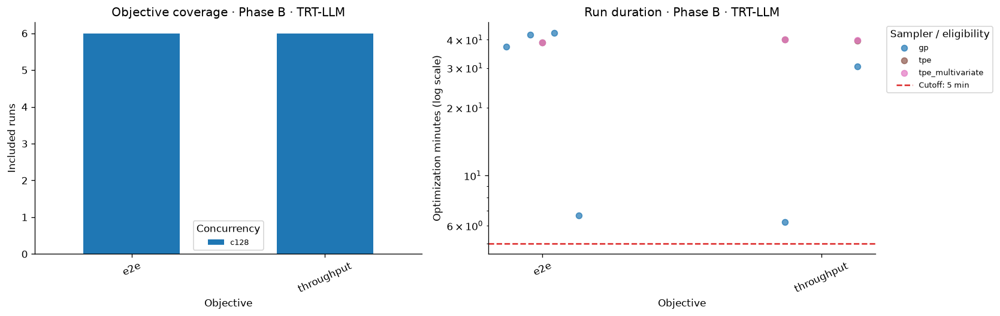

,state,trials
0,COMPLETE,164
1,FAIL,15
2,PRUNED,36


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-gp-s11-r3-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-gp-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,nsujtusb,e2e,C40,gp,37.29,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896,0,2906.688639,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r1-pruner-nop [vllm-phase-b-pruning-qwen3_8_dspark-v2 / 63ad2eo6],vllm-phase-b-pruning-qwen3_8_dspark-v2,63ad2eo6,e2e,C40,gp,42.02,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 17920,15,2118.277932,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r1-pruner-nop [vllm-phase-b-pruning-qwen3_4-gp / k3pfx9gq],vllm-phase-b-pruning-qwen3_4-gp,k3pfx9gq,e2e,C40,gp,42.94,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Truegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 32768,14,2118.260221,False,all local COMPLETE trials
B-trtllm-c128-e2e-gp-s11-r3-pruner-nop,vllm-phase-b-pruning-qwen3_8_dspark-v2,aj62us3f,e2e,C40,gp,6.64,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896,0,2895.760853,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,266pw5gc,e2e,C40,tpe,38.84,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 14336,19,2145.342758,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,fuennig9,e2e,C40,tpe_multivariate,38.99,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 88max_num_tokens: 2304,14,2743.121403,False,all local COMPLETE trials


##### Matching context C40

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

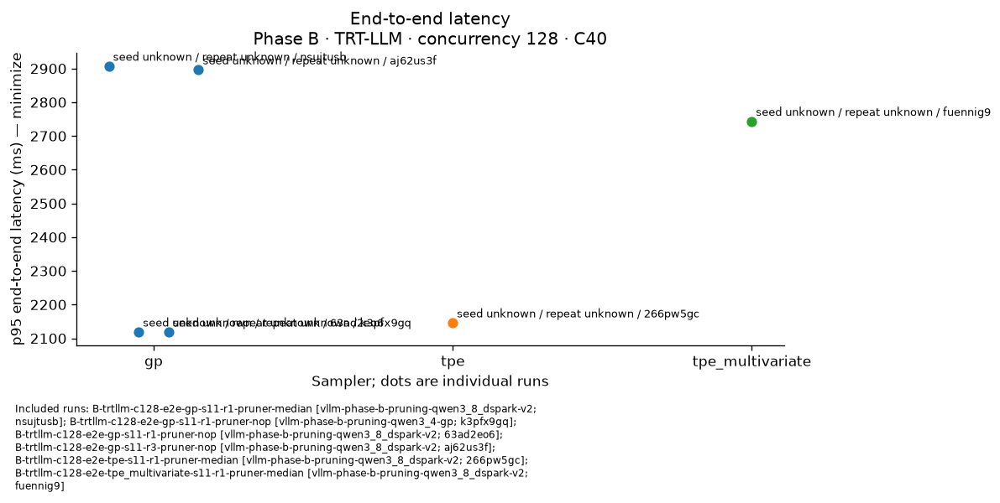

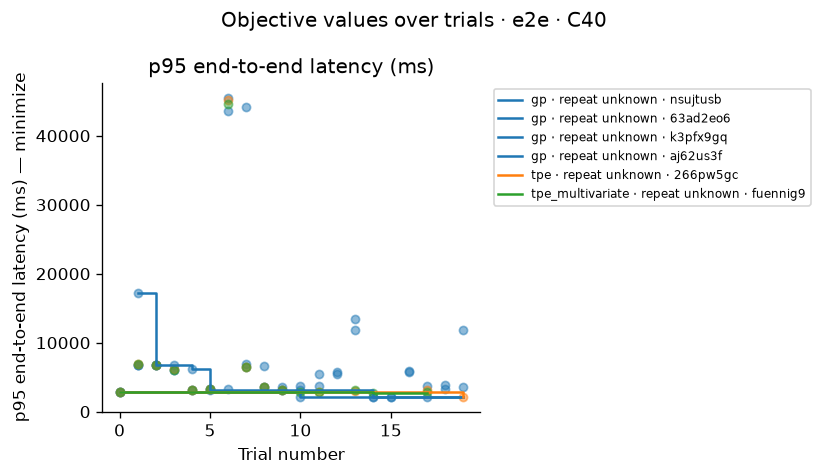

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-gp-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_8_dspark-v2 / kkz73rdq],vllm-phase-b-pruning-qwen3_8_dspark-v2,kkz73rdq,throughput,C34,gp,6.23,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.85max_batch_size: 72max_num_tokens: 16896,0,6457.252228,False,all local COMPLETE trials
B-trtllm-c128-throughput-gp-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_4-gp / hco3mp9q],vllm-phase-b-pruning-qwen3_4-gp,hco3mp9q,throughput,C34,gp,30.39,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 120max_num_tokens: 12032,10,7596.515768,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_8_dspark-v2 / bs2b748z],vllm-phase-b-pruning-qwen3_8_dspark-v2,bs2b748z,throughput,C34,tpe,40.00,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 12544,19,7795.558971,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_4-gp / efg7ys4y],vllm-phase-b-pruning-qwen3_4-gp,efg7ys4y,throughput,C34,tpe,39.56,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 128max_num_tokens: 13568,17,7771.235264,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_8_dspark-v2 / nc9i08yn],vllm-phase-b-pruning-qwen3_8_dspark-v2,nc9i08yn,throughput,C34,tpe_multivariate,39.99,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.8500000000000001max_batch_size: 128max_num_tokens: 25856,10,7770.807478,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median [vllm-phase-b-pruning-qwen3_4-gp / v2ev2c34],vllm-phase-b-pruning-qwen3_4-gp,v2ev2c34,throughput,C34,tpe_multivariate,39.86,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 128max_num_tokens: 32768,13,7854.643652,False,all local COMPLETE trials


##### Matching context C34

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

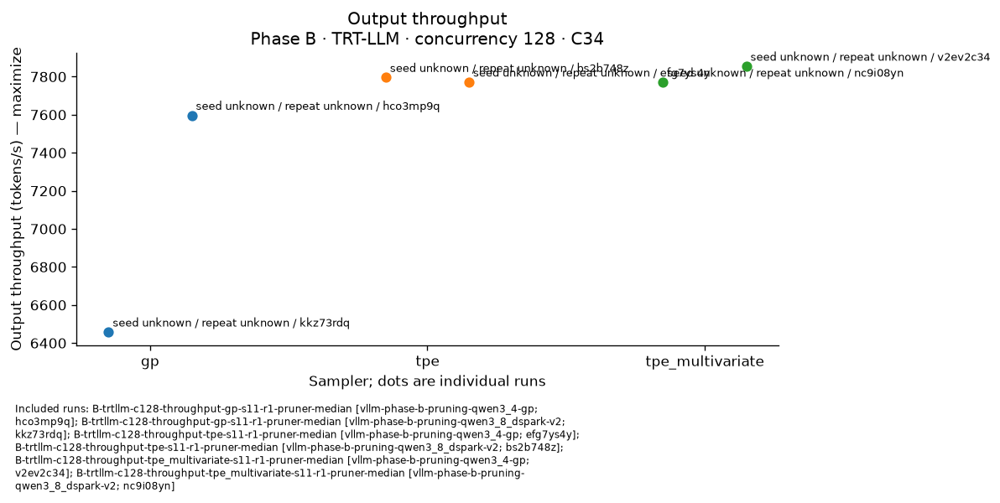

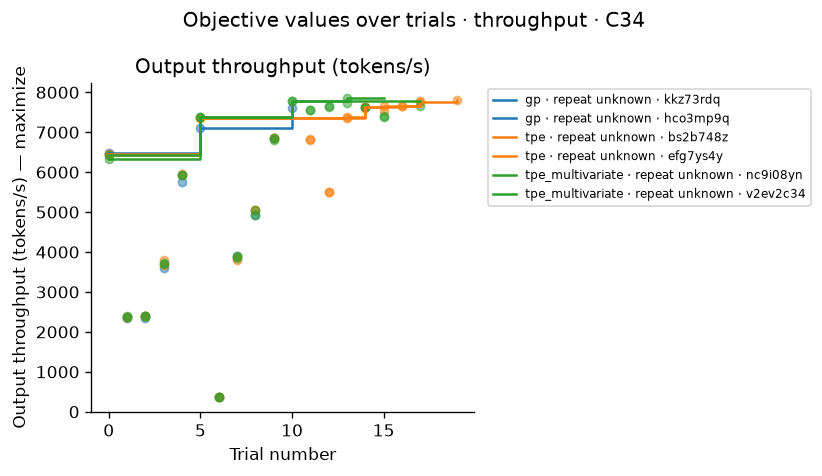

### SGLang · qwen3-4b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,1,max_running_requests,0.6785482723066896
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,2,max_prefill_tokens,0.15341689064374772
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,3,mem_fraction_static,0.07001493872367345
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,4,cuda_graph_backend_prefill,0.0411234294666108
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,5,chunked_prefill_size,0.019967418798250976
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,6,schedule_conservativeness,0.01906007968093288
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,7,disable_radix_cache,0.015502446530568691
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,8,cuda_graph_backend_decode,0.002345703202754069
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,9,schedule_policy,2.0820646771788298e-05
qwen3-4b,sglang,e2e,r45e9jku,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,10,enable_mixed_chunk,0.0


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attention_backend,5,0.000000,0.000000
1,e2e,p95_e2e_latency_ms,chunked_prefill_size,5,0.018725,0.000602
2,e2e,p95_e2e_latency_ms,cuda_graph_backend_decode,5,0.024315,0.000403
3,e2e,p95_e2e_latency_ms,cuda_graph_backend_prefill,5,0.028695,0.000469
4,e2e,p95_e2e_latency_ms,disable_overlap_schedule,5,0.000000,0.000000
5,e2e,p95_e2e_latency_ms,disable_radix_cache,5,0.029675,0.000749
6,e2e,p95_e2e_latency_ms,enable_mixed_chunk,5,0.000000,0.000000
7,e2e,p95_e2e_latency_ms,max_prefill_tokens,5,0.098490,0.003003
8,e2e,p95_e2e_latency_ms,max_running_requests,5,0.643711,0.023034
9,e2e,p95_e2e_latency_ms,mem_fraction_static,5,0.084354,0.004284


model_group,framework,run,wandb_id,status


Phase B / SGLang: 8 included runs; cutoff 5 minutes


**Runs included: 8.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-sglang-c128-throughput-gp-s11-r2-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop`

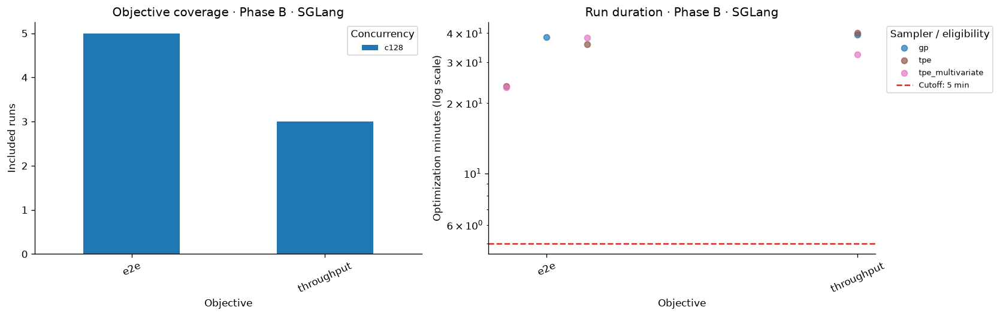

,state,trials
0,COMPLETE,127
1,FAIL,24
2,PRUNED,9


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 5.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-e2e-gp-s11-r2-pruner-nop,sglang-phase-b-pruning-qwen3_4,r45e9jku,e2e,C20,gp,38.48,attention_backend: fa3chunked_prefill_size: 19456cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7schedule_conservativeness: 1.5schedule_policy: fcfs,14,2348.996150,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-qwen3_4,xv9jj7p8,e2e,C20,tpe,23.63,attention_backend: fa3chunked_prefill_size: 22528cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 72mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,18,3270.329649,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r2-pruner-median,sglang-phase-b-pruning-qwen3_4,kr7exexf,e2e,C20,tpe,35.71,attention_backend: fa3chunked_prefill_size: 2048cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 72mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: lpm,18,3331.416658,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r1-pruner-median,sglang-phase-b-pruning-qwen3_4,4bghcfvo,e2e,C20,tpe_multivariate,23.35,attention_backend: fa3chunked_prefill_size: 22528cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 72mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,18,3242.440766,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-median,sglang-phase-b-pruning-qwen3_4,c728xfeg,e2e,C20,tpe_multivariate,38.12,attention_backend: fa3chunked_prefill_size: 20736cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 72mem_fraction_static: 0.75schedule_conservativeness: 1.25schedule_policy: fcfs,4,3190.857617,False,all local COMPLETE trials


##### Matching context C20

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

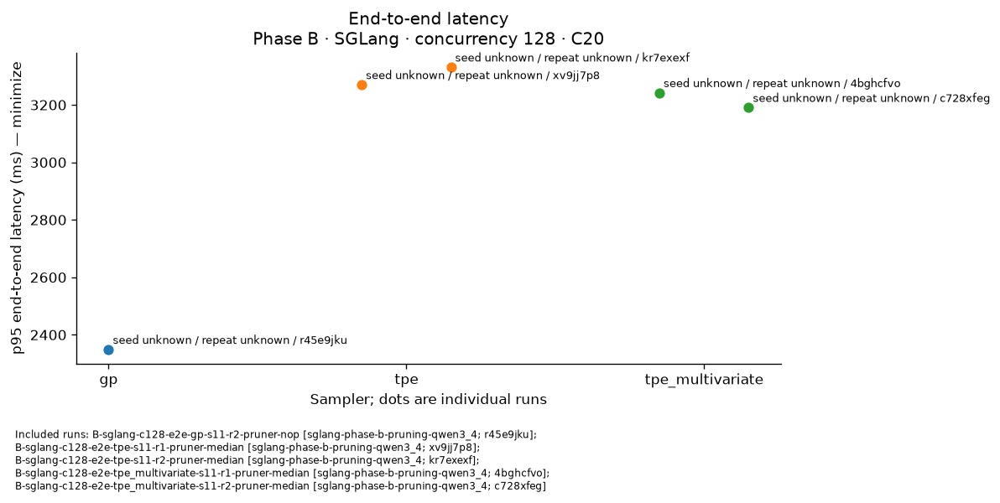

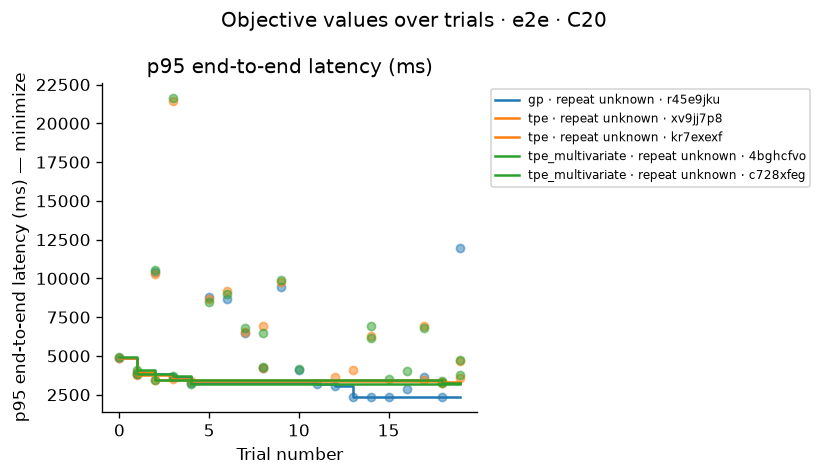

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-gp-s11-r2-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-sglang-c128-throughput-gp-s11-r2-pruner-nop,sglang-phase-b-pruning-qwen3_4,32rhe80b,throughput,C07,gp,39.42,attention_backend: fa3chunked_prefill_size: 32768cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.85schedule_conservativeness: 0.5schedule_policy: lpm,19,6976.282112,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r1-pruner-nop,sglang-phase-b-pruning-qwen3_4,gfcsn9dw,throughput,C07,tpe,40.10,attention_backend: fa3chunked_prefill_size: 32512cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.5schedule_policy: lpm,18,7020.936035,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-nop,sglang-phase-b-pruning-qwen3_4,1lhftlx2,throughput,C07,tpe_multivariate,32.34,attention_backend: fa3chunked_prefill_size: 1792cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.85schedule_conservativeness: 1.5schedule_policy: lpm,12,6721.807495,False,all local COMPLETE trials


##### Matching context C07

**Matched workload and environment**

**model:** `"qwen3-4b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

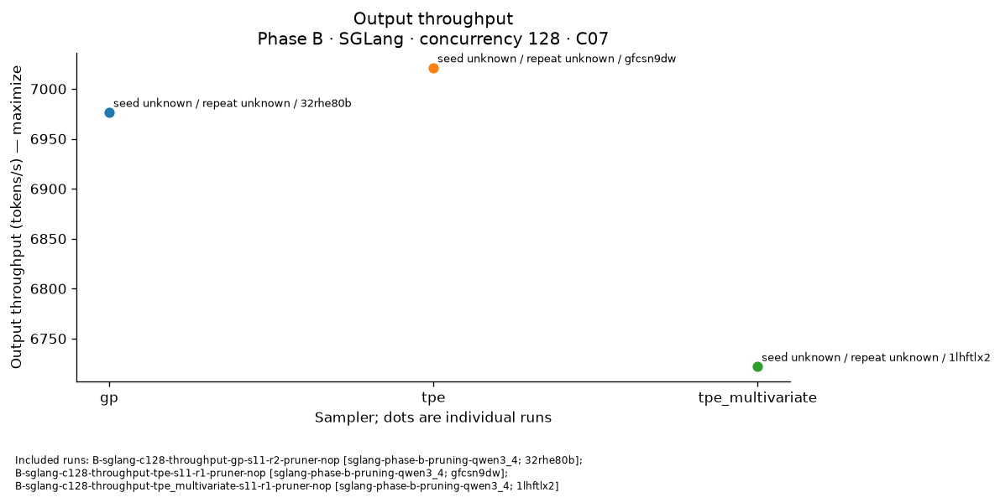

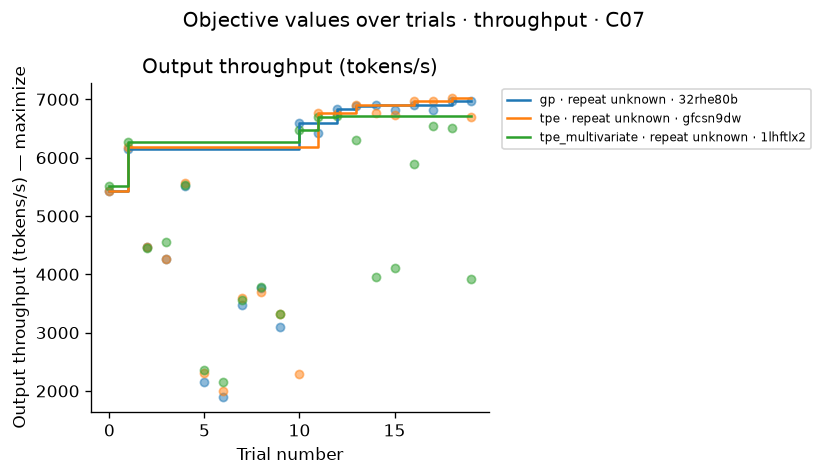

In [39]:
show_model("qwen3-4b")


## qwen3-4b dspark


### Summary of the results:

In [40]:
show_framework_summary("qwen3-4b dspark")


### Framework summaries · qwen3-4b dspark

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C11,B,128,B-vllm-c128-throughput-tpe-s11-r2-pruner-median,c52osa9i,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/c52osa9i,19,10283.592481718408,—,"async_scheduling: trueattention_backend: ""FLASH_ATTN""enable_prefix_caching: falsegpu_memory_utilization: 0.75graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 26880max_num_seqs: 112performance_mode: ""throughput""",all W&B COMPLETE trials
e2e,C24,B,128,B-vllm-c128-e2e-gp-s11-r3-pruner-median,82ln7s00,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/82ln7s00,1,—,2066.656926050291,"async_scheduling: falseattention_backend: ""auto""enable_prefix_caching: truegpu_memory_utilization: 0.75graph_capture_profile: ""powers""graph_mode: ""PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 1536max_num_seqs: 88performance_mode: ""interactivity""",all W&B COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (11 outputs left out)

**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

,target,metric,coverage,n,runs,mean,variance
0,e2e,p95_e2e_latency_ms,full trial history,78,7,4084.254051,1.222657e+07
1,throughput,output_throughput,full trial history,57,5,8319.431705,3.990726e+06


**Startup, model loading and serving timings** (seconds; variance in seconds²)

,timing,phase_status,n,mean_seconds,variance_seconds2
0,benchmark,complete,139,18.504838,106.709917
1,client_preparation,complete,143,0.899333,0.010329
2,launch_to_ready,complete,143,49.722712,768.186878
3,warmup,complete,143,0.122004,0.005786


### Per-Trial behavior:

### qwen3-4b dspark · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,9589.640661,5576.912614,3,3
1,B,128,throughput,1,9436.049242,41.606732,3,3
2,B,128,throughput,2,9996.327995,772.465792,3,3
3,B,128,throughput,3,9471.918376,9557.684004,3,3
4,B,128,throughput,4,9177.094695,26460.114246,3,3
5,B,128,throughput,5,10189.673001,463.596327,3,3
6,B,128,throughput,6,9707.293908,910.144149,3,3
7,B,128,throughput,7,6994.458129,2874.260168,3,3
8,B,128,throughput,8,10008.104815,93.904504,3,3
9,B,128,throughput,9,9969.243390,1476.266319,3,3


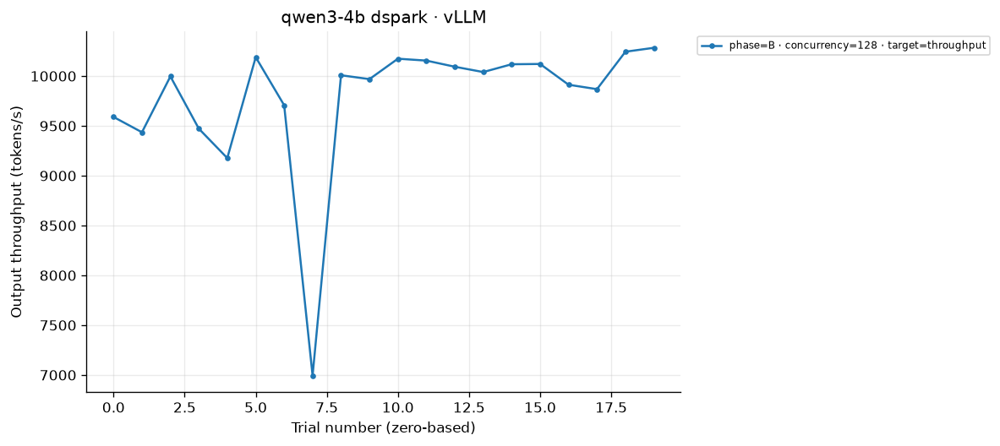

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,2344.607502,327.353055,3,3
1,B,128,e2e,1,2083.622625,456.175007,3,3
2,B,128,e2e,2,2631.124808,306.324462,3,3
3,B,128,e2e,3,2148.067736,662.201215,3,3
4,B,128,e2e,4,2201.696903,7565.834631,3,3
5,B,128,e2e,5,2462.453788,46.972389,3,3
6,B,128,e2e,6,2371.154900,1046.759101,3,3
7,B,128,e2e,7,2537.453763,11138.356852,3,3
8,B,128,e2e,8,2800.410499,57.103750,3,3
9,B,128,e2e,9,2799.413243,673.779680,3,3


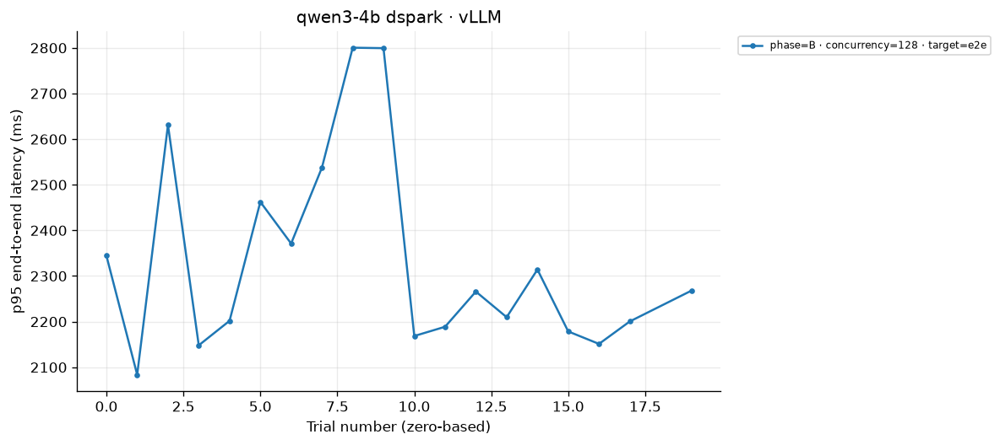

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [41]:
mean_by_trial_number("qwen3-4b dspark", "vllm")


### qwen3-4b dspark · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,1,9589.102635,5145.779219,5,5
1,B,128,throughput,2,9199.344729,5996.476805,5,5
2,B,128,throughput,3,2517.279356,7099.868833,5,5
3,B,128,throughput,8,8679.079886,53292.202630,5,5
4,B,128,throughput,14,6998.260742,4527.842953,4,4
5,B,128,throughput,17,8274.595036,24327.871025,4,4
6,B,128,throughput,18,8976.958977,741.021074,4,4
7,B,128,throughput,19,7848.373348,2096.709378,3,3
8,B,128,throughput,23,9233.550883,1846.998818,3,3
9,B,128,throughput,24,8823.811714,37690.894196,3,3


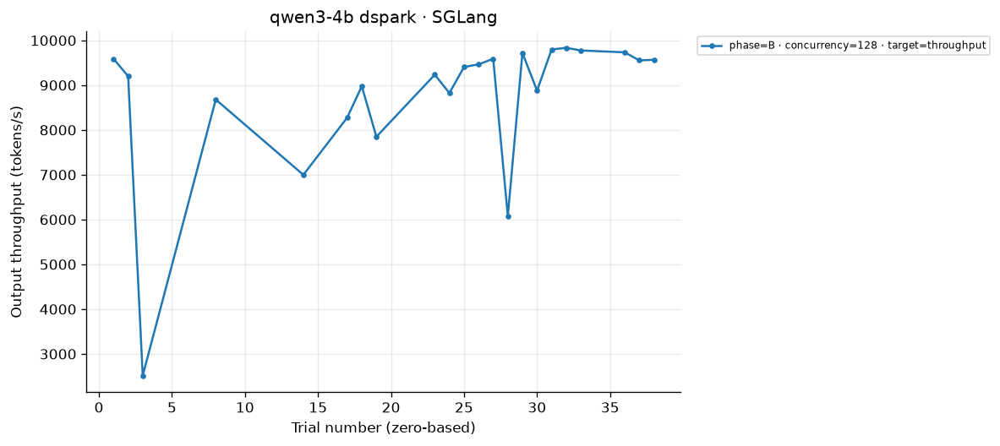

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,1,3018.988994,4220.792064,6,6
1,B,128,e2e,2,2613.755206,7.897304,6,6
2,B,128,e2e,3,6853.759677,64709.207961,6,6
3,B,128,e2e,8,3015.130804,667.662182,6,6
4,B,128,e2e,14,3108.923413,5114.955082,6,6
5,B,128,e2e,17,3036.071984,1516.724767,6,6
6,B,128,e2e,18,2571.941606,32.876936,6,6
7,B,128,e2e,19,2527.330807,46.076036,6,6
8,B,128,e2e,20,18153.903398,9137.027573,4,4
9,B,128,e2e,21,4875.135762,8136.483232,4,4


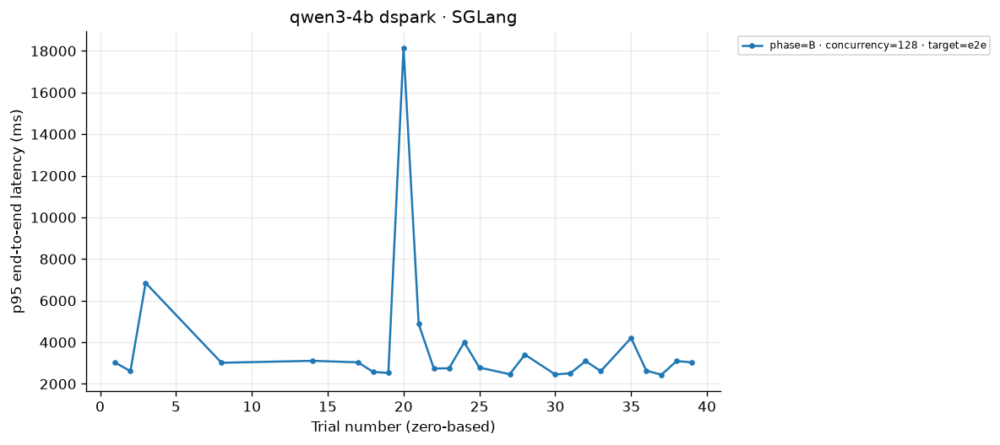

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,1,37.681309,6.670332e+00,6,6
1,B,128,e2e,2,41.013802,4.178331e-07,6,6
2,B,128,e2e,3,44.349868,6.682440e+00,6,6
3,B,128,e2e,8,31.013004,3.360352e-06,6,6
4,B,128,e2e,14,31.011802,1.040734e-07,6,6
5,B,128,e2e,17,66.019970,2.766881e-07,6,6
6,B,128,e2e,18,91.026907,1.601479e-06,6,6
7,B,128,e2e,19,36.013178,9.516412e-07,6,6
8,B,128,e2e,20,42.264506,1.563213e+02,4,4
9,B,128,e2e,21,31.011561,7.210885e-07,4,4


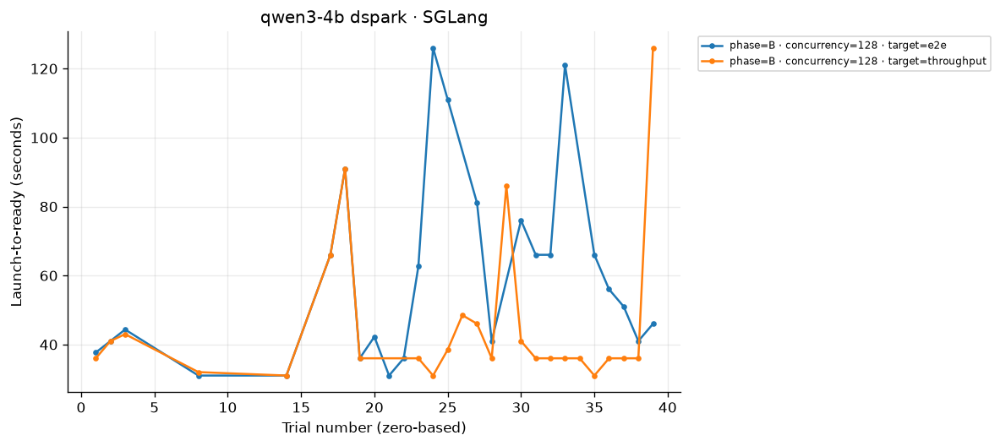

In [42]:
mean_by_trial_number("qwen3-4b dspark", "sglang")


### qwen3-4b dspark · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,1,3738.396531,217.540193,3,3
1,B,128,throughput,2,3655.648778,4634.038885,3,3
2,B,128,throughput,6,1413.313396,22.074229,3,3
3,B,128,throughput,8,6605.586958,6459.260399,3,3
4,B,128,throughput,11,7020.959369,11164.520693,3,3
5,B,128,throughput,12,1340.932545,273.053221,3,3
6,B,128,throughput,13,2706.158590,275.248299,3,3
7,B,128,throughput,14,1388.310392,394.786296,3,3
8,B,128,throughput,18,6747.824845,7624.276399,3,3
9,B,128,throughput,19,7260.833527,1823.388129,3,3


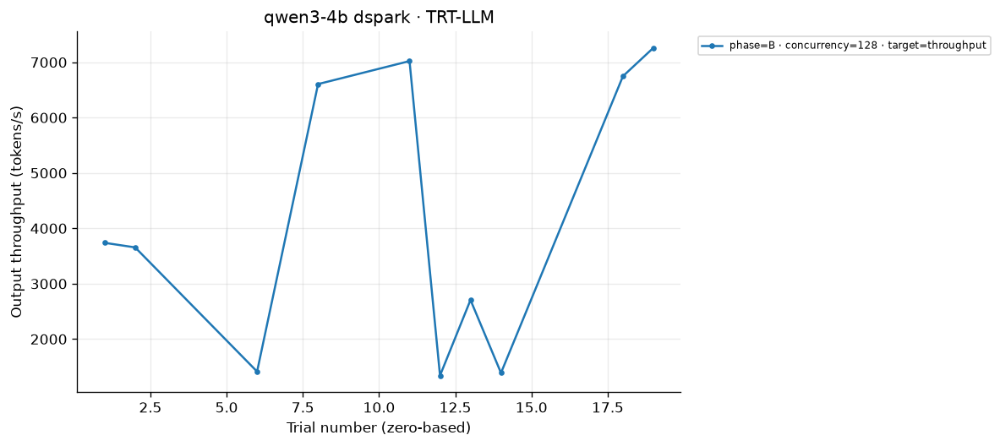

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,1,5078.952891,1401.913242,4,4
1,B,128,e2e,2,5105.695508,1778.153887,4,4
2,B,128,e2e,6,13281.465440,14278.813551,3,3
3,B,128,e2e,8,3275.608858,2169.348466,3,3
4,B,128,e2e,11,3151.918320,308.569596,3,3
5,B,128,e2e,12,13865.528251,57362.997275,3,3
6,B,128,e2e,13,6774.358066,712.014491,3,3
7,B,128,e2e,14,13033.535544,5882.855982,3,3
8,B,128,e2e,18,3196.229548,121.441937,3,3
9,B,128,e2e,19,3040.231922,1138.392868,3,3


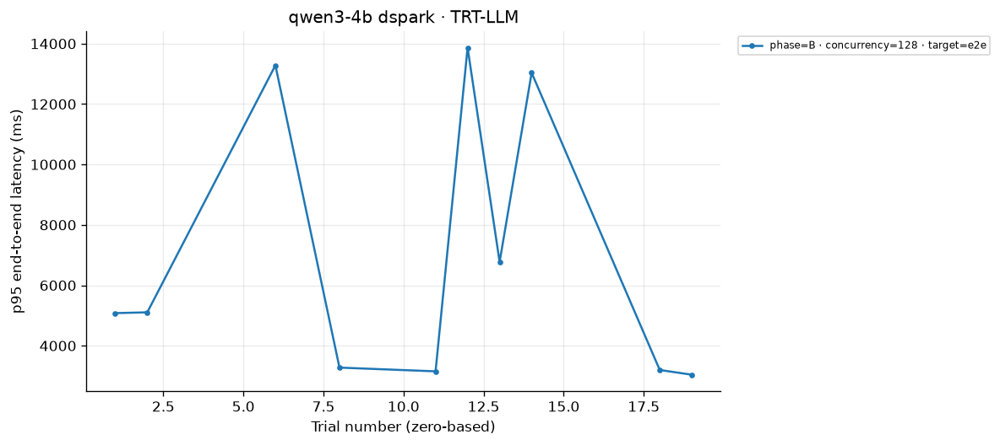

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [43]:
mean_by_trial_number("qwen3-4b dspark", "trtllm")


### Overall results and plots:

**25 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3-4b dspark,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,14.15568262455,W&B terminal _runtime,wandb snapshot,—,7gwhbppv,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,finished,sglang-phase-b-pruning-qwen3_4_dspark,[]
qwen3-4b dspark,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,25.653637103433343,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/studies.sqlite3,rw82qovo,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/rw82qovo,finished,sglang-phase-b-pruning-qwen3_4_dspark,['experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/B-sglang-c128-e2e-gp-s11-r2-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b dspark,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop,18.394178614016667,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/studies.sqlite3,0bxo3s5e,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/0bxo3s5e,finished,sglang-phase-b-pruning-qwen3_4_dspark,['experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/B-sglang-c128-e2e-tpe-s11-r2-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b dspark,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop,14.145473354983332,W&B terminal _runtime,wandb snapshot,—,sigvljt9,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/sigvljt9,finished,sglang-phase-b-pruning-qwen3_4_dspark,[]
qwen3-4b dspark,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop,10.3155114146,W&B terminal _runtime,wandb snapshot,—,9zbj7gvx,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/9zbj7gvx,crashed,sglang-phase-b-pruning-qwen3_4_dspark,[]
qwen3-4b dspark,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop,13.781506963099998,W&B terminal _runtime,wandb snapshot,—,irqobxfb,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/irqobxfb,finished,sglang-phase-b-pruning-qwen3_4_dspark,[]
qwen3-4b dspark,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop,31.818702714350003,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/studies.sqlite3,tipvad6g,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/tipvad6g,finished,sglang-phase-b-pruning-qwen3_4_dspark,['experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b dspark,B-sglang-c128-throughput-gp-s11-r3-pruner-nop-dsparkq3_4,B,sglang,B-sglang-c128-throughput-gp-s11-r3-pruner-nop,30.104974807750022,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/studies.sqlite3,1mj5pu8e,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/1mj5pu8e,finished,sglang-phase-b-pruning-qwen3_4_dspark,['experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/B-sglang-c128-throughput-gp-s11-r3-pruner-nop-B-sglang-c128-measured.jsonl']
qwen3-4b dspark,B-sglang-c128-throughput-tpe-s11-r1-pruner-median-dsparkq3_4,B,sglang,B-sglang-c128-throughput-tpe-s11-r1-pruner-median,17.932095206683336,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-qwen3_4_dspark/studies.sqlite3,9szzefj2,https://wandb.ai/maorblumberg-t

### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
33,qwen3-4b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,sglang,78,7,4084.254051,1.222657e+07,phase/concurrency
34,qwen3-4b dspark,B,throughput,128,full trial history,output_throughput,sglang,57,5,8319.431705,3.990726e+06,phase/concurrency
35,qwen3-4b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,32,4,6862.350670,1.852595e+07,phase/concurrency
36,qwen3-4b dspark,B,throughput,128,full trial history,output_throughput,trtllm,30,3,4187.796493,5.814999e+06,phase/concurrency
37,qwen3-4b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,41,3,2376.873477,5.657028e+04,phase/concurrency
38,qwen3-4b dspark,B,throughput,128,full trial history,output_throughput,vllm,41,3,9628.130842,6.623966e+05,phase/concurrency
68,qwen3-4b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,151,14,4209.396357,1.254760e+07,phase/concurrency
69,qwen3-4b dspark,B,throughput,128,full trial history,output_throughput,overall,128,11,7770.272395,7.577500e+06,phase/concurrency
103,qwen3-4b dspark,all,e2e,all,full trial history,p95_e2e_latency_ms,sglang,78,7,4084.254051,1.222657e+07,model
104,qwen3-4b dspark,all,throughput,all,full trial history,output_throughput,sglang,57,5,8319.431705,3.990726e+06,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

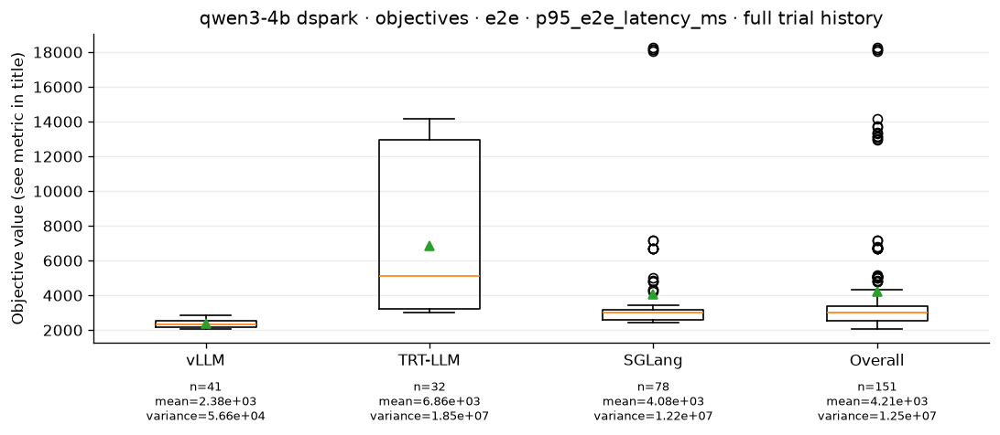

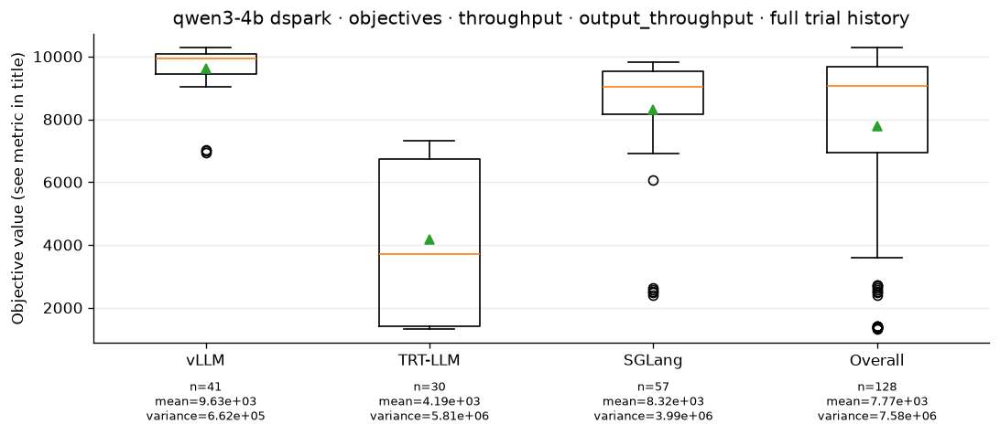

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3-4b dspark,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-dsparkq3_4,7gwhbppv,40,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-gp-s11-r2-pruner-nop-dsparkq3_4,rw82qovo,103,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,g0phxvkj,6,under five minutes
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop-dsparkq3_4,0bxo3s5e,110,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop-dsparkq3_4,sigvljt9,40,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,9zbj7gvx,25,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,irqobxfb,40,included
qwen3-4b dspark,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop-dsparkq3_4,tipvad6g,150,included
qwen3-4b dspark,sglang,B-sglang-c128-throughput-gp-s11-r1-pruner-median-dsparkq3_4,by7lkkyu,12,under five minutes
qwen3-4b dspark,sglang,B-sglang-c128-throughput-gp-s11-r3-pruner-nop-dsparkq3_4,1mj5pu8e,127,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope
15,qwen3-4b dspark,B,launch_to_ready,complete,sglang,143,49.722712,768.186878,phase
16,qwen3-4b dspark,B,client_preparation,complete,sglang,143,0.899333,0.010329,phase
17,qwen3-4b dspark,B,warmup,complete,sglang,143,0.122004,0.005786,phase
18,qwen3-4b dspark,B,benchmark,complete,sglang,139,18.504838,106.709917,phase
53,qwen3-4b dspark,B,launch_to_ready,complete,overall,143,49.722712,768.186878,phase
54,qwen3-4b dspark,B,client_preparation,complete,overall,143,0.899333,0.010329,phase
55,qwen3-4b dspark,B,warmup,complete,overall,143,0.122004,0.005786,phase
56,qwen3-4b dspark,B,benchmark,complete,overall,139,18.504838,106.709917,phase
86,qwen3-4b dspark,all,launch_to_ready,complete,sglang,143,49.722712,768.186878,model
87,qwen3-4b dspark,all,client_preparation,complete,sglang,143,0.899333,0.010329,model


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

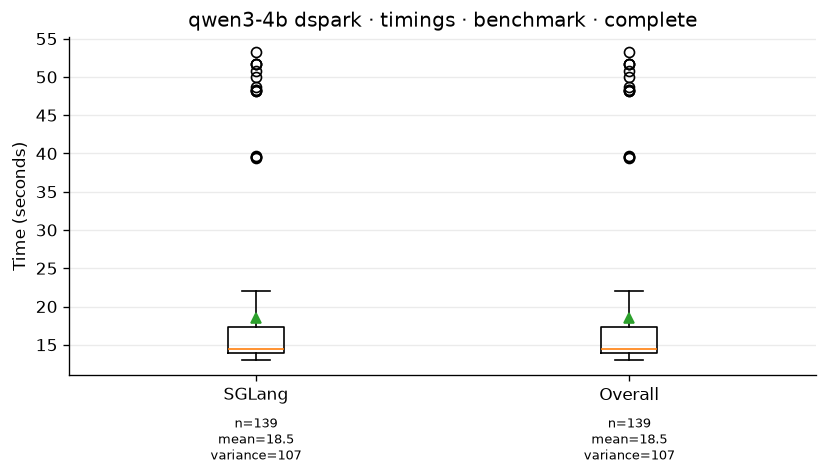

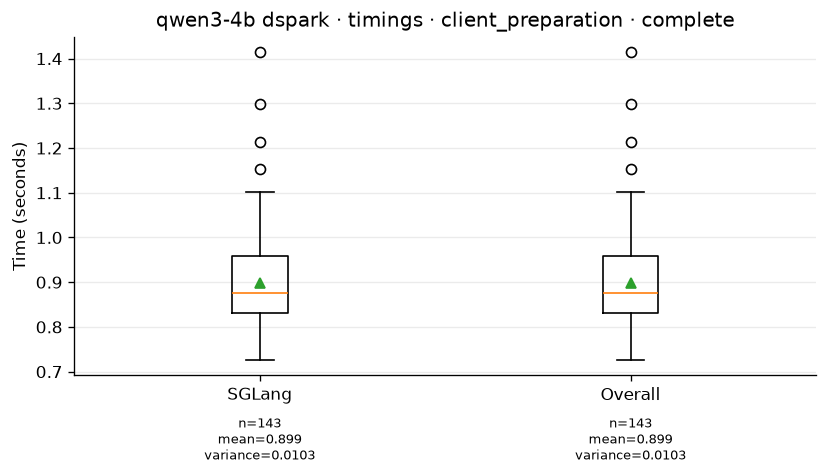

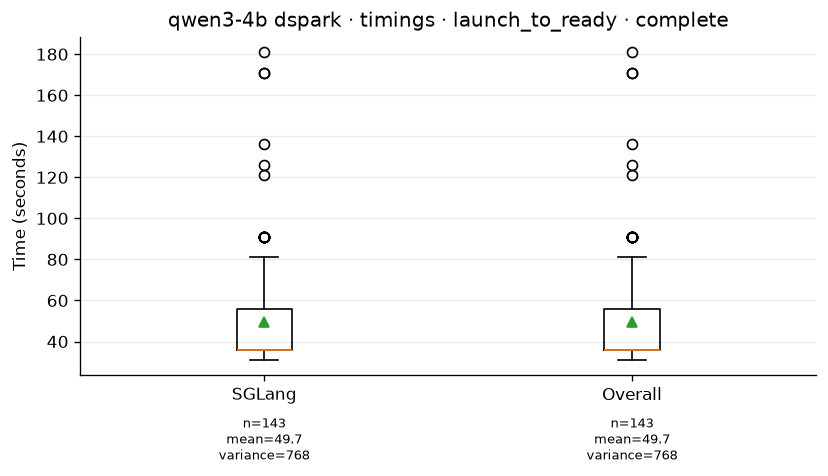

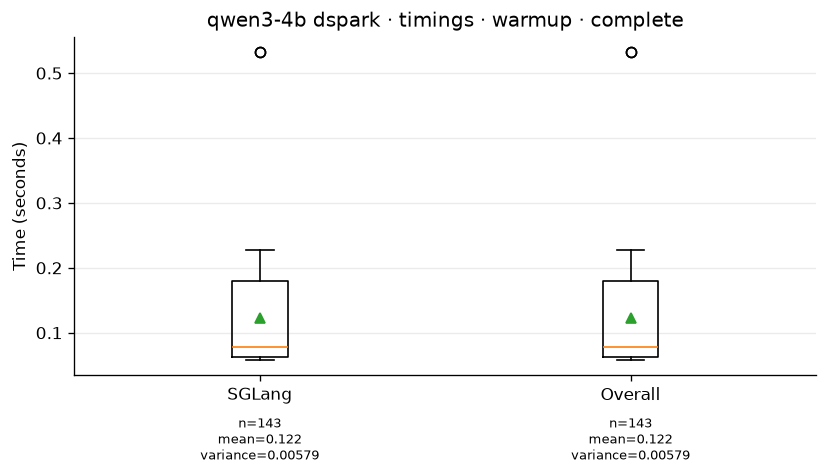

Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means.

model_group,framework,phase,study_name,wandb_id,trial,params,state,source,wandb_url,launch_to_ready (s),launch_to_ready status,client_preparation (s),client_preparation status,warmup (s),warmup status,benchmark (s),benchmark status,runner_wall (s),runner_wall status
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,1,"attention_backend: ""fa3""chunked_prefill_size: 28416cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: ""lpm""",COMPLETE,W&B trial history,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,36.013617961000364,complete,0.898417566000262,complete,0.07688178900025378,complete,13.441067935999854,complete,57.809606814999825,unknown
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,2,"attention_backend: ""fa3""chunked_prefill_size: 2560cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: ""fcfs""",COMPLETE,W&B trial history,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,41.01302136100003,complete,0.8417806140000721,complete,0.05920664199993553,complete,13.92474387700031,complete,62.99683864899998,unknown
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,3,"attention_backend: ""fa3""chunked_prefill_size: 11008cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 16mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: ""fcfs""",COMPLETE,W&B trial history,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,46.01827307099984,complete,0.8698893939999834,complete,0.17185644600021988,complete,48.154534500999944,complete,102.305648217,unknown
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,8,"attention_backend: ""fa3""chunked_prefill_size: 14080cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 120mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: ""fcfs""",COMPLETE,W&B trial history,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,31.01193767199993,complete,0.8302235460000702,complete,0.18312293300004967,complete,14.446838428999854,complete,53.421652660999825,unknown
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,14,"attention_backend: ""fa3""chunked_prefill_size: 28416cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 72mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: ""fcfs""",COMPLETE,W&B trial history,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwhbppv,31.01157199699992,complete,0.9150462090001383,complete,0.18743917999972837,complete,18.22435700799997,complete,57.23916931199983,unknown
qwen3-4b dspark,sglang,B,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,7gwhbppv,17,"attention_backend: ""fa3""chunked_prefill_size: 18432cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 112mem_fraction_static: 0.7schedule_conservativeness:

### vLLM · qwen3-4b dspark

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,1,max_num_batched_tokens,0.16973921986506435
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,2,attention_backend,0.15021307455923402
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,3,graph_mode,0.14863550304525805
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,4,max_num_seqs,0.13769539501227832
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,5,enable_prefix_caching,0.12148939730868226
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,6,async_scheduling,0.12148939730868226
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,7,gpu_memory_utilization,0.0966401525019691
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,8,kv_cache_dtype,0.05190653556815004
qwen3-4b dspark,vllm,e2e,82ln7s00,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r3-pruner-median,gp,p95_e2e_latency_ms,9,performance_mode,0.0021913248306817193
qwen3-4b dspark,vllm,e2e,8939revy,W&B trial history,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,1,gpu_memory_utilization,0.5568735219246765


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.041586,0.004791
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.053812,0.007000
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.057550,0.003660
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.224190,0.084513
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.078427,0.005249
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.021776,0.000711
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.428060,0.216910
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.082010,0.004464
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.012589,0.000372
9,throughput,output_throughput,async_scheduling,3,0.010166,0.000085


model_group,framework,run,wandb_id,status


Phase B / vLLM: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

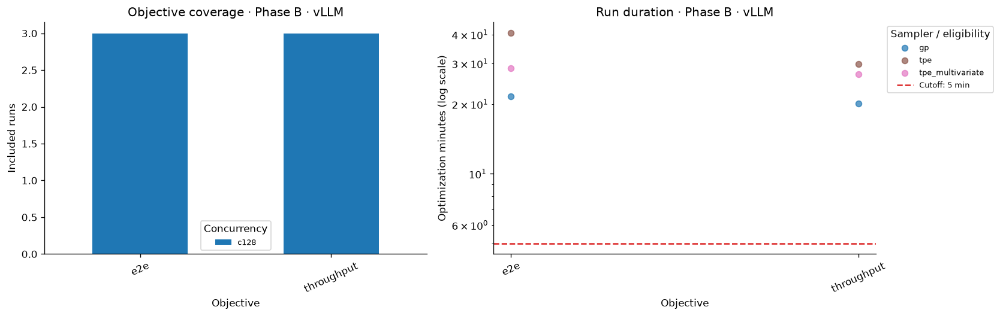

,state,trials
0,COMPLETE,82
1,PRUNED,38


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,82ln7s00,e2e,C24,gp,21.61,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1536max_num_seqs: 88performance_mode: interactivity,1,2066.656926,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,8939revy,e2e,C24,tpe,40.72,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1536max_num_seqs: 88performance_mode: interactivity,1,2076.603899,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,sglang-phase-b-pruning-min400-v1,zo8jwolp,e2e,C24,tpe_multivariate,28.67,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1536max_num_seqs: 88performance_mode: interactivity,1,2107.607048,False,all W&B COMPLETE trials


##### Matching context C24

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

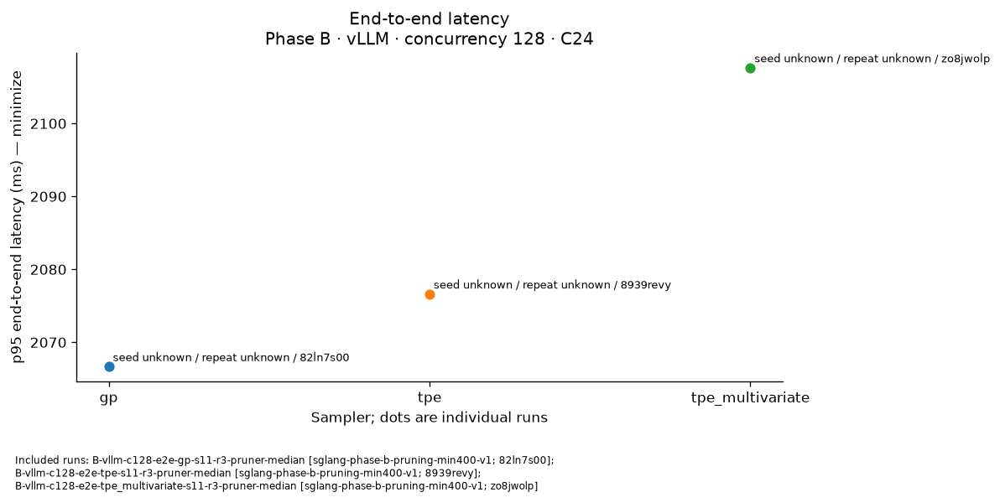

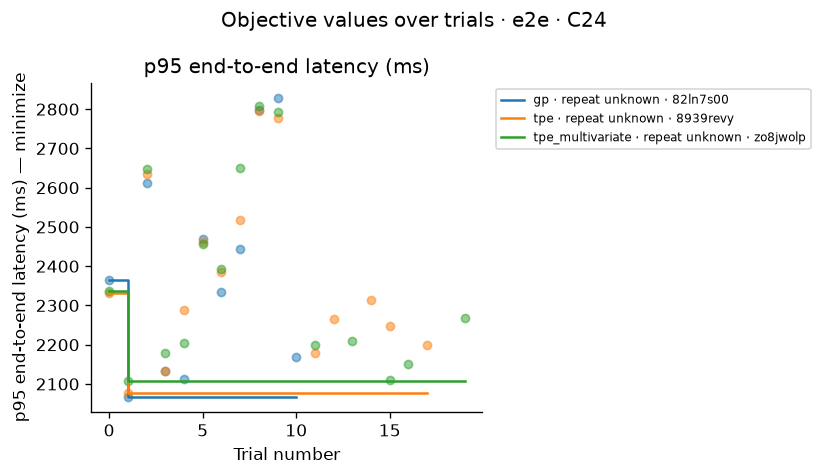

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r2-pruner-median,sglang-phase-b-pruning-min400-v1,2mnx7zd1,throughput,C11,gp,20.15,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,10212.110014,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r2-pruner-median,sglang-phase-b-pruning-min400-v1,c52osa9i,throughput,C11,tpe,29.87,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 26880max_num_seqs: 112performance_mode: throughput,19,10283.592482,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,sglang-phase-b-pruning-min400-v1,6iog6w3n,throughput,C11,tpe_multivariate,26.99,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 11520max_num_seqs: 104performance_mode: balanced,5,10187.729819,False,all W&B COMPLETE trials


##### Matching context C11

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

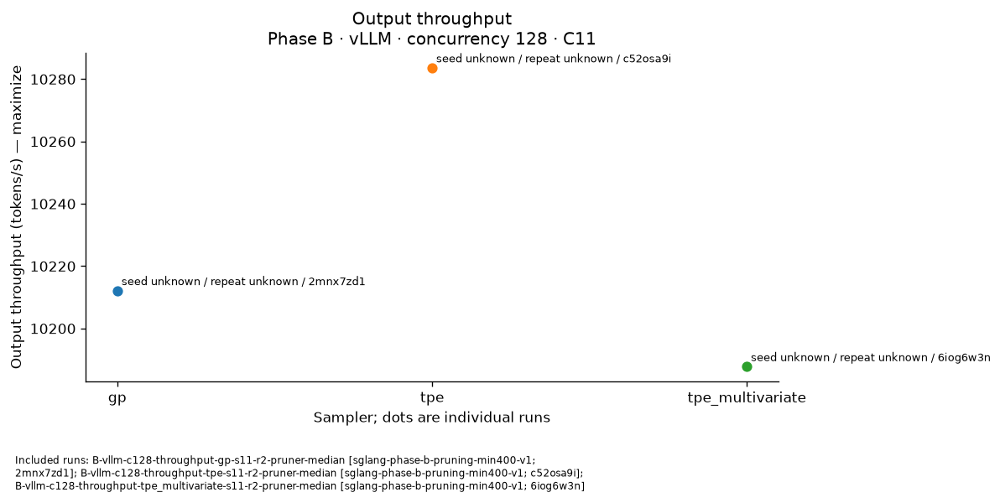

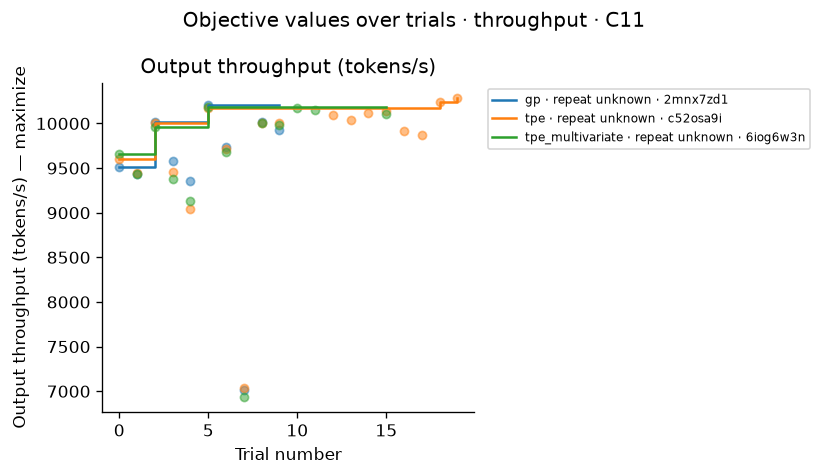

### TRT-LLM · qwen3-4b dspark

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,1,max_batch_size,0.73473995353119
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,2,enable_chunked_prefill,0.13267497302071501
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.05505063028487704
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,4,max_num_tokens,0.035384184329652436
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,5,capacity_scheduler_policy,0.034083700143621526
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,6,enable_block_reuse,0.008066558689944006
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,7,attn_backend,0.0
qwen3-4b dspark,trtllm,e2e,29dvt42b,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,8,graph_enabled,0.0
qwen3-4b dspark,trtllm,e2e,wpdyh0my,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,tpe,p95_e2e_latency_ms,1,max_batch_size,0.73473995353119
qwen3-4b dspark,trtllm,e2e,wpdyh0my,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,tpe,p95_e2e_latency_ms,2,enable_chunked_prefill,0.13267497302071501


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attn_backend,4,0.025000,0.002500
1,e2e,p95_e2e_latency_ms,capacity_scheduler_policy,4,0.050563,0.001086
2,e2e,p95_e2e_latency_ms,enable_block_reuse,4,0.031050,0.002113
3,e2e,p95_e2e_latency_ms,enable_chunked_prefill,4,0.124506,0.000267
4,e2e,p95_e2e_latency_ms,graph_capture_profile,1,0.100000,NaN
5,e2e,p95_e2e_latency_ms,graph_enabled,4,0.025000,0.002500
6,e2e,p95_e2e_latency_ms,graph_padding,1,0.100000,NaN
7,e2e,p95_e2e_latency_ms,kv_cache_free_gpu_memory_fraction,4,0.066288,0.000505
8,e2e,p95_e2e_latency_ms,max_batch_size,4,0.576055,0.100724
9,e2e,p95_e2e_latency_ms,max_num_tokens,4,0.051538,0.001044


model_group,framework,run,wandb_id,status


Phase B / TRT-LLM: 7 included runs; cutoff 5 minutes


**Runs included: 7.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

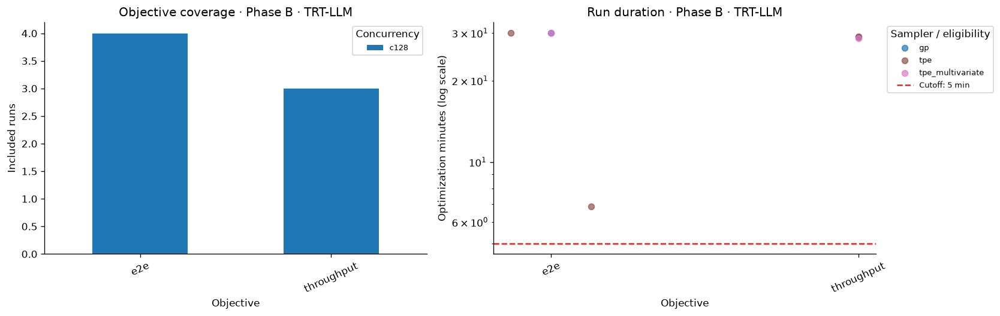

,state,trials
0,COMPLETE,62
1,FAIL,63


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-gp-s11-r2-pruner-nop`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-e2e-tpe-s11-r1-pruner-nop`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-gp-s11-r2-pruner-nop,vllm-phase-b-pruning-qwen3_8_dspark-v2,29dvt42b,e2e,C39,gp,30.05,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,3076.314880,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,trtllm-phase-b-pruning-qwen3_4_dspark-v2,wpdyh0my,e2e,C39,tpe,29.98,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,3009.466136,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe-s11-r1-pruner-nop,vllm-phase-b-pruning-qwen3_8_dspark-v2,0l88lez1,e2e,C39,tpe,6.86,attn_backend: TRTLLMcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Truegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 0kv_cache_free_gpu_memory_fraction: 0.95max_batch_size: 16max_num_tokens: 29440,1,5032.827142,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,trtllm-phase-b-pruning-qwen3_4_dspark-v2,94yjn1ye,e2e,C39,tpe_multivariate,30.02,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,3034.914750,False,all local COMPLETE trials


##### Matching context C39

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

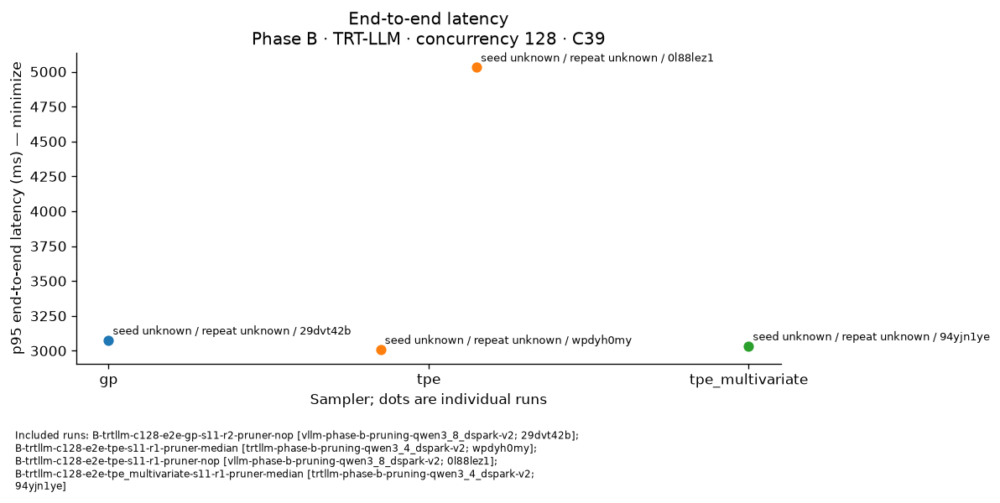

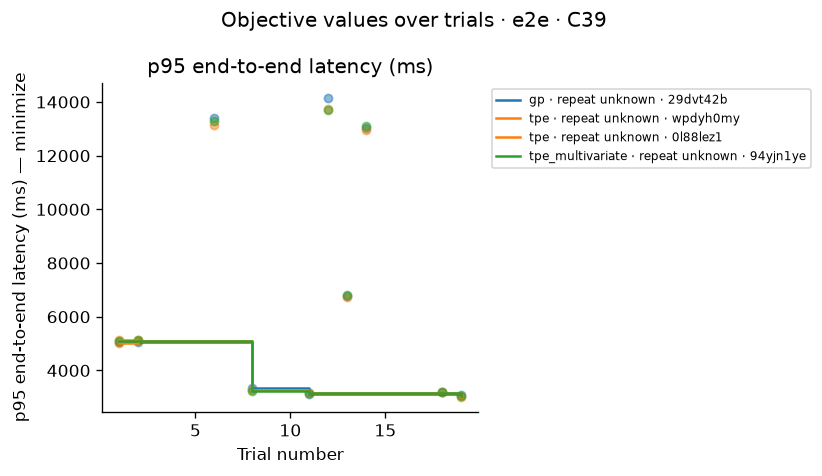

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-gp-s11-r1-pruner-nop`
- `B-trtllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-gp-s11-r1-pruner-nop,vllm-phase-b-pruning-qwen3_4-dspark,yx7tj6lr,throughput,C33,gp,28.93,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,7307.561614,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe-s11-r2-pruner-median,vllm-phase-b-pruning-qwen3_4-dspark,irkxz0t2,throughput,C33,tpe,29.07,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,7223.840377,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,vllm-phase-b-pruning-qwen3_4-dspark,6zq7ibib,throughput,C33,tpe_multivariate,28.75,attn_backend: TRTLLMcapacity_scheduler_policy: MAX_UTILIZATIONenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 56max_num_tokens: 30976,19,7251.098590,False,all local COMPLETE trials


##### Matching context C33

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

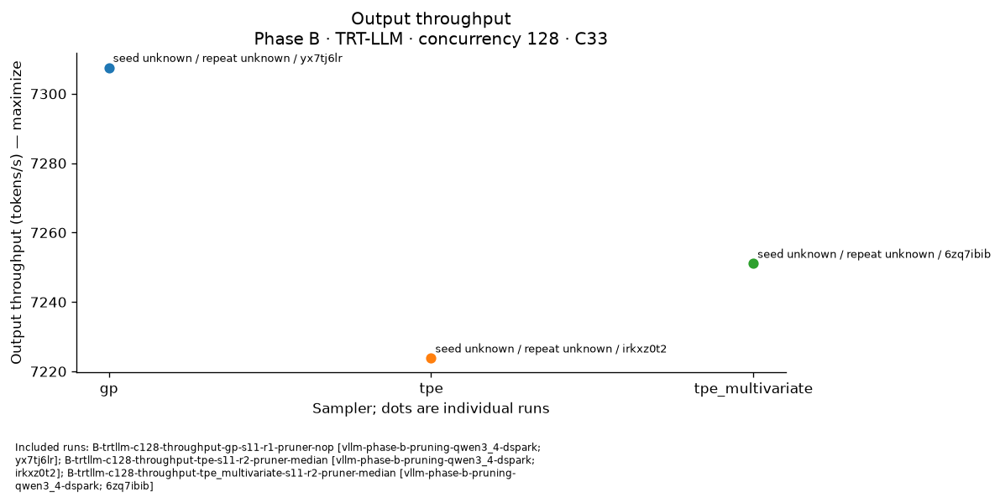

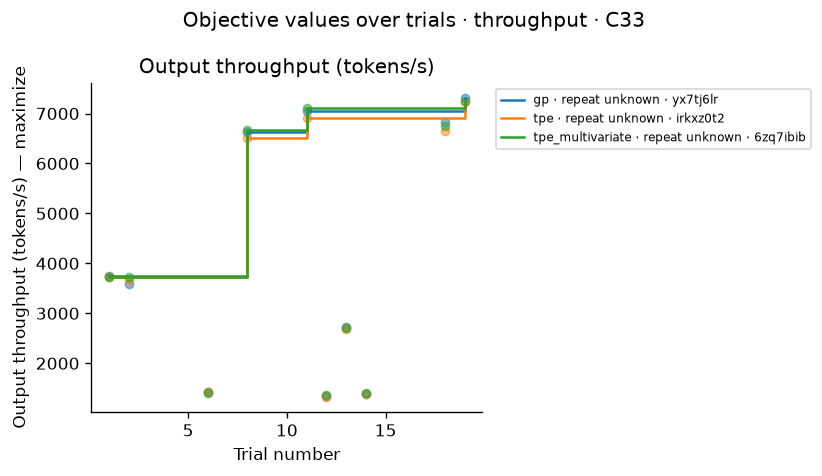

### SGLang · qwen3-4b dspark

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,1,schedule_conservativeness,0.5959319974623091
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,2,mem_fraction_static,0.130374002504543
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,3,max_prefill_tokens,0.10628891190138513
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,4,max_running_requests,0.10268811955827349
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,5,cuda_graph_backend_decode,0.04505888388359528
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,6,schedule_policy,0.0105673881068105
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,7,disable_radix_cache,0.007377466699213929
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,8,chunked_prefill_size,0.0017132298838696063
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,9,enable_mixed_chunk,0.0
qwen3-4b dspark,sglang,e2e,7gwhbppv,W&B trial history,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-s11-r2-pruner-nop,gp,p95_e2e_latency_ms,10,disable_overlap_schedule,0.0


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attention_backend,7,0.000000,0.000000
1,e2e,p95_e2e_latency_ms,chunked_prefill_size,7,0.042808,0.006338
2,e2e,p95_e2e_latency_ms,cuda_graph_backend_decode,7,0.044364,0.000447
3,e2e,p95_e2e_latency_ms,cuda_graph_backend_prefill,7,0.002062,0.000020
4,e2e,p95_e2e_latency_ms,disable_overlap_schedule,7,0.000000,0.000000
5,e2e,p95_e2e_latency_ms,disable_radix_cache,7,0.021355,0.001894
6,e2e,p95_e2e_latency_ms,enable_mixed_chunk,7,0.000000,0.000000
7,e2e,p95_e2e_latency_ms,max_prefill_tokens,7,0.118647,0.007173
8,e2e,p95_e2e_latency_ms,max_running_requests,7,0.210495,0.077885
9,e2e,p95_e2e_latency_ms,mem_fraction_static,7,0.125333,0.000437


model_group,framework,run,wandb_id,status


Phase B / SGLang: 12 included runs; cutoff 5 minutes


**Runs included: 8.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop`
- `B-sglang-c128-throughput-gp-s11-r3-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r2-pruner-nop`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

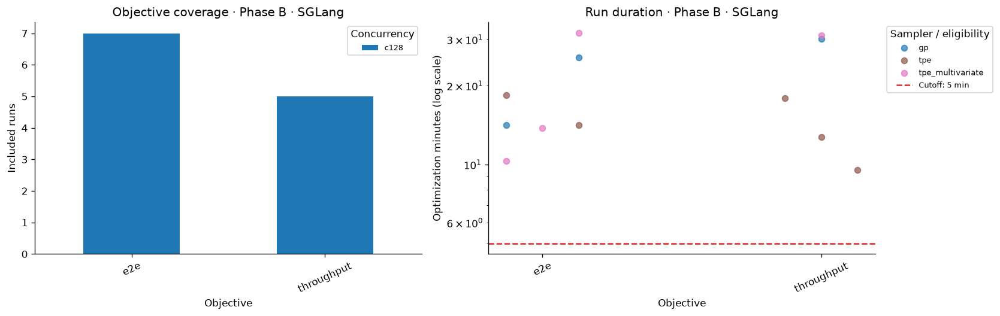

,state,trials
0,COMPLETE,130
1,FAIL,205
2,PRUNED,4
3,RUNNING,1


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase B · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe-s11-r2-pruner-nop`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-e2e-gp-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / 7gwhbppv],sglang-phase-b-pruning-qwen3_4_dspark,7gwhbppv,e2e,C18,gp,14.16,attention_backend: fa3chunked_prefill_size: 7680cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 40mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,19,2533.186440,False,all W&B COMPLETE trials
B-sglang-c128-e2e-gp-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / rw82qovo],sglang-phase-b-pruning-qwen3_4_dspark,rw82qovo,e2e,C19,gp,25.65,attention_backend: fa3chunked_prefill_size: 7680cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 40mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,19,2533.186440,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / 0bxo3s5e],sglang-phase-b-pruning-qwen3_4_dspark,0bxo3s5e,e2e,C19,tpe,18.39,attention_backend: fa3chunked_prefill_size: 7680cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 40mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,19,2530.049113,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / sigvljt9],sglang-phase-b-pruning-qwen3_4_dspark,sigvljt9,e2e,C18,tpe,14.15,attention_backend: fa3chunked_prefill_size: 7680cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 40mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,19,2530.049113,False,all W&B COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / 9zbj7gvx],sglang-phase-b-pruning-qwen3_4_dspark,9zbj7gvx,e2e,C18,tpe_multivariate,10.32,attention_backend: fa3chunked_prefill_size: 12032cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 24mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: fcfs,22,2625.152551,False,all W&B COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / irqobxfb],sglang-phase-b-pruning-qwen3_4_dspark,irqobxfb,e2e,C18,tpe_multivariate,13.78,attention_backend: fa3chunked_prefill_size: 7680cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 40mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: fcfs,19,2518.756866,False,all W&B COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r2-pruner-nop [sglang-phase-b-pruning-qwen3_4_dspark / tipvad6g],sglang-phase-b-pruning-qwen3_4_dspark,tipvad6g,e2e,C19,tpe_multivariate,31.82,attention_backend: fa3chunked_prefill_size: 11776cuda_graph_backend_decode: fullcuda_graph_backend_prefill: breakabledisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 64mem_fraction_static: 0.85schedule_conservativeness: 0.75schedule_policy: fcfs,37,2440.756470,False,all local COMPLETE trials


##### Matching context C18

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

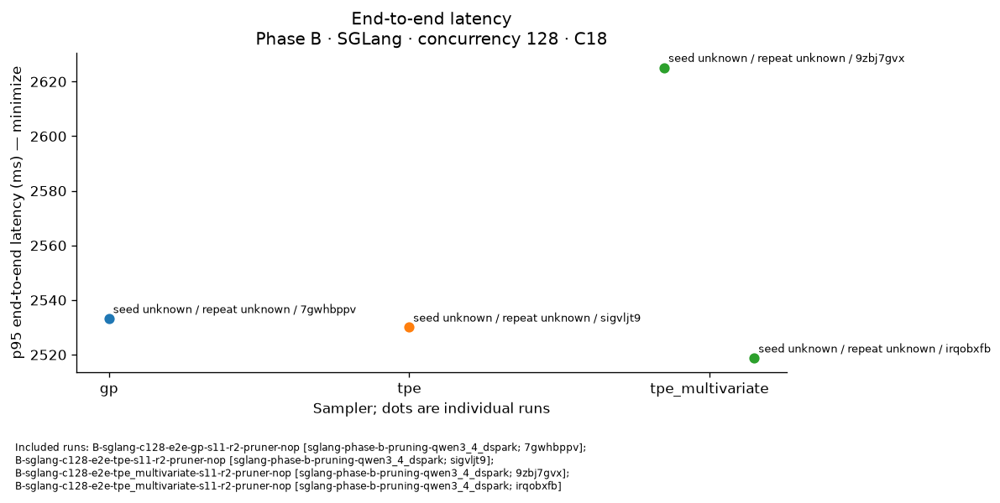

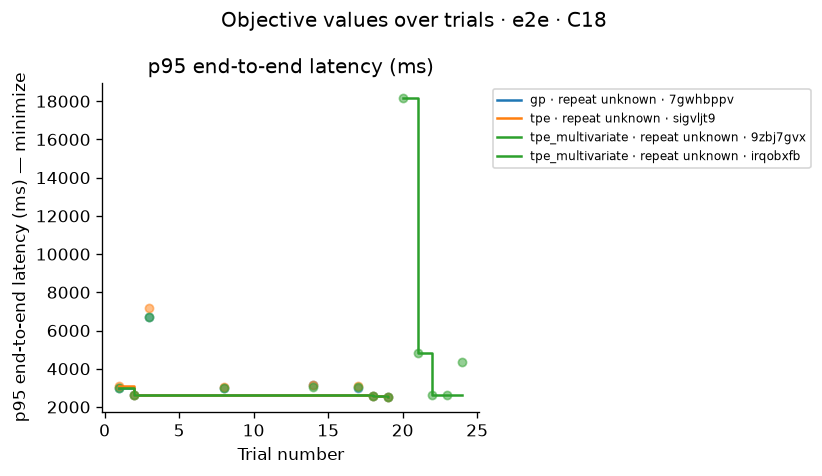

##### Matching context C19

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

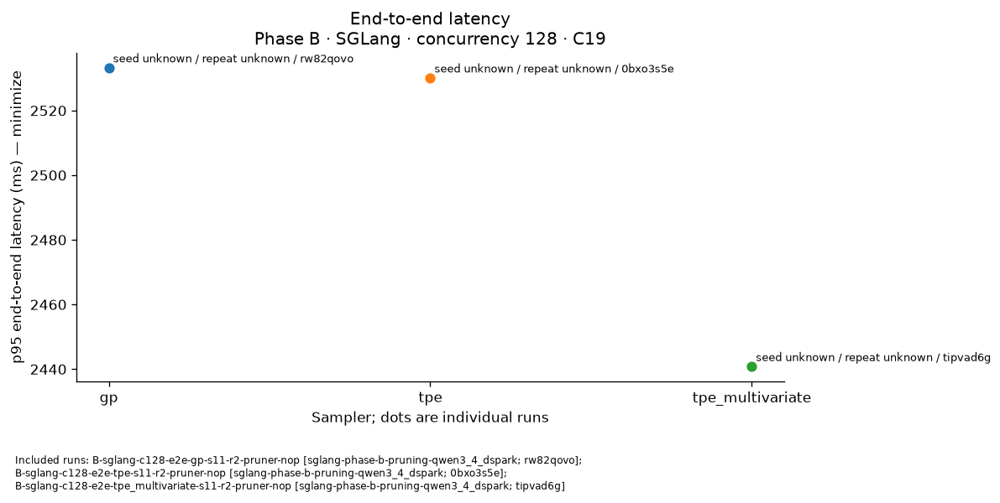

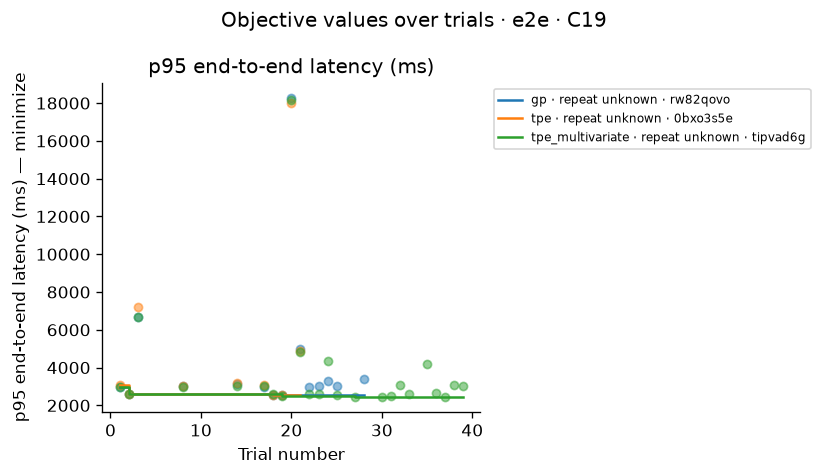

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 5.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-gp-s11-r3-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-sglang-c128-throughput-tpe-s11-r2-pruner-nop`
- `B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-sglang-c128-throughput-gp-s11-r3-pruner-nop,sglang-phase-b-pruning-qwen3_4_dspark,1mj5pu8e,throughput,C06,gp,30.10,attention_backend: fa3chunked_prefill_size: 32768cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.85schedule_conservativeness: 0.5schedule_policy: lpm,32,9833.914410,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-qwen3_4_dspark,9szzefj2,throughput,C06,tpe,17.93,attention_backend: fa3chunked_prefill_size: 28416cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: lpm,1,9662.491488,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r1-pruner-nop,sglang-phase-b-pruning-qwen3_4_dspark,4247uz4a,throughput,C06,tpe,12.72,attention_backend: fa3chunked_prefill_size: 28416cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: lpm,1,9654.487001,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r2-pruner-nop,sglang-phase-b-pruning-qwen3_4_dspark,qbvsfvi0,throughput,C06,tpe,9.52,attention_backend: fa3chunked_prefill_size: 28416cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: lpm,1,9536.540530,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe_multivariate-s11-r1-pruner-median,sglang-phase-b-pruning-qwen3_4_dspark,qgp2mzet,throughput,C06,tpe_multivariate,31.05,attention_backend: fa3chunked_prefill_size: 19456cuda_graph_backend_decode: fullcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 112mem_fraction_static: 0.7schedule_conservativeness: 1.0schedule_policy: lpm,36,9733.360391,False,all local COMPLETE trials


##### Matching context C06

**Matched workload and environment**

**model:** `"qwen3-4b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"1cfa9a7208912126459214e8b04321603b3df60c"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

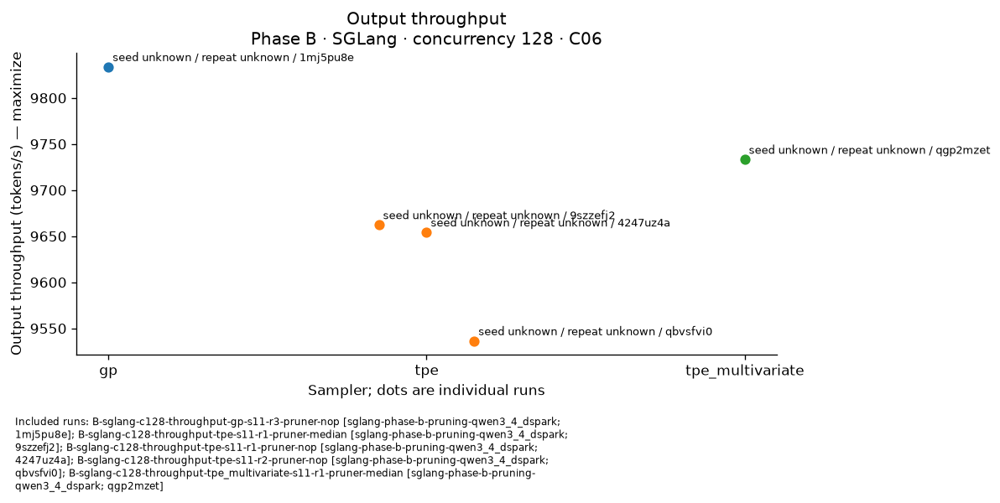

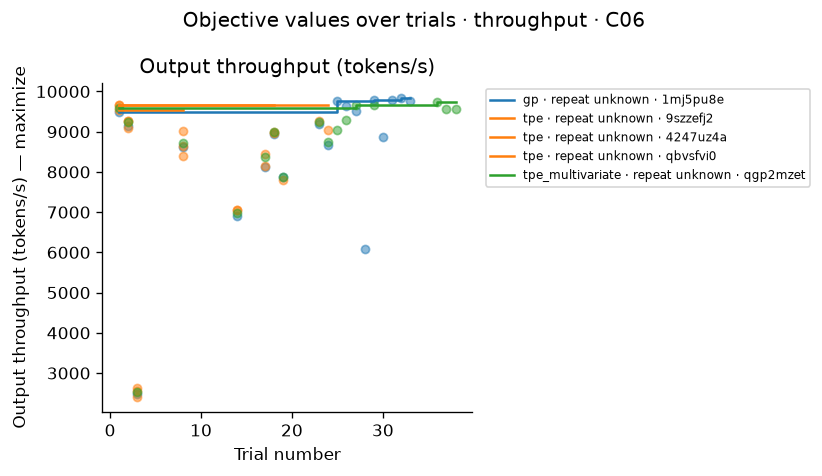

In [44]:
show_model("qwen3-4b dspark")


## qwen3-8b


### Summary of the results:

In [45]:
show_framework_summary("qwen3-8b")


### Framework summaries · qwen3-8b

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C14,B,128,B-vllm-c128-throughput-tpe-s11-r2-pruner-median,stnpzd6x,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/stnpzd6x,18,5835.361267903753,—,"async_scheduling: trueattention_backend: ""FLASH_ATTN""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 27904max_num_seqs: 128performance_mode: ""throughput""",all local COMPLETE trials
e2e,C27,B,128,B-vllm-c128-e2e-gp-s11-r2-pruner-median,2mbw0j1m,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/2mbw0j1m,16,—,2706.6403231011464,"async_scheduling: trueattention_backend: ""FLASHINFER""enable_prefix_caching: falsegpu_memory_utilization: 0.75graph_capture_profile: ""powers""graph_mode: ""PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: ""interactivity""",all local COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (4 outputs left out)

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


#### For SGLang

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


### Per-Trial behavior:

### qwen3-8b · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,3860.157361,3827.070939,3,3
1,B,128,throughput,1,4411.169650,563.313793,3,3
2,B,128,throughput,2,4581.395251,18418.864036,3,3
3,B,128,throughput,3,4151.243197,56.074121,3,3
4,B,128,throughput,4,3362.734247,3231.736957,3,3
5,B,128,throughput,5,5217.042408,13.574484,3,3
6,B,128,throughput,6,3792.204772,12391.189986,3,3
7,B,128,throughput,7,1919.509982,18701.186712,3,3
8,B,128,throughput,8,5223.299343,548.255075,3,3
9,B,128,throughput,9,4927.997691,40064.233211,3,3


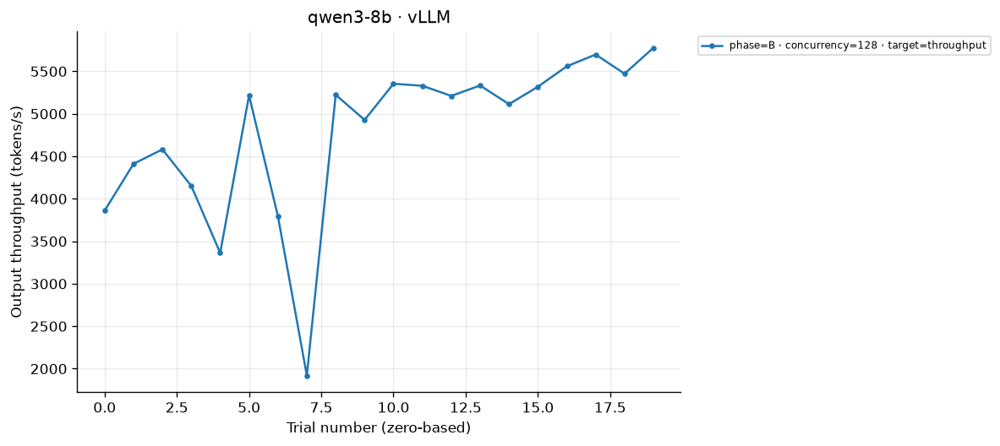

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,4818.269421,9174.610035,3,3
1,B,128,e2e,1,4336.510767,3419.973635,3,3
2,B,128,e2e,2,3739.544078,14123.498648,3,3
3,B,128,e2e,3,5112.725426,60.469253,3,3
4,B,128,e2e,4,5436.664428,406.401755,3,3
5,B,128,e2e,5,4394.032071,808.386811,3,3
6,B,128,e2e,6,6039.733807,88648.803375,3,3
7,B,128,e2e,7,9843.093459,438042.264643,3,3
8,B,128,e2e,8,4981.089506,8032.708282,3,3
9,B,128,e2e,9,4907.584204,80573.522006,3,3


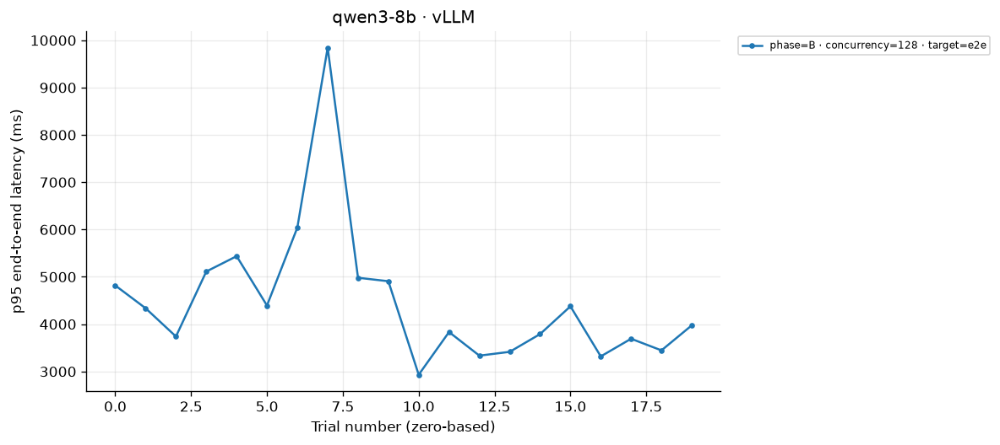

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [46]:
mean_by_trial_number("qwen3-8b", "vllm")


In [47]:
mean_by_trial_number("qwen3-8b", "sglang")


### qwen3-8b · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [48]:
mean_by_trial_number("qwen3-8b", "trtllm")


### qwen3-8b · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


### Overall results and plots:

**6 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3-8b,B-vllm-c128-e2e-gp-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-e2e-gp-s11-r2-pruner-median,31.05281341943331,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,2mbw0j1m,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/2mbw0j1m,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-gp-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b,B-vllm-c128-e2e-tpe-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-e2e-tpe-s11-r2-pruner-median,35.37260346571666,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,sftkptpd,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/sftkptpd,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-tpe-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b,B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,27.67742699608334,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,ia99u5tv,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ia99u5tv,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b,B-vllm-c128-throughput-gp-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-throughput-gp-s11-r2-pruner-median,29.417260042433334,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,ilv0o9ub,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ilv0o9ub,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-gp-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b,B-vllm-c128-throughput-tpe-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-throughput-tpe-s11-r2-pruner-median,32.20467118573333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,stnpzd6x,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/stnpzd6x,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-tpe-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b,B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median-q3_8,B,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,29.686356108833333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,q5se5hh2,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/q5se5hh2,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median-B-vllm-c128-measured.jsonl']


### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
39,qwen3-8b,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,55,3,4604.408192,2.338627e+06,phase/concurrency
40,qwen3-8b,B,throughput,128,full trial history,output_throughput,vllm,57,3,4736.917363,9.374967e+05,phase/concurrency
70,qwen3-8b,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,55,3,4604.408192,2.338627e+06,phase/concurrency
71,qwen3-8b,B,throughput,128,full trial history,output_throughput,overall,57,3,4736.917363,9.374967e+05,phase/concurrency
109,qwen3-8b,all,e2e,all,full trial history,p95_e2e_latency_ms,vllm,55,3,4604.408192,2.338627e+06,model
110,qwen3-8b,all,throughput,all,full trial history,output_throughput,vllm,57,3,4736.917363,9.374967e+05,model
133,qwen3-8b,all,e2e,all,full trial history,p95_e2e_latency_ms,overall,55,3,4604.408192,2.338627e+06,model
134,qwen3-8b,all,throughput,all,full trial history,output_throughput,overall,57,3,4736.917363,9.374967e+05,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

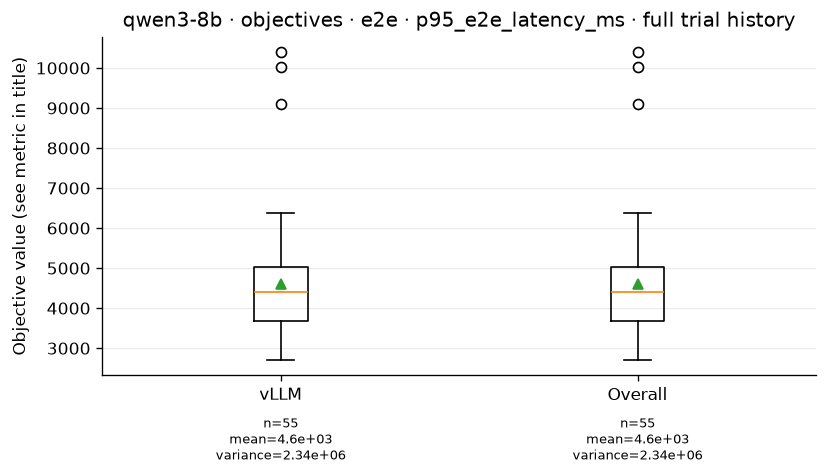

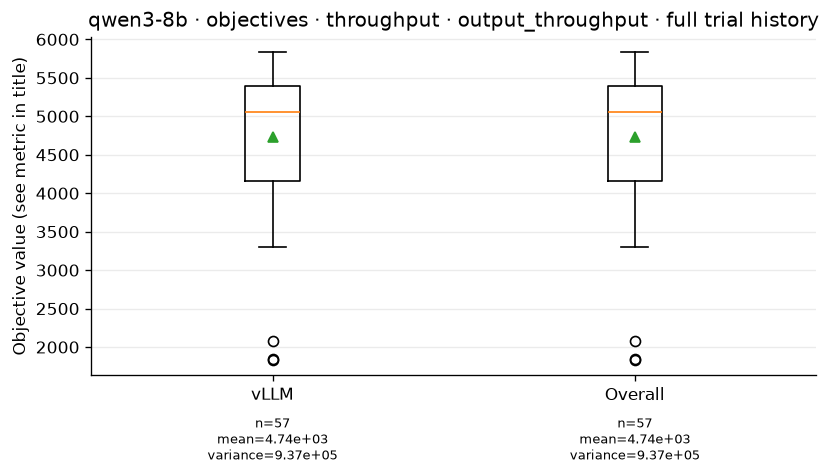

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3-8b,vllm,B-vllm-c128-e2e-gp-s11-r2-pruner-median-q3_8,2mbw0j1m,0,included
qwen3-8b,vllm,B-vllm-c128-e2e-tpe-s11-r2-pruner-median-q3_8,sftkptpd,0,included
qwen3-8b,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median-q3_8,ia99u5tv,0,included
qwen3-8b,vllm,B-vllm-c128-throughput-gp-s11-r2-pruner-median-q3_8,ilv0o9ub,0,included
qwen3-8b,vllm,B-vllm-c128-throughput-tpe-s11-r2-pruner-median-q3_8,stnpzd6x,0,included
qwen3-8b,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median-q3_8,q5se5hh2,0,included
qwen3-8b,vllm,suggested-vllm-Qwen--Qwen3-8B-87d6b05a-c128,87b4oar1,0,under five minutes


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

No recorded startup telemetry available for this model.


### vLLM · qwen3-8b

... (2 outputs left out)

,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.072186,1.461340e-02
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.007523,1.257405e-05
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.000298,1.102598e-07
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.103960,1.073278e-02
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.058137,9.342814e-03
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.049977,6.531995e-03
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.317954,2.348970e-01
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.329225,9.382200e-02
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.060739,6.197979e-03
9,throughput,output_throughput,async_scheduling,3,0.024910,1.476057e-03


model_group,framework,run,wandb_id,status


Phase B / vLLM: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

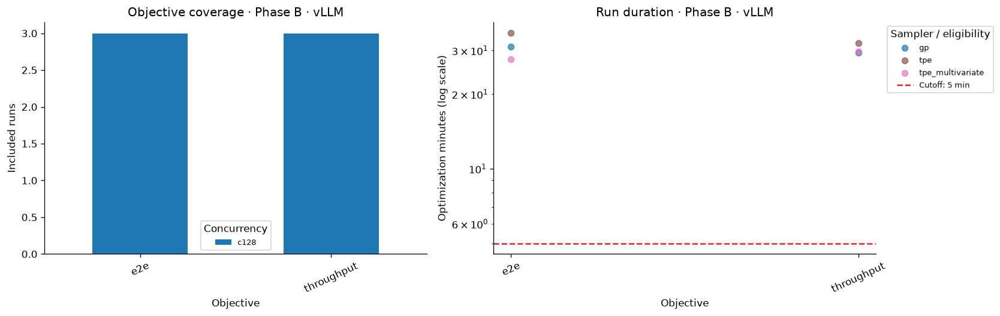

,state,trials
0,COMPLETE,112
1,PRUNED,8


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r2-pruner-median,vllm-phase-b-pruning-20261018-v2,2mbw0j1m,e2e,C27,gp,31.05,async_scheduling: Trueattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 32768max_num_seqs: 128performance_mode: interactivity,16,2706.640323,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r2-pruner-median,vllm-phase-b-pruning-20261018-v2,sftkptpd,e2e,C27,tpe,35.37,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Truegpu_memory_utilization: 0.85graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 12288max_num_seqs: 128performance_mode: throughput,18,3159.273488,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,vllm-phase-b-pruning-20261018-v2,ia99u5tv,e2e,C27,tpe_multivariate,27.68,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_mode: NONEkv_cache_dtype: fp8max_num_batched_tokens: 32512max_num_seqs: 128performance_mode: interactivity,2,3607.674148,False,all local COMPLETE trials


##### Matching context C27

**Matched workload and environment**

**model:** `"qwen3-8b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"b968826d9c46dd6066d109eabc6255188de91218"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

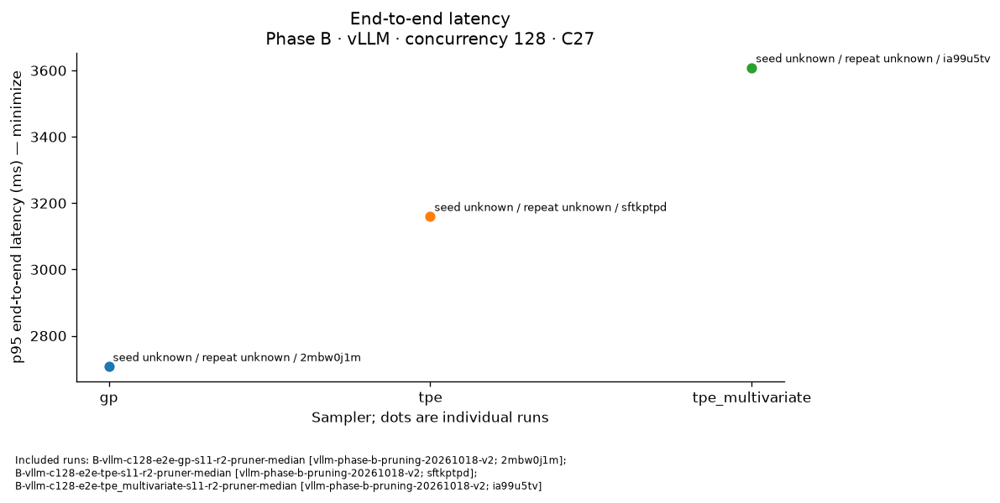

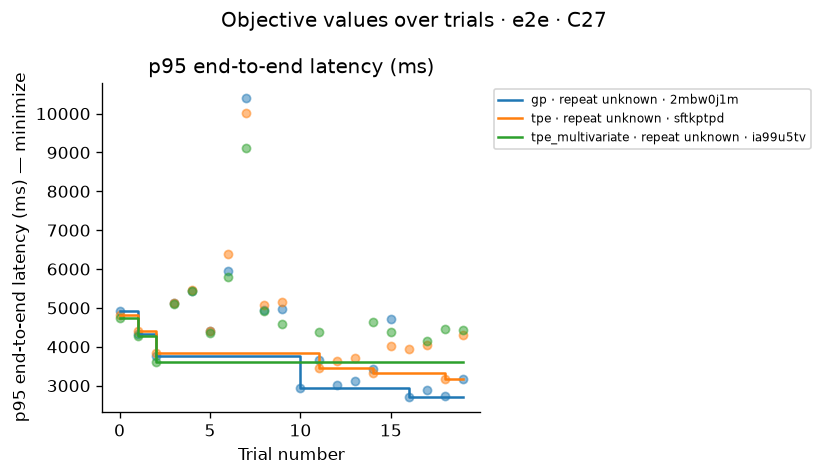

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r2-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r2-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,ilv0o9ub,throughput,C14,gp,29.42,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1024max_num_seqs: 128performance_mode: interactivity,16,5805.673790,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r2-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,stnpzd6x,throughput,C14,tpe,32.20,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 27904max_num_seqs: 128performance_mode: throughput,18,5835.361268,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r2-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,q5se5hh2,throughput,C14,tpe_multivariate,29.69,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 18944max_num_seqs: 120performance_mode: throughput,14,5394.087489,False,all local COMPLETE trials


##### Matching context C14

**Matched workload and environment**

**model:** `"qwen3-8b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"b968826d9c46dd6066d109eabc6255188de91218"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

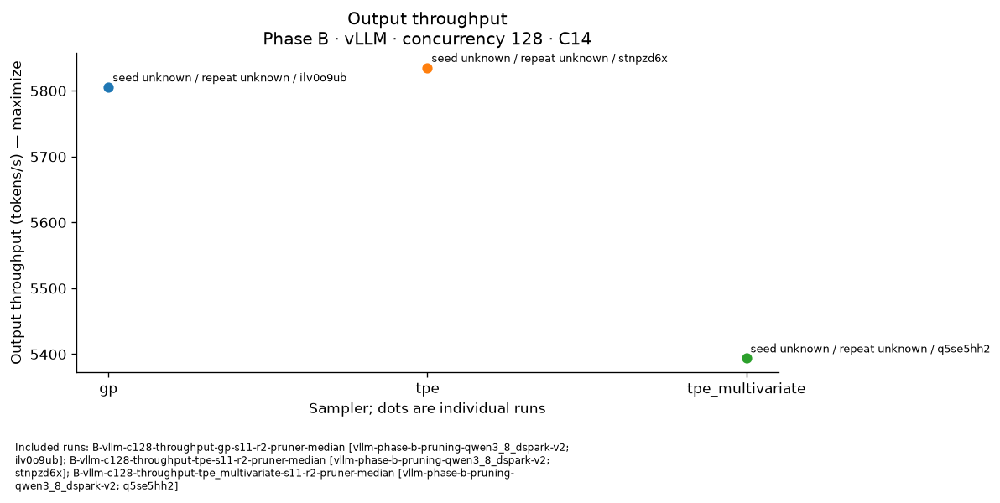

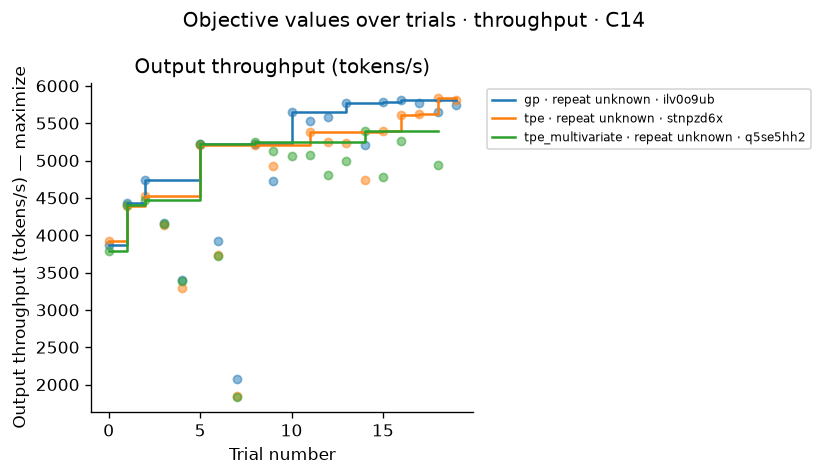

### TRT-LLM · qwen3-8b

No eligible runs available.


### SGLang · qwen3-8b

No eligible runs available.


In [49]:
show_model("qwen3-8b")


## qwen3-8b dspark


### Summary of the results:

In [50]:
show_framework_summary("qwen3-8b dspark")


### Framework summaries · qwen3-8b dspark

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C13,B,128,B-vllm-c128-throughput-gp-s11-r1-pruner-median,vsx757h1,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/vsx757h1,8,6296.831605255992,—,"async_scheduling: falseattention_backend: ""FLASHINFER""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""dense""graph_mode: ""PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 31488max_num_seqs: 120performance_mode: ""interactivity""",all local COMPLETE trials
e2e,C26,B,128,B-vllm-c128-e2e-tpe-s11-r1-pruner-median,fnj6k5mz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/fnj6k5mz,13,—,3207.7085647499644,"async_scheduling: falseattention_backend: ""auto""enable_prefix_caching: falsegpu_memory_utilization: 0.85graph_mode: ""NONE""kv_cache_dtype: ""auto""max_num_batched_tokens: 8704max_num_seqs: 32performance_mode: ""balanced""",all local COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (4 outputs left out)

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


#### For SGLang

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


### Per-Trial behavior:

### qwen3-8b dspark · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,5964.171202,1845.330039,3,3
1,B,128,throughput,1,6067.642966,6387.416491,3,3
2,B,128,throughput,2,6040.490719,330.262336,3,3
3,B,128,throughput,3,6042.428708,65.987532,3,3
4,B,128,throughput,4,6115.527838,60.207795,3,3
5,B,128,throughput,5,6213.918557,818.438362,3,3
6,B,128,throughput,6,5961.539541,6975.618925,3,3
7,B,128,throughput,7,5381.663856,8378.616102,3,3
8,B,128,throughput,8,6269.081761,627.423921,3,3
9,B,128,throughput,9,6203.415360,186.007472,3,3


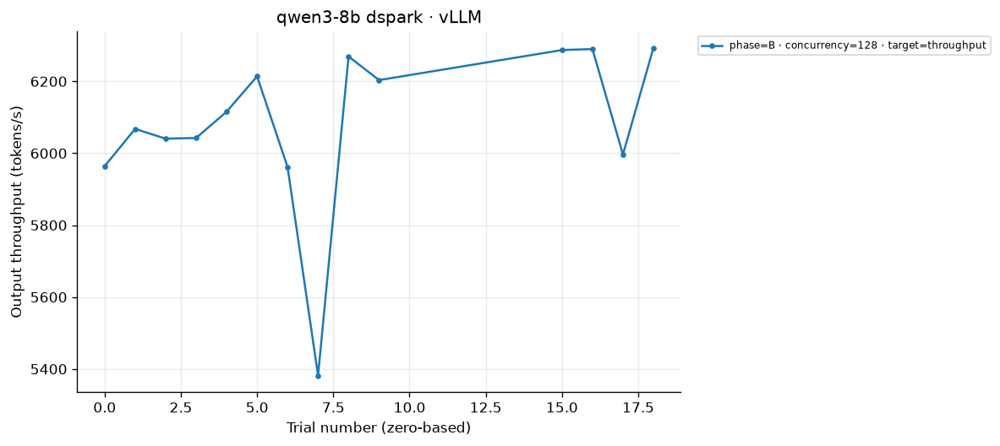

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,3851.852076,606.584221,3,3
1,B,128,e2e,1,3307.993879,3144.501283,3,3
2,B,128,e2e,2,4496.447546,310.768443,3,3
3,B,128,e2e,3,3550.758500,957.323107,3,3
4,B,128,e2e,4,3415.709511,3425.725566,3,3
5,B,128,e2e,5,4217.208002,103.058512,3,3
6,B,128,e2e,6,4005.521992,378.602472,3,3
7,B,128,e2e,7,3315.404498,4723.032622,3,3
8,B,128,e2e,8,4664.041118,49.230704,3,3
9,B,128,e2e,9,4544.033664,10.169209,3,3


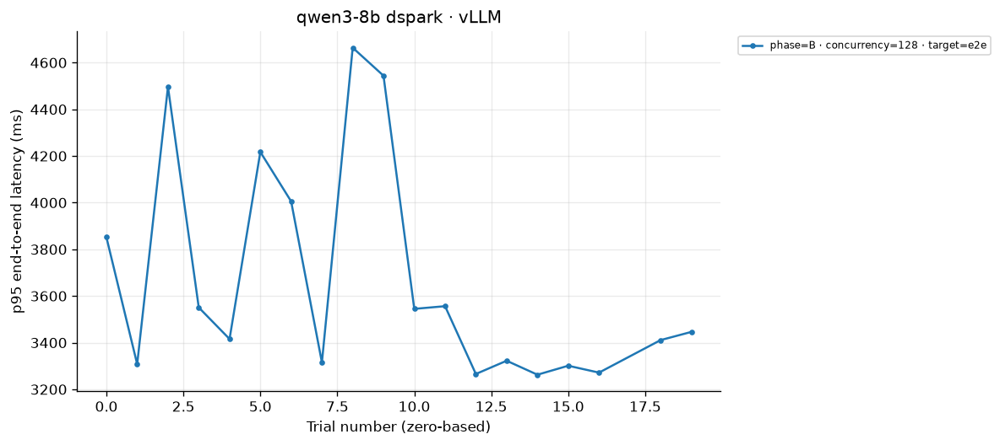

#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [51]:
mean_by_trial_number("qwen3-8b dspark", "vllm")


In [52]:
mean_by_trial_number("qwen3-8b dspark", "sglang")


### qwen3-8b dspark · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [53]:
mean_by_trial_number("qwen3-8b dspark", "trtllm")


### qwen3-8b dspark · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


### Overall results and plots:

**6 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3-8b dspark,B-vllm-c128-e2e-gp-s11-r1-pruner-mediann-dsparkq3_8,B,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-median,26.481984724816677,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,p5jwlguz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/p5jwlguz,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-gp-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b dspark,B-vllm-c128-e2e-tpe-s11-r1-pruner-median-dsparkq3_8,B,vllm,B-vllm-c128-e2e-tpe-s11-r1-pruner-median,41.037132280916666,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,fnj6k5mz,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/fnj6k5mz,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-tpe-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b dspark,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-mediann-dsparkq3_8,B,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,29.154415159400006,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-20261018-v2/studies.sqlite3,emkxo0vq,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/emkxo0vq,finished,vllm-phase-b-pruning-20261018-v2,['experiment_results/vllm-phase-b-pruning-20261018-v2/B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b dspark,B-vllm-c128-throughput-gp-s11-r1-pruner-median-dsparkq3_8,B,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-median,21.086312411233333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,vsx757h1,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/vsx757h1,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-gp-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b dspark,B-vllm-c128-throughput-tpe-s11-r1-pruner-mediann-dsparkq3_8,B,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-median,28.948683231716664,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,ki1p9e0e,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ki1p9e0e,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-tpe-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
qwen3-8b dspark,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-mediann-dsparkq3_8,B,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,30.131966800300003,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/studies.sqlite3,9q7np7nj,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/9q7np7nj,finished,vllm-phase-b-pruning-qwen3_8_dspark-v2,['experiment_results/vllm-phase-b-pruning-qwen3_8_dspark-v2/B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']


### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
41,qwen3-8b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,44,3,3754.468063,255055.166890,phase/concurrency
42,qwen3-8b dspark,B,throughput,128,full trial history,output_throughput,vllm,35,3,6046.930542,56635.339103,phase/concurrency
72,qwen3-8b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,44,3,3754.468063,255055.166890,phase/concurrency
73,qwen3-8b dspark,B,throughput,128,full trial history,output_throughput,overall,35,3,6046.930542,56635.339103,phase/concurrency
111,qwen3-8b dspark,all,e2e,all,full trial history,p95_e2e_latency_ms,vllm,44,3,3754.468063,255055.166890,model
112,qwen3-8b dspark,all,throughput,all,full trial history,output_throughput,vllm,35,3,6046.930542,56635.339103,model
135,qwen3-8b dspark,all,e2e,all,full trial history,p95_e2e_latency_ms,overall,44,3,3754.468063,255055.166890,model
136,qwen3-8b dspark,all,throughput,all,full trial history,output_throughput,overall,35,3,6046.930542,56635.339103,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

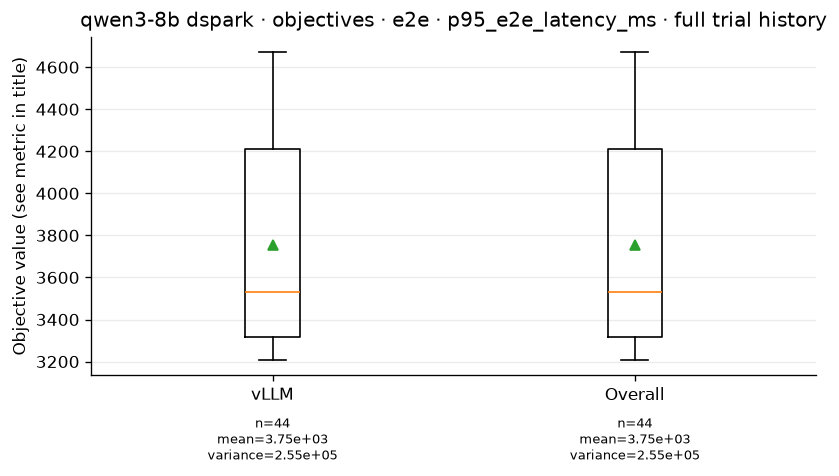

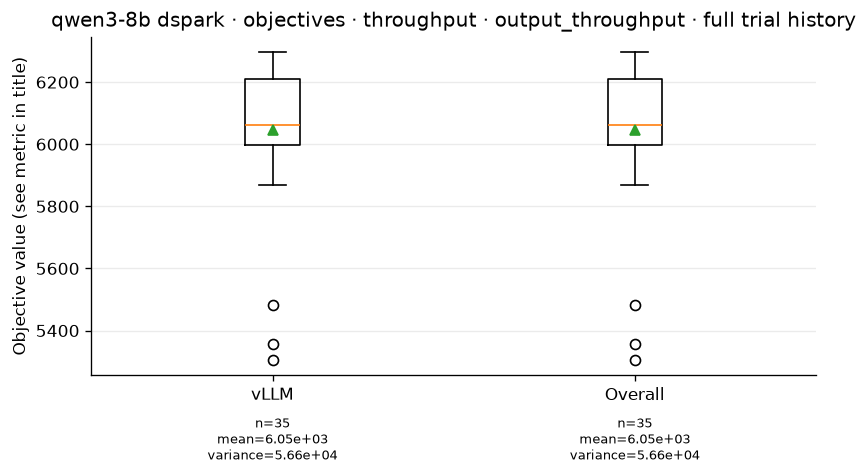

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3-8b dspark,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-mediann-dsparkq3_8,p5jwlguz,0,included
qwen3-8b dspark,vllm,B-vllm-c128-e2e-tpe-s11-r1-pruner-median-dsparkq3_8,fnj6k5mz,0,included
qwen3-8b dspark,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-mediann-dsparkq3_8,emkxo0vq,0,included
qwen3-8b dspark,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-median-dsparkq3_8,vsx757h1,0,included
qwen3-8b dspark,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-mediann-dsparkq3_8,ki1p9e0e,0,included
qwen3-8b dspark,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-mediann-dsparkq3_8,9q7np7nj,0,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

No recorded startup telemetry available for this model.


### vLLM · qwen3-8b dspark

... (2 outputs left out)

,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.001947,5.844507e-07
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.005043,2.854551e-05
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.001762,3.381791e-06
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.017782,5.067808e-04
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.004169,1.492043e-06
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.001247,3.049184e-07
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.759146,4.118247e-02
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.205802,4.634391e-02
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.003101,2.145578e-05
9,throughput,output_throughput,async_scheduling,3,0.007063,1.116420e-05


model_group,framework,run,wandb_id,status


Phase B / vLLM: 6 included runs; cutoff 5 minutes


**Runs included: 6.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

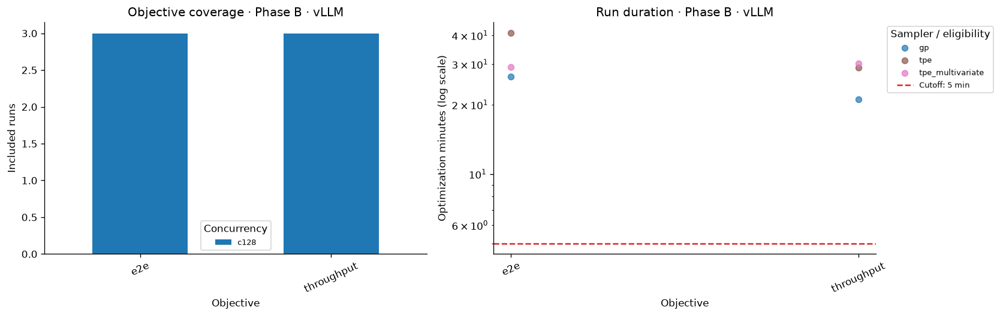

,state,trials
0,COMPLETE,79
1,PRUNED,41


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r1-pruner-median,vllm-phase-b-pruning-20261018-v2,p5jwlguz,e2e,C26,gp,26.48,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1024max_num_seqs: 80performance_mode: interactivity,16,3271.584945,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r1-pruner-median,vllm-phase-b-pruning-20261018-v2,fnj6k5mz,e2e,C26,tpe,41.04,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_mode: NONEkv_cache_dtype: automax_num_batched_tokens: 8704max_num_seqs: 32performance_mode: balanced,13,3207.708565,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,vllm-phase-b-pruning-20261018-v2,emkxo0vq,e2e,C26,tpe_multivariate,29.15,async_scheduling: Falseattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 1280max_num_seqs: 104performance_mode: interactivity,14,3255.330352,False,all local COMPLETE trials


##### Matching context C26

**Matched workload and environment**

**model:** `"qwen3-8b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"b968826d9c46dd6066d109eabc6255188de91218"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

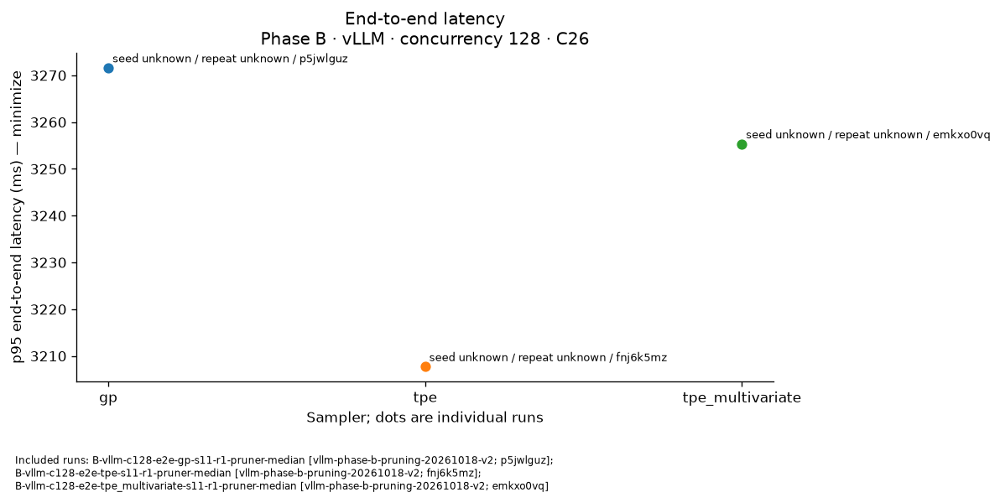

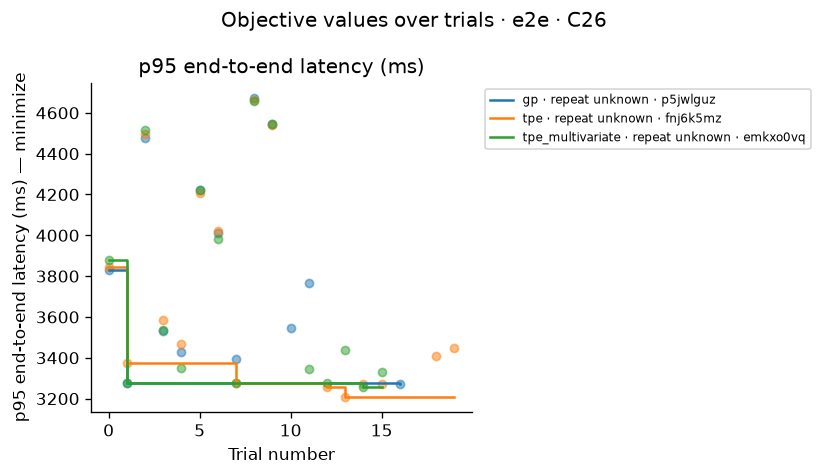

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,vsx757h1,throughput,C13,gp,21.09,async_scheduling: Falseattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 31488max_num_seqs: 120performance_mode: interactivity,8,6296.831605,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,ki1p9e0e,throughput,C13,tpe,28.95,async_scheduling: Falseattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 31488max_num_seqs: 120performance_mode: interactivity,8,6262.269664,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,vllm-phase-b-pruning-qwen3_8_dspark-v2,9q7np7nj,throughput,C13,tpe_multivariate,30.13,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 31488max_num_seqs: 96performance_mode: interactivity,18,6293.218522,False,all local COMPLETE trials


##### Matching context C13

**Matched workload and environment**

**model:** `"qwen3-8b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"b968826d9c46dd6066d109eabc6255188de91218"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

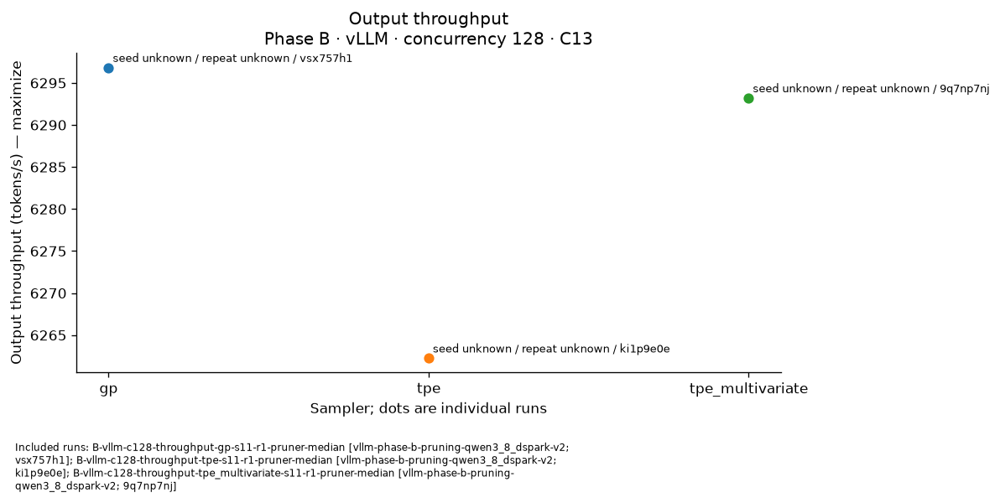

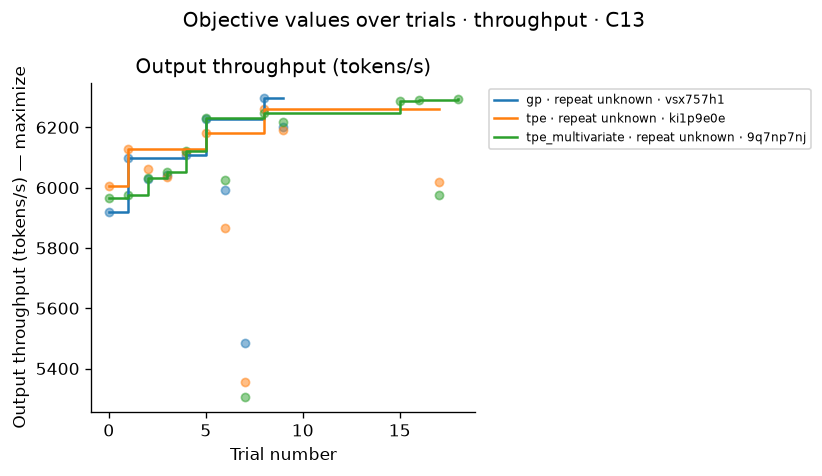

### TRT-LLM · qwen3-8b dspark

No eligible runs available.


### SGLang · qwen3-8b dspark

No eligible runs available.


In [54]:
show_model("qwen3-8b dspark")


## gemma4-12b


### Summary of the results:

In [55]:
show_framework_summary("gemma4-12b")


### Framework summaries · gemma4-12b

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C10,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-nop,fcwye0pn,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/fcwye0pn,16,3233.4243199419134,—,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: truegpu_memory_utilization: 0.9graph_capture_profile: ""powers""graph_mode: ""PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 32256max_num_seqs: 128performance_mode: ""balanced""",all local COMPLETE trials
e2e,C23,B,128,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,35sb89tl,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/35sb89tl,18,—,5506.465549749919,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: falsegpu_memory_utilization: 0.75graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 15104max_num_seqs: 128performance_mode: ""balanced""",all local COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (13 outputs left out)

**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

,target,metric,coverage,n,runs,mean,variance
0,e2e,p95_e2e_latency_ms,full trial history,62,7,41214.365364,2.888867e+09
1,throughput,output_throughput,full trial history,46,3,1438.069177,6.066087e+05


**Startup, model loading and serving timings** (seconds; variance in seconds²)

,timing,phase_status,n,mean_seconds,variance_seconds2
0,benchmark,complete,109,184.010947,32073.076829
1,client_preparation,complete,110,4.055312,0.088610
2,compilation,log observation,8,1.082500,0.002679
3,launch_to_ready,complete,110,40.083471,43.363905
4,warmup,complete,110,1.112611,0.009693


### Per-Trial behavior:

### gemma4-12b · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,2345.901775,104.626678,2,2
1,B,128,throughput,1,2685.794475,234.368124,2,2
2,B,128,throughput,2,1075.849111,443.933803,2,2
3,B,128,throughput,3,635.021212,10.094587,2,2
4,B,128,throughput,4,2403.409190,10.123320,2,2
5,B,128,throughput,5,2867.676631,26.177354,2,2
6,B,128,throughput,6,1819.571118,5779.638554,2,2
7,B,128,throughput,7,2044.571111,80.807698,2,2
8,B,128,throughput,8,2397.413383,9186.454644,2,2
9,B,128,throughput,9,2583.117666,7.459889,2,2


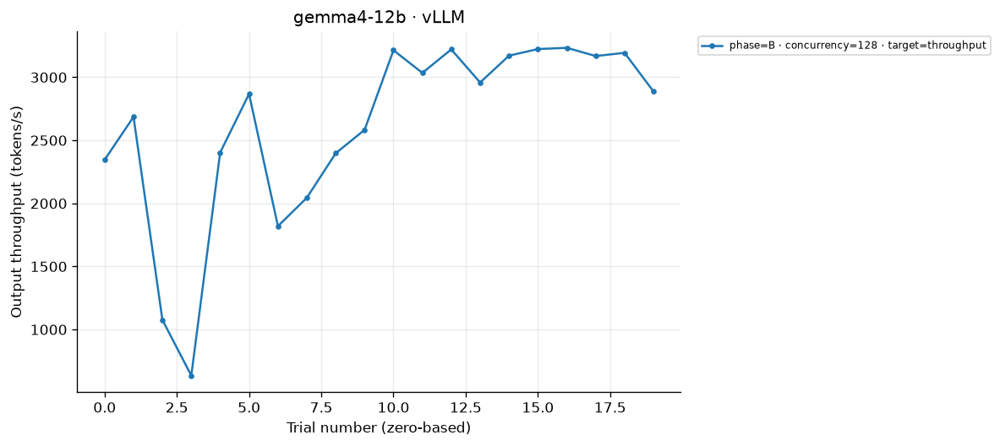

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,7735.309411,1.080205e+02,2,2
1,B,128,e2e,1,9827.357692,1.334553e+04,2,2
2,B,128,e2e,2,16380.341949,3.646428e+05,2,2
3,B,128,e2e,3,25304.609916,2.843546e+04,2,2
4,B,128,e2e,4,8850.095801,7.952940e+02,2,2
5,B,128,e2e,5,7597.016253,1.208334e+02,2,2
6,B,128,e2e,6,11484.578906,1.245331e+05,2,2
7,B,128,e2e,7,8911.332914,1.133196e+03,2,2
8,B,128,e2e,8,8711.763358,2.969565e+04,2,2
9,B,128,e2e,9,6357.259913,6.466725e+00,2,2


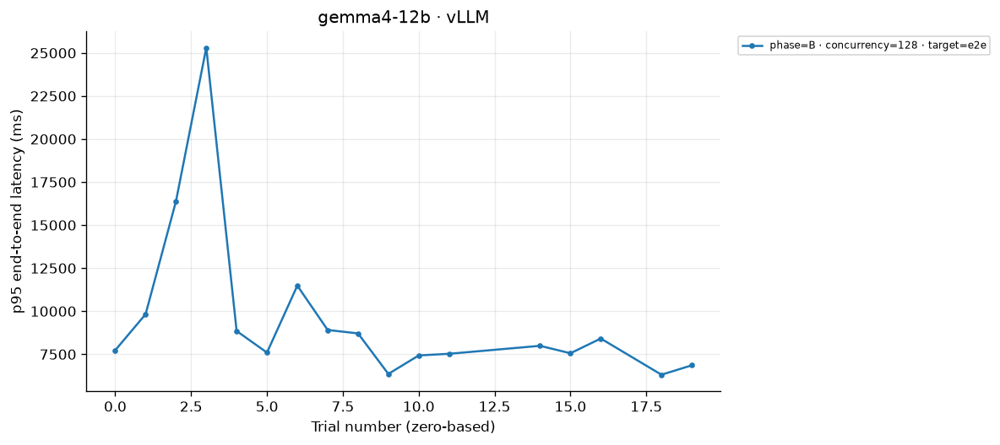

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,160.042593,6.052765e+03,2,2
1,B,128,e2e,1,130.035671,8.004613e+02,2,2
2,B,128,e2e,2,137.536990,1.513153e+03,2,2
3,B,128,e2e,3,135.037367,1.250478e+03,2,2
4,B,128,e2e,4,137.535617,1.013028e+03,2,2
5,B,128,e2e,5,142.535965,1.012907e+03,2,2
6,B,128,e2e,6,127.532346,1.012800e+03,2,2
7,B,128,e2e,7,145.039198,1.250331e+03,2,2
8,B,128,e2e,8,125.032599,1.250515e+03,2,2
9,B,128,e2e,9,150.038872,8.003751e+02,2,2


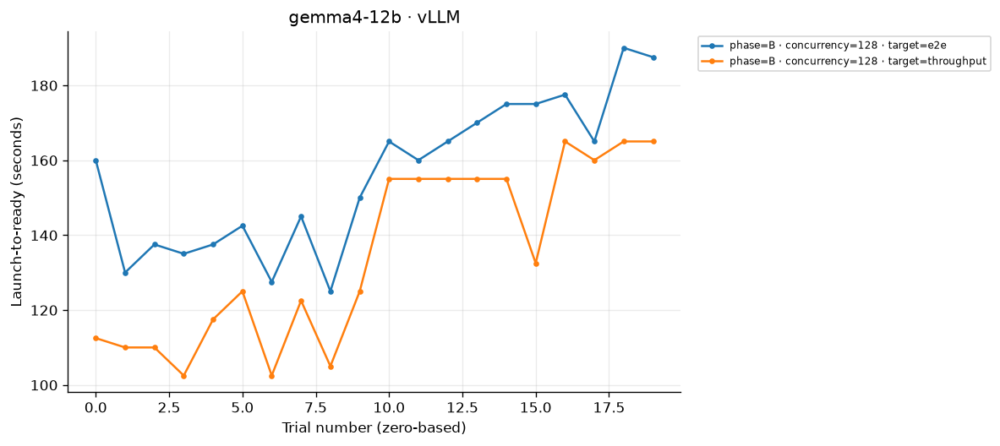

In [56]:
mean_by_trial_number("gemma4-12b", "vllm")


### gemma4-12b · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,1599.689728,0.000000,3,3
1,B,128,throughput,1,232.716248,0.000000,3,3
2,B,128,throughput,2,1633.746431,0.000000,3,3
3,B,128,throughput,3,452.752146,0.000000,3,3
4,B,128,throughput,4,1723.054203,0.000000,3,3
5,B,128,throughput,5,440.557552,0.000000,3,3
6,B,128,throughput,6,1163.472080,0.000000,3,3
7,B,128,throughput,8,2315.668803,0.000000,3,3
8,B,128,throughput,9,232.866405,0.000000,3,3
9,B,128,throughput,10,646.277665,1457.424770,2,2


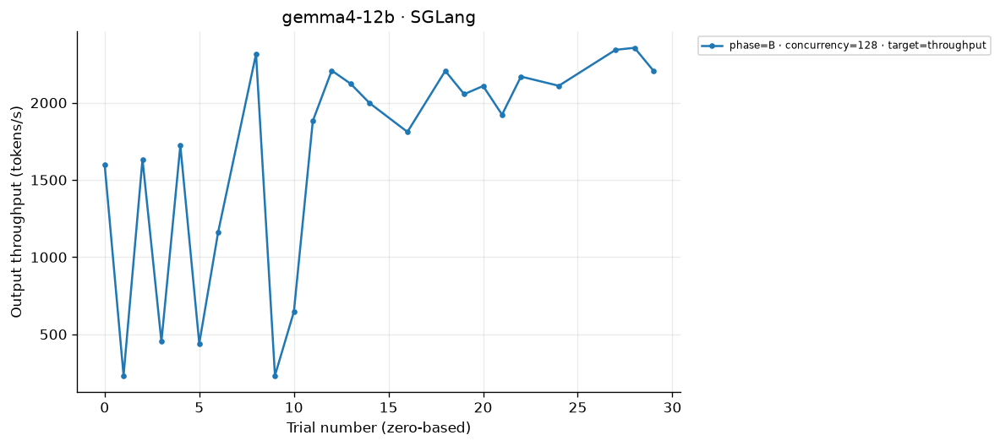

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,19303.320142,5.427600e+04,5,5
1,B,128,e2e,1,212242.868891,5.895893e+03,5,5
2,B,128,e2e,2,20235.492621,1.053689e+06,6,6
3,B,128,e2e,3,40476.851661,0.000000e+00,4,4
4,B,128,e2e,4,19376.025034,0.000000e+00,4,4
5,B,128,e2e,5,40446.193644,0.000000e+00,4,4
6,B,128,e2e,6,30790.975950,5.769584e+07,5,5
7,B,128,e2e,8,7935.125327,0.000000e+00,4,4
8,B,128,e2e,9,78168.591926,0.000000e+00,4,4
9,B,128,e2e,10,31546.258512,8.003830e+05,3,3


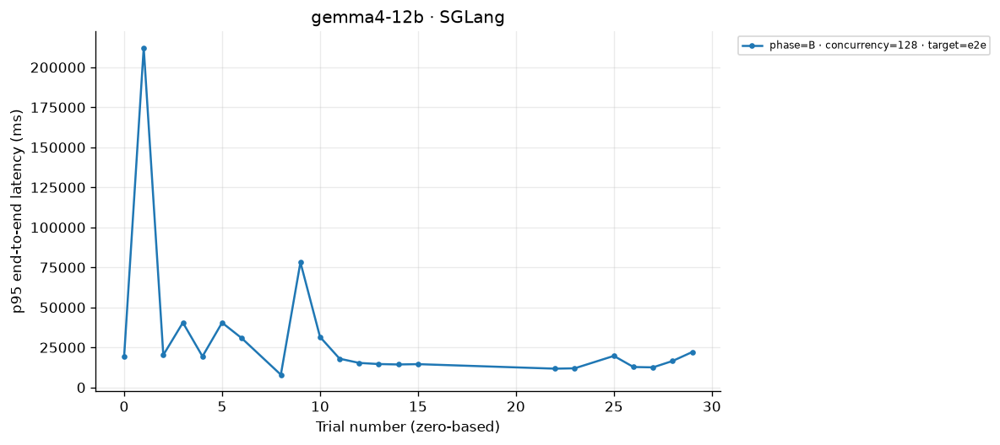

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,41.016324,1.702613e-06,5,5
1,B,128,e2e,1,41.049498,5.592986e-03,5,5
2,B,128,e2e,2,47.187092,2.282342e+02,6,6
3,B,128,e2e,3,41.019502,0.000000e+00,4,4
4,B,128,e2e,4,41.018555,0.000000e+00,4,4
5,B,128,e2e,5,41.018571,0.000000e+00,4,4
6,B,128,e2e,6,41.018705,3.367086e-08,5,5
7,B,128,e2e,8,41.015197,0.000000e+00,4,4
8,B,128,e2e,9,41.018967,0.000000e+00,4,4
9,B,128,e2e,10,39.348885,8.346260e+00,3,3


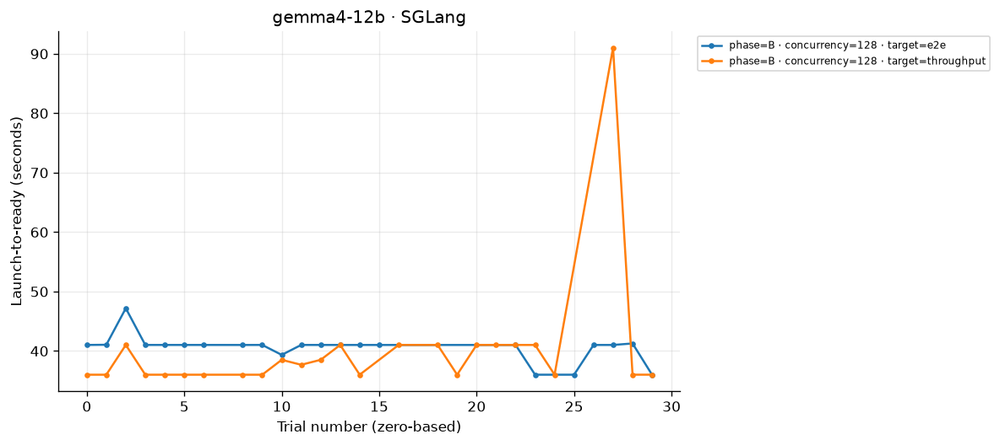

In [57]:
mean_by_trial_number("gemma4-12b", "sglang")


### gemma4-12b · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,2114.461247,1.727610,2,2
1,B,128,throughput,1,878.464635,123.186032,2,2
2,B,128,throughput,2,886.907927,1.085126,2,2
3,B,128,throughput,3,1337.853713,231.557461,2,2
4,B,128,throughput,4,1976.442404,73.581478,2,2
5,B,128,throughput,6,128.162454,1.023699,2,2
6,B,128,throughput,7,1345.186984,4.118151,2,2
7,B,128,throughput,8,1785.171282,8.793693,2,2
8,B,128,throughput,9,2241.947821,213.781607,2,2
9,B,128,throughput,11,969.604639,15.042715,2,2


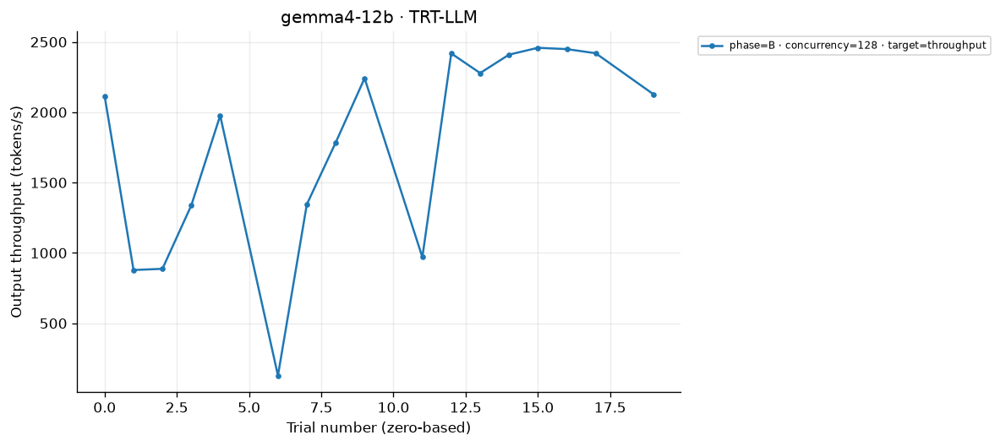

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,7372.767068,1.221228e+02,2,2
1,B,128,e2e,1,15906.256476,2.020155e+04,2,2
2,B,128,e2e,2,15939.922406,2.564403e+03,2,2
3,B,128,e2e,3,15290.562524,5.737151e+05,2,2
4,B,128,e2e,4,8068.306072,5.325811e+02,2,2
5,B,128,e2e,6,114865.505841,1.658261e+07,2,2
6,B,128,e2e,7,17137.613619,7.149914e+05,2,2
7,B,128,e2e,8,8665.771248,2.527003e+03,2,2
8,B,128,e2e,9,8210.509511,5.130835e+03,2,2
9,B,128,e2e,11,16625.630039,2.852297e+05,2,2


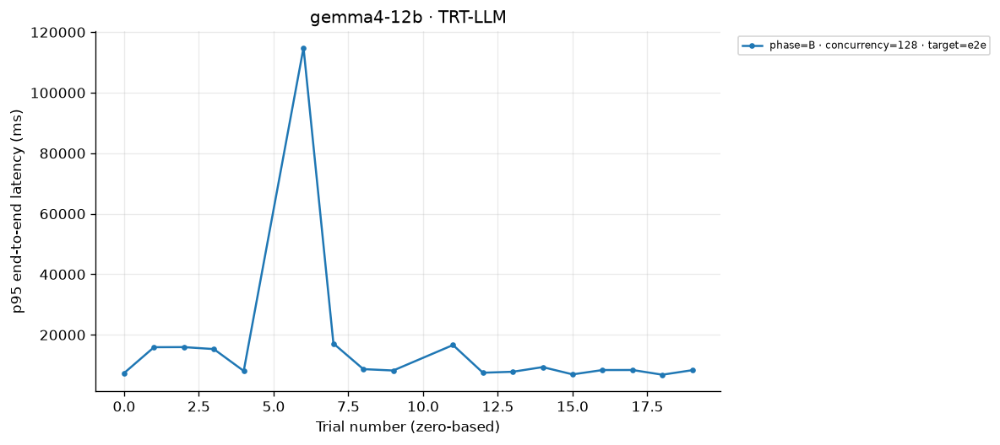

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,107.649187,1520.814622,2,2
1,B,128,e2e,1,82.534402,12.500972,2,2
2,B,128,e2e,2,80.043727,0.000214,2,2
3,B,128,e2e,3,72.541902,12.518298,2,2
4,B,128,e2e,4,77.549655,12.374461,2,2
5,B,128,e2e,6,77.546207,12.474783,2,2
6,B,128,e2e,7,77.544576,12.598773,2,2
7,B,128,e2e,8,72.549943,12.438064,2,2
8,B,128,e2e,9,82.545955,12.439050,2,2
9,B,128,e2e,11,70.034875,0.000004,2,2


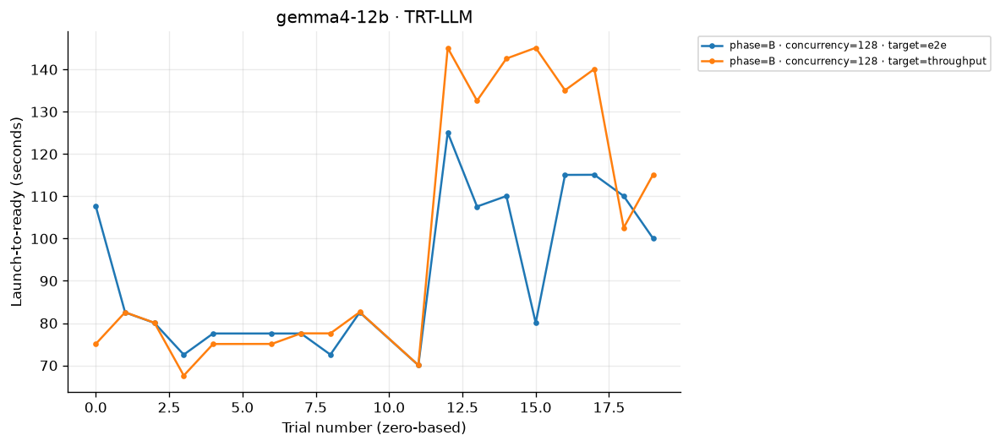

In [58]:
mean_by_trial_number("gemma4-12b", "trtllm")


### Overall results and plots:

**18 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
gemma4-12b,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084t-gemma4_12,B,sglang,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,7.343117131116666,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,pd3w0m70,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,finished,sglang-phase-b-pruning-gemma4-12b,['experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-gp-warmstart-20261022T180209567084-B-sglang-c128-measured.jsonl']
gemma4-12b,—,B,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-median,10.863642016666667,local terminal trial span,local,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,96taj3pg,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/96taj3pg,—,sglang-phase-b-pruning-gemma4-12b,['experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-tpe-s11-r1-pruner-median-B-sglang-c128-measured.jsonl']
gemma4-12b,—,B,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T164756885813,89.40978941666667,local terminal trial span,local,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,xw8kqi4c,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/xw8kqi4c,—,sglang-phase-b-pruning-gemma4-12b,[]
gemma4-12b,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-gemma4_12,B,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170,15.743546859616666,W&B terminal _runtime,wandb snapshot,—,fc2ackaf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/fc2ackaf,crashed,sglang-phase-b-pruning-gemma4-12b,[]
gemma4-12b,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstartt-gemma4_12,B,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170,21.00345920566667,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,sxxe2x4j,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/sxxe2x4j,finished,sglang-phase-b-pruning-gemma4-12b,['experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170-B-sglang-c128-measured.jsonl']
gemma4-12b,B-sglang-c128-e2e-tpe-s11-r3-pruner-mediant-gemma4_12,B,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median,56.550340637733335,local optimization_wall_seconds,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,6r9e10sq,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/6r9e10sq,finished,sglang-phase-b-pruning-gemma4-12b,"['experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-tpe-s11-r3-pruner-median-B-sglang-c128-measured.jsonl', 'experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170-B-sglang-c128-measured.jsonl']"
gemma4-12b,B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-mediant-gemma4_12,B,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-median,19.83657733333333,local terminal trial span,local + wandb snapshot,experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,i0pvzgd7,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/i0pvzgd7,finished,sglang-phase-b-pruning-gemma4-12b,['experiment_results/sglang-phase-b-pruning-gemma4-12b/B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-median-B-sglang-c128-measured.jsonl']
gemma4-12b,B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-gemma4_12,B,sglang,B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-warmstart-20261022T200256266490,8.369296440949999,local optimization_w

### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
43,gemma4-12b,B,e2e,128,full trial history,p95_e2e_latency_ms,sglang,62,7,41214.365364,2.888867e+09,phase/concurrency
44,gemma4-12b,B,throughput,128,full trial history,output_throughput,sglang,46,3,1438.069177,6.066087e+05,phase/concurrency
45,gemma4-12b,B,e2e,128,full trial history,p95_e2e_latency_ms,trtllm,32,2,17189.529650,6.723495e+08,phase/concurrency
46,gemma4-12b,B,throughput,128,full trial history,output_throughput,trtllm,32,2,1747.023767,5.144081e+05,phase/concurrency
47,gemma4-12b,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,29,2,9970.231111,2.421203e+07,phase/concurrency
48,gemma4-12b,B,throughput,128,full trial history,output_throughput,vllm,35,2,2533.334802,5.585285e+05,phase/concurrency
74,gemma4-12b,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,123,11,27597.498403,1.817336e+09,phase/concurrency
75,gemma4-12b,B,throughput,128,full trial history,output_throughput,overall,113,7,1864.802308,7.740831e+05,phase/concurrency
113,gemma4-12b,all,e2e,all,full trial history,p95_e2e_latency_ms,sglang,62,7,41214.365364,2.888867e+09,model
114,gemma4-12b,all,throughput,all,full trial history,output_throughput,sglang,46,3,1438.069177,6.066087e+05,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

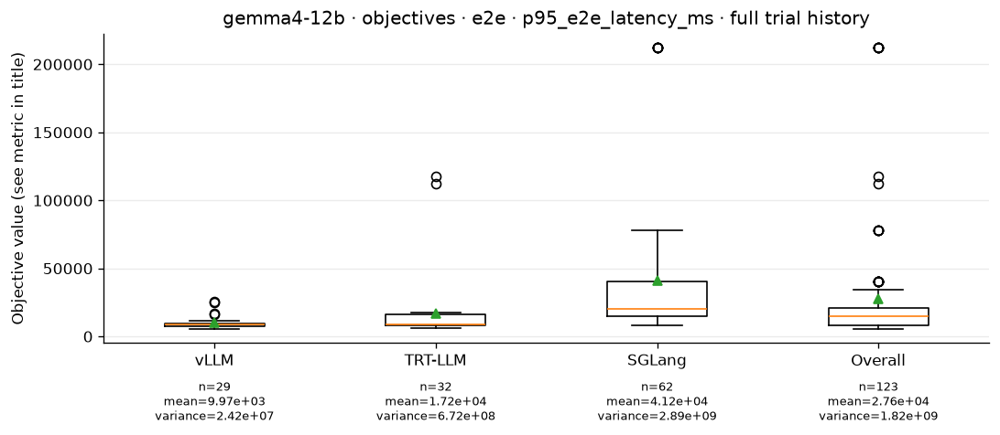

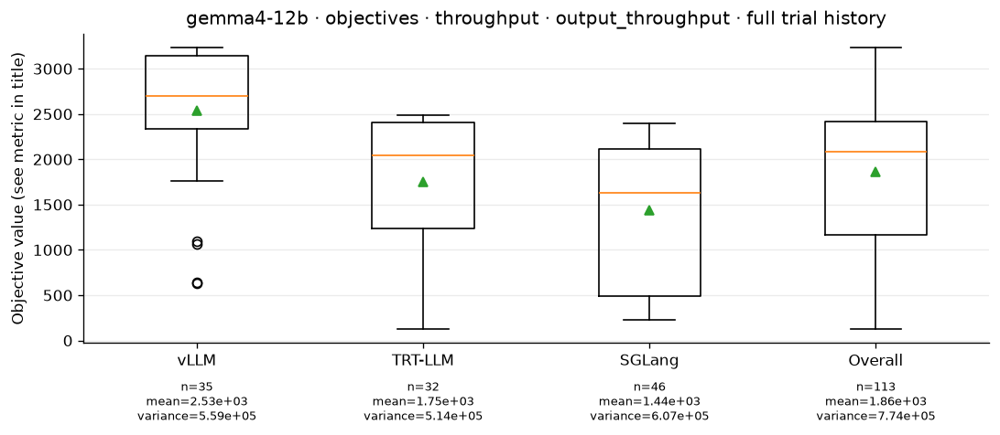

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
gemma4-12b,sglang,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084t-gemma4_12,pd3w0m70,59,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-median,96taj3pg,30,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,gt702ry5,2,under five minutes
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-median,1aa4uovv,4,under five minutes
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T164756885813,xw8kqi4c,47,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-gemma4_12,fc2ackaf,25,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstartt-gemma4_12,sxxe2x4j,122,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe-s11-r3-pruner-mediant-gemma4_12,6r9e10sq,70,included
gemma4-12b,sglang,B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-mediant-gemma4_12,i0pvzgd7,15,included
gemma4-12b,sglang,B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-gemma4_12,zlbcnyi0,64,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope
19,gemma4-12b,B,launch_to_ready,complete,sglang,110,40.083471,43.363905,phase
20,gemma4-12b,B,client_preparation,complete,sglang,110,4.055312,0.088610,phase
21,gemma4-12b,B,warmup,complete,sglang,110,1.112611,0.009693,phase
22,gemma4-12b,B,benchmark,complete,sglang,109,184.010947,32073.076829,phase
23,gemma4-12b,B,compilation,log observation,sglang,8,1.082500,0.002679,phase
24,gemma4-12b,B,launch_to_ready,complete,trtllm,69,96.160790,784.756607,phase
25,gemma4-12b,B,client_preparation,complete,trtllm,69,4.065246,0.044255,phase
26,gemma4-12b,B,warmup,complete,trtllm,69,0.690150,0.256032,phase
27,gemma4-12b,B,benchmark,complete,trtllm,64,117.700042,36984.626847,phase
28,gemma4-12b,B,launch_to_ready,complete,vllm,71,143.488759,872.956771,phase


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

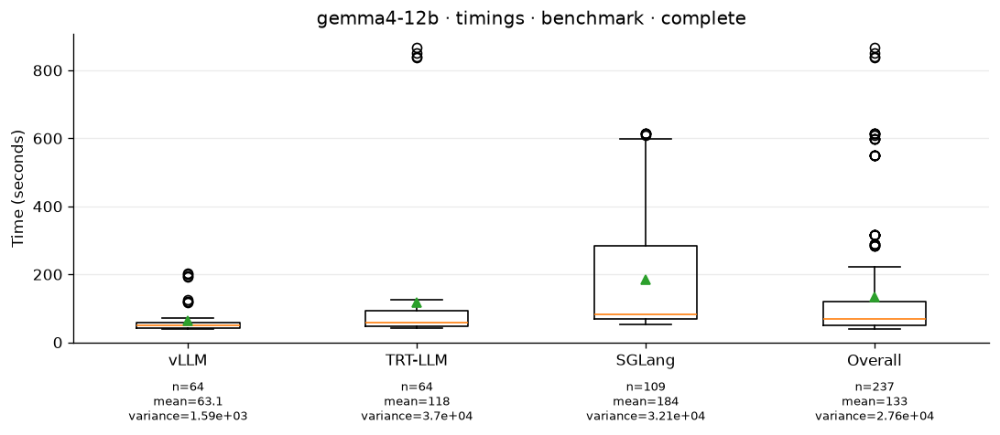

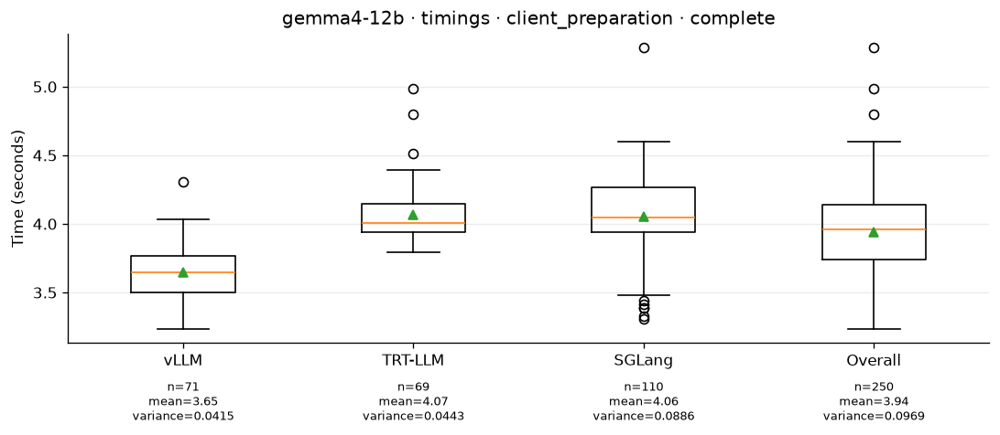

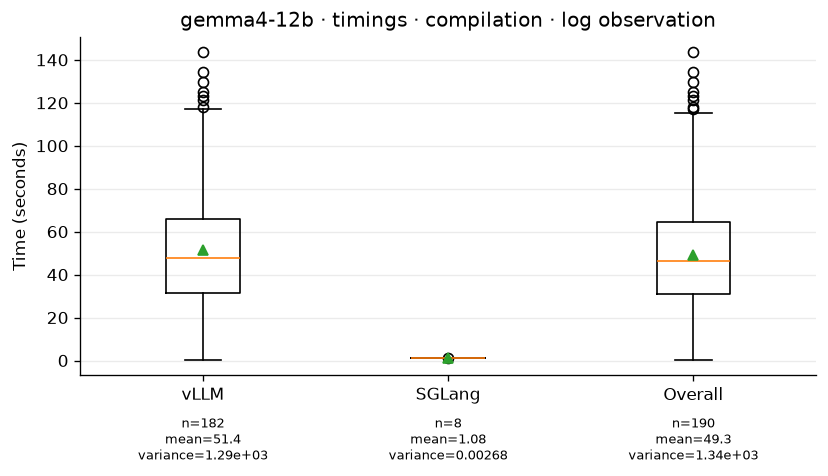

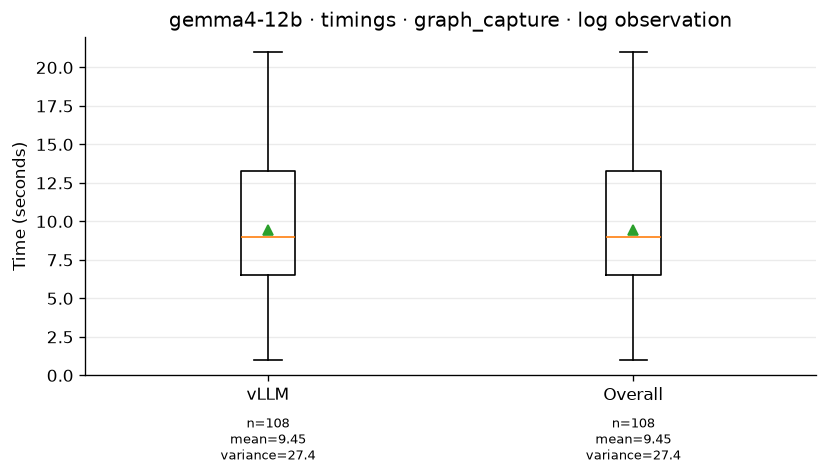

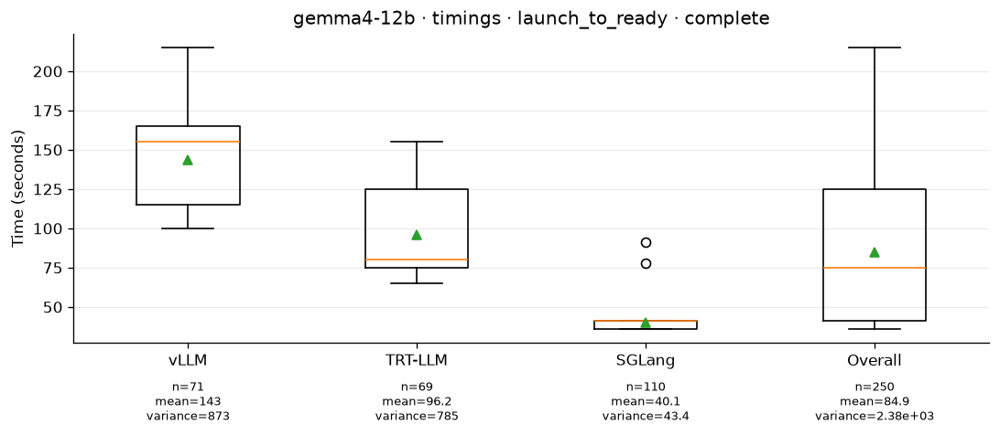

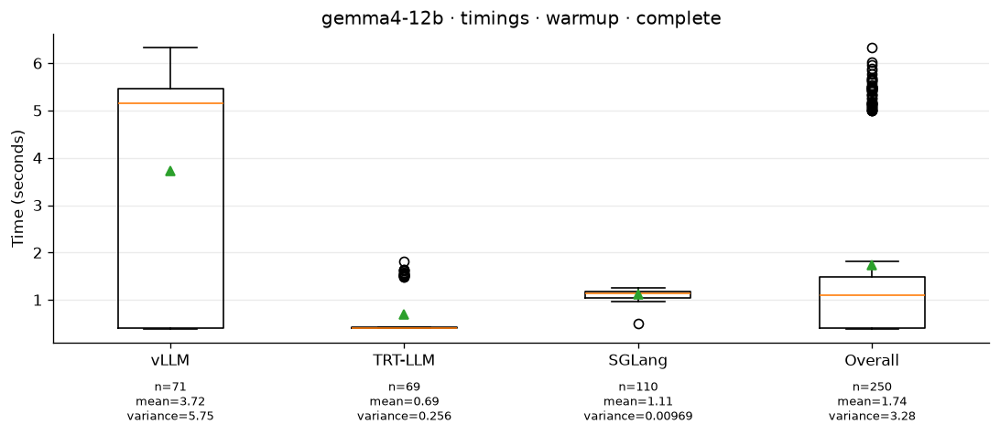

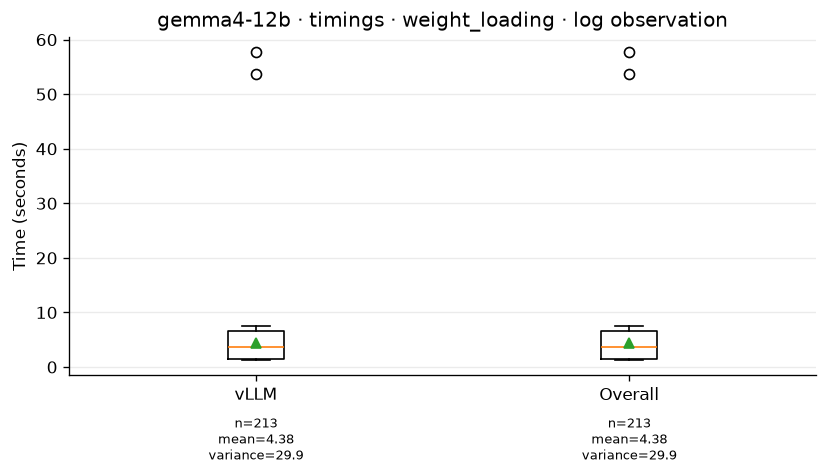

Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means.

model_group,framework,phase,study_name,wandb_id,trial,params,state,source,wandb_url,launch_to_ready (s),launch_to_ready status,client_preparation (s),client_preparation status,warmup (s),warmup status,benchmark (s),benchmark status,runner_wall (s),runner_wall status,compilation (s),compilation status,weight_loading (s),weight_loading status,graph_capture (s),graph_capture status
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,0,"attention_backend: ""triton""chunked_prefill_size: 16896cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 72mem_fraction_static: 0.8schedule_conservativeness: 1.0schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,41.01574053400009,complete,4.298098976999881,complete,1.1964153369999622,complete,90.55245602700006,complete,144.3578695469996,unknown,—,—,—,—,—,—
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,1,"attention_backend: ""triton""chunked_prefill_size: 16384cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 8mem_fraction_static: 0.85schedule_conservativeness: 1.5schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,41.01605236599971,complete,4.329944937999699,complete,1.2224255510000148,complete,614.9788300099999,complete,668.8176870130001,unknown,—,—,—,—,—,—
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,2,"attention_backend: ""triton""chunked_prefill_size: 1536cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 88mem_fraction_static: 0.7schedule_conservativeness: 0.75schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,41.01966739599993,complete,3.9432887190000656,complete,1.1372224579999965,complete,81.53224196799965,complete,134.470994668,unknown,—,—,—,—,—,—
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,3,"attention_backend: ""triton""chunked_prefill_size: 3584cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 24576max_running_requests: 16mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.5schedule_policy: ""fcfs""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,41.019501813999796,complete,4.303096001000085,complete,1.1693027830001483,complete,315.628359757,complete,369.5820001300003,unknown,—,—,—,—,—,—
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,4,"attention_backend: ""triton""chunked_prefill_size: 18688cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.85schedule_conservativeness: 0.5schedule_policy: ""lpm""",COMPLETE,local SQLite,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/pd3w0m70,41.01855539600001,complete,4.26931704000026,complete,1.1709399359997406,complete,83.03549571099984,complete,136.1764745180003,unknown,—,—,—,—,—,—
gemma4-12b,sglang,B,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,pd3w0m70,5,"attention_backend: ""triton""chunked_prefill_size: 11008cuda_graph_backend_decode: ""disabled""

### vLLM · gemma4-12b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,1,max_num_seqs,0.3771600370645965
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,2,max_num_batched_tokens,0.33759670967798006
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,3,gpu_memory_utilization,0.1708213819502654
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,4,performance_mode,0.06029363834444111
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,5,graph_mode,0.026633597145117236
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,6,enable_prefix_caching,0.023882739959523593
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,7,async_scheduling,0.0036118958580760815
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,8,kv_cache_dtype,0.0
gemma4-12b,vllm,e2e,jy6fuo2e,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,9,attention_backend,0.0
gemma4-12b,vllm,e2e,35sb89tl,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,tpe_multivariate,p95_e2e_latency_ms,1,performance_mode,0.27656626512169


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,2,0.008033,3.909895e-05
1,e2e,p95_e2e_latency_ms,attention_backend,2,0.000000,0.000000e+00
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,2,0.011964,2.841121e-04
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,2,0.147398,1.097293e-03
4,e2e,p95_e2e_latency_ms,graph_mode,2,0.067567,3.351158e-03
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,2,0.000000,0.000000e+00
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,2,0.291951,4.167118e-03
7,e2e,p95_e2e_latency_ms,max_num_seqs,2,0.304656,1.051357e-02
8,e2e,p95_e2e_latency_ms,performance_mode,2,0.168430,2.338692e-02
9,throughput,output_throughput,async_scheduling,2,0.000676,7.041992e-08


model_group,framework,run,wandb_id,status


Phase B / vLLM: 4 included runs; cutoff 5 minutes


**Runs included: 4.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-nop`

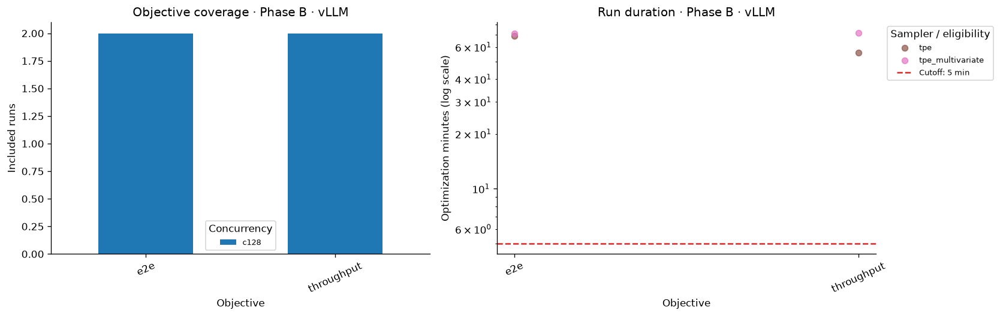

,state,trials
0,COMPLETE,64
1,FAIL,9
2,PRUNED,7


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 2.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-tpe-s11-r3-pruner-median,vllm-phase-b-pruning-gemma4-12b,jy6fuo2e,e2e,C23,tpe,68.97,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 21760max_num_seqs: 64performance_mode: balanced,9,6359.058068,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,vllm-phase-b-pruning-gemma4-12b,35sb89tl,e2e,C23,tpe_multivariate,71.42,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 15104max_num_seqs: 128performance_mode: balanced,18,5506.465550,False,all local COMPLETE trials


##### Matching context C23

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

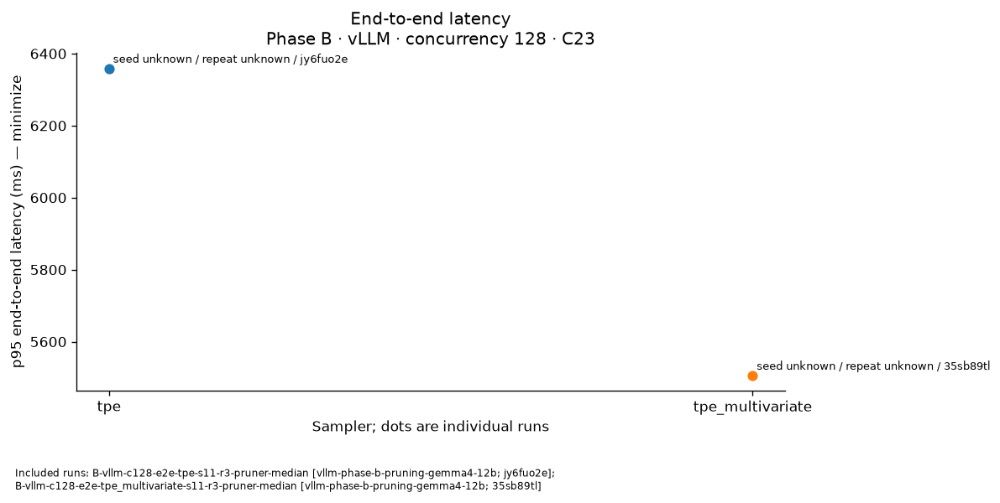

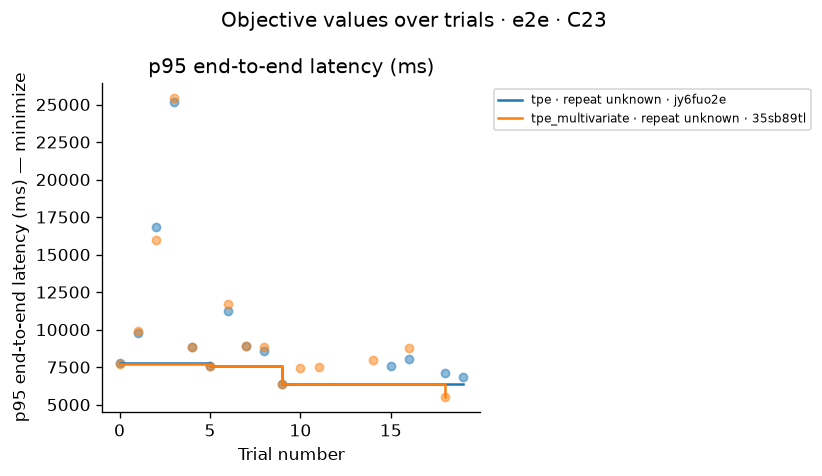

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 2.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-tpe-s11-r1-pruner-nop`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-nop`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-tpe-s11-r1-pruner-nop,vllm-phase-b-pruning-gemma4-12b,mkoo2ri1,throughput,C10,tpe,55.68,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 32768max_num_seqs: 128performance_mode: balanced,14,3227.963842,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-nop,vllm-phase-b-pruning-gemma4-12b,fcwye0pn,throughput,C10,tpe_multivariate,71.81,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 32256max_num_seqs: 128performance_mode: balanced,16,3233.424320,False,all local COMPLETE trials


##### Matching context C10

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

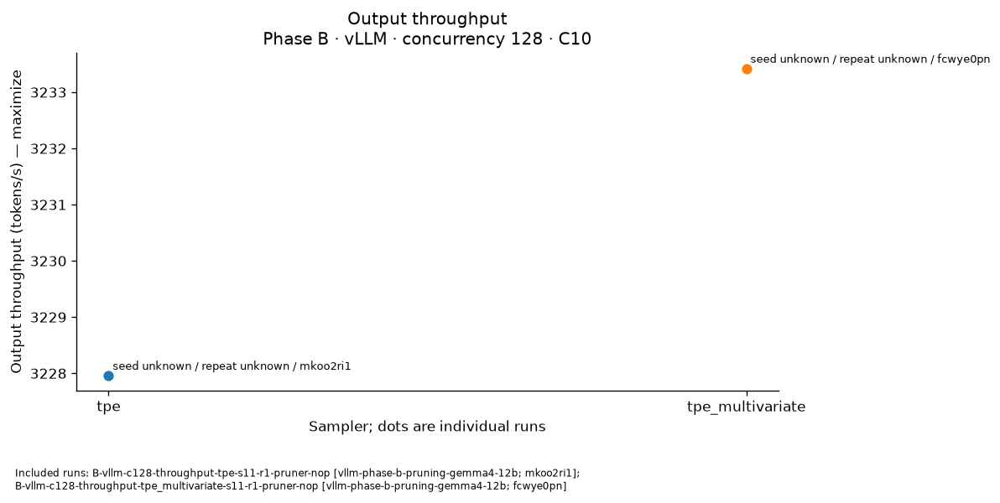

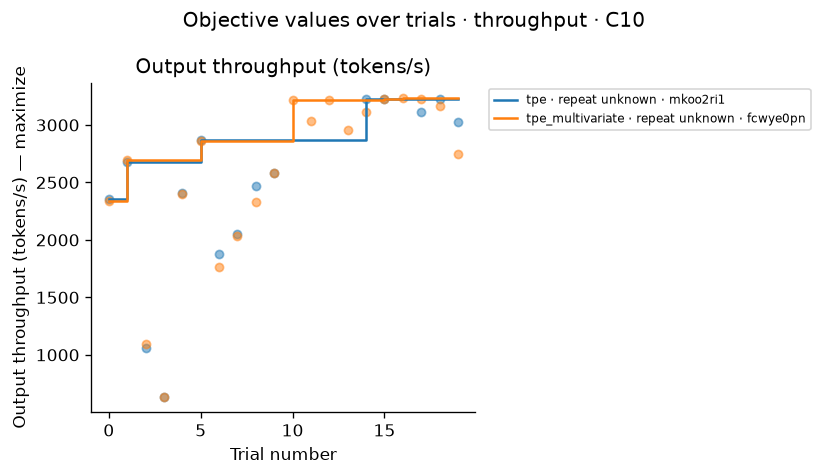

### TRT-LLM · gemma4-12b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,1,max_num_tokens,0.49319315102663547
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,2,max_batch_size,0.3867429474261604
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,3,kv_cache_free_gpu_memory_fraction,0.09083021963066591
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,4,enable_block_reuse,0.012854095987133336
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,5,enable_chunked_prefill,0.008026434397863456
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,6,capacity_scheduler_policy,0.008026434397863456
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,7,graph_enabled,0.000326717133677965
gemma4-12b,trtllm,e2e,wbjzmc4d,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,tpe,p95_e2e_latency_ms,8,attn_backend,0.0
gemma4-12b,trtllm,e2e,mqoxrtgh,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,tpe_multivariate,p95_e2e_latency_ms,1,max_batch_size,0.8944364897084542
gemma4-12b,trtllm,e2e,mqoxrtgh,local SQLite,Optuna PED-ANOVA,B-trtllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,tpe_multivariate,p95_e2e_latency_ms,2,max_num_tokens,0.05333675972170269


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attn_backend,2,0.000000,0.000000e+00
1,e2e,p95_e2e_latency_ms,capacity_scheduler_policy,2,0.014565,8.551161e-05
2,e2e,p95_e2e_latency_ms,enable_block_reuse,2,0.007369,6.018299e-05
3,e2e,p95_e2e_latency_ms,enable_chunked_prefill,2,0.010602,1.326881e-05
4,e2e,p95_e2e_latency_ms,graph_enabled,2,0.000432,2.198521e-08
5,e2e,p95_e2e_latency_ms,kv_cache_free_gpu_memory_fraction,2,0.053178,2.835403e-03
6,e2e,p95_e2e_latency_ms,max_batch_size,2,0.640590,1.288764e-01
7,e2e,p95_e2e_latency_ms,max_num_tokens,2,0.273265,9.673682e-02
8,throughput,output_throughput,attn_backend,2,0.000000,0.000000e+00
9,throughput,output_throughput,capacity_scheduler_policy,2,0.021019,9.735054e-05


model_group,framework,run,wandb_id,status


Phase B / TRT-LLM: 4 included runs; cutoff 5 minutes


**Runs included: 4.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`
- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

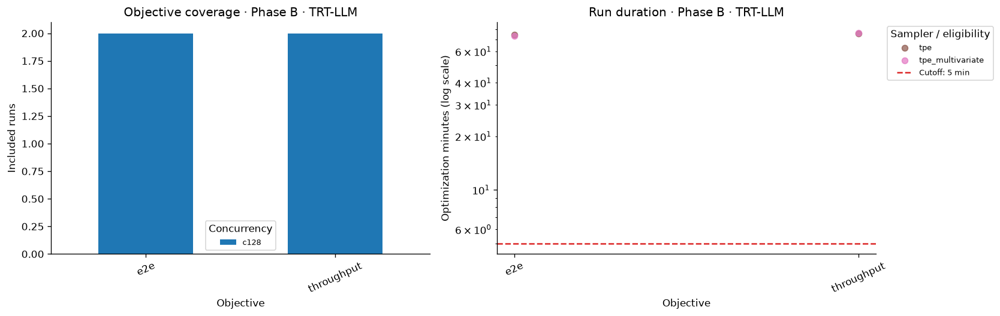

,state,trials
0,COMPLETE,64
1,FAIL,11
2,PRUNED,5


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · TRT-LLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 2.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-e2e-tpe-s11-r2-pruner-median`
- `B-trtllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,trtllm-phase-b-pruning-gemma4-12b,wbjzmc4d,e2e,C38,tpe,74.63,attn_backend: FLASHINFERcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: powersgraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 64max_num_tokens: 16896,15,6930.726571,False,all local COMPLETE trials
B-trtllm-c128-e2e-tpe_multivariate-s11-r2-pruner-median,trtllm-phase-b-pruning-gemma4-12b,mqoxrtgh,e2e,C38,tpe_multivariate,73.53,attn_backend: FLASHINFERcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.75max_batch_size: 128max_num_tokens: 14080,18,6229.949634,False,all local COMPLETE trials


##### Matching context C38

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

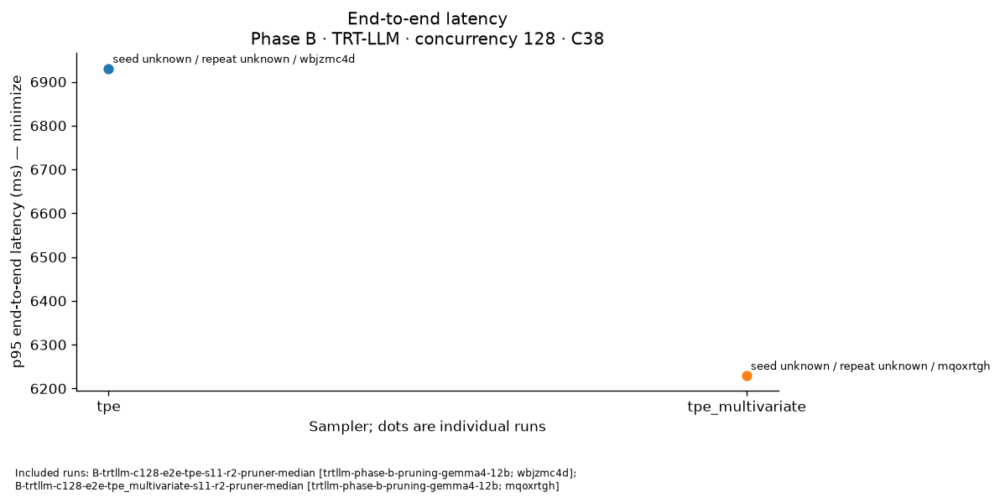

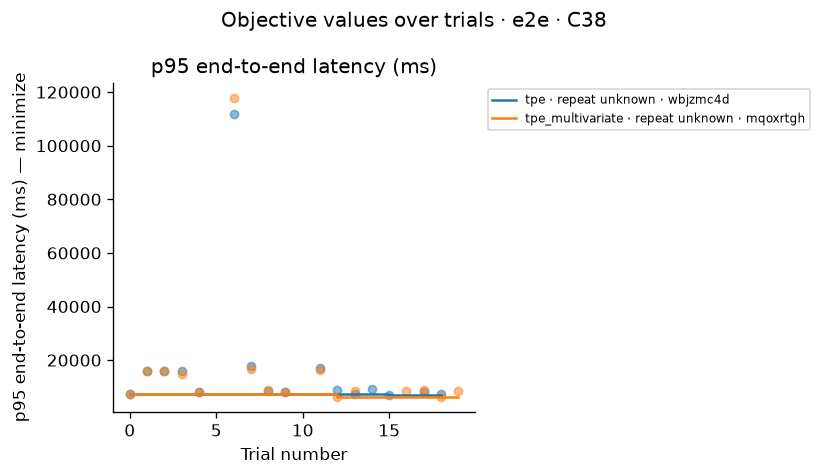

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 2.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-trtllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-trtllm-c128-throughput-tpe-s11-r1-pruner-median,trtllm-phase-b-pruning-gemma4-12b,zmk6ccyd,throughput,C32,tpe,75.80,attn_backend: FLASHINFERcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Falseenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 112max_num_tokens: 31744,15,2482.432821,False,all local COMPLETE trials
B-trtllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,trtllm-phase-b-pruning-gemma4-12b,1lf3thh8,throughput,C32,tpe_multivariate,76.31,attn_backend: FLASHINFERcapacity_scheduler_policy: GUARANTEED_NO_EVICTenable_block_reuse: Trueenable_chunked_prefill: Falsegraph_capture_profile: densegraph_enabled: Truegraph_padding: 1kv_cache_free_gpu_memory_fraction: 0.65max_batch_size: 112max_num_tokens: 32000,16,2470.572238,False,all local COMPLETE trials


##### Matching context C32

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.2"` · **driver version:** `"580.173.02"`

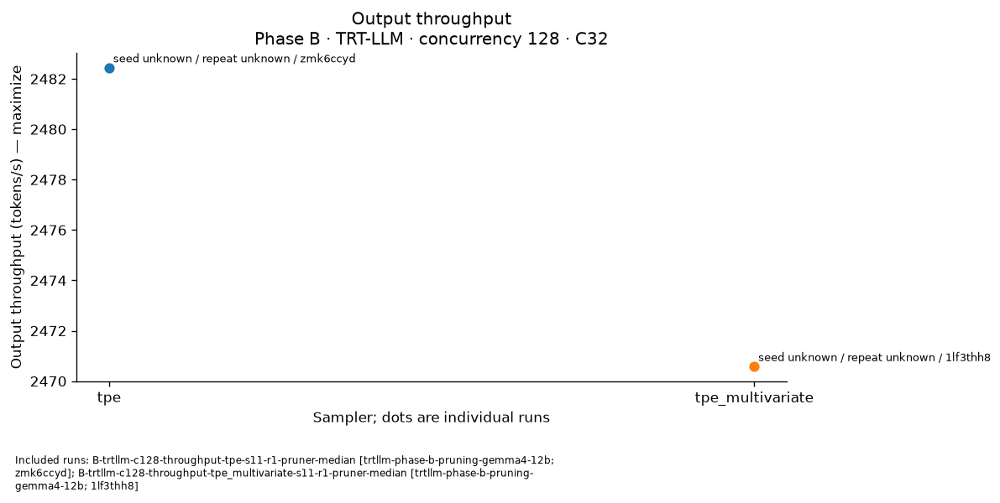

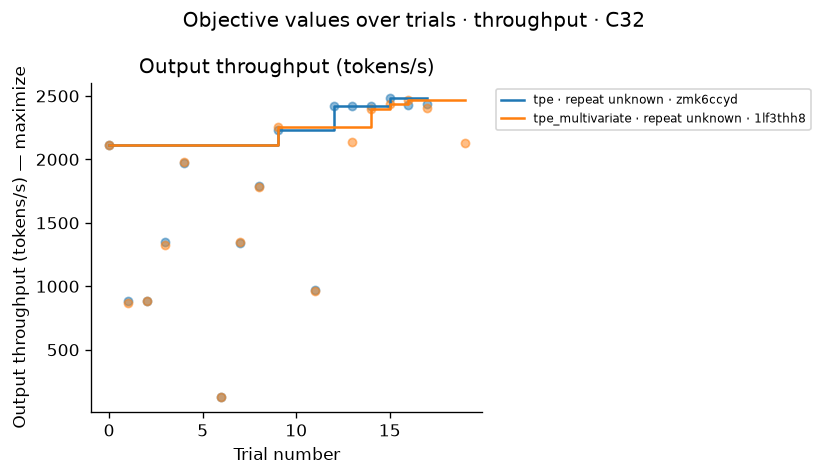

### SGLang · gemma4-12b

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,1,max_running_requests,0.6145182481103211
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,2,schedule_conservativeness,0.21860800352554607
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,3,schedule_policy,0.0845751736607235
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,4,max_prefill_tokens,0.047077828677419095
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,5,chunked_prefill_size,0.03129958809536263
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,6,mem_fraction_static,0.0035884900781192083
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,7,disable_radix_cache,0.0003326678525085066
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,8,enable_mixed_chunk,0.0
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,9,disable_overlap_schedule,0.0
gemma4-12b,sglang,e2e,pd3w0m70,local SQLite,Optuna PED-ANOVA,B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,gp,p95_e2e_latency_ms,10,cuda_graph_backend_prefill,0.0


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,attention_backend,7,0.011905,9.920635e-04
1,e2e,p95_e2e_latency_ms,chunked_prefill_size,7,0.156208,2.863148e-02
2,e2e,p95_e2e_latency_ms,cuda_graph_backend_decode,7,0.011905,9.920635e-04
3,e2e,p95_e2e_latency_ms,cuda_graph_backend_prefill,7,0.011905,9.920635e-04
4,e2e,p95_e2e_latency_ms,disable_overlap_schedule,7,0.011905,9.920635e-04
5,e2e,p95_e2e_latency_ms,disable_radix_cache,7,0.013027,9.635432e-04
6,e2e,p95_e2e_latency_ms,enable_mixed_chunk,7,0.011905,9.920635e-04
7,e2e,p95_e2e_latency_ms,max_prefill_tokens,7,0.132236,4.788466e-03
8,e2e,p95_e2e_latency_ms,max_running_requests,7,0.369728,4.594794e-02
9,e2e,p95_e2e_latency_ms,mem_fraction_static,7,0.108058,9.145566e-03


model_group,framework,run,wandb_id,status


Phase B / SGLang: 10 included runs; cutoff 5 minutes


**Runs included: 9.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-warmstart-20261022T180209567084`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T164756885813`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-warmstart-20261022T200256266490`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median-mv-warmstart-20261022T190857744797`

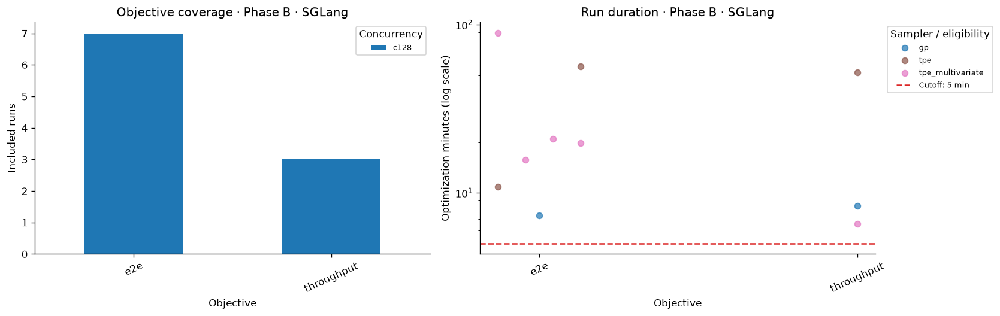

,state,trials
0,COMPLETE,103
1,FAIL,67
2,PRUNED,1


Runs without recorded outcome counts: 1


#### Concurrency 128 · Phase B · SGLang

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 6.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-e2e-gp-warmstart-20261022T180209567084`
- `B-sglang-c128-e2e-tpe-s11-r1-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T164756885813`
- `B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170`
- `B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-sglang-c128-e2e-gp-warmstart-20261022T180209567084,sglang-phase-b-pruning-gemma4-12b,pd3w0m70,e2e,C17,gp,7.34,attention_backend: tritonchunked_prefill_size: 11520cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: fcfs,8,7935.125327,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-gemma4-12b,96taj3pg,e2e,C17,tpe,10.86,attention_backend: tritonchunked_prefill_size: 15616cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Trueenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 48mem_fraction_static: 0.7schedule_conservativeness: 1.25schedule_policy: lpm,6,17203.235049,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T164756885813,sglang-phase-b-pruning-gemma4-12b,xw8kqi4c,e2e,C17,tpe_multivariate,89.41,attention_backend: tritonchunked_prefill_size: 11520cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: fcfs,8,7935.125327,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170 [sglang-phase-b-pruning-gemma4-12b / fc2ackaf],sglang-phase-b-pruning-gemma4-12b,fc2ackaf,e2e,C16,tpe_multivariate,15.74,attention_backend: tritonchunked_prefill_size: 11008cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 104mem_fraction_static: 0.75schedule_conservativeness: 1.5schedule_policy: fcfs,14,14333.765823,False,all W&B COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r3-pruner-median-mv-warmstart-20261022T170206666170 [sglang-phase-b-pruning-gemma4-12b / sxxe2x4j],sglang-phase-b-pruning-gemma4-12b,sxxe2x4j,e2e,C17,tpe_multivariate,21.00,attention_backend: tritonchunked_prefill_size: 11520cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: fcfs,8,7935.125327,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe-s11-r3-pruner-median,sglang-phase-b-pruning-gemma4-12b,6r9e10sq,e2e,C17,tpe,56.55,attention_backend: tritonchunked_prefill_size: 11520cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: fcfs,8,7935.125327,False,all local COMPLETE trials
B-sglang-c128-e2e-tpe_multivariate-s11-r3-pruner-median,sglang-phase-b-pruning-gemma4-12b,i0pvzgd7,e2e,C17,tpe_multivariate,19.84,attention_backend: tritonchunked_prefill_size: 16896cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 16384max_running_requests: 72mem_fraction_static: 0.8schedule_conservativeness: 1.0schedule_policy: lpm,0,18886.566966,False,all local COMPLETE trials


##### Matching context C16

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

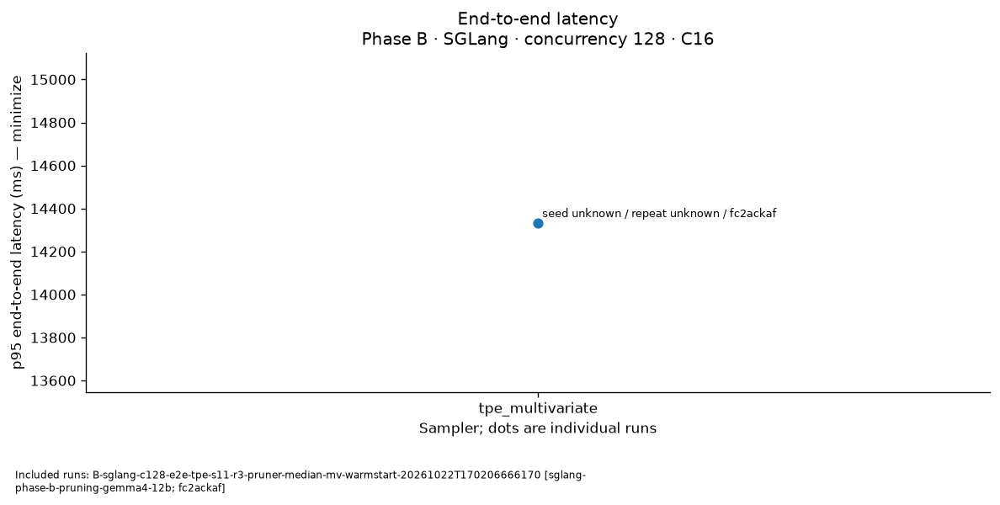

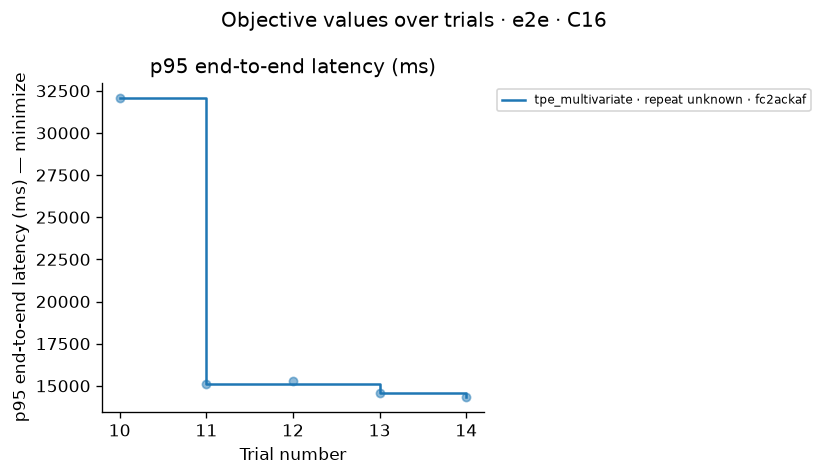

##### Matching context C17

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

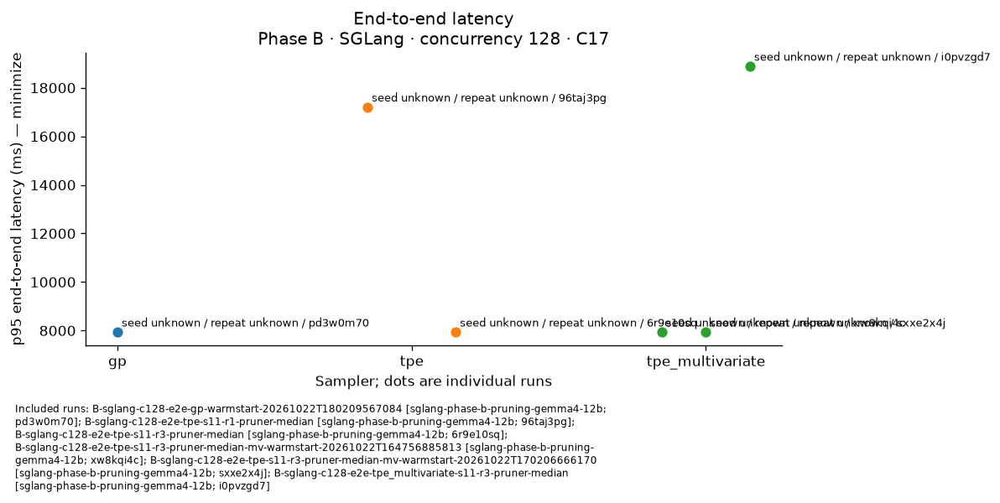

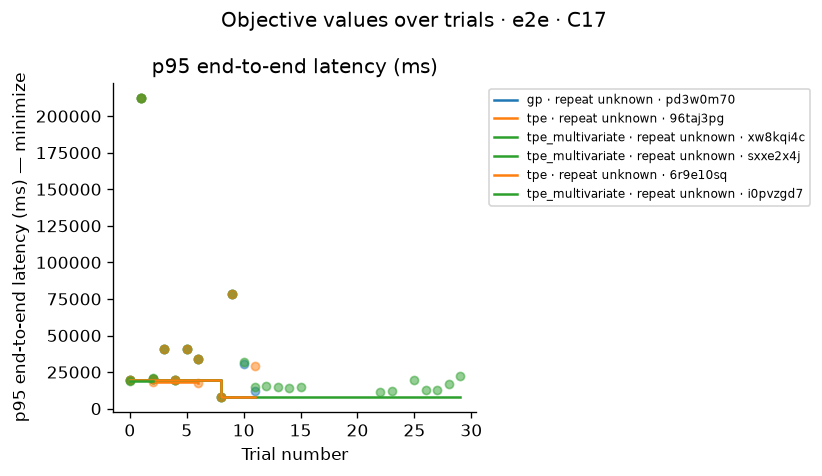

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-warmstart-20261022T200256266490`
- `B-sglang-c128-throughput-tpe-s11-r1-pruner-median-mv-warmstart-20261022T190857744797`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-sglang-c128-throughput-tpe-s11-r1-pruner-median-gp-nopruner-warmstart-20261022T200256266490,sglang-phase-b-pruning-gemma4-12b,zlbcnyi0,throughput,C05,gp,8.37,attention_backend: tritonchunked_prefill_size: 12544cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.85schedule_conservativeness: 1.5schedule_policy: fcfs,12,2399.620169,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r1-pruner-median-mv-warmstart-20261022T190857744797,sglang-phase-b-pruning-gemma4-12b,wf0eu7mr,throughput,C05,tpe_multivariate,6.54,attention_backend: tritonchunked_prefill_size: 15360cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 24576max_running_requests: 128mem_fraction_static: 0.85schedule_conservativeness: 0.5schedule_policy: fcfs,28,2355.964813,False,all local COMPLETE trials
B-sglang-c128-throughput-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-gemma4-12b,gevrkqid,throughput,C05,tpe,51.84,attention_backend: tritonchunked_prefill_size: 11520cuda_graph_backend_decode: disabledcuda_graph_backend_prefill: disableddisable_overlap_schedule: Truedisable_radix_cache: Falseenable_mixed_chunk: Falsemax_prefill_tokens: 8192max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 1.0schedule_policy: fcfs,8,2315.668803,False,all local COMPLETE trials


##### Matching context C05

**Matched workload and environment**

**model:** `"gemma4-12b"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

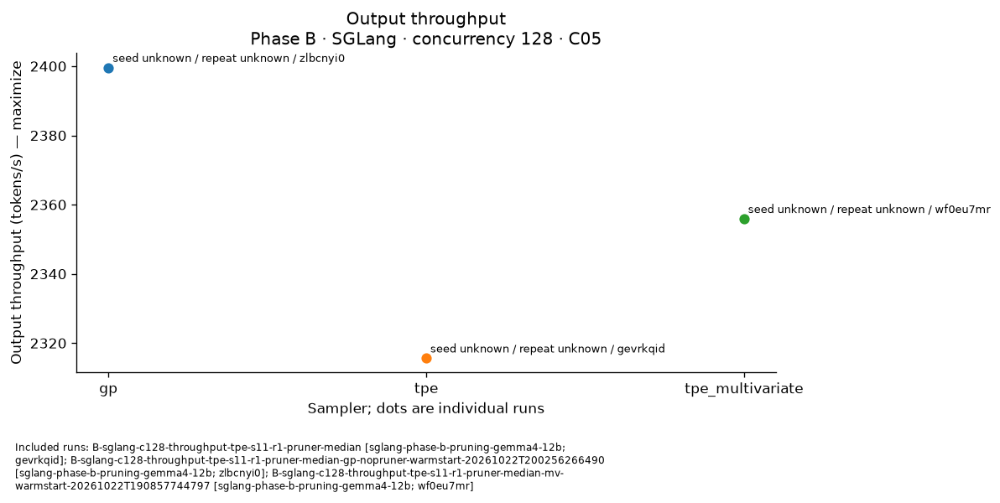

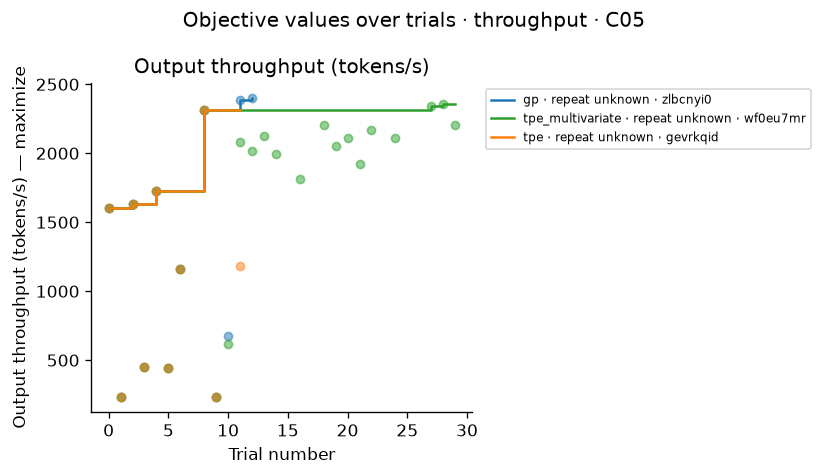

In [59]:
show_model("gemma4-12b")


## gemma4-12b dspark


### Summary of the results:

In [60]:
show_framework_summary("gemma4-12b dspark")


### Framework summaries · gemma4-12b dspark

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
throughput,C09,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,qip1053p,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qip1053p,10,2963.8348168934167,—,"async_scheduling: falseattention_backend: ""auto""enable_prefix_caching: truegpu_memory_utilization: 0.9graph_capture_profile: ""powers""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 19968max_num_seqs: 128performance_mode: ""balanced""",all local COMPLETE trials
e2e,C22,B,128,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,yzibxy23,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/yzibxy23,19,—,8612.216558249564,"async_scheduling: trueattention_backend: ""auto""enable_prefix_caching: falsegpu_memory_utilization: 0.75graph_capture_profile: ""powers""graph_mode: ""PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 23040max_num_seqs: 40performance_mode: ""balanced""",all local COMPLETE trials


**Throughput and latency objectives** (throughput: tokens/s; latency: ms; variance: squared units)

... (5 outputs left out)

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


#### For SGLang

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

No eligible completed results available.
No eligible throughput or E2E latency measurements.
No complete startup or serving timing metadata available.


### Per-Trial behavior:

### gemma4-12b dspark · vLLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

**Output throughput (tokens/s)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,throughput,0,2858.558967,306.954666,3,3
1,B,128,throughput,1,2864.805589,391.898284,3,3
2,B,128,throughput,2,1562.338423,3770.131088,3,3
3,B,128,throughput,3,1553.984575,1852.623256,3,3
4,B,128,throughput,4,2770.480214,28.594687,3,3
5,B,128,throughput,6,2754.303633,90.591168,3,3
6,B,128,throughput,7,2757.728456,1007.390747,3,3
7,B,128,throughput,8,2835.826553,245.774182,3,3
8,B,128,throughput,9,2804.192414,22.968815,3,3
9,B,128,throughput,10,2937.927129,809.476838,3,3


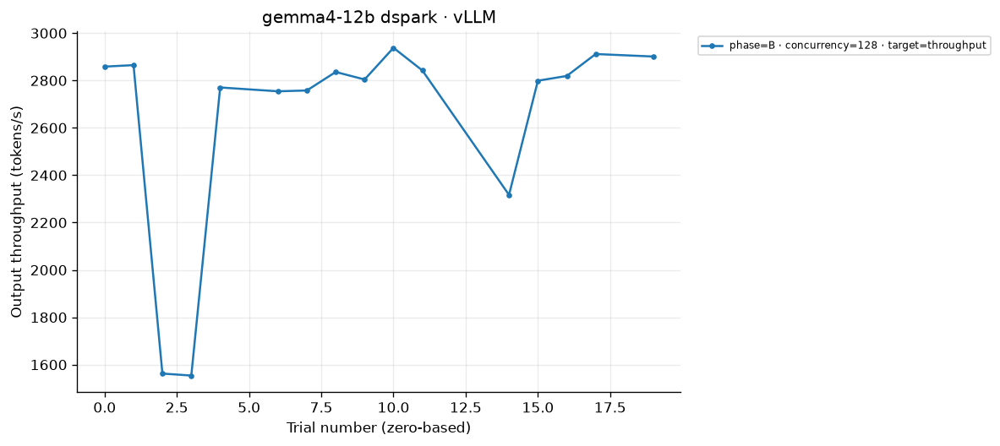

**p95 end-to-end latency (ms)**

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,10574.148812,2.993037e+01,3,3
1,B,128,e2e,1,11528.152725,3.726805e+06,2,2
2,B,128,e2e,2,12084.301710,2.982173e+06,3,3
3,B,128,e2e,3,12324.025643,9.116339e+04,2,2
4,B,128,e2e,4,10763.269467,5.674584e+06,3,3
5,B,128,e2e,5,9298.244124,NaN,1,1
6,B,128,e2e,6,10658.130882,1.610422e+06,2,2
7,B,128,e2e,7,9798.713332,3.088108e+05,2,2
8,B,128,e2e,8,10306.436732,3.488829e+06,2,2
9,B,128,e2e,9,11129.264288,1.730368e+06,3,3


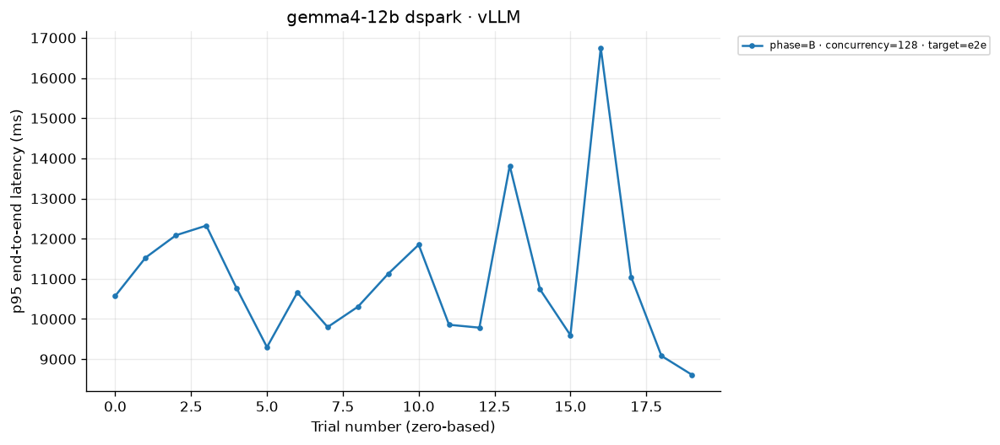

#### Mean server initiation by trial number

,phase,concurrency,target,trial,mean,variance,observations,runs
0,B,128,e2e,0,196.713562,5.635548e+03,3,3
1,B,128,e2e,1,140.038065,1.800757e+03,2,2
2,B,128,e2e,2,155.040143,9.253401e+02,3,3
3,B,128,e2e,3,147.541086,1.513059e+03,2,2
4,B,128,e2e,4,158.373122,8.336267e+02,3,3
5,B,128,e2e,5,200.054240,NaN,1,1
6,B,128,e2e,6,145.038533,1.800777e+03,2,2
7,B,128,e2e,7,152.540400,2.813920e+03,2,2
8,B,128,e2e,8,142.534896,2.113296e+03,2,2
9,B,128,e2e,9,155.040908,9.252927e+02,3,3


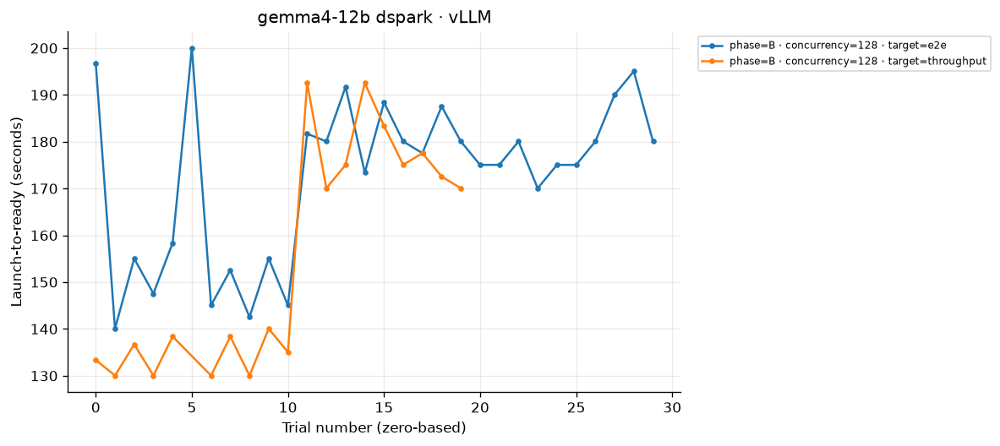

In [61]:
mean_by_trial_number("gemma4-12b dspark", "vllm")


In [62]:
mean_by_trial_number("gemma4-12b dspark", "sglang")


### gemma4-12b dspark · SGLang · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


In [63]:
mean_by_trial_number("gemma4-12b dspark", "trtllm")


### gemma4-12b dspark · TRT-LLM · mean by trial number

Objective points use eligible completed trials from full local/W&B histories; summary-only candidates cannot represent the trial trajectory. Startup points use recorded complete launch-to-ready phases, including eligible shorter measured runs. Each point is a mean across available observations at that trial number; n can change between points. Phases, concurrencies, objectives, and metrics are kept separate. Early-stopped or failed trials can affect which runs contribute later.

#### Mean objective by trial number

No complete trial histories are available for these objectives.


#### Mean server initiation by trial number

No launch-to-ready (seconds) observations are available.


### Overall results and plots:

**7 eligible optimization runs**

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
gemma4-12b dspark,B-vllm-c128-e2e-gp-s11-r1-pruner-nop-dsparkg4_12,B,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,74.59259909256666,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,yzibxy23,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/yzibxy23,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-e2e-gp-s11-r1-pruner-nop-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,B-vllm-c128-e2e-tpe-s11-r3-pruner-median-dsparkg4_12,B,vllm,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,65.17969539888333,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,ov7xvv23,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/ov7xvv23,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-e2e-tpe-s11-r3-pruner-median-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,—,B,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,6.135813916666667,local terminal trial span,local,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,8s7cgmt5,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/8s7cgmt5,—,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,B-vllm-c128-throughput-gp-s11-r1-pruner-nop-dsparkg4_12,B,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-nop,50.06394756825001,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,svr3os57,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/svr3os57,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-throughput-gp-s11-r1-pruner-nop-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,B-vllm-c128-throughput-tpe-s11-r1-pruner-median-dsparkg4_12,B,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-median,66.67162869794998,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,a6d6o3b2,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/a6d6o3b2,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-throughput-tpe-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-dsparkg4_12,B,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,63.86242855451665,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,qip1053p,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qip1053p,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-B-vllm-c128-measured.jsonl']
gemma4-12b dspark,gemma4-vllm-tpe-multivariate-continued-dsparkg4_12,B,vllm,gemma4-vllm-tpe-auto-kv-seeded-v3,84.05782634771667,local optimization_wall_seconds,local + wandb snapshot,experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,blbmq1q8,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/blbmq1q8,finished,vllm-phase-b-pruning-gemma4-12b-dspark,['experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/gemma4-vllm-tpe-auto-kv-seeded-v3-B-vllm-c128-measured.jsonl']


### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
49,gemma4-12b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,43,4,11193.041123,1.021662e+07,phase/concurrency
50,gemma4-12b dspark,B,throughput,128,full trial history,output_throughput,vllm,36,3,2602.512888,2.349270e+05,phase/concurrency
76,gemma4-12b dspark,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,43,4,11193.041123,1.021662e+07,phase/concurrency
77,gemma4-12b dspark,B,throughput,128,full trial history,output_throughput,overall,36,3,2602.512888,2.349270e+05,phase/concurrency
119,gemma4-12b dspark,all,e2e,all,full trial history,p95_e2e_latency_ms,vllm,43,4,11193.041123,1.021662e+07,model
120,gemma4-12b dspark,all,throughput,all,full trial history,output_throughput,vllm,36,3,2602.512888,2.349270e+05,model
139,gemma4-12b dspark,all,e2e,all,full trial history,p95_e2e_latency_ms,overall,43,4,11193.041123,1.021662e+07,model
140,gemma4-12b dspark,all,throughput,all,full trial history,output_throughput,overall,36,3,2602.512888,2.349270e+05,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

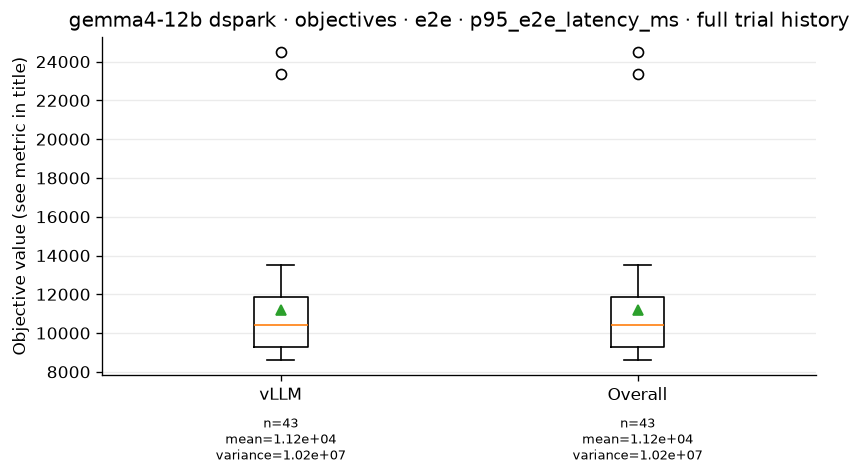

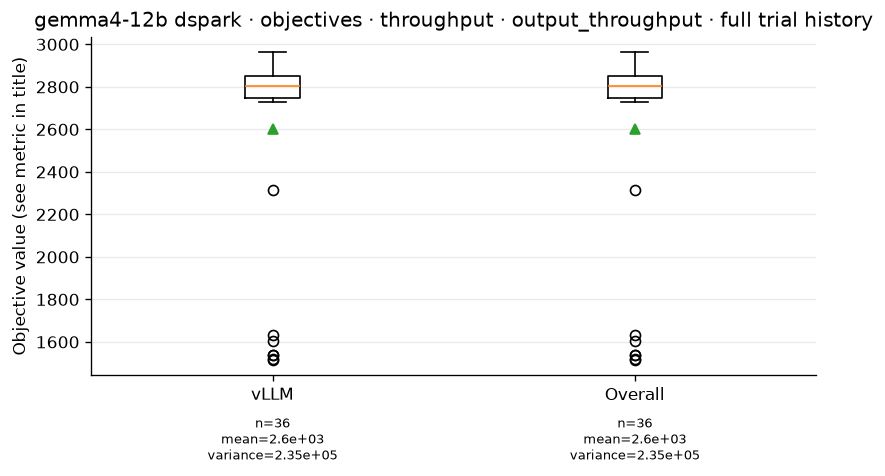

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
gemma4-12b dspark,sglang,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,18,under five minutes
gemma4-12b dspark,sglang,B-sglang-c128-e2e-tpe-s11-r2-pruner-nop,memgjzan,4,under five minutes
gemma4-12b dspark,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-nop-dsparkg4_12,yzibxy23,290,included
gemma4-12b dspark,vllm,B-vllm-c128-e2e-gp-s11-r2-pruner-median,owkvcfsh,0,under five minutes
gemma4-12b dspark,vllm,B-vllm-c128-e2e-tpe-s11-r2-pruner-median,mbtt71fi,4,under five minutes
gemma4-12b dspark,vllm,B-vllm-c128-e2e-tpe-s11-r3-pruner-median-dsparkg4_12,ov7xvv23,262,included
gemma4-12b dspark,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,8s7cgmt5,22,included
gemma4-12b dspark,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-nop-dsparkg4_12,svr3os57,211,included
gemma4-12b dspark,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-median-dsparkg4_12,a6d6o3b2,267,included
gemma4-12b dspark,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-dsparkg4_12,qip1053p,297,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope
35,gemma4-12b dspark,B,launch_to_ready,complete,vllm,104,161.868960,1111.215723,phase
36,gemma4-12b dspark,B,client_preparation,complete,vllm,104,3.690004,0.040394,phase
37,gemma4-12b dspark,B,warmup,complete,vllm,104,7.327831,1.288760,phase
38,gemma4-12b dspark,B,benchmark,complete,vllm,79,53.464850,481.067982,phase
39,gemma4-12b dspark,B,weight_loading,log observation,vllm,605,2.914591,9.107748,phase
40,gemma4-12b dspark,B,compilation,log observation,vllm,520,37.202596,1645.708188,phase
41,gemma4-12b dspark,B,graph_capture,log observation,vllm,152,6.802632,16.649529,phase
64,gemma4-12b dspark,B,launch_to_ready,complete,overall,104,161.868960,1111.215723,phase
65,gemma4-12b dspark,B,client_preparation,complete,overall,104,3.690004,0.040394,phase
66,gemma4-12b dspark,B,warmup,complete,overall,104,7.327831,1.288760,phase


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

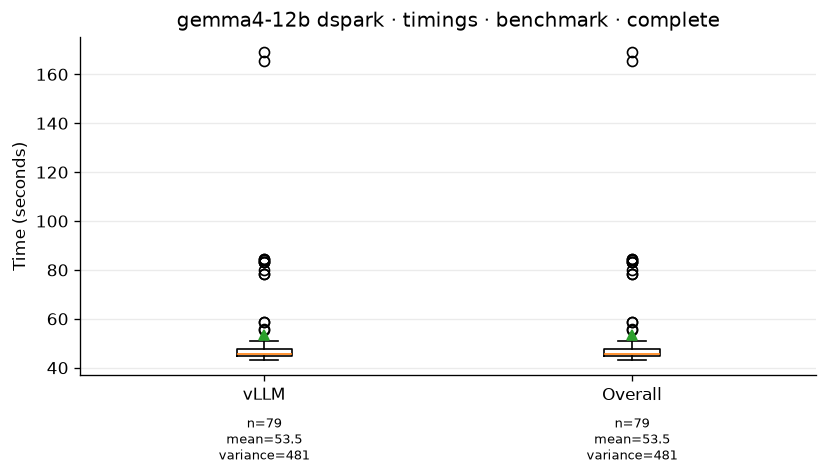

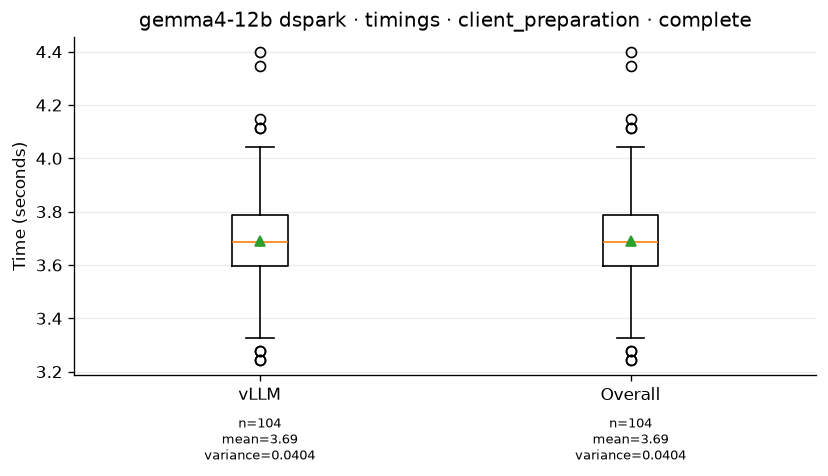

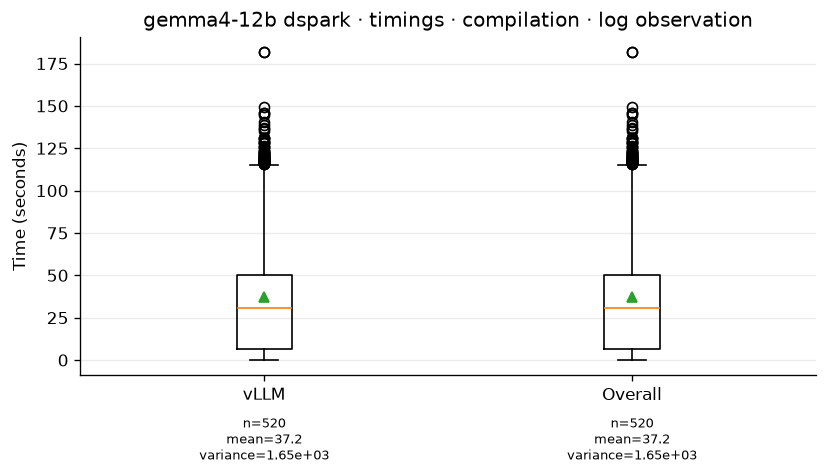

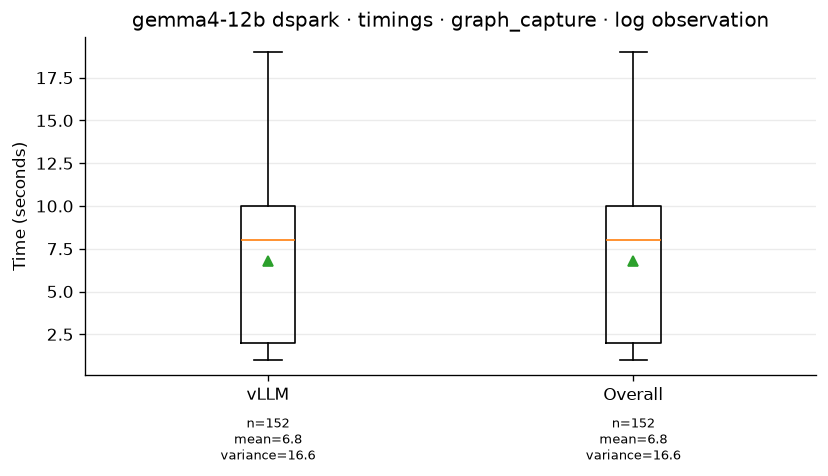

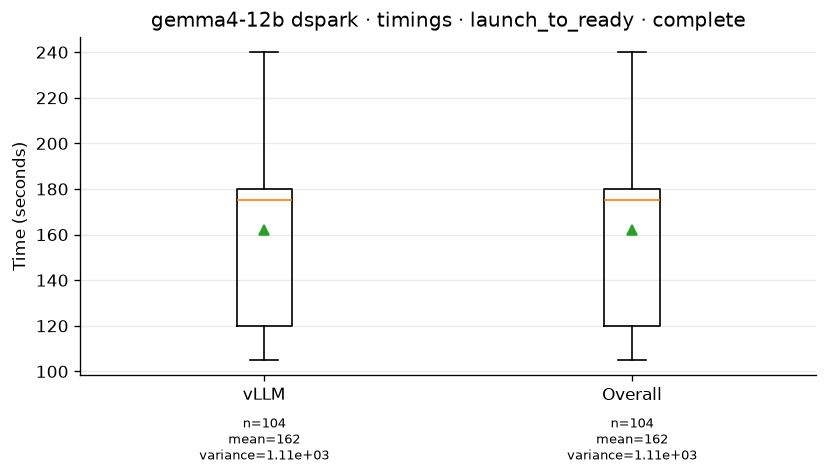

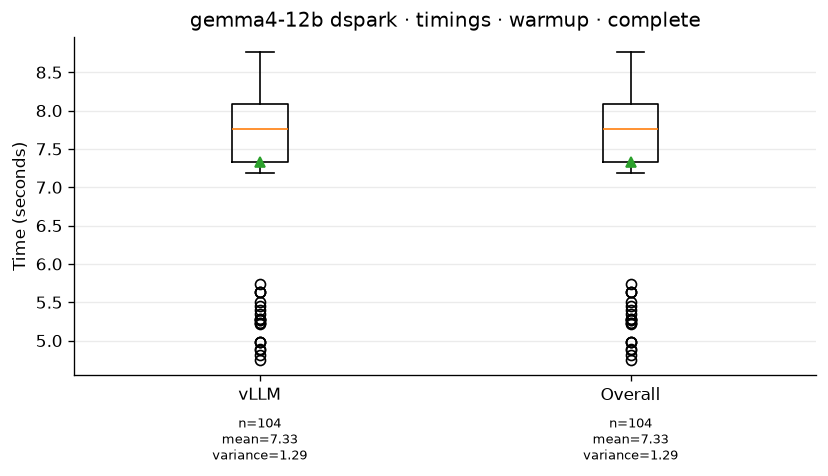

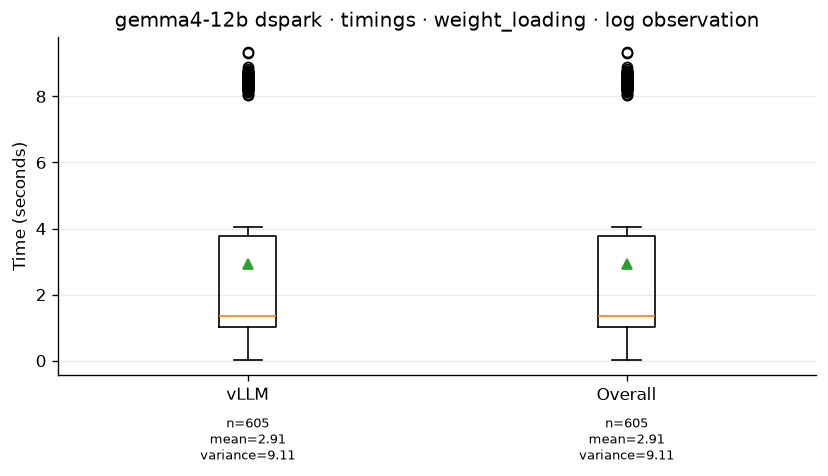

Each row is one trial; parameters wrap onto separate lines and repeated engine-log durations appear as lists. Launch-to-ready includes model loading. Log observations may overlap. Partial phases are excluded from means.

model_group,framework,phase,study_name,wandb_id,trial,params,state,source,wandb_url,launch_to_ready (s),launch_to_ready status,runner_wall (s),runner_wall status,client_preparation (s),client_preparation status,warmup (s),warmup status,benchmark (s),benchmark status,weight_loading (s),weight_loading status,compilation (s),compilation status,graph_capture (s),graph_capture status
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,0,"attention_backend: ""fa3""chunked_prefill_size: 16896cuda_graph_backend_decode: ""breakable""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 72mem_fraction_static: 0.8schedule_conservativeness: 1.25schedule_policy: ""lpm""",FAIL,local SQLite,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/ttgglwvr,15.00574869899998,partial,15.014364840000042,unknown,—,—,—,—,—,—,—,—,—,—,—,—
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,1,"attention_backend: ""fa3""chunked_prefill_size: 28416cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: falseenable_mixed_chunk: falsemax_prefill_tokens: 24576max_running_requests: 120mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: ""lpm""",FAIL,local SQLite,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/ttgglwvr,15.006440677,partial,15.01277419400003,unknown,—,—,—,—,—,—,—,—,—,—,—,—
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,2,"attention_backend: ""fa3""chunked_prefill_size: 2560cuda_graph_backend_decode: ""full""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 16384max_running_requests: 80mem_fraction_static: 0.75schedule_conservativeness: 0.5schedule_policy: ""fcfs""",FAIL,local SQLite,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/ttgglwvr,15.006958140999984,partial,15.013202153000009,unknown,—,—,—,—,—,—,—,—,—,—,—,—
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,3,"attention_backend: ""fa3""chunked_prefill_size: 11008cuda_graph_backend_decode: ""disabled""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 8192max_running_requests: 16mem_fraction_static: 0.7schedule_conservativeness: 0.5schedule_policy: ""fcfs""",FAIL,local SQLite,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/ttgglwvr,15.006238587999974,partial,15.012450934000015,unknown,—,—,—,—,—,—,—,—,—,—,—,—
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,4,"attention_backend: ""fa3""chunked_prefill_size: 10496cuda_graph_backend_decode: ""breakable""cuda_graph_backend_prefill: ""breakable""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 24576max_running_requests: 104mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.75schedule_policy: ""shortest-prefill-first""",FAIL,local SQLite,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/ttgglwvr,15.005989263000004,partial,15.013205492999987,unknown,—,—,—,—,—,—,—,—,—,—,—,—
gemma4-12b dspark,sglang,B,B-sglang-c128-e2e-tpe-s11-r1-pruner-nop,ttgglwvr,5,"attention_backend: ""fa3""chunked_prefill_size: 11520cuda_graph_backend_decode: ""breakable""cuda_graph_backend_prefill: ""disabled""disable_overlap_schedule: truedisable_radix_cache: trueenable_mixed_chunk: falsemax_prefill_tokens: 32768max_running_requests: 128mem_fraction_static: 0.7999999999999999schedule_conservativeness: 0.5schedule_policy: ""shortest-prefill-first""",FAIL,local SQLite,https://forge.c

### vLLM · gemma4-12b dspark

#### Optuna feature importance

model_group,framework,target,wandb_id,source,evaluator,run,sampler,metric,rank,parameter,importance
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,1,max_num_seqs,0.6794111162294255
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,2,max_num_batched_tokens,0.2086829233112941
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,3,gpu_memory_utilization,0.07707718204238916
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,4,performance_mode,0.019776068579365907
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,5,graph_mode,0.012285336139007232
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,6,async_scheduling,0.0027102285425671174
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,7,enable_prefix_caching,5.714515595092443e-05
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,8,kv_cache_dtype,0.0
gemma4-12b dspark,vllm,e2e,yzibxy23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-gp-s11-r1-pruner-nop,gp,p95_e2e_latency_ms,9,attention_backend,0.0
gemma4-12b dspark,vllm,e2e,ov7xvv23,local SQLite,Optuna PED-ANOVA,B-vllm-c128-e2e-tpe-s11-r3-pruner-median,tpe,p95_e2e_latency_ms,1,max_num_batched_tokens,0.7710678205651964


,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,3,0.009807,0.000126
1,e2e,p95_e2e_latency_ms,attention_backend,3,0.000000,0.000000
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,3,0.002353,0.000004
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,3,0.113674,0.018342
4,e2e,p95_e2e_latency_ms,graph_mode,3,0.020564,0.000190
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,3,0.001128,0.000004
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,3,0.373064,0.120004
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.464346,0.074831
8,e2e,p95_e2e_latency_ms,performance_mode,3,0.015065,0.000152
9,throughput,output_throughput,async_scheduling,3,0.020112,0.000056


model_group,framework,run,wandb_id,status
gemma4-12b dspark,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,8s7cgmt5,p95_e2e_latency_ms: insufficient variation


Phase B / vLLM: 7 included runs; cutoff 5 minutes


**Runs included: 7.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r1-pruner-nop`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`
- `gemma4-vllm-tpe-auto-kv-seeded-v3`

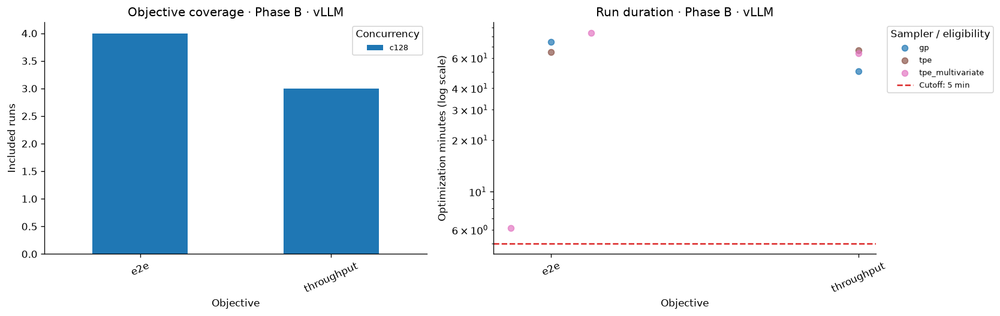

,state,trials
0,COMPLETE,79
1,FAIL,37
2,PRUNED,25


Runs without recorded outcome counts: 0


#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 4.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-nop`
- `B-vllm-c128-e2e-tpe-s11-r3-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median`
- `gemma4-vllm-tpe-auto-kv-seeded-v3`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r1-pruner-nop,vllm-phase-b-pruning-gemma4-12b-dspark,yzibxy23,e2e,C22,gp,74.59,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 23040max_num_seqs: 40performance_mode: balanced,19,8612.216558,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r3-pruner-median,vllm-phase-b-pruning-gemma4-12b-dspark,ov7xvv23,e2e,C22,tpe,65.18,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 8704max_num_seqs: 48performance_mode: balanced,11,9226.912174,False,all local COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r3-pruner-median,vllm-phase-b-pruning-gemma4-12b-dspark,8s7cgmt5,e2e,C22,tpe_multivariate,6.14,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.85graph_mode: NONEkv_cache_dtype: automax_num_batched_tokens: 16896max_num_seqs: 72performance_mode: interactivity,0,10567.831601,False,all local COMPLETE trials
gemma4-vllm-tpe-auto-kv-seeded-v3,vllm-phase-b-pruning-gemma4-12b-dspark,blbmq1q8,e2e,C22,tpe_multivariate,84.06,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: densegraph_mode: PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 24576max_num_seqs: 32performance_mode: balanced,13,8795.812830,False,all local COMPLETE trials


##### Matching context C22

**Matched workload and environment**

**model:** `"gemma4-12b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

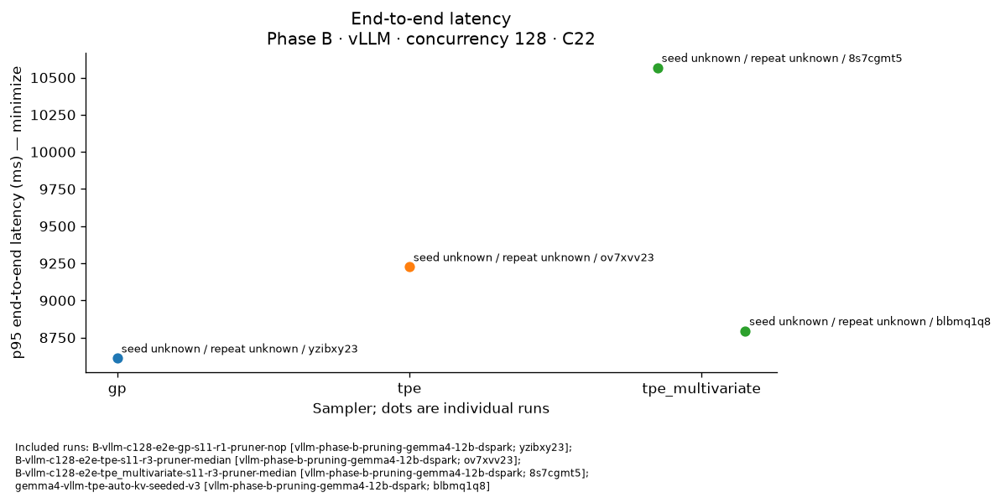

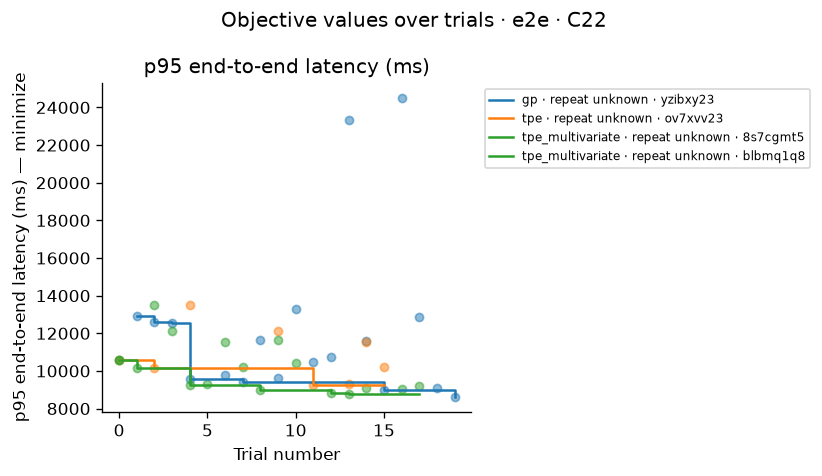

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r1-pruner-nop`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r1-pruner-nop,vllm-phase-b-pruning-gemma4-12b-dspark,svr3os57,throughput,C09,gp,50.06,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19968max_num_seqs: 128performance_mode: balanced,10,2907.478411,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r1-pruner-median,vllm-phase-b-pruning-gemma4-12b-dspark,a6d6o3b2,throughput,C09,tpe,66.67,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19968max_num_seqs: 128performance_mode: balanced,10,2942.468158,False,all local COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,vllm-phase-b-pruning-gemma4-12b-dspark,qip1053p,throughput,C09,tpe_multivariate,63.86,async_scheduling: Falseattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19968max_num_seqs: 128performance_mode: balanced,10,2963.834817,False,all local COMPLETE trials


##### Matching context C09

**Matched workload and environment**

**model:** `"gemma4-12b dspark"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1.0, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"707f0a3b8a3c7ad586ed01e27eafbad8a27dd0f7"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

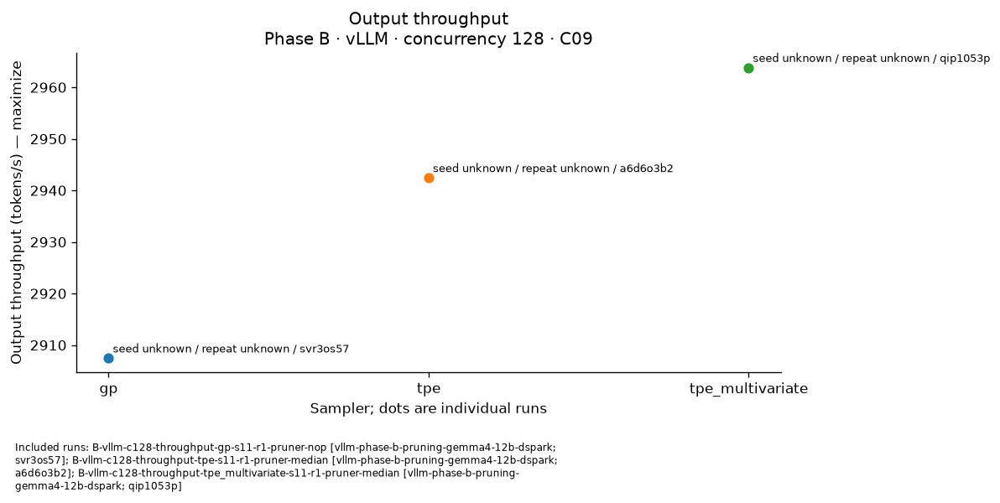

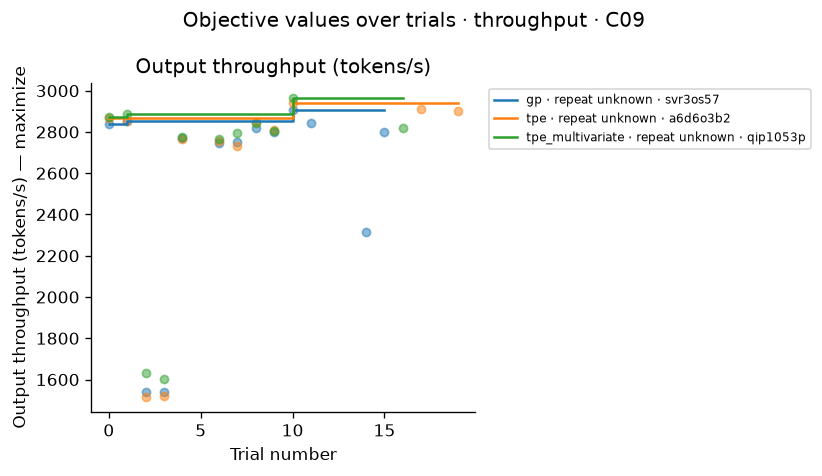

### TRT-LLM · gemma4-12b dspark

No eligible runs available.


### SGLang · gemma4-12b dspark

No eligible runs available.


In [64]:
show_model("gemma4-12b dspark")


## Additional variants


## qwen3.5-4b dflash

### Framework summaries · qwen3.5-4b dflash

Means and sample variances pool eligible observations across phases and concurrencies. Objective targets and coverage remain separate; Pareto studies show both metrics. Benchmark time is measured per trial; launch-to-ready includes server startup and model loading. Timing evidence also includes shorter measured runs.

#### For vLLM

**Best recorded results and trial numbers** — ranked within each matching context. Pareto rows are nondominated throughput–latency trade-offs; ties are retained. Candidate-summary-only runs contain only recorded best/Pareto trials.

target,context,phase,concurrency,run,wandb_id,wandb_url,trial,output_throughput,p95_e2e_latency_ms,parameters,coverage
e2e,C01,B,1,B-vllm-c1-e2e-tpe-s11-r2,2c05lr25,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/2c05lr25,16,—,914.0100627000265,"async_scheduling: falseattention_backend: ""FLASHINFER""enable_prefix_caching: falsegpu_memory_utilization: 0.8graph_capture_profile: ""powers""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""fp8""max_num_batched_tokens: 2048performance_mode: ""balanced""",all W&B COMPLETE trials
throughput,C15,B,128,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,cvzosd1r,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/cvzosd1r,18,5710.269629905756,—,"async_scheduling: trueattention_backend: ""FLASH_ATTN""enable_prefix_caching: falsegpu_memory_utilization: 0.9graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 19200max_num_seqs: 96performance_mode: ""interactivity""",all W&B COMPLETE trials
e2e,C28,B,128,B-vllm-c128-e2e-tpe-s11-r1-pruner-median,g84ks3ri,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/g84ks3ri,16,—,4052.710867000405,"async_scheduling: trueattention_backend: ""FLASH_ATTN""enable_prefix_caching: falsegpu_memory_utilization: 0.75graph_capture_profile: ""dense""graph_mode: ""FULL_AND_PIECEWISE""kv_cache_dtype: ""auto""max_num_batched_tokens: 5888max_num_seqs: 72performance_mode: ""balanced""",all W&B COMPLETE trials


... (10 outputs left out)

model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files
qwen3.5-4b dflash,B-vllm-c1-e2e-tpe-s11-r2-dflashq3.5_4-q3.5_4,B,vllm,B-vllm-c1-e2e-tpe-s11-r2,38.09220586116667,W&B terminal _runtime,wandb snapshot,—,2c05lr25,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/2c05lr25,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-e2e-gp-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,B,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-median,38.57853780121666,W&B terminal _runtime,wandb snapshot,—,8gp1fym7,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/8gp1fym7,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-e2e-tpe-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,B,vllm,B-vllm-c128-e2e-tpe-s11-r1-pruner-median,56.02317987626667,W&B terminal _runtime,wandb snapshot,—,g84ks3ri,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/g84ks3ri,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,B,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,40.72730844503334,W&B terminal _runtime,wandb snapshot,—,s0k095o0,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/s0k095o0,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,B,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-median,40.77602275391666,W&B terminal _runtime,wandb snapshot,—,zbyjlkdk,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/zbyjlkdk,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-throughput-tpe-s11-r1-pruner-medianB-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,B,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-median,41.92163708755,W&B terminal _runtime,wandb snapshot,—,qyu0g3ke,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/qyu0g3ke,finished,sglang-phase-b-pruning-min400-v1,[]
qwen3.5-4b dflash,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-medianB-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,B,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,40.479400861516666,W&B terminal _runtime,wandb snapshot,—,cvzosd1r,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/cvzosd1r,finished,sglang-phase-b-pruning-min400-v1,[]


### Objective means and sample variances

,model_group,phase,target,concurrency,coverage,metric,framework,n,runs,mean,variance,scope
51,qwen3.5-4b dflash,B,e2e,1,full trial history,p95_e2e_latency_ms,vllm,20,1,998.223477,4.556798e+03,phase/concurrency
52,qwen3.5-4b dflash,B,e2e,128,full trial history,p95_e2e_latency_ms,vllm,48,3,4676.157068,6.845612e+05,phase/concurrency
53,qwen3.5-4b dflash,B,throughput,128,full trial history,output_throughput,vllm,49,3,5062.331718,6.769978e+05,phase/concurrency
78,qwen3.5-4b dflash,B,e2e,1,full trial history,p95_e2e_latency_ms,overall,20,1,998.223477,4.556798e+03,phase/concurrency
79,qwen3.5-4b dflash,B,e2e,128,full trial history,p95_e2e_latency_ms,overall,48,3,4676.157068,6.845612e+05,phase/concurrency
80,qwen3.5-4b dflash,B,throughput,128,full trial history,output_throughput,overall,49,3,5062.331718,6.769978e+05,phase/concurrency
121,qwen3.5-4b dflash,all,e2e,all,full trial history,p95_e2e_latency_ms,vllm,68,4,3594.411894,3.331838e+06,model
122,qwen3.5-4b dflash,all,throughput,all,full trial history,output_throughput,vllm,49,3,5062.331718,6.769978e+05,model
141,qwen3.5-4b dflash,all,e2e,all,full trial history,p95_e2e_latency_ms,overall,68,4,3594.411894,3.331838e+06,model
142,qwen3.5-4b dflash,all,throughput,all,full trial history,output_throughput,overall,49,3,5062.331718,6.769978e+05,model


Box plots pool phases and concurrencies, matching the model-scope statistics. Each observation is an eligible trial; summary-only candidates remain separate. Boxes show quartiles and median, triangles show means, and labels show sample variance (ddof=1).

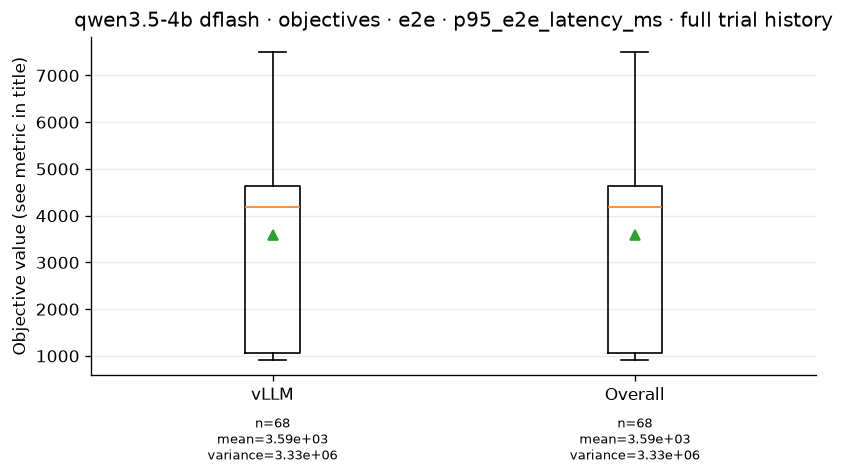

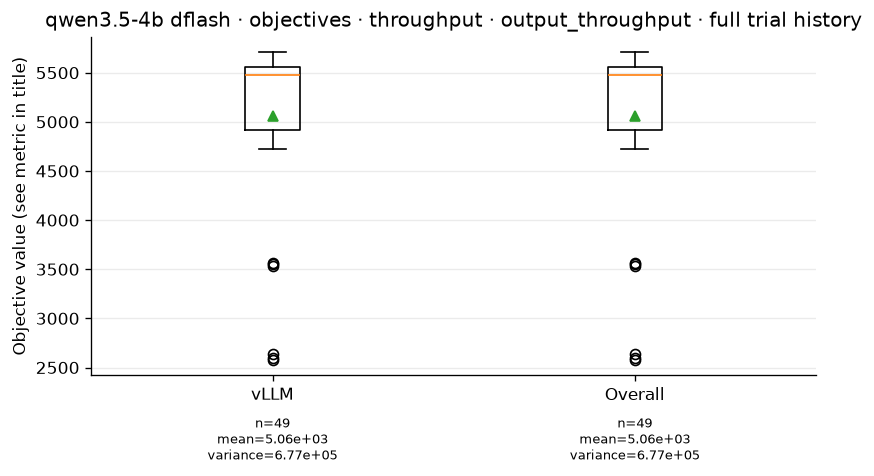

### Server initiation and model loading

model_group,framework,run,wandb_id,timing_observations,objective_inclusion
qwen3.5-4b dflash,vllm,B-vllm-c1-e2e-tpe-s11-r2-dflashq3.5_4-q3.5_4,2c05lr25,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-e2e-gp-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,8gp1fym7,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-e2e-tpe-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,g84ks3ri,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median-dflashq3.5_4-q3.5_4,s0k095o0,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,zbyjlkdk,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-throughput-tpe-s11-r1-pruner-medianB-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,qyu0g3ke,0,included
qwen3.5-4b dflash,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-medianB-vllm-c128-throughput-gp-s11-r1-pruner-median-dflashq3.5_4,cvzosd1r,0,included


,model_group,phase,timing,phase_status,framework,n,mean_seconds,variance_seconds2,scope


Timing boxes pool phases and show complete wall-clock phases or explicit engine-log observations separately; repeated log observations may overlap.

No recorded startup telemetry available for this model.


### vLLM · qwen3.5-4b dflash

... (2 outputs left out)

,target,metric,parameter,runs,mean_importance,variance
0,e2e,p95_e2e_latency_ms,async_scheduling,4,0.064504,0.003793
1,e2e,p95_e2e_latency_ms,attention_backend,4,0.043683,0.000785
2,e2e,p95_e2e_latency_ms,enable_prefix_caching,4,0.056447,0.004271
3,e2e,p95_e2e_latency_ms,gpu_memory_utilization,4,0.185148,0.021669
4,e2e,p95_e2e_latency_ms,graph_mode,4,0.114096,0.010897
5,e2e,p95_e2e_latency_ms,kv_cache_dtype,4,0.044996,0.004955
6,e2e,p95_e2e_latency_ms,max_num_batched_tokens,4,0.277344,0.092468
7,e2e,p95_e2e_latency_ms,max_num_seqs,3,0.191626,0.000217
8,e2e,p95_e2e_latency_ms,performance_mode,4,0.070063,0.002562
9,throughput,output_throughput,async_scheduling,3,0.040080,0.002476


model_group,framework,run,wandb_id,status


Phase B / vLLM: 7 included runs; cutoff 5 minutes


**Runs included: 7.** Optimizer seeds: s11, seed unknown. Repeats: r2, repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c1-e2e-tpe-s11-r2`
- `B-vllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`
- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

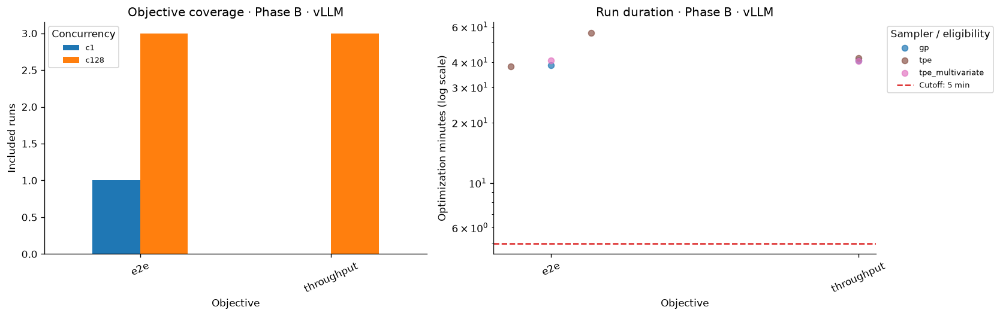

,state,trials
0,COMPLETE,117
1,PRUNED,23


Runs without recorded outcome counts: 0


#### Concurrency 1 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 1.** Optimizer seeds: s11. Repeats: r2.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c1-e2e-tpe-s11-r2`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c1-e2e-tpe-s11-r2,sglang-phase-b-pruning-min400-v1,2c05lr25,e2e,C01,tpe,38.09,async_scheduling: Falseattention_backend: FLASHINFERenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 2048performance_mode: balanced,16,914.010063,True,all W&B COMPLETE trials


##### Matching context C01

**Matched workload and environment**

**model:** `"qwen3.5-4b dflash"` · **concurrency:** `1` · **workload:** `{"dataset_name": "random", "max_concurrency": 1, "num_prompts": 32, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

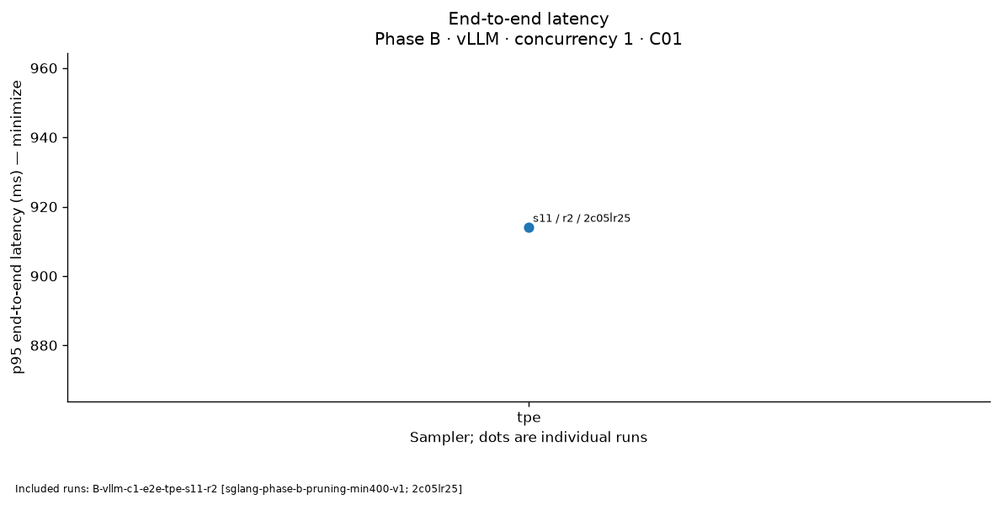

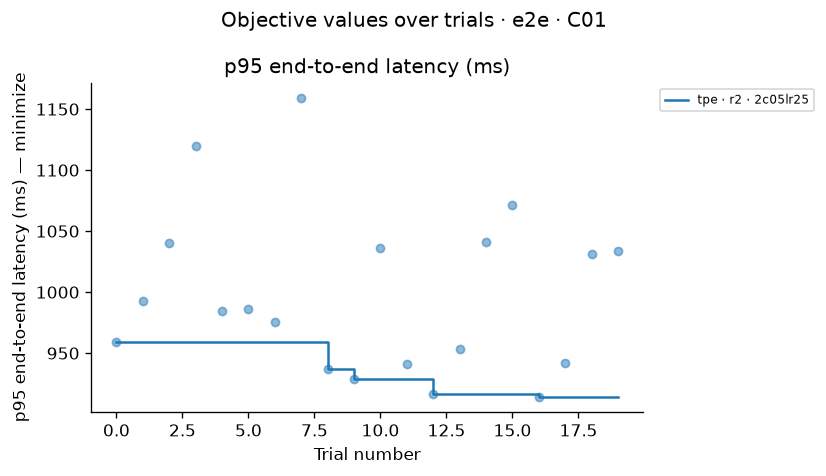

#### Concurrency 128 · Phase B · vLLM

##### End-to-end latency (`e2e`)

Minimize p95 end-to-end latency (ms)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-e2e-gp-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe-s11-r1-pruner-median`
- `B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,p95_e2e_latency_ms,SLO feasible,result source
B-vllm-c128-e2e-gp-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,8gp1fym7,e2e,C28,gp,38.58,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.8graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 26880max_num_seqs: 88performance_mode: throughput,11,4124.128797,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,g84ks3ri,e2e,C28,tpe,56.02,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 5888max_num_seqs: 72performance_mode: balanced,16,4052.710867,False,all W&B COMPLETE trials
B-vllm-c128-e2e-tpe_multivariate-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,s0k095o0,e2e,C28,tpe_multivariate,40.73,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.75graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19456max_num_seqs: 96performance_mode: balanced,11,4091.350406,False,all W&B COMPLETE trials


##### Matching context C28

**Matched workload and environment**

**model:** `"qwen3.5-4b dflash"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

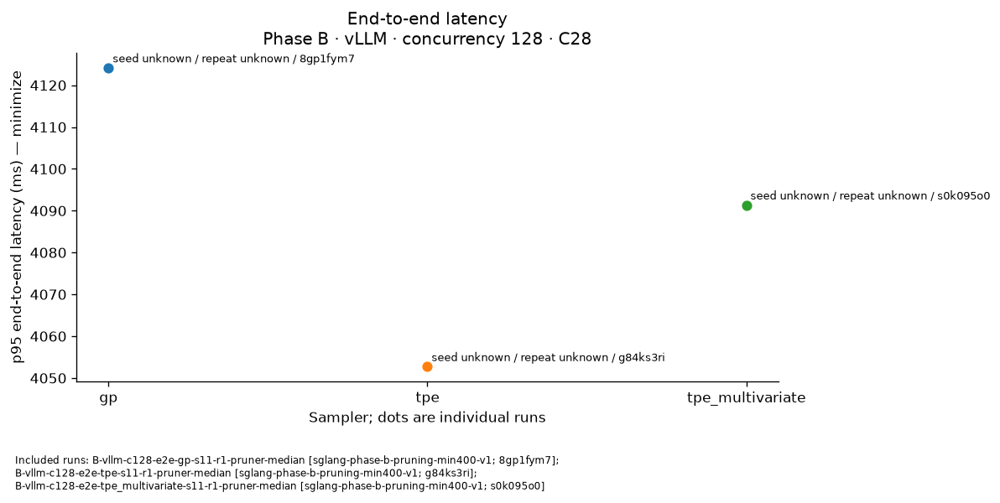

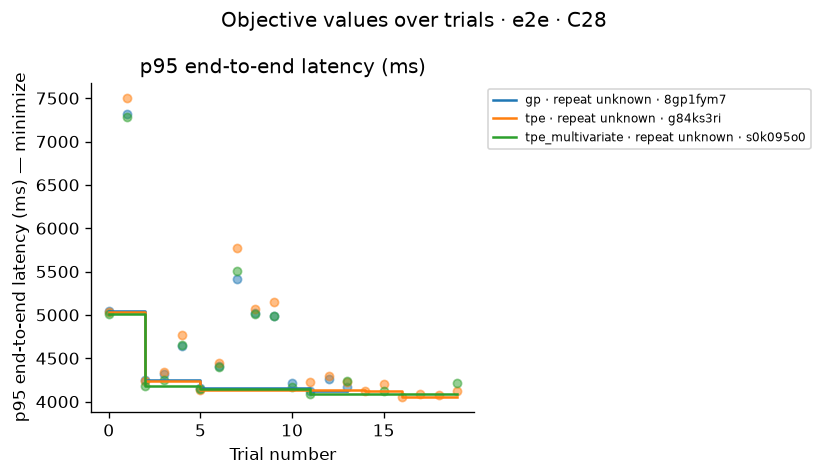

##### Output throughput (`throughput`)

Maximize output throughput (tokens/s)

**Runs included: 3.** Optimizer seeds: seed unknown. Repeats: repeat unknown.

`s` is the optimizer seed; `r` is the repeat number. Only the runs named below contribute.

- `B-vllm-c128-throughput-gp-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe-s11-r1-pruner-median`
- `B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median`

run,run_group,wandb_id,objective,context,sampler,runtime_minutes,parameters,trial,output_throughput,SLO feasible,result source
B-vllm-c128-throughput-gp-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,zbyjlkdk,throughput,C15,gp,40.78,async_scheduling: Trueattention_backend: autoenable_prefix_caching: Truegpu_memory_utilization: 0.9graph_mode: NONEkv_cache_dtype: fp8max_num_batched_tokens: 20992max_num_seqs: 88performance_mode: throughput,6,5613.565190,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,qyu0g3ke,throughput,C15,tpe,41.92,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.85graph_capture_profile: powersgraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: fp8max_num_batched_tokens: 13312max_num_seqs: 104performance_mode: balanced,15,5571.983032,False,all W&B COMPLETE trials
B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,sglang-phase-b-pruning-min400-v1,cvzosd1r,throughput,C15,tpe_multivariate,40.48,async_scheduling: Trueattention_backend: FLASH_ATTNenable_prefix_caching: Falsegpu_memory_utilization: 0.9graph_capture_profile: densegraph_mode: FULL_AND_PIECEWISEkv_cache_dtype: automax_num_batched_tokens: 19200max_num_seqs: 96performance_mode: interactivity,18,5710.269630,False,all W&B COMPLETE trials


##### Matching context C15

**Matched workload and environment**

**model:** `"qwen3.5-4b dflash"` · **concurrency:** `128` · **workload:** `{"dataset_name": "random", "max_concurrency": 128, "num_prompts": 1000, "random_input_len": 512, "random_output_len": 128, "random_range_ratio": 1, "request_rate": "inf", "seed": 2026}` · **gpu type:** `"NVIDIA H100 80GB HBM3"` · **gpu count:** `1` · **model revision:** `"851bf6e806efd8d0a36b00ddf55e13ccb7b8cd0a"` · **cuda version:** `"13.0"` · **driver version:** `"580.173.02"`

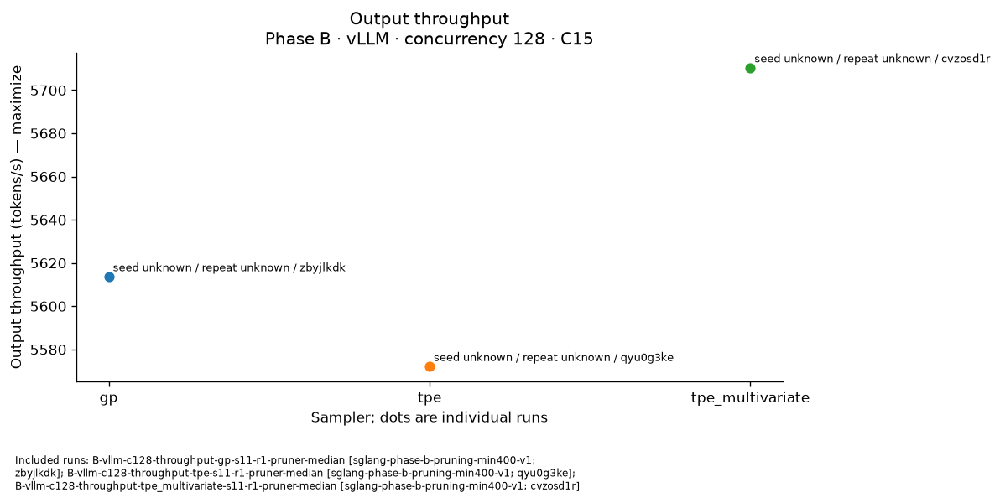

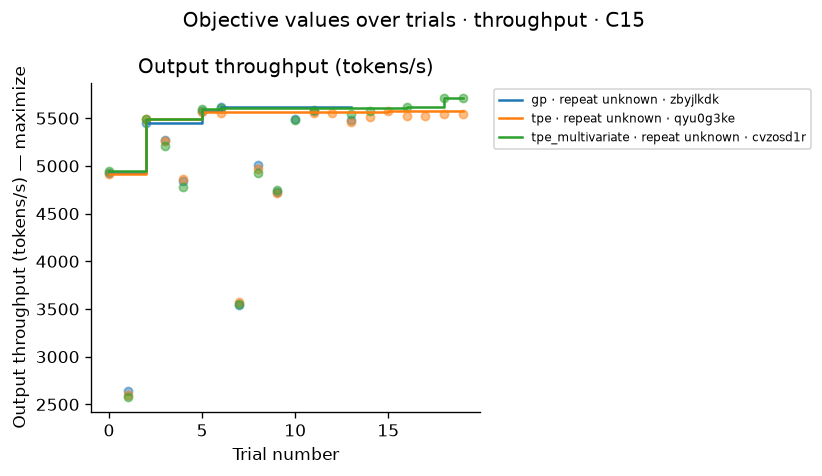

### TRT-LLM · qwen3.5-4b dflash

No eligible runs available.


### SGLang · qwen3.5-4b dflash

No eligible runs available.


In [65]:
for model in sorted({r["model_group"] for r in records} - set(MODEL_ORDER)):
    display(Markdown(f"## {model}"))
    show_framework_summary(model)
    show_model(model)


## Audit: exclusions and source coverage

These tables explain runs that did not contribute. No excluded run is used by the framework plots. W&B-only candidate summaries cannot establish full search histories.

### Excluded runs and source issues


In [66]:
print(f"Excluded runs: {len(excluded)}")
excluded_runs = manifest(excluded)
excluded_runs["exclusion_reason"] = [exclusion(r) for r in excluded]
collapsible_table("Show excluded runs", excluded_runs)
source_issues = pd.DataFrame(issues, columns=["source", "issue"])
collapsible_table("Show source issues", source_issues)

collapsible_table("Show result issues", pd.DataFrame(result_issues, columns=["study_name", "issue"]))

Excluded runs: 128


model_group,display_name,phase,framework,study_name,duration_minutes,duration_source,sources,database,wandb_id,wandb_url,remote_state,run_group,measured_files,exclusion_reason
cpm5_2,—,B,trtllm,B-trtllm-c128-e2e-tpe-s11-r1-pruner-median,2.1592023,local terminal trial span,local,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,czymko6z,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/czymko6z,—,MiniCPM5-2B,[],under five minutes
cpm5_2,B-trtllm-c128-e2e-tpe-s11-r3-pruner-median-cpm_2,B,trtllm,B-trtllm-c128-e2e-tpe-s11-r3-pruner-median,0.0005021333333333334,local terminal trial span,local + wandb snapshot,experiment_results/trtllm-phase-b-pruning-openbmb/MiniCPM5-2B/studies.sqlite3,7hksyocg,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7hksyocg,finished,MiniCPM5-2B,[],under five minutes
cpm5_2,—,B,vllm,B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median,—,unknown,local,experiment_results/vllm-phaseB-minicmp5-2b/studies.sqlite3,endy6ito,https://forge.coreweave.com/wandb/maorblumberg-tel-aviv-university/inference-optimization/runs/endy6ito,—,vllm-phaseB-minicmp5-2b,['experiment_results/vllm-phaseB-minicmp5-2b/B-vllm-c128-throughput-tpe_multivariate-s11-r1-pruner-median-B-vllm-c128-measured.jsonl'],unknown duration
cpm5_2,suggested-vllm-openbmb--MiniCPM5-2B-7831e9ae-c128,B,vllm,suggested-vllm-openbmb--MiniCPM5-2B-7831e9ae-c128,1.45,W&B terminal _runtime,wandb snapshot,—,6q8zo485,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/6q8zo485,finished,vllm-baseline_runs,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r2-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r2,0.031121432683327534,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,7gwvubpf,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/7gwvubpf,finished,optuna-phase-b-v1,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r21-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r21,0.08493265,local terminal trial span,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,2qsnkj42,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/2qsnkj42,finished,optuna-phase-b-v1,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r3-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r3,0.02977463559999857,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,szsjx7ht,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/szsjx7ht,crashed,optuna-phase-b-v1,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r4-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r4,0.027810013299995263,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,5w5betog,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/5w5betog,finished,optuna-phase-b-v1,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r5-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r5,0.026836470033329837,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,tdqamjke,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/tdqamjke,finished,optuna-phase-b-v1,[],under five minutes
qwen3.5-4b,B-sglang-c128-e2e-tpe-s11-r6-q3.5_4,B,sglang,B-sglang-c128-e2e-tpe-s11-r6,0.02774373238333586,local optimization_wall_seconds,local + wandb snapshot,experiment_results/optuna-phase-b-v1/studies.sqlite3,d538uvbw,https://wandb.ai/maorblumberg-tel-aviv-university/inference-optimization/runs/d538uvbw,crashed,optuna-phase-b-v1,[],under five minutes


source,issue
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/sglang-phase-b-pruning-gemma4-12b/studies.sqlite3,No Phase A/B contract: B-sglang-c128-throughput-tpe-s11-r1-pruner-median-mv-warmstart-20261022T190856799241
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,No Phase A/B contract: gemma4-vllm-tpe-auto-kv-seeded-v1
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/experiment_results/vllm-phase-b-pruning-gemma4-12b-dspark/studies.sqlite3,No Phase A/B contract: gemma4-vllm-tpe-auto-kv-seeded-v2
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/sglang/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-sglang-native
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/trtllm/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-trtllm-native
/mnt/c/Users/maorb/work/bento_extend/llm-optimizer/results/notebook_h100/h100_smoke_v1/native/vllm/optuna/results.optuna.db,No Phase A/B contract: h100_smoke_v1-vllm-native


study_name,issue
B-trtllm-c128-e2e-tpe-s11-r2-pruner-median,No eligible completed objective results
A-trtllm-c128-e2e-tpe-s11-r3,No eligible completed objective results
B-trtllm-c128-e2e-tpe-s11-r4-pruner-median,No eligible completed objective results


## Save a readable HTML report
This standalone report contains the model summaries, importance tables and per-trial initiation parameters. It can be opened directly in a browser.


In [67]:
HTML_REPORT = ROOT / "docs" / "optuna_run_metadata_v2.html"
write_report_html(
    HTML_REPORT,
    MODEL_ORDER + sorted({r["model_group"] for r in records} - set(MODEL_ORDER)),
    runs_used, all_objective_statistics, all_startup_statistics, startup_details,
    pd.DataFrame(startup_coverage), all_importance, pd.DataFrame(importance_coverage),
    excluded_runs, source_issues, exported_at=exported_at if WANDB_SNAPSHOT.exists() else None,
)
print(f"Saved {HTML_REPORT.relative_to(ROOT)}")


Saved docs/optuna_run_metadata_v2.html
